# U.S. E-Commerce Performance Analytics
## Late Delivery Prediction: Data Validation and Exploratory Analysis

This notebook examines order-level data to understand late delivery patterns
and prepare for predictive modeling using information available at checkout.

The modeling dataset contains delivered orders and uses chronological splits:
2019–2023 for training, 2024 for validation, and January–November 2025 for testing.

Exploratory analysis is conducted on the training data. Validation data will
support model selection, while test data is reserved for final evaluation.

## 1. Setup & Imports

Import the library used to load, inspect, and summarize the modeling dataset.

In [1]:
import pandas as pd


## 2. Load Dataset

Load the late-delivery modeling dataset exported from PostgreSQL.
Each row represents one delivered order included in the modeling scope.

In [2]:
# Load CSV from the processed data folder
df = pd.read_csv(
    r"S:\us-ecommerce-performance-analytics\data\processed\late_delivery_modeling.csv"
)

# Preview the first 5 rows
df.head()

,order_id,data_split,purchase_year,purchase_month,purchase_day_of_week,purchase_hour,is_weekend_purchase,customer_gender,customer_age,customer_state,...,used_apple_pay,used_bank_transfer,used_voucher,used_boleto,shipment_route_count,item_weighted_distance_miles,distance_band,is_distance_missing,target_late_delivery,order_purchase_timestamp
0,90a1a1ce-c905-4adc-a287-898e260cee94,train,2019,1,2,1,False,f,36,IL,...,False,False,False,False,3,1474.864421,"1,000+ miles",False,0,2019-01-01 01:21:03
1,7f6546f8-f920-478c-893e-c8777fd609f9,train,2019,1,2,1,False,f,45,TX,...,False,False,False,False,1,2.345999,Under 100 miles,False,0,2019-01-01 01:38:50
2,4cf5f4ec-0ace-41ea-889a-1a289d7f618f,train,2019,1,2,1,False,f,33,FL,...,False,False,False,False,2,1029.363929,"1,000+ miles",False,0,2019-01-01 01:47:13
3,ba6b724e-d709-46d2-9424-08e8c321196f,train,2019,1,2,1,False,f,22,TX,...,False,False,False,False,1,1886.997251,"1,000+ miles",False,0,2019-01-01 01:53:54
4,e6a1b714-0dfd-4e86-a82d-7fddcb46d542,train,2019,1,2,2,False,f,38,FL,...,False,True,False,False,2,2336.737362,"1,000+ miles",False,0,2019-01-01 02:54:37


## 3. Prepare Purchase Timestamp

Convert the purchase timestamp to datetime for chronological split checks
and time-based analysis. The original timestamp is retained for auditing
and is not used directly as a model predictor.

In [3]:
df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"],
    errors="raise"
)

print(df["order_purchase_timestamp"].dtype)
df["order_purchase_timestamp"].head()

datetime64[ns]


0   2019-01-01 01:21:03
1   2019-01-01 01:38:50
2   2019-01-01 01:47:13
3   2019-01-01 01:53:54
4   2019-01-01 02:54:37
Name: order_purchase_timestamp, dtype: datetime64[ns]

## 4. Check Dataset Size & Split Counts

Check the dataset dimensions and compare split counts with the expected
SQL export totals. This verifies export completeness before further analysis.

In [4]:
print("Dataset shape:", df.shape)

split_counts = (
    df["data_split"]
    .value_counts(dropna=False)
    .rename_axis("data_split")
    .reset_index(name="order_count")
)

split_counts

Dataset shape: (904366, 49)


,data_split,order_count
0,train,461744
1,test,228257
2,validation,214365


### Findings

The exported dataset contains 904,366 rows and 49 columns.
Split counts match the expected SQL totals: 461,744 training rows,
214,365 validation rows, and 228,257 test rows.
No missing split labels were observed.

These checks confirm the expected export size. Order uniqueness
and chronological split boundaries require separate validation.

## 5. Select Training Data

Create a separate training DataFrame for exploratory analysis.
Preserve the chronological split labels defined in SQL.
Validation and test data remain reserved for later modeling stages.

In [5]:
# Select training rows without changing the original dataset
train_df = df.loc[df["data_split"] == "train"].copy()

print("Training dataset shape:", train_df.shape)

# List columns for the next validation and EDA steps
column_summary = pd.DataFrame({
    "column_name": train_df.columns,
    "data_type": train_df.dtypes.astype(str).values
})

column_summary

Training dataset shape: (461744, 49)


,column_name,data_type
0,order_id,object
1,data_split,object
2,purchase_year,int64
3,purchase_month,int64
4,purchase_day_of_week,int64
5,purchase_hour,int64
6,is_weekend_purchase,bool
7,customer_gender,object
8,customer_age,int64
9,customer_state,object


## 6. Validate Training Data

Check missing values, order uniqueness, target validity, and purchase dates.
The training data should contain one row per order, a binary late-delivery
target, and purchase timestamps within 2019–2023.

In [6]:
# Define the expected training date range
train_start = pd.Timestamp("2019-01-01")
train_end = pd.Timestamp("2024-01-01")

purchase_dates = train_df["order_purchase_timestamp"]
target = train_df["target_late_delivery"]

# Summarize training data checks
training_checks = pd.DataFrame({
    "check": [
        "Training rows",
        "Missing order IDs",
        "Duplicate order IDs",
        "Missing target values",
        "Invalid non-missing target values",
        "Missing purchase timestamps",
        "Purchase dates outside training period"
    ],
    "actual": [
        len(train_df),
        train_df["order_id"].isna().sum(),
        train_df["order_id"].duplicated().sum(),
        target.isna().sum(),
        (target.notna() & ~target.isin([0, 1])).sum(),
        purchase_dates.isna().sum(),
        (
            purchase_dates.notna()
            & (
                (purchase_dates < train_start)
                | (purchase_dates >= train_end)
            )
        ).sum()
    ],
    "expected": [
        461744, 0, 0, 0, 0, 0, 0
    ]
})

training_checks["status"] = training_checks["actual"].eq(
    training_checks["expected"]
).map({True: "PASS", False: "FAIL"})

training_checks

,check,actual,expected,status
0,Training rows,461744,461744,PASS
1,Missing order IDs,0,0,PASS
2,Duplicate order IDs,0,0,PASS
3,Missing target values,0,0,PASS
4,Invalid non-missing target values,0,0,PASS
5,Missing purchase timestamps,0,0,PASS
6,Purchase dates outside training period,0,0,PASS


In [7]:
missing_summary = (
    train_df.isna()
    .sum()
    .rename_axis("column_name")
    .reset_index(name="missing_count")
)

missing_summary["missing_pct"] = (
    100 * missing_summary["missing_count"] / len(train_df)
)

missing_summary = missing_summary.sort_values(
    "missing_count",
    ascending=False
)

print(
    "Columns with missing values:",
    (missing_summary["missing_count"] > 0).sum()
)

missing_summary.loc[missing_summary["missing_count"] > 0]

Columns with missing values: 0


,column_name,missing_count,missing_pct


### Findings

The training dataset contains 461,744 orders with no missing or duplicate
order IDs. All late-delivery targets are valid binary values, and all
purchase timestamps fall within the defined 2019–2023 training period.

No missing values were detected across the 49 columns.
These checks support proceeding with exploratory analysis.
Feature availability at checkout still requires source-level verification.

## 7. Training Target Distribution

Examine the number and percentage of on-time and late deliveries
in the training dataset to assess class imbalance.

The target is defined as:
- 0: On-time delivery
- 1: Late delivery

In [8]:
# Count orders in each target class
target_summary = (
    train_df["target_late_delivery"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("target_late_delivery")
    .reset_index(name="order_count")
)

# Add readable labels and class percentages
target_summary["delivery_status"] = (
    target_summary["target_late_delivery"]
    .map({0: "On-time delivery", 1: "Late delivery"})
)

target_summary["share_pct"] = (
    100 * target_summary["order_count"] / len(train_df)
)

target_summary = target_summary[
    [
        "target_late_delivery",
        "delivery_status",
        "order_count",
        "share_pct"
    ]
]

target_summary.round({"share_pct": 2})

,target_late_delivery,delivery_status,order_count,share_pct
0,0,On-time delivery,415600,90.01
1,1,Late delivery,46144,9.99


### Findings

Late deliveries account for 46,144 training orders (9.99%), while
415,600 orders (90.01%) were delivered on time.

The target is imbalanced. Predicting every order as on time would achieve
90.01% accuracy but identify none of the late deliveries. Model evaluation
will therefore include precision, recall, and precision-recall performance
rather than relying on accuracy alone.

## 8. Monthly Order Volume & Late Delivery Rate

Examine monthly order volume and late-delivery rates across the training
period. Reviewing both measures helps distinguish changes in order volume
from changes in the proportion of late deliveries.

In [9]:
# Create a year-month column for training EDA
train_df["purchase_year_month"] = (
    train_df["order_purchase_timestamp"].dt.to_period("M")
)

# Summarize monthly orders and late deliveries
monthly_summary = (
    train_df
    .groupby("purchase_year_month")
    .agg(
        order_count=("order_id", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reset_index()
    .sort_values("purchase_year_month")
)

monthly_summary["late_delivery_rate_pct"] = (
    100 * monthly_summary["late_delivery_rate"]
)

monthly_summary[
    [
        "purchase_year_month",
        "order_count",
        "late_order_count",
        "late_delivery_rate_pct"
    ]
].round({"late_delivery_rate_pct": 2})

,purchase_year_month,order_count,late_order_count,late_delivery_rate_pct
0,2019-01,6065,605,9.98
1,2019-02,6163,578,9.38
2,2019-03,6435,660,10.26
3,2019-04,6067,606,9.99
4,2019-05,10329,1017,9.85
5,2019-06,6439,638,9.91
6,2019-07,10098,977,9.68
7,2019-08,10473,1071,10.23
8,2019-09,6276,636,10.13
9,2019-10,6022,623,10.35


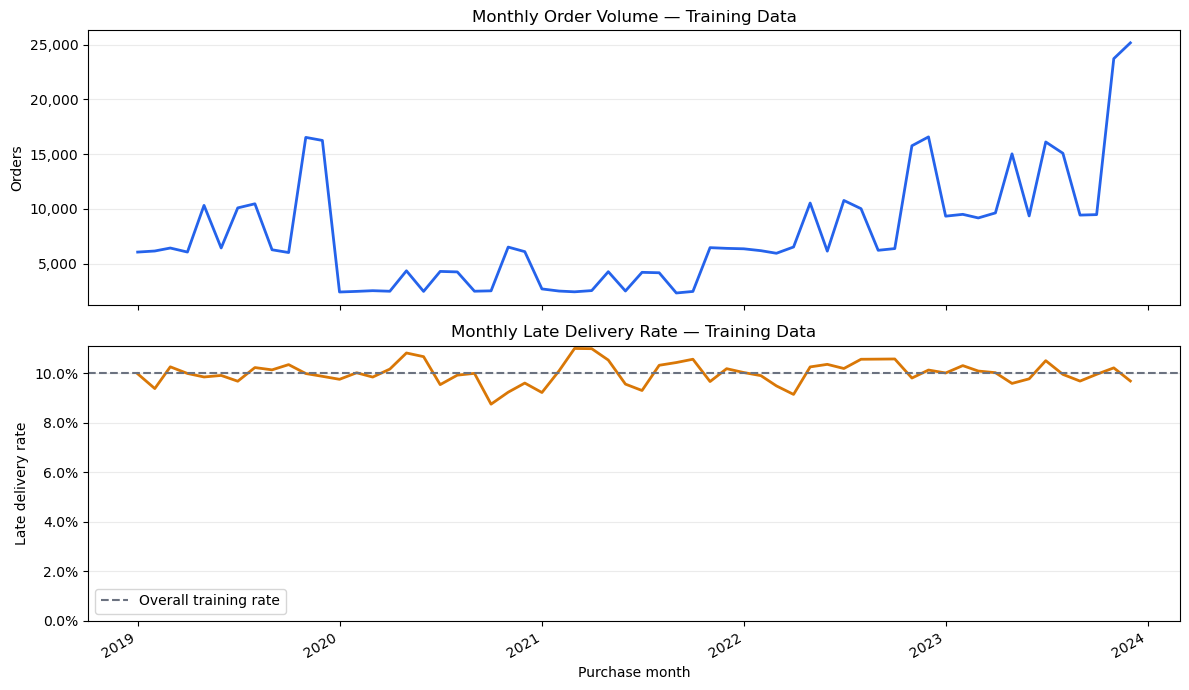

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Convert monthly periods to timestamps for plotting
month_dates = (
    monthly_summary["purchase_year_month"].dt.to_timestamp()
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

# Monthly order volume
axes[0].plot(
    month_dates,
    monthly_summary["order_count"],
    color="#2563EB",
    linewidth=2
)

axes[0].set_title("Monthly Order Volume — Training Data")
axes[0].set_ylabel("Orders")
axes[0].yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

# Monthly late-delivery rate
axes[1].plot(
    month_dates,
    monthly_summary["late_delivery_rate_pct"],
    color="#D97706",
    linewidth=2
)

# Overall training rate for comparison
axes[1].axhline(
    100 * train_df["target_late_delivery"].mean(),
    color="#6B7280",
    linestyle="--",
    label="Overall training rate"
)

axes[1].set_title("Monthly Late Delivery Rate — Training Data")
axes[1].set_ylabel("Late delivery rate")
axes[1].set_xlabel("Purchase month")
axes[1].set_ylim(bottom=0)
axes[1].yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Findings

Monthly order volume shows recurring peaks in November and December.
Order counts are lower in 2020–2021 than in 2019 and 2022–2023;
the dataset alone does not establish the reason for this difference.

Monthly late-delivery rates range from 8.75% to 11.00%, remaining
close to the overall training rate of 9.99%. Higher-volume months
do not consistently show higher late-delivery rates.

This monthly summary does not show a strong descriptive relationship
between order volume and late-delivery rate. Further analysis will
examine order and logistics characteristics.

## 9. Late Delivery by Distance Band

Compare late-delivery rates across distance bands based on the
item-weighted customer-to-seller great-circle distance in miles.

Report order counts alongside rates to show the size of each group.
These distances approximate geographic separation, not actual shipping routes.

In [11]:
# Preserve the distance-band order defined in SQL
distance_order = [
    "Under 100 miles",
    "100-299 miles",
    "300-599 miles",
    "600-999 miles",
    "1,000+ miles",
    "Missing distance"
]

distance_summary = (
    train_df
    .groupby("distance_band", dropna=False)
    .agg(
        order_count=("order_id", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reset_index()
)

distance_summary["late_delivery_rate_pct"] = (
    100 * distance_summary["late_delivery_rate"]
)

# Sort existing groups without adding empty groups
distance_summary["band_order"] = (
    distance_summary["distance_band"]
    .map({band: i for i, band in enumerate(distance_order)})
)

distance_summary = (
    distance_summary
    .sort_values("band_order")
    .drop(columns="band_order")
)

distance_summary[
    [
        "distance_band",
        "order_count",
        "late_order_count",
        "late_delivery_rate_pct"
    ]
].round({"late_delivery_rate_pct": 2})

,distance_band,order_count,late_order_count,late_delivery_rate_pct
4,Under 100 miles,26782,2713,10.13
1,100-299 miles,2430,290,11.93
2,300-599 miles,26506,2711,10.23
3,600-999 miles,97682,9725,9.96
0,"1,000+ miles",308344,30705,9.96


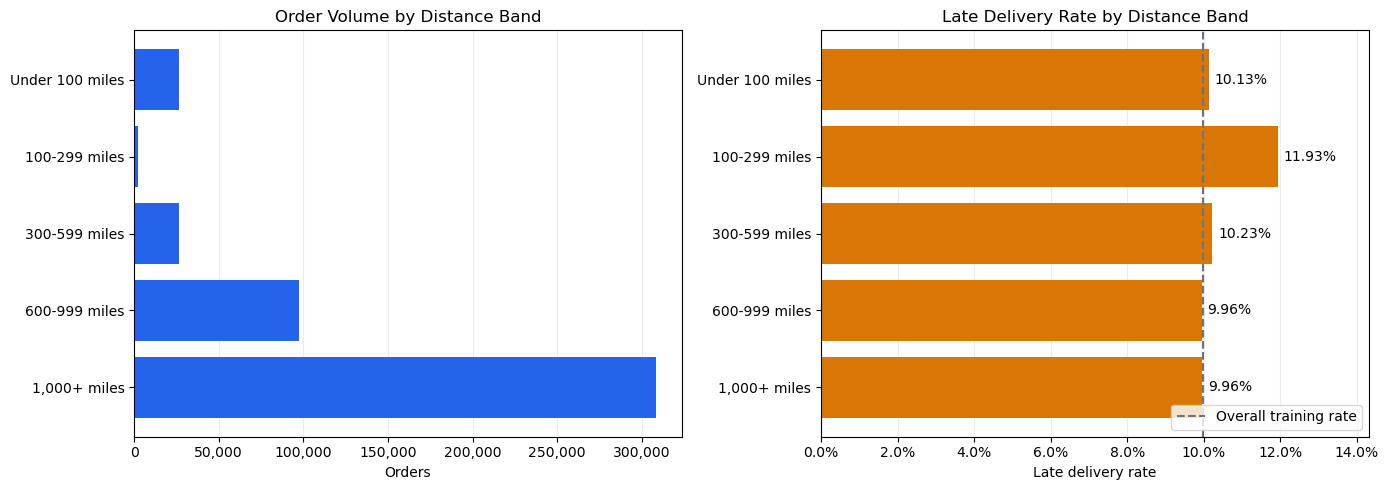

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Order volume by distance band
axes[0].barh(
    distance_summary["distance_band"],
    distance_summary["order_count"],
    color="#2563EB"
)

axes[0].set_title("Order Volume by Distance Band")
axes[0].set_xlabel("Orders")
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

# Late-delivery rate by distance band
bars = axes[1].barh(
    distance_summary["distance_band"],
    distance_summary["late_delivery_rate_pct"],
    color="#D97706"
)

axes[1].axvline(
    100 * train_df["target_late_delivery"].mean(),
    color="#6B7280",
    linestyle="--",
    label="Overall training rate"
)

axes[1].bar_label(bars, fmt="%.2f%%", padding=4)
axes[1].set_title("Late Delivery Rate by Distance Band")
axes[1].set_xlabel("Late delivery rate")
axes[1].invert_yaxis()
axes[1].set_xlim(
    0,
    distance_summary["late_delivery_rate_pct"].max() * 1.2
)
axes[1].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend(loc="lower right")

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Findings

Late-delivery rates do not increase consistently across distance bands.
The 100–299 mile group has the highest observed rate at 11.93%, but
contains only 2,430 orders, substantially fewer than the other groups.

Orders in the 1,000+ mile band represent approximately 66.78% of
training orders and have a late-delivery rate of 9.96%, close to
the overall training rate of 9.99%.

These grouped results do not establish a causal effect or rule out
distance as a useful predictor when combined with other features.

## 10. Estimated Delivery Window & Late Delivery

Inspect the estimated delivery window before comparing late-delivery
rates across groups. This variable represents the time allowed between
purchase and the estimated delivery date, subject to verification
of its SQL definition.

In [13]:
# Inspect the estimated delivery window in training data
delivery_days = train_df["estimated_delivery_days"]

delivery_days_summary = delivery_days.describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame(name="estimated_delivery_days")

print("Negative values:", (delivery_days < 0).sum())
print("Zero values:", (delivery_days == 0).sum())
print("Unique values:", delivery_days.nunique())

delivery_days_summary.round(2)

Negative values: 0
Zero values: 0
Unique values: 9475


,estimated_delivery_days
count,461744.00
mean,9.10
std,2.32
min,3.01
1%,5.06
25%,7.38
50%,9.03
75%,10.30
90%,12.18
95%,12.40


### Delivery Window Groups

Compare order counts and late-delivery rates across estimated delivery
windows: under 7 days, 7–under 10 days, 10–under 14 days, and 14 days or more.

These groups are used for descriptive analysis. The original numerical
variable remains unchanged.

In [14]:
# Create delivery-window groups for training EDA only
delivery_window_labels = [
    "Under 7 days",
    "7–under 10 days",
    "10–under 14 days",
    "14+ days"
]

train_df["estimated_delivery_band"] = pd.cut(
    train_df["estimated_delivery_days"],
    bins=[0, 7, 10, 14, float("inf")],
    labels=delivery_window_labels,
    right=False
)

# Confirm that every training order belongs to a group
assert train_df["estimated_delivery_band"].notna().all(), (
    "Some estimated delivery values fall outside the defined groups."
)

# Summarize counts and late-delivery rates
delivery_window_summary = (
    train_df
    .groupby("estimated_delivery_band", observed=True)
    .agg(
        order_count=("order_id", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reset_index()
)

delivery_window_summary["late_delivery_rate_pct"] = (
    100 * delivery_window_summary["late_delivery_rate"]
)

delivery_window_summary[
    [
        "estimated_delivery_band",
        "order_count",
        "late_order_count",
        "late_delivery_rate_pct"
    ]
].round({"late_delivery_rate_pct": 2})

,estimated_delivery_band,order_count,late_order_count,late_delivery_rate_pct
0,Under 7 days,56807,4082,7.19
1,7–under 10 days,249757,10181,4.08
2,10–under 14 days,140194,16895,12.05
3,14+ days,14986,14986,100.00


In [15]:
# Investigate the 14-day boundary (TRAIN ONLY)

near_14 = train_df.loc[
    train_df["estimated_delivery_days"].between(13, 15),
    ["estimated_delivery_days", "target_late_delivery"]
].copy()

near_14["interval"] = pd.cut(
    near_14["estimated_delivery_days"],
    bins=[13, 13.5, 13.9, 13.99, 14, 14.01, 14.1, 14.5, 15.0001],
    right=False
)

boundary_summary = (
    near_14
    .groupby("interval", observed=False)
    .agg(
        order_count=("target_late_delivery", "size"),
        late_count=("target_late_delivery", "sum"),
        late_rate=("target_late_delivery", "mean"),
        min_estimated_days=("estimated_delivery_days", "min"),
        max_estimated_days=("estimated_delivery_days", "max")
    )
    .reset_index()
)

boundary_summary["late_rate_pct"] = (
    boundary_summary["late_rate"] * 100
)

display(boundary_summary)

,interval,order_count,late_count,late_rate,min_estimated_days,max_estimated_days,late_rate_pct
0,"[13.0, 13.5)",6865,4151,0.604661,13.0069,13.4167,60.466133
1,"[13.5, 13.9)",0,0,NaN,NaN,NaN,NaN
2,"[13.9, 13.99)",0,0,NaN,NaN,NaN,NaN
3,"[13.99, 14.0)",0,0,NaN,NaN,NaN,NaN
4,"[14.0, 14.01)",39,39,1.000000,14.0069,14.0097,100.000000
5,"[14.01, 14.1)",855,855,1.000000,14.0104,14.0993,100.000000
6,"[14.1, 14.5)",3066,3066,1.000000,14.1000,14.4167,100.000000
7,"[14.5, 15.0)",0,0,NaN,NaN,NaN,NaN


In [16]:
# Inspect exact estimated delivery-day values
# TRAIN ONLY — read-only

estimated_value_summary = (
    train_df
    .loc[
        train_df["estimated_delivery_days"].between(12, 16),
        ["estimated_delivery_days", "target_late_delivery"]
    ]
    .groupby("estimated_delivery_days")
    .agg(
        order_count=("target_late_delivery", "size"),
        late_count=("target_late_delivery", "sum"),
        late_rate=("target_late_delivery", "mean")
    )
    .reset_index()
    .sort_values("estimated_delivery_days")
)

estimated_value_summary["late_rate_pct"] = (
    estimated_value_summary["late_rate"] * 100
)

print("Number of unique estimated durations:",
      len(estimated_value_summary))

print("\nEstimated duration range:")
print(
    estimated_value_summary["estimated_delivery_days"].min(),
    estimated_value_summary["estimated_delivery_days"].max()
)

display(estimated_value_summary)

Number of unique estimated durations: 2364

Estimated duration range:
12.0069 15.4167


,estimated_delivery_days,order_count,late_count,late_rate,late_rate_pct
0,12.0069,69,7,0.101449,10.144928
1,12.0076,74,6,0.081081,8.108108
2,12.0083,76,5,0.065789,6.578947
3,12.0090,65,5,0.076923,7.692308
4,12.0097,55,4,0.072727,7.272727
...,...,...,...,...,...
2359,15.4139,8,8,1.000000,100.000000
2360,15.4146,8,8,1.000000,100.000000
2361,15.4153,9,9,1.000000,100.000000
2362,15.4160,6,6,1.000000,100.000000


### Validation Note

All 14,986 training orders with an estimated delivery window of
14 days or more are labeled as late deliveries.

This pattern requires verification of the feature and target definitions
before interpretation or modeling. It does not by itself establish leakage
or a causal relationship.

### Synthetic Data Context and Interpretation

The source dataset is fully synthetic and was generated using Python
and rule-based simulation. The documentation states that delivery
times depend on distance and random delays, while review scores are
influenced by delays and price levels.

All 14,986 training orders with estimated delivery windows of at least
14 days are labeled as late. The SQL audit confirmed that this pattern
is present in the staging timestamps, with zero feature or target
calculation mismatches.

The available documentation does not explain the exact generation
rule for estimated delivery dates or confirm their availability at
checkout. This feature therefore requires further verification before
model inclusion.

Findings describe patterns within this simulated dataset and should
not be generalized to actual U.S. e-commerce operations.

## 11. Order Complexity and Late Delivery

This section examines the relationship between order complexity
and late delivery in the training data.

Two features are considered:
- Item count: the number of item records within an order.
- Seller count: the number of distinct sellers within an order.

Feature distributions are reviewed before comparing late-delivery
rates across groups.

In [17]:
# Review order complexity in TRAIN only
complexity_columns = ["item_count", "seller_count"]

complexity_summary = (
    train_df[complexity_columns]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .T
    .round(2)
)

display(complexity_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,max
item_count,461744.0,2.2,1.05,1.0,2.0,3.0,3.0,4.0,6.0,6.0
seller_count,461744.0,2.2,1.04,1.0,2.0,3.0,3.0,4.0,6.0,6.0


In [18]:
# Compare late-delivery rates by item count and seller count
complexity_tables = {}

for column in complexity_columns:
    summary = (
        train_df
        .groupby(column)
        .agg(
            order_count=("target_late_delivery", "size"),
            late_order_count=("target_late_delivery", "sum"),
            late_delivery_rate=("target_late_delivery", "mean")
        )
        .reset_index()
    )

    summary["late_delivery_rate_pct"] = (
        100 * summary["late_delivery_rate"]
    ).round(2)

    summary = summary.drop(columns="late_delivery_rate")
    complexity_tables[column] = summary

    print(f"\nLate delivery by {column}")
    display(summary)


Late delivery by item_count


,item_count,order_count,late_order_count,late_delivery_rate_pct
0,1,138319,13961,10.09
1,2,143470,14415,10.05
2,3,148990,14744,9.90
3,4,15432,1454,9.42
4,5,10425,1068,10.24
5,6,5108,502,9.83



Late delivery by seller_count


,seller_count,order_count,late_order_count,late_delivery_rate_pct
0,1,138593,13989,10.09
1,2,144072,14483,10.05
2,3,148301,14668,9.89
3,4,15458,1452,9.39
4,5,10384,1069,10.29
5,6,4936,483,9.79


In [19]:
# Inspect how item count and seller count overlap
item_seller_counts = pd.crosstab(
    train_df["item_count"],
    train_df["seller_count"]
)

display(item_seller_counts)

same_count_pct = (
    train_df["item_count"].eq(train_df["seller_count"]).mean() * 100
)

print(
    "Orders with equal item and seller counts: "
    f"{same_count_pct:.2f}%"
)

seller_count,1,2,3,4,5,6
item_count,,,,,,
1,138319,0,0,0,0,0
2,274,143196,0,0,0,0
3,0,876,148114,0,0,0
4,0,0,186,15246,0,0
5,0,0,1,210,10214,0
6,0,0,0,2,170,4936


Orders with equal item and seller counts: 99.63%


In [20]:
# Count orders for each observed feature value
for column in complexity_columns:
    count_summary = (
        train_df[column]
        .value_counts()
        .sort_index()
        .rename_axis(column)
        .reset_index(name="order_count")
    )

    count_summary["share_pct"] = (
        100 * count_summary["order_count"] / len(train_df)
    ).round(2)

    print(f"\nDistribution of {column}")
    display(count_summary)


Distribution of item_count


,item_count,order_count,share_pct
0,1,138319,29.96
1,2,143470,31.07
2,3,148990,32.27
3,4,15432,3.34
4,5,10425,2.26
5,6,5108,1.11



Distribution of seller_count


,seller_count,order_count,share_pct
0,1,138593,30.02
1,2,144072,31.20
2,3,148301,32.12
3,4,15458,3.35
4,5,10384,2.25
5,6,4936,1.07


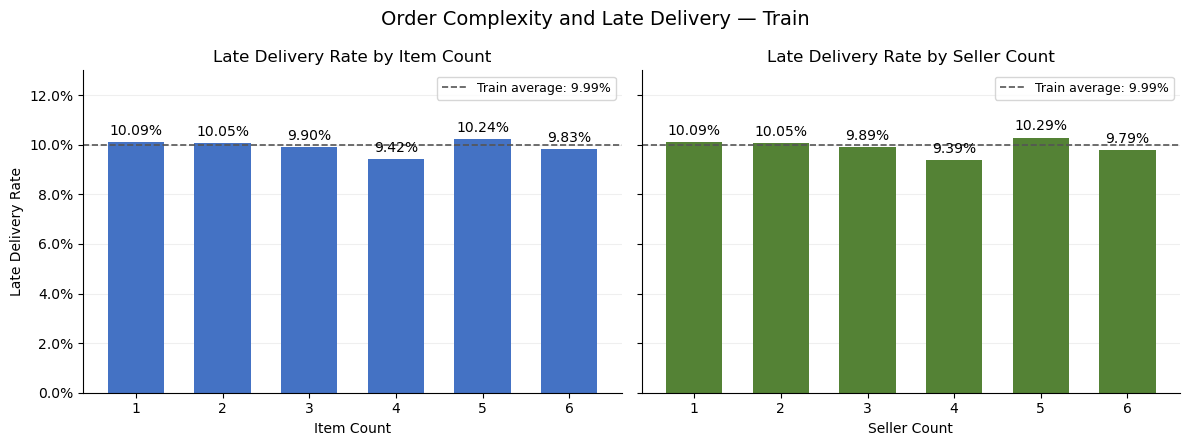

In [21]:
# Plot late-delivery rates by order complexity
train_late_rate_pct = (
    train_df["target_late_delivery"].mean() * 100
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharey=True
)

plot_settings = [
    ("item_count", "Item Count", "#4472C4"),
    ("seller_count", "Seller Count", "#548235")
]

for ax, (column, label, color) in zip(axes, plot_settings):
    summary = complexity_tables[column]

    bars = ax.bar(
        summary[column].astype(str),
        summary["late_delivery_rate_pct"],
        color=color,
        width=0.65
    )

    ax.axhline(
        train_late_rate_pct,
        color="#555555",
        linestyle="--",
        linewidth=1.2,
        label=f"Train average: {train_late_rate_pct:.2f}%"
    )

    ax.bar_label(bars, fmt="%.2f%%", padding=3)
    ax.set_title(f"Late Delivery Rate by {label}")
    ax.set_xlabel(label)
    ax.set_ylim(0, 13)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper right", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Late Delivery Rate")

fig.suptitle("Order Complexity and Late Delivery — Train", fontsize=14)
plt.tight_layout()
plt.show()

### Findings

Approximately 93.30% of training orders contain one to three items.
Orders with four to six items are less common.

Late-delivery rates range from 9.42% to 10.24% across item-count
groups and from 9.39% to 10.29% across seller-count groups.
Neither feature shows a consistent increase in late-delivery
rate as the count rises.

Item count equals seller count in 99.63% of training orders,
indicating substantial overlap between these features. Their
individual contributions should therefore be interpreted cautiously.

These comparisons do not show a strong standalone pattern.
They do not rule out predictive value through interactions
with other features.

## 12. Product Weight and Late Delivery

This section examines total product weight per order and its
relationship with late delivery in the training data.

The weight distribution is reviewed before defining comparison
groups. Total product weight is expressed in grams.

In [22]:
# Review total product weight in TRAIN
weight_summary = (
    train_df["total_product_weight_g"]
    .describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame(name="total_product_weight_g")
    .round(2)
)

display(weight_summary)

print(
    "Orders with zero or negative total weight:",
    train_df["total_product_weight_g"].le(0).sum()
)

,total_product_weight_g
count,461744.00
mean,9196.99
std,13291.89
min,100.00
1%,187.00
25%,1537.00
50%,4129.00
75%,8872.00
90%,29254.70
95%,41833.85


Orders with zero or negative total weight: 0


In [23]:
# Convert grams to kilograms for easier interpretation
train_df["total_product_weight_kg"] = (
    train_df["total_product_weight_g"] / 1000
)

# Define weight bands for EDA
weight_labels = [
    "Under 1 kg",
    "1–under 5 kg",
    "5–under 10 kg",
    "10–under 30 kg",
    "30+ kg"
]

train_df["total_weight_band"] = pd.cut(
    train_df["total_product_weight_kg"],
    bins=[0, 1, 5, 10, 30, float("inf")],
    labels=weight_labels,
    right=False
)

# Confirm every training order belongs to a band
assert train_df["total_weight_band"].notna().all()

# Compare late-delivery rates across weight bands
weight_band_summary = (
    train_df
    .groupby("total_weight_band", observed=True)
    .agg(
        order_count=("target_late_delivery", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reset_index()
)

weight_band_summary["share_pct"] = (
    100 * weight_band_summary["order_count"] / len(train_df)
).round(2)

weight_band_summary["late_delivery_rate_pct"] = (
    100 * weight_band_summary["late_delivery_rate"]
).round(2)

weight_band_summary = weight_band_summary.drop(
    columns="late_delivery_rate"
)

display(weight_band_summary)

,total_weight_band,order_count,late_order_count,share_pct,late_delivery_rate_pct
0,Under 1 kg,82106,8244,17.78,10.04
1,1–under 5 kg,188751,18897,40.88,10.01
2,5–under 10 kg,85455,8458,18.51,9.90
3,10–under 30 kg,60790,6012,13.17,9.89
4,30+ kg,44642,4533,9.67,10.15


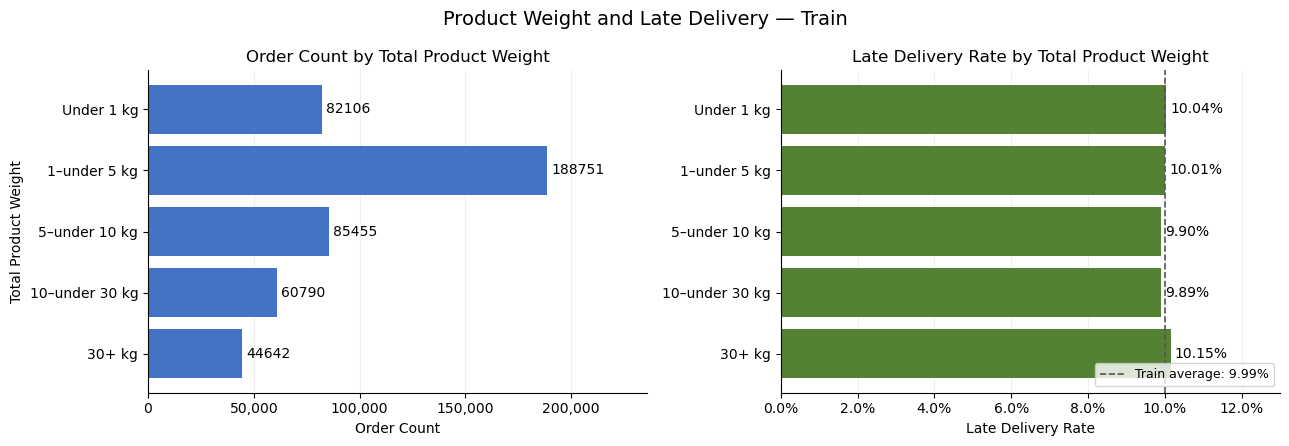

In [24]:
# Plot order volume and late-delivery rate by weight band
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

weight_band_names = (
    weight_band_summary["total_weight_band"].astype(str)
)

# Order volume
volume_bars = axes[0].barh(
    weight_band_names,
    weight_band_summary["order_count"],
    color="#4472C4"
)

axes[0].bar_label(volume_bars, fmt="%.0f", padding=3)
axes[0].set_title("Order Count by Total Product Weight")
axes[0].set_xlabel("Order Count")
axes[0].set_ylabel("Total Product Weight")
axes[0].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)
axes[0].set_xlim(
    0, weight_band_summary["order_count"].max() * 1.25
)

# Late-delivery rate
rate_bars = axes[1].barh(
    weight_band_names,
    weight_band_summary["late_delivery_rate_pct"],
    color="#548235"
)

axes[1].bar_label(rate_bars, fmt="%.2f%%", padding=3)
axes[1].axvline(
    train_late_rate_pct,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Train average: {train_late_rate_pct:.2f}%"
)

axes[1].set_title("Late Delivery Rate by Total Product Weight")
axes[1].set_xlabel("Late Delivery Rate")
axes[1].set_xlim(0, 13)
axes[1].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.invert_yaxis()
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Product Weight and Late Delivery — Train", fontsize=14)
plt.tight_layout()
plt.show()

### Findings

Total product weight is right-skewed, with a mean of 9.20 kg
and a median of 4.13 kg. No zero or negative weights were found.

The largest group contains orders weighing 1–under 5 kg,
representing 40.88% of training orders. Orders weighing at least
30 kg account for 9.67%.

Late-delivery rates range from 9.89% to 10.15% across weight
bands, a difference of approximately 0.26 percentage points.
There is no consistent increase in late-delivery rate as
total weight rises.

These grouped comparisons show limited standalone separation.
Weight may still contribute through interactions with distance,
product characteristics, or other features.

## 13. Freight Charge and Late Delivery

This section examines the relationship between order-level
freight charges and late delivery in the training data.

The freight-charge distribution is reviewed before defining
comparison groups. Freight charges represent amounts charged
to customers, rather than actual logistics operating costs.

In [25]:
# Review freight charges in TRAIN
freight_summary = (
    train_df["freight_charge"]
    .describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame(name="freight_charge")
    .round(2)
)

display(freight_summary)

print(
    "Orders with zero freight charge:",
    train_df["freight_charge"].eq(0).sum()
)

print(
    "Orders with negative freight charge:",
    train_df["freight_charge"].lt(0).sum()
)

,freight_charge
count,461744.00
mean,239.23
std,150.02
min,5.08
1%,5.79
25%,122.52
50%,209.62
75%,324.51
90%,431.40
95%,514.49


Orders with zero freight charge: 0
Orders with negative freight charge: 0


In [26]:
# Define freight-charge bands for TRAIN EDA
freight_labels = [
    "Under 100",
    "100–under 200",
    "200–under 300",
    "300–under 500",
    "500+"
]

train_df["freight_charge_band"] = pd.cut(
    train_df["freight_charge"],
    bins=[0, 100, 200, 300, 500, float("inf")],
    labels=freight_labels,
    right=False
)

# Confirm every training order belongs to a band
assert train_df["freight_charge_band"].notna().all()

# Compare late-delivery rates across freight-charge bands
freight_band_summary = (
    train_df
    .groupby("freight_charge_band", observed=True)
    .agg(
        order_count=("target_late_delivery", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reset_index()
)

freight_band_summary["share_pct"] = (
    100 * freight_band_summary["order_count"] / len(train_df)
).round(2)

freight_band_summary["late_delivery_rate_pct"] = (
    100 * freight_band_summary["late_delivery_rate"]
).round(2)

freight_band_summary = freight_band_summary.drop(
    columns="late_delivery_rate"
)

display(freight_band_summary)

,freight_charge_band,order_count,late_order_count,share_pct,late_delivery_rate_pct
0,Under 100,82436,8352,17.85,10.13
1,100–under 200,121135,12159,26.23,10.04
2,200–under 300,119142,11839,25.80,9.94
3,300–under 500,111987,11119,24.25,9.93
4,500+,27044,2675,5.86,9.89


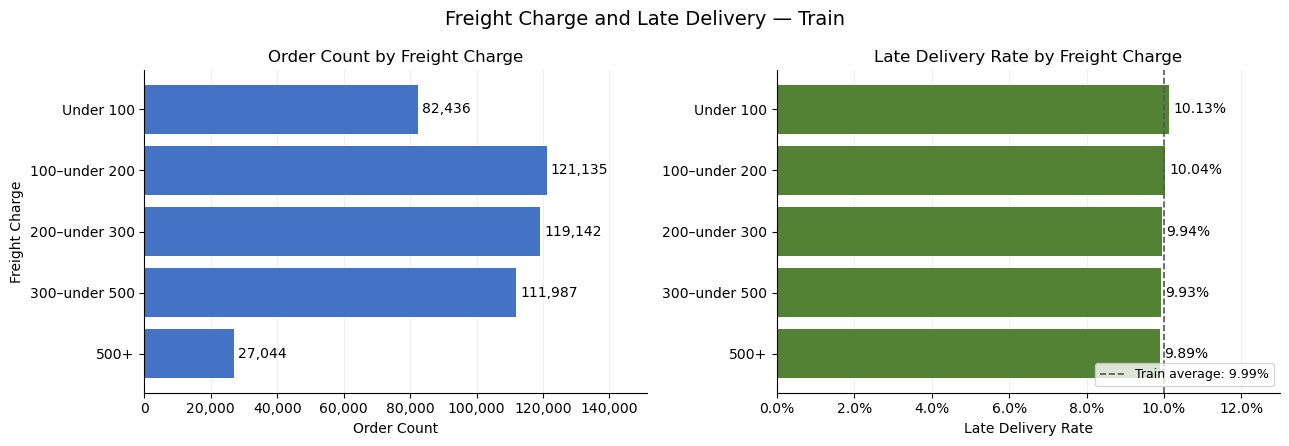

In [27]:
# Plot order volume and late-delivery rate by freight-charge band
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

freight_band_names = (
    freight_band_summary["freight_charge_band"].astype(str)
)

# Order volume
volume_bars = axes[0].barh(
    freight_band_names,
    freight_band_summary["order_count"],
    color="#4472C4"
)

axes[0].bar_label(
    volume_bars,
    labels=[
        f"{count:,.0f}"
        for count in freight_band_summary["order_count"]
    ],
    padding=3
)

axes[0].set_title("Order Count by Freight Charge")
axes[0].set_xlabel("Order Count")
axes[0].set_ylabel("Freight Charge")
axes[0].set_xlim(
    0, freight_band_summary["order_count"].max() * 1.25
)
axes[0].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

# Late-delivery rate
rate_bars = axes[1].barh(
    freight_band_names,
    freight_band_summary["late_delivery_rate_pct"],
    color="#548235"
)

axes[1].bar_label(rate_bars, fmt="%.2f%%", padding=3)

axes[1].axvline(
    train_late_rate_pct,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Train average: {train_late_rate_pct:.2f}%"
)

axes[1].set_title("Late Delivery Rate by Freight Charge")
axes[1].set_xlabel("Late Delivery Rate")
axes[1].set_xlim(0, 13)
axes[1].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.invert_yaxis()
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Freight Charge and Late Delivery — Train", fontsize=14)
plt.tight_layout()
plt.show()

### Findings

Freight charges have a mean of 239.23 and a median of 209.62.
No zero or negative charges were found in the training data.

The 100–under 200 band is the largest group, accounting for
26.23% of training orders. Charges of at least 500 represent
5.86%.

Late-delivery rates decrease slightly across the selected bands,
from 10.13% for charges below 100 to 9.89% for charges of at
least 500. The difference is approximately 0.24 percentage points,
and all rates remain close to the training average of 9.99%.

These comparisons show limited standalone separation and do
not establish that higher freight charges reduce delivery delays.

## 14. Customer State and Late Delivery

This section compares order volume and late-delivery rates
across customer states in the training data.

Group sizes are reported alongside delivery rates to support
interpretation. Geographic patterns reflect the synthetic
dataset and its simulated regional structure.


In [28]:
# Compare late-delivery rates across customer states
state_summary = (
    train_df
    .groupby("customer_state", dropna=False)
    .agg(
        order_count=("target_late_delivery", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reset_index()
)

state_summary["share_pct"] = (
    100 * state_summary["order_count"] / len(train_df)
).round(2)

state_summary["late_delivery_rate_pct"] = (
    100 * state_summary["late_delivery_rate"]
).round(2)

state_summary = (
    state_summary
    .drop(columns="late_delivery_rate")
    .sort_values("order_count", ascending=False)
    .reset_index(drop=True)
)

print("Number of customer states:", len(state_summary))
display(state_summary)

Number of customer states: 10


,customer_state,order_count,late_order_count,share_pct,late_delivery_rate_pct
0,CA,116103,11571,25.14,9.97
1,TX,87845,8679,19.02,9.88
2,FL,63685,6408,13.79,10.06
3,NY,57956,5785,12.55,9.98
4,PA,38762,3955,8.39,10.20
5,IL,38490,3845,8.34,9.99
6,GA,29133,2928,6.31,10.05
7,CO,10096,1035,2.19,10.25
8,WA,9946,978,2.15,9.83
9,AZ,9728,960,2.11,9.87


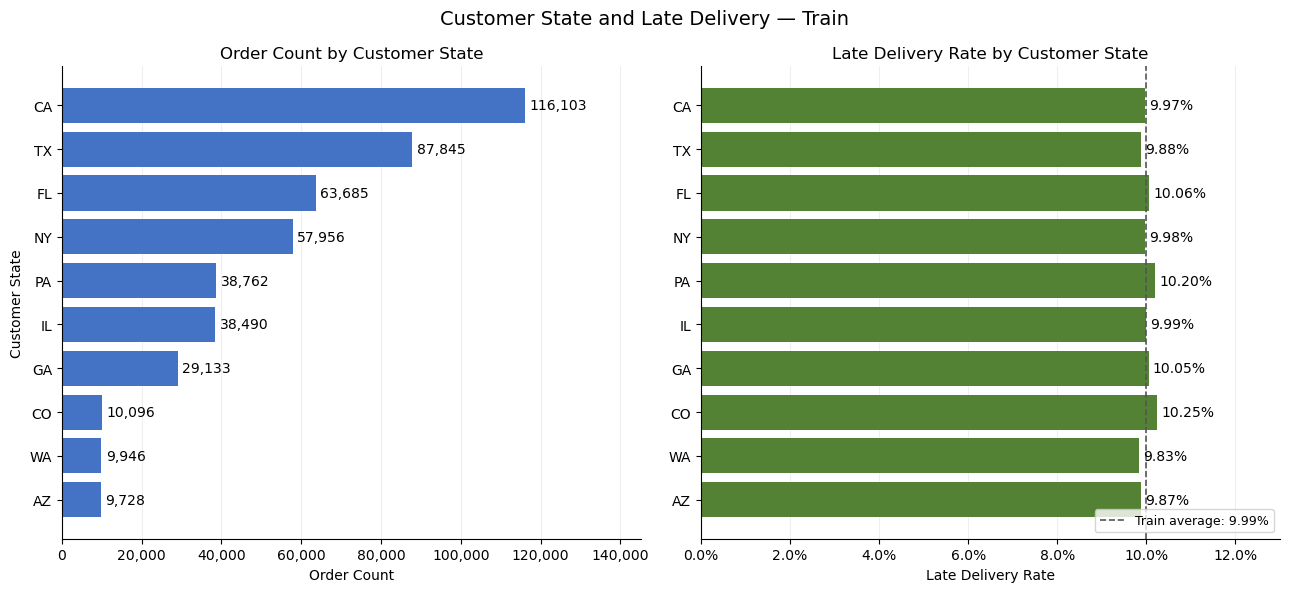

In [29]:
# Plot order volume and late-delivery rate across customer states
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

state_names = state_summary["customer_state"]

# Order volume
volume_bars = axes[0].barh(
    state_names,
    state_summary["order_count"],
    color="#4472C4"
)

axes[0].bar_label(
    volume_bars,
    labels=[
        f"{count:,.0f}"
        for count in state_summary["order_count"]
    ],
    padding=3
)

axes[0].set_title("Order Count by Customer State")
axes[0].set_xlabel("Order Count")
axes[0].set_ylabel("Customer State")
axes[0].set_xlim(
    0, state_summary["order_count"].max() * 1.25
)
axes[0].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

# Late-delivery rate
rate_bars = axes[1].barh(
    state_names,
    state_summary["late_delivery_rate_pct"],
    color="#548235"
)

axes[1].bar_label(rate_bars, fmt="%.2f%%", padding=3)
axes[1].axvline(
    train_late_rate_pct,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Train average: {train_late_rate_pct:.2f}%"
)

axes[1].set_title("Late Delivery Rate by Customer State")
axes[1].set_xlabel("Late Delivery Rate")
axes[1].set_xlim(0, 13)
axes[1].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.invert_yaxis()
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Customer State and Late Delivery — Train", fontsize=14)
plt.tight_layout()
plt.show()

### Findings

The training data contains customers from 10 states. California
accounts for 25.14% of orders, followed by Texas at 19.02%.
Together, these states represent 44.17% of training orders.

Late-delivery rates range from 9.83% in Washington to 10.25%
in Colorado, a difference of approximately 0.42 percentage points.
All state-level rates remain close to the training average of 9.99%.

These comparisons show limited standalone separation by customer
state. The observed differences do not establish distinct geographic
risk levels or explain the causes of delivery delays.

Geographic coverage is limited to the states represented in this
synthetic dataset. Findings should not be generalized to all
U.S. states or actual regional delivery performance.

## 15. Customer Segment and Late Delivery

This section compares order volume and late-delivery rates
across customer segments in the training data.

Segment-level differences are descriptive and do not establish
that customer segment causes delivery delays.

In [30]:
# Compare late-delivery rates across customer segments
segment_summary = (
    train_df
    .groupby("customer_segment", dropna=False)
    .agg(
        order_count=("target_late_delivery", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reset_index()
)

segment_summary["share_pct"] = (
    100 * segment_summary["order_count"] / len(train_df)
).round(2)

segment_summary["late_delivery_rate_pct"] = (
    100 * segment_summary["late_delivery_rate"]
).round(2)

segment_summary = (
    segment_summary
    .drop(columns="late_delivery_rate")
    .sort_values("order_count", ascending=False)
    .reset_index(drop=True)
)

display(segment_summary)

,customer_segment,order_count,late_order_count,share_pct,late_delivery_rate_pct
0,consumer,322878,32218,69.93,9.98
1,corporate,92455,9392,20.02,10.16
2,vip,46411,4534,10.05,9.77


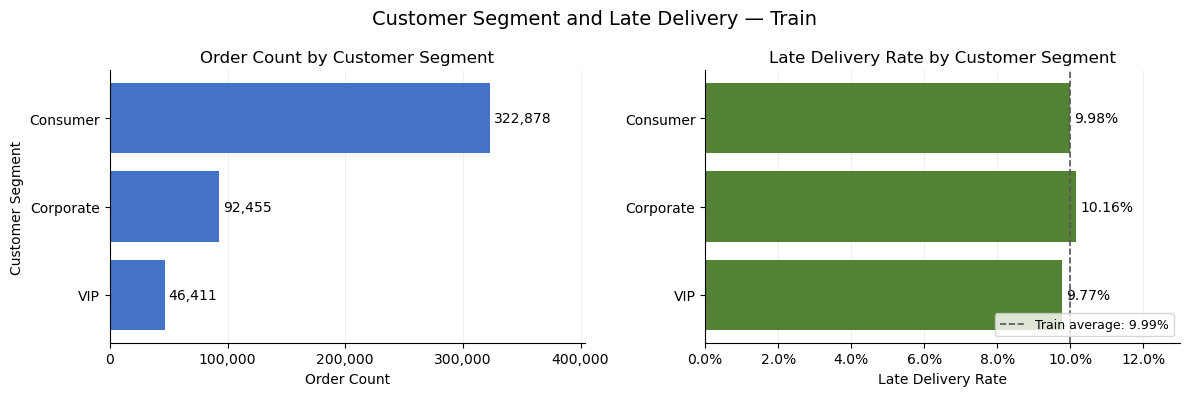

In [31]:
# Plot order volume and late-delivery rate by customer segment
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

segment_names = (
    segment_summary["customer_segment"]
    .replace({
        "consumer": "Consumer",
        "corporate": "Corporate",
        "vip": "VIP"
    })
)

# Order volume
volume_bars = axes[0].barh(
    segment_names,
    segment_summary["order_count"],
    color="#4472C4"
)

axes[0].bar_label(
    volume_bars,
    labels=[
        f"{count:,.0f}"
        for count in segment_summary["order_count"]
    ],
    padding=3
)

axes[0].set_title("Order Count by Customer Segment")
axes[0].set_xlabel("Order Count")
axes[0].set_ylabel("Customer Segment")
axes[0].set_xlim(
    0, segment_summary["order_count"].max() * 1.25
)
axes[0].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

# Late-delivery rate
rate_bars = axes[1].barh(
    segment_names,
    segment_summary["late_delivery_rate_pct"],
    color="#548235"
)

axes[1].bar_label(rate_bars, fmt="%.2f%%", padding=3)
axes[1].axvline(
    train_late_rate_pct,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Train average: {train_late_rate_pct:.2f}%"
)

axes[1].set_title("Late Delivery Rate by Customer Segment")
axes[1].set_xlabel("Late Delivery Rate")
axes[1].set_xlim(0, 13)
axes[1].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.invert_yaxis()
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Customer Segment and Late Delivery — Train", fontsize=14)
axes[0].xaxis.set_major_locator(mtick.MaxNLocator(nbins=5))
plt.tight_layout()
plt.show()

### Findings

Consumer orders account for 69.93% of the training data,
followed by Corporate orders at 20.02% and VIP orders at 10.05%.

Late-delivery rates are 9.98% for Consumer, 10.16% for Corporate,
and 9.77% for VIP orders. The difference between the highest
and lowest rates is approximately 0.39 percentage points.

All three rates remain close to the training average of 9.99%,
showing limited standalone separation by customer segment.

The lower observed rate for VIP orders does not establish
preferential delivery service or a causal effect of segment.

## 16. Purchase Timing and Late Delivery

This section examines late-delivery rates by purchase day
of the week in the training data.

Days are derived from the recorded purchase timestamps.
Their interpretation follows the source timestamp convention;
local time zones have not been verified.

In [32]:
# PostgreSQL DOW convention: Sunday = 0, Saturday = 6
day_names = {
    0: "Sunday",
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday"
}

# Display weekdays in Monday-to-Sunday order
day_order = [1, 2, 3, 4, 5, 6, 0]

purchase_day_summary = (
    train_df
    .groupby("purchase_day_of_week")
    .agg(
        order_count=("target_late_delivery", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .reindex(day_order)
    .rename_axis("purchase_day_of_week")
    .reset_index()
)

purchase_day_summary["purchase_day"] = (
    purchase_day_summary["purchase_day_of_week"].map(day_names)
)

purchase_day_summary["share_pct"] = (
    100 * purchase_day_summary["order_count"] / len(train_df)
).round(2)

purchase_day_summary["late_delivery_rate_pct"] = (
    100 * purchase_day_summary["late_delivery_rate"]
).round(2)

purchase_day_summary = purchase_day_summary[
    [
        "purchase_day",
        "order_count",
        "late_order_count",
        "share_pct",
        "late_delivery_rate_pct"
    ]
]

display(purchase_day_summary)

,purchase_day,order_count,late_order_count,share_pct,late_delivery_rate_pct
0,Monday,66170,6596,14.33,9.97
1,Tuesday,39887,3914,8.64,9.81
2,Wednesday,32994,3295,7.15,9.99
3,Thursday,49774,4990,10.78,10.03
4,Friday,79972,8025,17.32,10.03
5,Saturday,92840,9437,20.11,10.16
6,Sunday,100107,9887,21.68,9.88


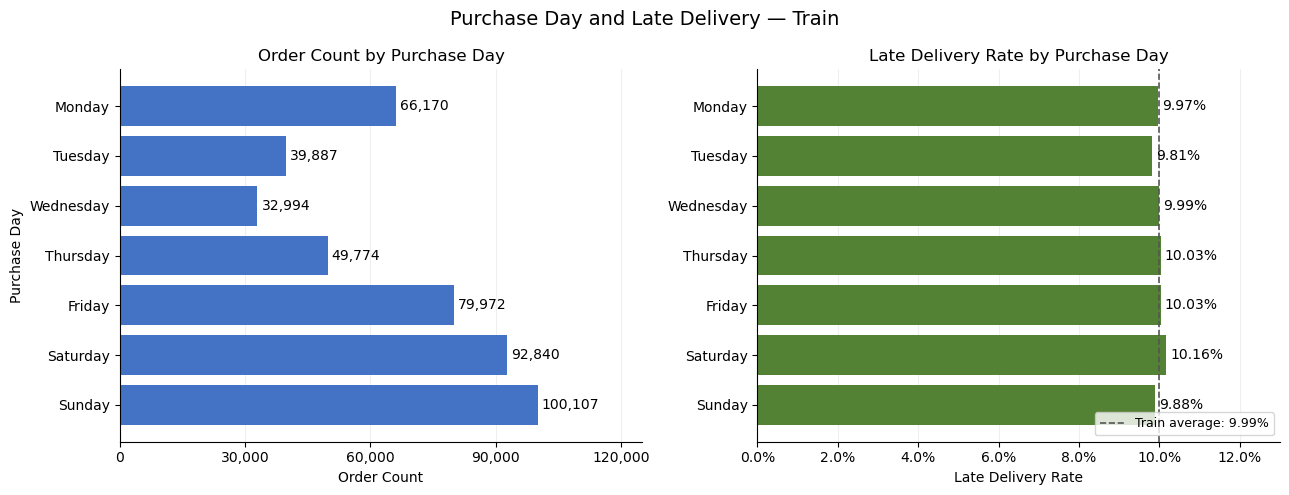

In [33]:
# Plot order volume and late-delivery rate by purchase day
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

day_labels = purchase_day_summary["purchase_day"]

# Order volume
volume_bars = axes[0].barh(
    day_labels,
    purchase_day_summary["order_count"],
    color="#4472C4"
)

axes[0].bar_label(
    volume_bars,
    labels=[
        f"{count:,.0f}"
        for count in purchase_day_summary["order_count"]
    ],
    padding=3
)

axes[0].set_title("Order Count by Purchase Day")
axes[0].set_xlabel("Order Count")
axes[0].set_ylabel("Purchase Day")
axes[0].set_xlim(
    0, purchase_day_summary["order_count"].max() * 1.25
)
axes[0].xaxis.set_major_locator(mtick.MaxNLocator(nbins=5))
axes[0].xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

# Late-delivery rate
rate_bars = axes[1].barh(
    day_labels,
    purchase_day_summary["late_delivery_rate_pct"],
    color="#548235"
)

axes[1].bar_label(rate_bars, fmt="%.2f%%", padding=3)
axes[1].axvline(
    train_late_rate_pct,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Train average: {train_late_rate_pct:.2f}%"
)

axes[1].set_title("Late Delivery Rate by Purchase Day")
axes[1].set_xlabel("Late Delivery Rate")
axes[1].set_xlim(0, 13)
axes[1].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.invert_yaxis()
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Purchase Day and Late Delivery — Train", fontsize=14)
plt.tight_layout()
plt.show()

### Findings

Sunday has the largest share of training orders at 21.68%,
followed by Saturday at 20.11%. Together, weekend purchases
account for 41.79% of training orders.

Late-delivery rates range from 9.81% on Tuesday to 10.16%
on Saturday, a difference of approximately 0.35 percentage points.
All daily rates remain close to the training average of 9.99%.

Saturday and Sunday have relatively high order volumes, but
their late-delivery rates do not show a consistent weekend
increase. Purchase day alone provides limited separation
in these grouped comparisons.

These patterns describe the recorded timestamps in the
synthetic dataset and do not establish operational causes.

### Purchase Hour and Late Delivery

This analysis compares order volume and late-delivery rates
across recorded purchase hours, from 00:00 to 23:00.

Hours follow the source timestamps and should not be interpreted
as customer local time because time zones have not been verified.

In [34]:
# Validate recorded purchase hours
assert train_df["purchase_hour"].notna().all()
assert train_df["purchase_hour"].between(0, 23).all()

# Compare late-delivery rates by purchase hour
purchase_hour_summary = (
    train_df
    .groupby("purchase_hour")
    .agg(
        order_count=("target_late_delivery", "size"),
        late_order_count=("target_late_delivery", "sum"),
        late_delivery_rate=("target_late_delivery", "mean")
    )
    .sort_index()
    .reset_index()
)

purchase_hour_summary["share_pct"] = (
    100 * purchase_hour_summary["order_count"] / len(train_df)
).round(2)

purchase_hour_summary["late_delivery_rate_pct"] = (
    100 * purchase_hour_summary["late_delivery_rate"]
).round(2)

purchase_hour_summary = purchase_hour_summary.drop(
    columns="late_delivery_rate"
)

display(purchase_hour_summary)

,purchase_hour,order_count,late_order_count,share_pct,late_delivery_rate_pct
0,0,3803,365,0.82,9.60
1,1,2724,243,0.59,8.92
2,2,1839,214,0.40,11.64
3,3,1332,131,0.29,9.83
4,4,1707,167,0.37,9.78
5,5,3276,323,0.71,9.86
6,6,6900,687,1.49,9.96
7,7,12529,1259,2.71,10.05
8,8,17456,1699,3.78,9.73
9,9,22396,2266,4.85,10.12


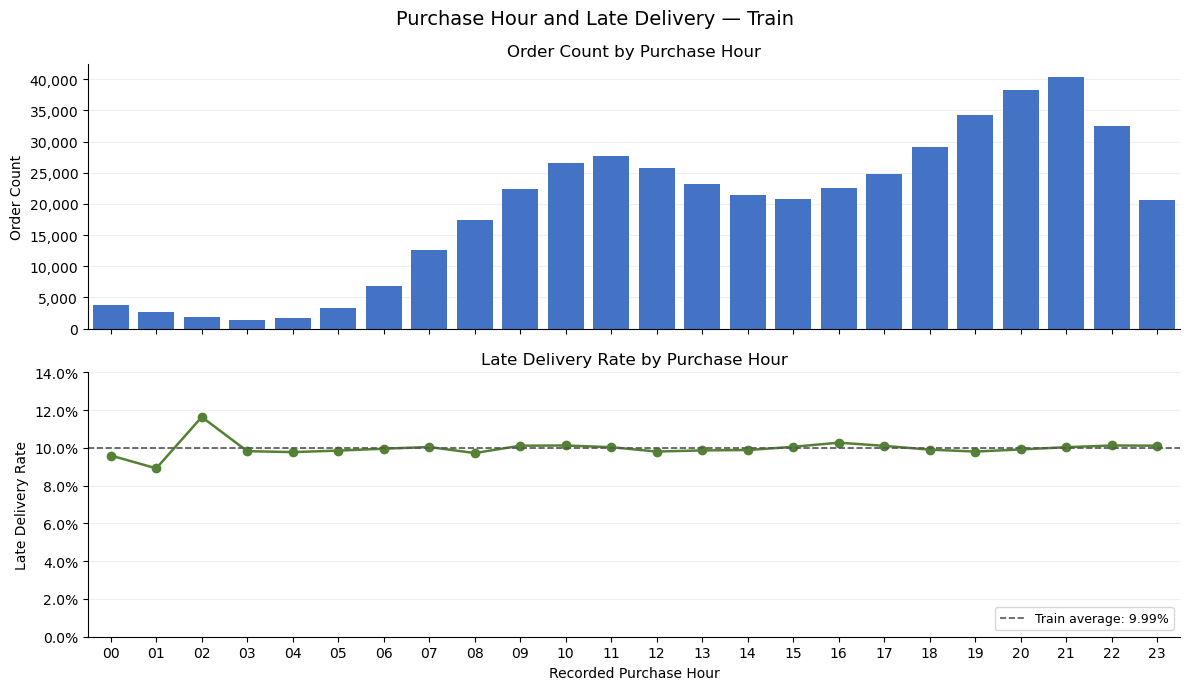

In [35]:
# Plot order volume and late-delivery rate by recorded purchase hour
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

hours = purchase_hour_summary["purchase_hour"]

# Order volume
axes[0].bar(
    hours,
    purchase_hour_summary["order_count"],
    color="#4472C4",
    width=0.8
)

axes[0].set_title("Order Count by Purchase Hour")
axes[0].set_ylabel("Order Count")
axes[0].yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

# Late-delivery rate
axes[1].plot(
    hours,
    purchase_hour_summary["late_delivery_rate_pct"],
    color="#548235",
    marker="o",
    linewidth=1.8
)

axes[1].axhline(
    train_late_rate_pct,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Train average: {train_late_rate_pct:.2f}%"
)

axes[1].set_title("Late Delivery Rate by Purchase Hour")
axes[1].set_ylabel("Late Delivery Rate")
axes[1].set_xlabel("Recorded Purchase Hour")
axes[1].set_ylim(0, 14)
axes[1].yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
axes[1].legend(loc="lower right", fontsize=9)

axes[1].set_xticks(range(24))
axes[1].set_xticklabels(
    [f"{hour:02d}" for hour in range(24)]
)
axes[1].set_xlim(-0.5, 23.5)

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Purchase Hour and Late Delivery — Train", fontsize=14)
plt.tight_layout()
plt.show()

### Purchase Hour Findings

Order volume peaks at 21:00–21:59, with 40,364 orders,
representing 8.74% of the training data. The lowest volume
occurs at 03:00–03:59, with 1,332 orders.

Hourly late-delivery rates range from 8.92% at 01:00–01:59
to 11.64% at 02:00–02:59. These two groups contain only
2,724 and 1,839 orders, respectively, so their rates should
be interpreted with greater caution.

Across recorded hours from 06:00 through 23:59, rates remain
between 9.73% and 10.28%, close to the training average of 9.99%.
The grouped results do not show a clear hourly risk pattern.

Hours refer to the source timestamps. Customer local time
and operational explanations have not been established.

## 17. Payment Methods and Late Delivery

This section compares late-delivery rates between orders that
use each payment method and orders that do not.

An order may use multiple payment methods. Method usage groups
therefore overlap, and their shares may sum to more than 100%.
These comparisons do not isolate the effect of payment method.

In [36]:
# Compare users and non-users of each payment method in TRAIN
payment_methods = {
    "used_credit_card": "Credit Card",
    "used_debit_card": "Debit Card",
    "used_paypal": "PayPal",
    "used_apple_pay": "Apple Pay",
    "used_bank_transfer": "Bank Transfer",
    "used_voucher": "Voucher",
    "used_boleto": "Boleto"
}

payment_tables = []

for column, method_name in payment_methods.items():
    assert train_df[column].notna().all()
    assert train_df[column].isin([True, False]).all()

    summary = (
        train_df
        .groupby(column)
        .agg(
            order_count=("target_late_delivery", "size"),
            late_order_count=("target_late_delivery", "sum"),
            late_delivery_rate=("target_late_delivery", "mean")
        )
        .reset_index()
        .rename(columns={column: "used_method"})
    )

    summary["payment_method"] = method_name
    summary["share_pct"] = (
        100 * summary["order_count"] / len(train_df)
    ).round(2)

    summary["late_delivery_rate_pct"] = (
        100 * summary["late_delivery_rate"]
    ).round(2)

    payment_tables.append(summary)

payment_method_summary = pd.concat(
    payment_tables,
    ignore_index=True
)[
    [
        "payment_method",
        "used_method",
        "order_count",
        "late_order_count",
        "share_pct",
        "late_delivery_rate_pct"
    ]
]

display(payment_method_summary)

,payment_method,used_method,order_count,late_order_count,share_pct,late_delivery_rate_pct
0,Credit Card,False,224886,22655,48.70,10.07
1,Credit Card,True,236858,23489,51.30,9.92
2,Debit Card,False,419785,41965,90.91,10.00
3,Debit Card,True,41959,4179,9.09,9.96
4,PayPal,False,381244,38091,82.57,9.99
5,PayPal,True,80500,8053,17.43,10.00
6,Apple Pay,False,419434,41868,90.84,9.98
7,Apple Pay,True,42310,4276,9.16,10.11
8,Bank Transfer,False,417003,41637,90.31,9.98
9,Bank Transfer,True,44741,4507,9.69,10.07


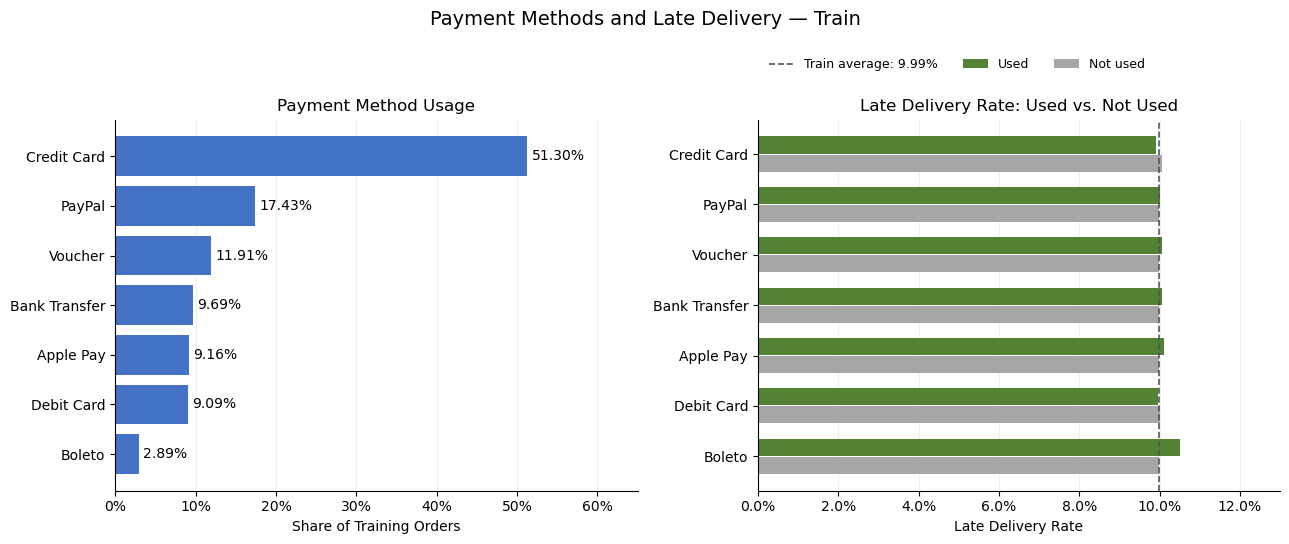

In [37]:
# Prepare usage shares and paired late-delivery rates
payment_usage = (
    payment_method_summary
    .loc[payment_method_summary["used_method"].eq(True)]
    .sort_values("order_count", ascending=False)
    .set_index("payment_method")
)

payment_rates = (
    payment_method_summary
    .pivot(
        index="payment_method",
        columns="used_method",
        values="late_delivery_rate_pct"
    )
    .reindex(payment_usage.index)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Share of orders using each method
usage_bars = axes[0].barh(
    payment_usage.index,
    payment_usage["share_pct"],
    color="#4472C4"
)

axes[0].bar_label(usage_bars, fmt="%.2f%%", padding=3)
axes[0].set_title("Payment Method Usage")
axes[0].set_xlabel("Share of Training Orders")
axes[0].set_xlim(0, 65)
axes[0].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)

# Compare users and non-users within each method
positions = list(range(len(payment_rates)))

axes[1].barh(
    [position - 0.18 for position in positions],
    payment_rates[True],
    height=0.34,
    color="#548235",
    label="Used"
)

axes[1].barh(
    [position + 0.18 for position in positions],
    payment_rates[False],
    height=0.34,
    color="#A6A6A6",
    label="Not used"
)

axes[1].set_yticks(positions)
axes[1].set_yticklabels(payment_rates.index)
axes[1].set_title("Late Delivery Rate: Used vs. Not Used")
axes[1].set_xlabel("Late Delivery Rate")
axes[1].set_xlim(0, 13)
axes[1].xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)

axes[1].axvline(
    train_late_rate_pct,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Train average: {train_late_rate_pct:.2f}%"
)

axes[1].legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.10),
    ncol=3,
    fontsize=9,
    frameon=False
)

for ax in axes:
    ax.invert_yaxis()
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Payment Methods and Late Delivery — Train", fontsize=14)
plt.tight_layout()
plt.show()

### Findings

Credit Card is the most frequently used payment method,
appearing in 51.30% of training orders, followed by PayPal
at 17.43%. Boleto is the least common method at 2.89%.

For methods other than Boleto, differences in late-delivery
rates between users and non-users are no greater than
approximately 0.15 percentage points.

Boleto users have a late-delivery rate of 10.51%, compared
with 9.98% among non-users. This is the largest observed
within-method difference, approximately 0.53 percentage points.
The usage group contains 13,335 orders.

Overall, payment methods show limited standalone separation.
Usage groups overlap, and these comparisons do not control
for customer segment, order value, or other characteristics.
They do not establish a causal effect of payment method.

## 18. Relationships Between Numerical Features

This section examines correlations among selected numerical
features in the training data to identify overlapping information.

Spearman correlation is used to summarize monotonic relationships.
Correlation does not establish causation or determine which
features should be removed.

In [38]:
# Review relationships among selected numerical features
correlation_columns = [
    "item_count",
    "unique_product_count",
    "seller_count",
    "shipment_route_count",
    "total_product_weight_g",
    "average_product_volume_cm3",
    "net_merchandise_revenue",
    "freight_charge",
    "customer_payment",
    "item_weighted_distance_miles",
    "estimated_delivery_days"
]

feature_correlations = (
    train_df[correlation_columns]
    .corr(method="spearman")
)

display(feature_correlations.round(2))

,item_count,unique_product_count,seller_count,shipment_route_count,total_product_weight_g,average_product_volume_cm3,net_merchandise_revenue,freight_charge,customer_payment,item_weighted_distance_miles,estimated_delivery_days
item_count,1.00,1.00,1.00,1.00,0.53,0.15,0.51,0.75,0.59,0.00,-0.01
unique_product_count,1.00,1.00,1.00,1.00,0.53,0.15,0.51,0.75,0.59,0.00,-0.01
seller_count,1.00,1.00,1.00,1.00,0.53,0.15,0.51,0.75,0.59,0.00,-0.01
shipment_route_count,1.00,1.00,1.00,1.00,0.53,0.15,0.51,0.75,0.59,0.00,-0.01
total_product_weight_g,0.53,0.53,0.53,0.53,1.00,0.39,0.52,0.43,0.54,-0.00,-0.01
average_product_volume_cm3,0.15,0.15,0.15,0.15,0.39,1.00,0.09,0.13,0.09,-0.00,-0.00
net_merchandise_revenue,0.51,0.51,0.51,0.51,0.52,0.09,1.00,0.39,0.98,-0.00,-0.01
freight_charge,0.75,0.75,0.75,0.75,0.43,0.13,0.39,1.00,0.53,0.62,0.53
customer_payment,0.59,0.59,0.59,0.59,0.54,0.09,0.98,0.53,1.00,0.12,0.10
item_weighted_distance_miles,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.62,0.12,1.00,0.88


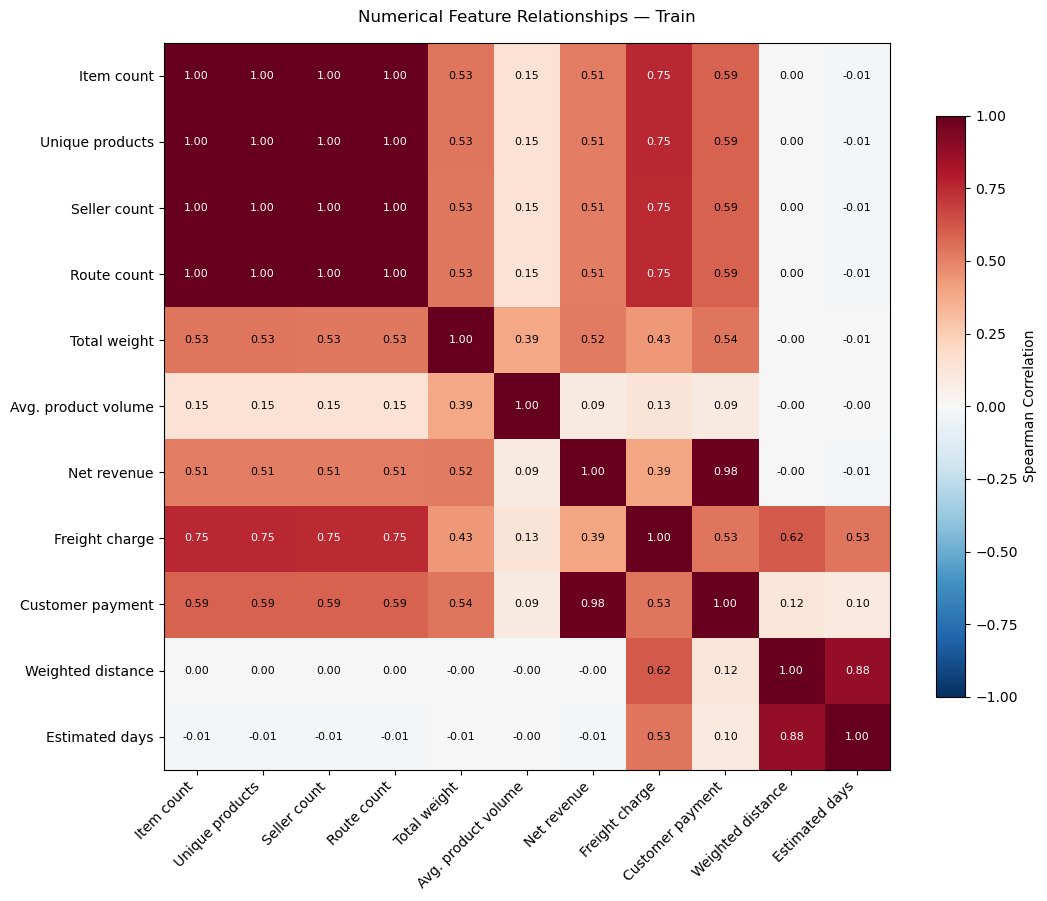

In [39]:
# Use shorter labels for the chart
correlation_labels = [
    "Item count",
    "Unique products",
    "Seller count",
    "Route count",
    "Total weight",
    "Avg. product volume",
    "Net revenue",
    "Freight charge",
    "Customer payment",
    "Weighted distance",
    "Estimated days"
]

fig, ax = plt.subplots(figsize=(11, 9))

heatmap = ax.imshow(
    feature_correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_labels)))
ax.set_yticks(range(len(correlation_labels)))
ax.set_xticklabels(
    correlation_labels,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(correlation_labels)

# Add correlation values to each cell
for row in range(len(correlation_labels)):
    for column in range(len(correlation_labels)):
        value = feature_correlations.iloc[row, column]

        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(value) >= 0.65 else "black"
        )

fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.8,
    label="Spearman Correlation"
)

ax.set_title(
    "Numerical Feature Relationships — Train",
    pad=15
)

plt.tight_layout()
plt.show()

In [40]:
# Distinguish high correlation from exact row-level equality
count_pairs = [
    ("item_count", "unique_product_count"),
    ("item_count", "seller_count"),
    ("seller_count", "shipment_route_count")
]

count_overlap_rows = []

for first, second in count_pairs:
    count_overlap_rows.append({
        "feature_1": first,
        "feature_2": second,
        "spearman_correlation": (
            feature_correlations.loc[first, second]
        ),
        "equal_value_pct": (
            train_df[first].eq(train_df[second]).mean() * 100
        )
    })

count_overlap_summary = pd.DataFrame(count_overlap_rows)

display(
    count_overlap_summary.round({
        "spearman_correlation": 6,
        "equal_value_pct": 2
    })
)

,feature_1,feature_2,spearman_correlation,equal_value_pct
0,item_count,unique_product_count,0.999306,99.85
1,item_count,seller_count,0.998298,99.63
2,seller_count,shipment_route_count,1.000000,100.00


### Findings

Order-count features contain substantial overlapping information.
Item count equals unique product count in 99.85% of training
orders and seller count in 99.63%.

Seller count and shipment route count are identical in every
training order. Shipment route count is therefore a candidate
for exclusion from the predictor set while retaining seller count.

Net merchandise revenue and customer payment have a strong
Spearman correlation of approximately 0.98. Weighted distance
and estimated delivery days also show a strong correlation
of approximately 0.88.

Freight charge is positively associated with item count
(approximately 0.75) and weighted distance (approximately 0.62).
These relationships describe feature overlap and do not
establish causes of late delivery.

Correlation alone does not determine feature removal.
The unresolved generation and checkout-availability questions
for estimated delivery days remain open.

## 19. EDA Summary and Modeling Considerations

### Scope and Data Quality

The EDA used 461,744 training orders from 2019–2023. No duplicate order IDs, missing values, or invalid target labels were found.

Validation (2024) and test (2025) data were excluded from EDA.

The dataset is synthetic, so findings may not reflect real-world e-commerce operations.

### Main Findings

- **Late Delivery Rate:** 9.99% of orders were late. Predicting all orders as on time would give 90.01% accuracy but detect no late orders.
- **Monthly Trends:** Late-delivery rates stayed between 8.75% and 11.00%, despite changes in order volume.
- **Feature Patterns:** Most features showed small differences in late-delivery rates across groups.
- **Distance:** Longer distances did not consistently lead to more late deliveries. The 100–299 mile group had a higher rate but only 2,430 orders.

These findings do not rule out more complex relationships between features.

### Estimated Delivery Window

All 14,986 orders with estimated delivery windows of 14 days or more were late.

SQL checks found no mismatches in delivery windows or target labels. However, the dataset documentation does not clearly explain how estimated delivery dates were generated or when they became available.

**This pattern does not confirm data leakage.** Estimated delivery days need further investigation before use in the primary model.

### Feature Overlap

- **Seller count and route count:** Identical across all training orders.
- **Item count:** Nearly identical to unique product count and seller count.
- **Revenue and payment:** Strong correlation (Spearman ≈ 0.98).
- **Weighted distance and estimated delivery days:** Strong correlation (≈ 0.88).

These features may contain similar information and should be reviewed during feature selection.

## 20. Feature Audit and Predictor Eligibility

### Objective

This stage reviews potential predictors before feature engineering and modeling.

The goal is to predict late delivery at checkout or shortly after checkout. All checks use TRAIN data (2019–2023) only. Validation (2024) and Test (2025) remain excluded.

### Feature Audit Criteria

Each feature will be reviewed based on:

1. **Business Meaning:** Is the feature useful for understanding delivery risk?
2. **Availability:** Is it available at checkout?
3. **Leakage Risk:** Does it contain future information?
4. **Redundancy:** Does it repeat information from other features?
5. **Decision:** KEEP, DROP, or REVIEW.

High correlation alone does not mean a feature must be removed.

### Features to Review

- **Estimated Delivery Days:** Excluded from the Primary Model due to an unusual pattern and uncertain availability at checkout. Used only in Sensitivity Analysis. Leakage is not confirmed.
- **Purchase Year:** Review possible patterns specific to the synthetic dataset.
- **Financial Features:** Check relationships among revenue, discounts, payments, costs, and profit.
- **Payment Features:** Check for duplicate or similar information.
- **Timing Features:** Review overlap between day of week and weekend indicators.
- **Product Weight:** Check relationships between total weight, average weight, and item count.

### Key Evidence

- Seller count and shipment route count are identical in all TRAIN orders.
- Item count is nearly identical to unique product count and seller count.
- Revenue and customer payment have a strong correlation (Spearman ≈ 0.98).
- All 14,986 orders with estimated delivery windows ≥14 days were late. This does not confirm data leakage.

### Next Steps

1. Review feature definitions, availability, and redundancy.
2. Check financial, payment, timing, and weight relationships.
3. Check missing and invalid values.
4. Create a small number of useful features.
5. Recheck data quality after feature engineering.
6. Finalize Primary and Sensitivity feature sets.
7. Begin preprocessing using TRAIN-only fitted transformations.

### Expected Outcome

A final feature list with clear KEEP, DROP, or REVIEW decisions, ready for preprocessing and modeling.

No models will be trained during this stage.

## 21. Product Weight Redundancy Audit

### Objective

Check whether `average_product_weight_g` can be calculated from `total_product_weight_g` and `item_count`. If so, keeping all three features may be unnecessary.

### Method

Using TRAIN data (2019–2023) only:

1. Check that `item_count` is greater than zero.
2. Calculate average weight as `total_product_weight_g / item_count`.
3. Compare calculated and recorded average weights.
4. Check for exact matches, small rounding differences, and mismatches.

### Decision Rules

- **DROP:** Average weight can be calculated from the other two features.
- **KEEP:** Average weight provides additional information.
- **REVIEW:** Important differences are found and need investigation.

The final decision will be made after reviewing the results.

In [41]:
import numpy as np
import pandas as pd

# Section 21: Product Weight Redundancy Audit
# TRAIN ONLY — no validation/test data used

required_columns = [
    "item_count",
    "total_product_weight_g",
    "average_product_weight_g"
]

assert all(col in train_df.columns for col in required_columns)

weight_audit = train_df[required_columns].copy()

# Validate numeric and finite inputs
assert weight_audit.notna().all().all(), "Missing weight-audit values found."

assert np.isfinite(
    weight_audit.to_numpy(dtype=float)
).all(), "Non-finite weight-audit values found."

assert (weight_audit["item_count"] > 0).all(), (
    "item_count contains zero or negative values."
)

# Reconstruct average weight
weight_audit["calculated_average_weight_g"] = (
    weight_audit["total_product_weight_g"]
    / weight_audit["item_count"]
)

# Compare recorded vs calculated values
weight_audit["absolute_difference"] = (
    weight_audit["average_product_weight_g"]
    - weight_audit["calculated_average_weight_g"]
).abs()

weight_audit["exact_match"] = (
    weight_audit["average_product_weight_g"]
    == weight_audit["calculated_average_weight_g"]
)

weight_audit["close_match"] = np.isclose(
    weight_audit["average_product_weight_g"],
    weight_audit["calculated_average_weight_g"],
    rtol=1e-6,
    atol=1e-6
)

# Summary
weight_audit_summary = pd.DataFrame({
    "metric": [
        "Training orders",
        "Exact matches (%)",
        "Close matches (%)",
        "Mismatched orders",
        "Maximum absolute difference (g)",
        "Mean absolute difference (g)"
    ],
    "value": [
        len(weight_audit),
        weight_audit["exact_match"].mean() * 100,
        weight_audit["close_match"].mean() * 100,
        (~weight_audit["close_match"]).sum(),
        weight_audit["absolute_difference"].max(),
        weight_audit["absolute_difference"].mean()
    ]
})

display(weight_audit_summary)

# Inspect mismatches, if any
mismatches = weight_audit.loc[
    ~weight_audit["close_match"]
].sort_values(
    "absolute_difference",
    ascending=False
)

print("Example mismatched orders:")
display(mismatches.head(10))

,metric,value
0,Training orders,4.617440e+05
1,Exact matches (%),8.742182e+01
2,Close matches (%),1.000000e+02
3,Mismatched orders,0.000000e+00
4,Maximum absolute difference (g),7.275958e-12
5,Mean absolute difference (g),8.034809e-14


Example mismatched orders:


,item_count,total_product_weight_g,average_product_weight_g,calculated_average_weight_g,absolute_difference,exact_match,close_match


In [42]:
# Format Section 21 results for readability

formatted_summary = weight_audit_summary.copy()

formatted_summary["value"] = [
    f"{int(formatted_summary.loc[0, 'value']):,}",
    f"{formatted_summary.loc[1, 'value']:.2f}%",
    f"{formatted_summary.loc[2, 'value']:.2f}%",
    f"{int(formatted_summary.loc[3, 'value']):,}",
    f"{formatted_summary.loc[4, 'value']:.12f}",
    f"{formatted_summary.loc[5, 'value']:.12f}"
]

display(
    formatted_summary
    .set_index("metric")
    .rename(columns={"value": "Result"})
)

,Result
metric,
Training orders,"461,744"
Exact matches (%),87.42%
Close matches (%),100.00%
Mismatched orders,0
Maximum absolute difference (g),0.000000000007
Mean absolute difference (g),0.000000000000


### Results and Interpretation

The audit used 461,744 training orders from 2019–2023.

- **Exact matches:** 87.42%
- **Close matches:** 100.00%
- **Mismatched orders:** 0
- **Maximum difference:** 7.28 × 10⁻¹² grams
- **Mean difference:** 8.03 × 10⁻¹⁴ grams

All orders matched within numerical tolerance (`rtol=1e-6`, `atol=1e-6`). The small differences were caused by floating-point precision.

### Feature Selection Decision

**DROP: `average_product_weight_g`**

Average product weight can be calculated using `total_product_weight_g / item_count`. Therefore, it does not provide additional independent information.

- **KEEP:** `total_product_weight_g`, `item_count`
- **DROP:** `average_product_weight_g`

### Conclusion

Average product weight is redundant and will be excluded from the Primary Predictor Set. The original dataset will remain unchanged.

**Next Step:** Section 22 — Financial Formula Redundancy Audit.

## 22. Financial Formula Redundancy Audit

### Objective

Check whether financial features contain duplicate information or can be calculated from other features.

The goal is to reduce unnecessary features while keeping useful business information. All checks use TRAIN data (2019–2023) only.

### Features to Review

- Revenue, discounts, freight charges, and customer payments
- Product costs, profits, and margins
- Discount rates and freight-to-revenue ratios

### Formula Checks

The following formulas will be tested:

1. **Net Revenue** = Gross Merchandise Value − Discount
2. **Customer Payment** = Net Revenue + Freight Charge
3. **Merchandise Profit** = Net Revenue − Product Cost
4. **Profit Margin** = Merchandise Profit / Net Revenue
5. **Discount Rate** = Discount / Gross Merchandise Value
6. **Freight-to-Revenue Ratio** = Freight Charge / Net Revenue

### Method

1. Check missing, invalid, and non-finite values.
2. Check for zero denominators in ratio calculations.
3. Calculate expected values using each formula.
4. Compare calculated and recorded values.
5. Review mismatches and numerical differences.

### Feature Selection Rules

- **KEEP:** Provides useful information not fully represented by other selected features.
- **DROP:** Can be calculated directly from retained features and adds no necessary information.
- **REVIEW:** Has formula mismatches or unclear definitions.

Matching a formula does not automatically mean a feature should be dropped. Business meaning and model requirements will also be considered.

### Expected Outcome

A summary of formula matches, mismatches, numerical differences, and denominator issues.

Final feature decisions will be made after reviewing the results.

In [43]:
# Section 22: Financial Formula Redundancy Audit
# TRAIN ONLY — no validation/test data used

import numpy as np
import pandas as pd

financial_columns = [
    "gross_merchandise_value",
    "discount_amount",
    "net_merchandise_revenue",
    "freight_charge",
    "customer_payment",
    "product_cost",
    "merchandise_profit",
    "merchandise_margin",
    "order_discount_rate",
    "freight_to_revenue_ratio"
]

# 1. Validate columns and data types
missing_cols = [c for c in financial_columns if c not in train_df.columns]
assert not missing_cols, f"Missing columns: {missing_cols}"

fin = train_df[financial_columns].copy()

for col in financial_columns:
    fin[col] = pd.to_numeric(fin[col], errors="raise")

assert np.isfinite(fin.to_numpy(dtype=float)).all(), (
    "Missing or non-finite financial values found. Investigate before proceeding."
)

# 2. Define candidate formulas
# Formula definitions are hypotheses to verify, not assumed facts.

formula_checks = {
    "Net merchandise revenue": (
        "net_merchandise_revenue",
        fin["gross_merchandise_value"] - fin["discount_amount"],
        pd.Series(True, index=fin.index)
    ),
    "Customer payment": (
        "customer_payment",
        fin["net_merchandise_revenue"] + fin["freight_charge"],
        pd.Series(True, index=fin.index)
    ),
    "Merchandise profit": (
        "merchandise_profit",
        fin["net_merchandise_revenue"] - fin["product_cost"],
        pd.Series(True, index=fin.index)
    ),
    "Merchandise margin": (
        "merchandise_margin",
        fin["merchandise_profit"] /
        fin["net_merchandise_revenue"].replace(0, np.nan),
        fin["net_merchandise_revenue"] != 0
    ),
    "Order discount rate": (
        "order_discount_rate",
        fin["discount_amount"] /
        fin["gross_merchandise_value"].replace(0, np.nan),
        fin["gross_merchandise_value"] != 0
    ),
    "Freight-to-revenue ratio": (
        "freight_to_revenue_ratio",
        fin["freight_charge"] /
        fin["net_merchandise_revenue"].replace(0, np.nan),
        fin["net_merchandise_revenue"] != 0
    )
}

# 3. Compare observed and reconstructed values
audit_results = []
financial_mismatches = {}

for name, (observed_col, calculated, valid_mask) in formula_checks.items():

    observed = fin[observed_col]
    eligible = valid_mask & np.isfinite(calculated)

    exact = observed.loc[eligible].eq(calculated.loc[eligible])

    close = pd.Series(
        np.isclose(
            observed.loc[eligible],
            calculated.loc[eligible],
            rtol=1e-6,
            atol=1e-6
        ),
        index=observed.loc[eligible].index
    )

    abs_diff = (
        observed.loc[eligible] - calculated.loc[eligible]
    ).abs()

    mismatches = fin.loc[
        close.index[~close]
    ].copy()

    mismatches["calculated_value"] = calculated.loc[mismatches.index]
    mismatches["absolute_difference"] = abs_diff.loc[mismatches.index]

    financial_mismatches[name] = mismatches

    audit_results.append({
        "Formula": name,
        "Eligible Orders": int(eligible.sum()),
        "Excluded Denominator": int((~valid_mask).sum()),
        "Exact Match (%)": exact.mean() * 100 if len(exact) else np.nan,
        "Close Match (%)": close.mean() * 100 if len(close) else np.nan,
        "Mismatched Orders": int((~close).sum()),
        "Max Absolute Difference": abs_diff.max() if len(abs_diff) else np.nan
    })

financial_audit_summary = pd.DataFrame(audit_results)

# 4. Display readable results
formatted_financial_summary = financial_audit_summary.copy()

for col in ["Eligible Orders", "Excluded Denominator", "Mismatched Orders"]:
    formatted_financial_summary[col] = (
        formatted_financial_summary[col].map(lambda x: f"{x:,}")
    )

for col in ["Exact Match (%)", "Close Match (%)"]:
    formatted_financial_summary[col] = (
        formatted_financial_summary[col].map(
            lambda x: f"{x:.2f}%" if pd.notna(x) else "N/A"
        )
    )

formatted_financial_summary["Max Absolute Difference"] = (
    formatted_financial_summary["Max Absolute Difference"].map(
        lambda x: f"{x:.12f}" if pd.notna(x) else "N/A"
    )
)

display(formatted_financial_summary.set_index("Formula"))

# 5. Display denominator diagnostics
print("Denominator checks:")
print(
    "Zero net merchandise revenue:",
    f"{(fin['net_merchandise_revenue'] == 0).sum():,}"
)
print(
    "Zero gross merchandise value:",
    f"{(fin['gross_merchandise_value'] == 0).sum():,}"
)

,Eligible Orders,Excluded Denominator,Exact Match (%),Close Match (%),Mismatched Orders,Max Absolute Difference
Formula,,,,,,
Net merchandise revenue,"461,744",0,94.98%,100.00%,0,0.000000000001
Customer payment,"461,744",0,77.75%,100.00%,0,0.000000000001
Merchandise profit,"461,744",0,35.90%,100.00%,0,0.000000000001
Merchandise margin,"461,744",0,0.00%,0.00%,"461,744",74.222477949351
Order discount rate,"461,744",0,83.90%,100.00%,0,0.000000000000
Freight-to-revenue ratio,"461,744",0,29.25%,100.00%,0,0.000000000000


Denominator checks:
Zero net merchandise revenue: 0
Zero gross merchandise value: 0


In [44]:
# Section 22: Merchandise Margin Formula Investigation
# TRAIN ONLY

margin_audit = fin[
    [
        "net_merchandise_revenue",
        "product_cost",
        "merchandise_profit",
        "merchandise_margin"
    ]
].copy()

# Test candidate margin definitions
margin_audit["calculated_margin_ratio"] = (
    margin_audit["merchandise_profit"]
    / margin_audit["net_merchandise_revenue"]
)

margin_audit["calculated_margin_percent"] = (
    margin_audit["calculated_margin_ratio"] * 100
)

margin_audit["calculated_markup_percent"] = (
    margin_audit["merchandise_profit"]
    / margin_audit["product_cost"].replace(0, np.nan)
    * 100
)

# Compare definitions
margin_results = []

for name, col in [
    ("Profit / Revenue", "calculated_margin_ratio"),
    ("Profit / Revenue × 100", "calculated_margin_percent"),
    ("Profit / Cost × 100", "calculated_markup_percent")
]:

    eligible = np.isfinite(margin_audit[col])

    matches = np.isclose(
        margin_audit.loc[eligible, "merchandise_margin"],
        margin_audit.loc[eligible, col],
        rtol=1e-6,
        atol=1e-6
    )

    margin_results.append({
        "Candidate Formula": name,
        "Eligible Orders": f"{eligible.sum():,}",
        "Match (%)": f"{matches.mean() * 100:.2f}%"
    })

display(pd.DataFrame(margin_results).set_index("Candidate Formula"))

# Inspect example records
print("Sample margin values:")

display(
    margin_audit[
        [
            "merchandise_margin",
            "calculated_margin_ratio",
            "calculated_margin_percent",
            "calculated_markup_percent"
        ]
    ].head(10).round(4)
)

print(
    "Zero product cost:",
    f"{(fin['product_cost'] == 0).sum():,}"
)

,Eligible Orders,Match (%)
Candidate Formula,,
Profit / Revenue,"461,744",0.00%
Profit / Revenue × 100,"461,744",69.11%
Profit / Cost × 100,"461,744",0.00%


Sample margin values:


,merchandise_margin,calculated_margin_ratio,calculated_margin_percent,calculated_markup_percent
0,15.8713,0.1587,15.8713,18.8655
1,52.5357,0.5254,52.5357,110.6845
2,18.7538,0.1875,18.7538,23.0827
3,67.6536,0.6765,67.6536,209.1532
4,24.3169,0.2432,24.3169,32.1298
5,18.7309,0.1873,18.7309,23.0480
6,15.6427,0.1564,15.6427,18.5434
7,66.8659,0.6687,66.8659,201.8037
8,55.1830,0.5518,55.1830,123.1296
9,39.2447,0.3924,39.2447,64.5948


Zero product cost: 0


In [45]:
# Section 22: Investigate Merchandise Margin Mismatches
# TRAIN ONLY

observed = margin_audit["merchandise_margin"]
calculated = margin_audit["calculated_margin_percent"]

# 1. Identify mismatches
is_match = np.isclose(
    observed,
    calculated,
    rtol=1e-6,
    atol=1e-6
)

margin_audit["absolute_difference"] = (
    observed - calculated
).abs()

margin_audit["is_match"] = is_match

mismatch_df = margin_audit.loc[~is_match].copy()

# 2. Summary
print("MARGIN MISMATCH SUMMARY")
print("-" * 45)

print(f"Total orders: {len(margin_audit):,}")
print(f"Matched orders: {is_match.sum():,}")
print(f"Mismatched orders: {(~is_match).sum():,}")
print(f"Match rate: {is_match.mean() * 100:.2f}%")

print("\nAbsolute difference among mismatches:")

display(
    mismatch_df["absolute_difference"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.99])
    .to_frame("Difference")
    .style.format({"Difference": "{:,.8f}"})
)

# 3. Compare possible rounding and clipping rules
comparison_results = []

candidate_formulas = {
    "Original percentage": calculated,
    "Rounded to 4 decimals": calculated.round(4),
    "Rounded to 2 decimals": calculated.round(2),
    "Clipped to 0–100": calculated.clip(0, 100),
    "Clipped to -100–100": calculated.clip(-100, 100)
}

for name, values in candidate_formulas.items():

    match = np.isclose(
        observed,
        values,
        rtol=1e-6,
        atol=1e-6
    )

    comparison_results.append({
        "Candidate": name,
        "Match (%)": f"{match.mean() * 100:.2f}%",
        "Mismatches": f"{(~match).sum():,}"
    })

display(
    pd.DataFrame(comparison_results)
    .set_index("Candidate")
)

# 4. Inspect the largest mismatches
print("\nTOP 10 LARGEST MISMATCHES")

display(
    mismatch_df.sort_values(
        "absolute_difference",
        ascending=False
    )[
        [
            "net_merchandise_revenue",
            "product_cost",
            "merchandise_profit",
            "merchandise_margin",
            "calculated_margin_percent",
            "absolute_difference"
        ]
    ].head(10).style.format("{:,.6f}")
)

# 5. Inspect calculated margin distribution
print("\nCALCULATED MARGIN DISTRIBUTION")

display(
    calculated.describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
    ).to_frame("Calculated Margin (%)")
    .style.format("{:,.4f}")
)

MARGIN MISMATCH SUMMARY
---------------------------------------------
Total orders: 461,744
Matched orders: 319,122
Mismatched orders: 142,622
Match rate: 69.11%

Absolute difference among mismatches:


,Difference
count,"142,622.00000000"
mean,0.00003638
std,0.00000898
min,0.00001182
25%,0.00002955
50%,0.00003725
75%,0.00004420
90%,0.00004783
99%,0.00004978
max,0.00005000


,Match (%),Mismatches
Candidate,,
Original percentage,69.11%,"142,622"
Rounded to 4 decimals,100.00%,5
Rounded to 2 decimals,1.00%,"457,131"
Clipped to 0–100,69.11%,"142,622"
Clipped to -100–100,69.11%,"142,622"



TOP 10 LARGEST MISMATCHES


,net_merchandise_revenue,product_cost,merchandise_profit,merchandise_margin,calculated_margin_percent,absolute_difference
229361,371.200000,236.060000,135.140000,36.406300,36.406250,0.000050
108451,200.960000,133.450000,67.510000,33.593800,33.593750,0.000050
67711,128.000000,72.920000,55.080000,43.031300,43.031250,0.000050
67934,800.000000,524.070000,275.930000,34.491300,34.491250,0.000050
404186,64.000000,39.020000,24.980000,39.031300,39.031250,0.000050
67180,51.200000,28.080000,23.120000,45.156300,45.156250,0.000050
103488,"3,735.330000","2,910.190000",825.140000,22.090200,22.090150,0.000050
203269,"1,520.010000","1,173.450000",346.560000,22.799900,22.799850,0.000050
86401,"2,530.950000","1,869.080000",661.870000,26.151100,26.151050,0.000050
401036,453.890000,357.100000,96.790000,21.324600,21.324550,0.000050



CALCULATED MARGIN DISTRIBUTION


,Calculated Margin (%)
count,"461,744.0000"
mean,36.1570
std,17.0028
min,10.0697
1%,11.2805
25%,21.3950
50%,31.4104
75%,51.5012
99%,71.3167
max,74.9722


In [46]:
# Section 22: Final Margin Rounding Verification
# TRAIN ONLY

from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd

margin_check = margin_audit.copy()

# Reconstruct the percentage using exact decimal arithmetic
# from the original stored financial values.

def calculate_sql_style_margin(row):
    profit = Decimal(str(row["merchandise_profit"]))
    revenue = Decimal(str(row["net_merchandise_revenue"]))

    if revenue == 0:
        return np.nan

    margin = (profit / revenue) * Decimal("100")

    return float(
        margin.quantize(
            Decimal("0.0001"),
            rounding=ROUND_HALF_UP
        )
    )

margin_check["sql_style_margin"] = margin_check.apply(
    calculate_sql_style_margin,
    axis=1
)

# Compare calculated versus recorded margin
margin_check["sql_style_match"] = np.isclose(
    margin_check["merchandise_margin"],
    margin_check["sql_style_margin"],
    rtol=0,
    atol=1e-8
)

# Summary
total = len(margin_check)
matched = int(margin_check["sql_style_match"].sum())
mismatched = total - matched

print("FINAL MARGIN FORMULA VERIFICATION")
print("-" * 45)

print(f"Training orders: {total:,}")
print(f"Matched orders: {matched:,}")
print(f"Mismatched orders: {mismatched:,}")
print(f"Match rate: {matched / total * 100:.6f}%")

# Investigate any remaining differences
remaining = margin_check.loc[
    ~margin_check["sql_style_match"],
    [
        "net_merchandise_revenue",
        "merchandise_profit",
        "merchandise_margin",
        "calculated_margin_percent",
        "sql_style_margin"
    ]
]

print("\nRemaining mismatches:")
display(remaining.head(20))

FINAL MARGIN FORMULA VERIFICATION
---------------------------------------------
Training orders: 461,744
Matched orders: 461,744
Mismatched orders: 0
Match rate: 100.000000%

Remaining mismatches:


,net_merchandise_revenue,merchandise_profit,merchandise_margin,calculated_margin_percent,sql_style_margin


### Results and Interpretation

The audit used 461,744 training orders from 2019–2023.

Five financial formulas matched **100% of orders** within numerical tolerance (`rtol=1e-6`, `atol=1e-6`):

- Net Revenue = Gross Merchandise Value − Discount
- Customer Payment = Net Revenue + Freight
- Merchandise Profit = Net Revenue − Product Cost
- Discount Rate = Discount / Gross Merchandise Value
- Freight-to-Revenue Ratio = Freight / Net Revenue

No zero denominators were found.

### Merchandise Margin Investigation

The initial margin calculation matched only 69.11% because the stored values were rounded to four decimal places.

Further checks showed:

- **Initial match:** 69.11%
- **Python rounding:** 461,739 matches
- **ROUND_HALF_UP:** 461,744 matches (100%)
- **Final mismatches:** 0

The correct formula is:

`merchandise_margin = ROUND_HALF_UP((merchandise_profit / net_merchandise_revenue) * 100, 4)`

This confirms that margin is stored as a percentage.

### Feature Selection Decisions

**KEEP:**
- `gross_merchandise_value`
- `net_merchandise_revenue`
- `freight_charge`
- `product_cost`
- `freight_to_revenue_ratio`

**DROP:**
- `discount_amount`
- `customer_payment`
- `merchandise_profit`
- `merchandise_margin`

**REVIEW:**
- `order_discount_rate`

### Conclusion

The audit confirmed that several financial features can be calculated from other variables. The margin difference was caused by rounding, not a formula error.

Redundant features will be excluded from the Primary Predictor Set, while the original dataset remains unchanged.

## 23. Payment and Timing Feature Redundancy Audit

### Objective

Check whether payment and purchase-timing features contain duplicate or similar information.

The goal is to reduce unnecessary features while keeping useful information available at checkout or shortly after payment.

All checks use TRAIN data (2019–2023) only.

### Features to Review

**Payment Features**
- `payment_record_count`
- `payment_type_count`
- `maximum_payment_installments`
- `average_payment_installments`
- Payment-method indicators

**Purchase Timing Features**
- `purchase_day_of_week`
- `is_weekend_purchase`
- `purchase_year`

### Method

1. Check payment counts, installments, and their distributions.
2. Compare related payment features for exact and close matches.
3. Check whether similarities occur mainly in single-payment orders.
4. Test whether `is_weekend_purchase` can be calculated from `purchase_day_of_week`.
5. Review possible synthetic time patterns in `purchase_year`.

### Feature Selection Rules

- **KEEP:** Provides useful and non-redundant information.
- **DROP:** Can be directly calculated from other retained features.
- **REVIEW:** Has important differences or needs further investigation.

High correlation alone is not enough to remove a feature.

### Expected Outcome

A summary of payment and timing redundancy, including match rates, mismatches, and feature distributions.

The original dataset will remain unchanged.

In [47]:
# Section 23: Payment Feature Redundancy Audit
# TRAIN ONLY

import numpy as np
import pandas as pd

payment_cols = [
    "payment_record_count",
    "payment_type_count",
    "maximum_payment_installments",
    "average_payment_installments"
]

assert all(col in train_df.columns for col in payment_cols), (
    "Missing payment audit columns."
)

payment_audit = train_df[payment_cols].copy()

# 1. Validate data
assert payment_audit.notna().all().all(), (
    "Missing payment values found."
)

assert np.isfinite(
    payment_audit.to_numpy(dtype=float)
).all(), "Non-finite payment values found."

# 2. Inspect feature distributions
print("PAYMENT FEATURE SUMMARY")

display(
    payment_audit.describe().T.style.format("{:,.2f}")
)

# 3. Compare potentially redundant pairs
pairs = [
    ("payment_record_count", "payment_type_count"),
    ("maximum_payment_installments", "average_payment_installments")
]

results = []

for col_a, col_b in pairs:

    a = payment_audit[col_a]
    b = payment_audit[col_b]

    exact = a.eq(b)

    close = np.isclose(
        a, b,
        rtol=1e-6,
        atol=1e-6
    )

    results.append({
        "Feature A": col_a,
        "Feature B": col_b,
        "Exact Match (%)": f"{exact.mean() * 100:.2f}%",
        "Close Match (%)": f"{close.mean() * 100:.2f}%",
        "Different Orders": f"{(~close).sum():,}",
        "Unique A": f"{a.nunique():,}",
        "Unique B": f"{b.nunique():,}"
    })

print("\nPAYMENT REDUNDANCY SUMMARY")

display(pd.DataFrame(results).set_index(["Feature A", "Feature B"]))

# 4. Inspect payment-count combinations
print("\nPAYMENT RECORD VS TYPE COUNT")

payment_count_distribution = (
    payment_audit
    .groupby(
        ["payment_record_count", "payment_type_count"]
    )
    .size()
    .reset_index(name="orders")
    .sort_values("orders", ascending=False)
)

display(
    payment_count_distribution.head(20).style.format(
        {"orders": "{:,.0f}"}
    )
)

# 5. Inspect installment differences
print("\nINSTALLMENT DIFFERENCES")

installment_diff = payment_audit.loc[
    ~np.isclose(
        payment_audit["maximum_payment_installments"],
        payment_audit["average_payment_installments"],
        rtol=1e-6,
        atol=1e-6
    )
]

print(f"Different installment orders: {len(installment_diff):,}")

display(installment_diff.head(10))

PAYMENT FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
payment_record_count,"461,744.00",1.15,0.36,1.00,1.00,1.00,1.00,2.00
payment_type_count,"461,744.00",1.11,0.32,1.00,1.00,1.00,1.00,2.00
maximum_payment_installments,"461,744.00",4.30,3.82,1.00,1.00,2.00,8.00,12.00
average_payment_installments,"461,744.00",4.04,3.63,1.00,1.00,2.00,7.00,12.00



PAYMENT REDUNDANCY SUMMARY


,,Exact Match (%),Close Match (%),Different Orders,Unique A,Unique B
Feature A,Feature B,,,,,
payment_record_count,payment_type_count,96.55%,96.55%,"15,950",2,2
maximum_payment_installments,average_payment_installments,90.74%,90.74%,"42,771",12,23



PAYMENT RECORD VS TYPE COUNT


,payment_record_count,payment_type_count,orders
0,1,1,"392,832"
2,2,2,"52,962"
1,2,1,"15,950"



INSTALLMENT DIFFERENCES
Different installment orders: 42,771


,payment_record_count,payment_type_count,maximum_payment_installments,average_payment_installments
19,2,1,5,4.5
23,2,1,9,8.5
33,2,1,10,5.5
56,2,2,4,2.5
70,2,2,3,2.0
80,2,2,9,5.0
83,2,2,9,5.0
100,2,2,8,4.5
111,2,2,5,3.0
120,2,2,4,2.5


In [48]:
# Section 23: Timing Feature Redundancy Audit
# TRAIN ONLY

import numpy as np
import pandas as pd

timing_cols = [
    "purchase_year",
    "purchase_day_of_week",
    "is_weekend_purchase"
]

assert all(c in train_df.columns for c in timing_cols)

timing_audit = train_df[timing_cols].copy()

assert timing_audit.notna().all().all(), (
    "Missing timing values found."
)

# 1. Examine year distribution
print("PURCHASE YEAR DISTRIBUTION")

year_summary = (
    timing_audit.groupby("purchase_year")
    .size()
    .reset_index(name="orders")
)

display(
    year_summary.style.format({
        "purchase_year": "{:.0f}",
        "orders": "{:,.0f}"
    })
)

# 2. Check weekday and weekend relationship
print("\nDAY-OF-WEEK VS WEEKEND INDICATOR")

weekday_weekend = (
    timing_audit.groupby(
        ["purchase_day_of_week", "is_weekend_purchase"],
        dropna=False
    )
    .size()
    .reset_index(name="orders")
)

display(
    weekday_weekend.style.format({
        "purchase_day_of_week": "{:.0f}",
        "orders": "{:,.0f}"
    })
)

# 3. Check deterministic weekend mapping
# Do not assume whether weekday numbering starts Sunday or Monday.

weekday_mapping = (
    timing_audit.groupby("purchase_day_of_week")[
        "is_weekend_purchase"
    ]
    .nunique()
)

is_deterministic = (weekday_mapping == 1).all()

print("\nWEEKEND REDUNDANCY SUMMARY")
print(f"Weekend determined by weekday: {is_deterministic}")

print(
    "Weekdays with inconsistent weekend labels:",
    f"{(weekday_mapping > 1).sum():,}"
)

# 4. Check target distribution by year (TRAIN ONLY)
print("\nLATE DELIVERY RATE BY PURCHASE YEAR")

year_target_summary = (
    train_df.groupby("purchase_year")["target_late_delivery"]
    .agg(
        orders="count",
        late_orders="sum",
        late_rate="mean"
    )
    .reset_index()
)

year_target_summary["late_rate"] *= 100

display(
    year_target_summary.style.format({
        "purchase_year": "{:.0f}",
        "orders": "{:,.0f}",
        "late_orders": "{:,.0f}",
        "late_rate": "{:.2f}%"
    })
)

PURCHASE YEAR DISTRIBUTION


,purchase_year,orders
0,2019,"107,159"
1,2020,"42,951"
2,2021,"43,043"
3,2022,"107,502"
4,2023,"161,089"



DAY-OF-WEEK VS WEEKEND INDICATOR


,purchase_day_of_week,is_weekend_purchase,orders
0,0,True,"100,107"
1,1,False,"66,170"
2,2,False,"39,887"
3,3,False,"32,994"
4,4,False,"49,774"
5,5,False,"79,972"
6,6,True,"92,840"



WEEKEND REDUNDANCY SUMMARY
Weekend determined by weekday: True
Weekdays with inconsistent weekend labels: 0

LATE DELIVERY RATE BY PURCHASE YEAR


,purchase_year,orders,late_orders,late_rate
0,2019,"107,159","10,667",9.95%
1,2020,"42,951","4,212",9.81%
2,2021,"43,043","4,344",10.09%
3,2022,"107,502","10,846",10.09%
4,2023,"161,089","16,075",9.98%


### Results and Interpretation

The payment and timing redundancy audit was conducted using 461,744 training orders from 2019–2023.

#### Payment Feature Redundancy

Two payment feature pairs were investigated.

**1. Payment Record Count vs Payment Type Count**

- Exact match rate: 96.55%
- Different orders: 15,950
- One record / one type: 392,832 orders
- Two records / two types: 52,962 orders
- Two records / one type: 15,950 orders

Although highly overlapping, these variables represent different payment characteristics.

`payment_record_count` measures the number of payment records, while `payment_type_count` measures the number of distinct payment methods.

**Decision: KEEP both provisionally.**

**2. Maximum vs Average Payment Installments**

- Exact match rate: 90.74%
- Different orders: 42,771

The differences primarily reflect orders with multiple payment records and different installment terms.

Maximum installments capture the longest payment term, while average installments summarize the overall installment structure.

**Decision: KEEP both provisionally.**

These findings establish that the payment feature pairs are not exact duplicates. Their incremental predictive value has not yet been evaluated.

#### Purchase Timing Redundancy

**1. Day of Week vs Weekend Indicator**

The weekend indicator was fully determined by purchase day of week.

- Day 0 and Day 6: Weekend
- Days 1–5: Weekday
- Inconsistent weekend labels: 0
- Deterministic mapping: 100%

**Decision:**
- KEEP `purchase_day_of_week`
- DROP `is_weekend_purchase`

The weekend indicator does not contain independent information beyond the day-of-week variable.

**2. Purchase Year**

Training order counts varied substantially across years:

- 2019: 107,159 orders
- 2020: 42,951 orders
- 2021: 43,043 orders
- 2022: 107,502 orders
- 2023: 161,089 orders

Annual late-delivery rates remained relatively stable, ranging from 9.81% to 10.09%.

This suggests limited year-level target separation in the training data. However, it does not establish that purchase year has no conditional predictive value.

Because the dataset is synthetic and the model will be evaluated on later years, including purchase year may introduce temporal generalization concerns.

**Decision:**
- REVIEW `purchase_year`
- Exclude

## 24. Finite-Value and Denominator Audit

### Objective

Validate the numerical integrity of candidate predictors before feature engineering and preprocessing.

The audit focuses on missing values, non-finite values, invalid denominators, and potentially inconsistent numerical values that could affect model reliability.

All checks use TRAIN data (2019–2023) only.

### Audit Scope

**1. Missing and Non-Finite Values**
- Identify missing values (`NaN`).
- Detect positive and negative infinity (`+inf`, `-inf`).
- Verify that numerical predictors contain finite values where required.

**2. Denominator Validation**
- Verify that `item_count > 0`.
- Check whether `gross_merchandise_value` and `net_merchandise_revenue` contain zero or negative values.
- Identify invalid denominators for existing and planned ratio features.

**3. Existing Ratio Features**
- `order_discount_rate`
- `freight_to_revenue_ratio`

**4. Planned Engineered Features**
- `multi_seller_order`
- `freight_per_item`

**5. Numerical Consistency**
- Check non-negative quantities where appropriate.
- Review suspicious values without automatically modifying or removing observations.

### Audit Principles

1. Do not automatically remove orders containing missing or non-finite values.
2. Investigate invalid values before deciding how to handle them.
3. Distinguish genuine data errors from legitimate business values.
4. Do not use validation or test data to determine imputation rules or feature-selection decisions.
5. Repeat finite-value checks after feature engineering.

### Expected Output

A documented summary of:

- Missing and non-finite values by numerical feature.
- Zero and negative denominators.
- Invalid ratio values.
- Numerical consistency issues requiring investigation.

No feature engineering, imputation, or model fitting will be performed until this audit is reviewed.

In [49]:
# Section 24: Finite-Value and Denominator Audit
# TRAIN ONLY — no validation/test data used

import numpy as np
import pandas as pd

# 1. Identify numerical columns
# Exclude target and audit identifiers from predictor diagnostics.

excluded_cols = [
    "target_late_delivery",
    "target_negative_review",
    "order_id",
    "data_split"
]

numeric_cols = [
    col for col in train_df.select_dtypes(include="number").columns
    if col not in excluded_cols
]

numeric_audit = train_df[numeric_cols].copy()

print("NUMERICAL INTEGRITY AUDIT")
print("-" * 50)
print(f"Training orders: {len(train_df):,}")
print(f"Numeric columns audited: {len(numeric_cols):,}")

# 2. Missing and infinite values
audit_rows = []

for col in numeric_cols:

    values = pd.to_numeric(numeric_audit[col], errors="coerce")

    missing = int(values.isna().sum())
    positive_inf = int(np.isposinf(values).sum())
    negative_inf = int(np.isneginf(values).sum())

    audit_rows.append({
        "Feature": col,
        "Missing": missing,
        "+Inf": positive_inf,
        "-Inf": negative_inf,
        "Total Issues": missing + positive_inf + negative_inf
    })

numeric_integrity_summary = pd.DataFrame(audit_rows)

numeric_integrity_summary = (
    numeric_integrity_summary
    .sort_values(
        ["Total Issues", "Feature"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(
    numeric_integrity_summary.set_index("Feature").style.format({
        "Missing": "{:,.0f}",
        "+Inf": "{:,.0f}",
        "-Inf": "{:,.0f}",
        "Total Issues": "{:,.0f}"
    })
)

# 3. Denominator checks
denominator_cols = [
    "item_count",
    "gross_merchandise_value",
    "net_merchandise_revenue"
]

assert all(c in train_df.columns for c in denominator_cols)

denominator_results = []

for col in denominator_cols:

    values = pd.to_numeric(train_df[col], errors="raise")

    denominator_results.append({
        "Denominator": col,
        "Zero Values": int((values == 0).sum()),
        "Negative Values": int((values < 0).sum()),
        "Missing Values": int(values.isna().sum()),
        "Non-Finite Values": int((~np.isfinite(values)).sum()),
        "Minimum": values.min()
    })

denominator_summary = pd.DataFrame(denominator_results)

print("\nDENOMINATOR VALIDATION")

display(
    denominator_summary.set_index("Denominator").style.format({
        "Zero Values": "{:,.0f}",
        "Negative Values": "{:,.0f}",
        "Missing Values": "{:,.0f}",
        "Non-Finite Values": "{:,.0f}",
        "Minimum": "{:,.4f}"
    })
)

# 4. Existing ratio feature checks
ratio_cols = [
    "order_discount_rate",
    "freight_to_revenue_ratio"
]

assert all(c in train_df.columns for c in ratio_cols)

ratio_results = []

for col in ratio_cols:

    values = pd.to_numeric(train_df[col], errors="raise")

    ratio_results.append({
        "Ratio Feature": col,
        "Missing": int(values.isna().sum()),
        "Non-Finite": int((~np.isfinite(values)).sum()),
        "Negative Values": int((values < 0).sum()),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

ratio_summary = pd.DataFrame(ratio_results)

print("\nEXISTING RATIO FEATURE VALIDATION")

display(
    ratio_summary.set_index("Ratio Feature").style.format({
        "Missing": "{:,.0f}",
        "Non-Finite": "{:,.0f}",
        "Negative Values": "{:,.0f}",
        "Minimum": "{:,.6f}",
        "Maximum": "{:,.6f}"
    })
)

# 5. Check quantities before engineering
quantity_cols = [
    "item_count",
    "seller_count",
    "freight_charge",
    "total_product_weight_g"
]

assert all(c in train_df.columns for c in quantity_cols)

quantity_results = []

for col in quantity_cols:

    values = pd.to_numeric(train_df[col], errors="raise")

    quantity_results.append({
        "Feature": col,
        "Zero Values": int((values == 0).sum()),
        "Negative Values": int((values < 0).sum()),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

quantity_summary = pd.DataFrame(quantity_results)

print("\nQUANTITY AND FREIGHT VALIDATION")

display(
    quantity_summary.set_index("Feature").style.format({
        "Zero Values": "{:,.0f}",
        "Negative Values": "{:,.0f}",
        "Minimum": "{:,.4f}",
        "Maximum": "{:,.4f}"
    })
)

# 6. Overall audit status
total_numeric_issues = int(
    numeric_integrity_summary["Total Issues"].sum()
)

invalid_denominators = int(
    (
        (train_df["item_count"] <= 0)
        | (train_df["gross_merchandise_value"] <= 0)
        | (train_df["net_merchandise_revenue"] <= 0)
    ).sum()
)

print("\nOVERALL AUDIT STATUS")
print("-" * 50)
print(f"Missing/non-finite numeric entries: {total_numeric_issues:,}")
print(f"Orders with invalid denominators: {invalid_denominators:,}")

if total_numeric_issues == 0 and invalid_denominators == 0:
    print("Initial numeric and denominator checks: PASS")
else:
    print("Initial numeric and denominator checks: REVIEW REQUIRED")

NUMERICAL INTEGRITY AUDIT
--------------------------------------------------
Training orders: 461,744
Numeric columns audited: 33


,Missing,+Inf,-Inf,Total Issues
Feature,,,,
average_discount_rate,0,0,0,0
average_payment_installments,0,0,0,0
average_product_volume_cm3,0,0,0,0
average_product_weight_g,0,0,0,0
customer_age,0,0,0,0
customer_payment,0,0,0,0
discount_amount,0,0,0,0
discounted_item_count,0,0,0,0
discounted_item_share,0,0,0,0



DENOMINATOR VALIDATION


,Zero Values,Negative Values,Missing Values,Non-Finite Values,Minimum
Denominator,,,,,
item_count,0,0,0,0,1.0000
gross_merchandise_value,0,0,0,0,10.0100
net_merchandise_revenue,0,0,0,0,10.0100



EXISTING RATIO FEATURE VALIDATION


,Missing,Non-Finite,Negative Values,Minimum,Maximum
Ratio Feature,,,,,
order_discount_rate,0,0,0,0.000000,0.300199
freight_to_revenue_ratio,0,0,0,0.002699,22.578422



QUANTITY AND FREIGHT VALIDATION


,Zero Values,Negative Values,Minimum,Maximum
Feature,,,,
item_count,0,0,1.0000,6.0000
seller_count,0,0,1.0000,6.0000
freight_charge,0,0,5.0800,"1,324.0000"
total_product_weight_g,0,0,100.0000,"148,540.0000"



OVERALL AUDIT STATUS
--------------------------------------------------
Missing/non-finite numeric entries: 0
Orders with invalid denominators: 0
Initial numeric and denominator checks: PASS


### Results and Interpretation

The finite-value and denominator audit was conducted using 461,744 training orders from 2019–2023.

#### 1. Numerical Integrity

A total of 33 numerical columns were examined.

- Missing values: 0
- Positive infinity values: 0
- Negative infinity values: 0
- Total numerical integrity issues: 0

All audited numerical columns contained finite, non-missing values.

#### 2. Denominator Validation

All required denominators were strictly positive.

| Denominator | Minimum | Zero Values | Negative Values |
|---|---:|---:|---:|
| item_count | 1 | 0 | 0 |
| gross_merchandise_value | 10.01 | 0 | 0 |
| net_merchandise_revenue | 10.01 | 0 | 0 |

No denominator issues were identified in the training data.

#### 3. Existing Ratio Features

**order_discount_rate**
- Minimum: 0.000000
- Maximum: 0.300199
- Missing/non-finite values: 0

**freight_to_revenue_ratio**
- Minimum: 0.002699
- Maximum: 22.578422
- Missing/non-finite values: 0

Both ratio features passed the numerical integrity checks.

The relatively high maximum freight-to-revenue ratio may represent an extreme observation. However, it does not independently indicate a data-quality error.

No outlier removal, capping, or transformation was performed during this audit.

#### 4. Quantity and Freight Validation

- item_count: 1–6
- seller_count: 1–6
- freight_charge: 5.08–1,324.00
- total_product_weight_g: 100–148,540

No zero or negative values were detected in these variables.

#### 5. Additional Redundancy Observation

The numerical audit also identified `total_product_weight_kg` as an existing column.

Because it may be a unit conversion of `total_product_weight_g`, this relationship should be verified before freezing the predictor set.

### Audit Decision

**PASS — Numerical Integrity and Denominator Validation**

All 33 audited numerical columns passed missing-value and finite-value checks.

All required denominators were strictly positive.

The existing ratio features were finite and suitable for further feature investigation.

No missing-value imputation, outlier removal, or data correction was necessary based on these checks.

### Conclusion

The training data passed the initial numerical integrity and denominator audit.

The results support proceeding to feature engineering without modifying the original numerical data.

Two considerations remain:

1. The high maximum freight-to-revenue ratio should be documented as a potential extreme observation.
2. The relationship between total product weight in grams and kilograms should be verified before final predictor selection.

Finite-value checks will be repeated after feature engineering to confirm that newly created features do not introduce missing or infinite values.

**Next Step:** Section 25 — Feature Engineering and Post-Engineering Validation.

## 25. Feature Engineering and Post-Engineering Validation

### Objective

Create a small set of interpretable, business-relevant features for the Primary Late Delivery Model and verify their numerical integrity.

The feature engineering process focuses on order complexity and freight burden, using information available at checkout or shortly after checkout.

All feature-selection decisions are based on TRAIN data (2019–2023) only.

### 1. Product Weight Unit Redundancy

Before creating new features, verify whether:

`total_product_weight_kg = total_product_weight_g / 1000`

If the relationship holds across training orders, retain weight in grams and exclude the redundant kilogram representation.

### 2. New Engineered Features

**A. Multi-Seller Order**

`multi_seller_order = 1 if seller_count > 1 else 0`

This feature identifies orders involving multiple sellers.

It provides an interpretable indicator of order complexity, which may be associated with logistics coordination and delivery outcomes.

Although derived from `seller_count`, the binary transformation may help models represent a distinction between single-seller and multi-seller orders.

**B. Freight Per Item**

`freight_per_item = freight_charge / item_count`

This feature measures the freight charge relative to the number of purchased items.

It may capture differences in shipping burden across orders of different sizes.

### 3. Prediction-Time Availability

Both features are derived from order information expected to be available at checkout or shortly after checkout.

Neither requires actual delivery dates, delivery delays, review scores, or other post-outcome information.

### 4. Post-Engineering Validation

After feature creation:

1. Verify that the required source columns are valid.
2. Check missing and non-finite values.
3. Confirm that `freight_per_item` is non-negative.
4. Confirm that `multi_seller_order` contains only 0 and 1.
5. Review the distributions of both engineered features.

### Expected Output

- Verified product-weight unit relationship.
- Two engineered features with clear business interpretations.
- Post-engineering numerical integrity summary.
- Evidence-supported feature decisions before freezing the Primary Predictor Set.

The original dataset will remain unchanged.

In [50]:
# Section 25: Feature Engineering and Post-Engineering Validation
# TRAIN ONLY

import numpy as np
import pandas as pd

required_cols = [
    "total_product_weight_g",
    "total_product_weight_kg",
    "seller_count",
    "item_count",
    "freight_charge"
]

missing_cols = [
    c for c in required_cols
    if c not in train_df.columns
]

assert not missing_cols, f"Missing columns: {missing_cols}"

# Preserve the original training dataset
train_fe = train_df.copy()

# --------------------------------------------------
# 1. Product Weight Unit Redundancy
# --------------------------------------------------

calculated_weight_kg = (
    train_fe["total_product_weight_g"] / 1000
)

weight_kg_match = np.isclose(
    train_fe["total_product_weight_kg"],
    calculated_weight_kg,
    rtol=1e-6,
    atol=1e-6
)

weight_kg_abs_diff = (
    train_fe["total_product_weight_kg"]
    - calculated_weight_kg
).abs()

print("PRODUCT WEIGHT UNIT REDUNDANCY")
print("-" * 50)

print(f"Training orders: {len(train_fe):,}")
print(f"Matching orders: {weight_kg_match.sum():,}")
print(f"Mismatched orders: {(~weight_kg_match).sum():,}")
print(f"Match rate: {weight_kg_match.mean() * 100:.2f}%")

print(
    "Maximum absolute difference (kg):",
    f"{weight_kg_abs_diff.max():.12f}"
)

# --------------------------------------------------
# 2. Validate Source Features
# --------------------------------------------------

source_cols = [
    "seller_count",
    "item_count",
    "freight_charge"
]

assert train_fe[source_cols].notna().all().all(), (
    "Missing source values found."
)

assert np.isfinite(
    train_fe[source_cols].to_numpy(dtype=float)
).all(), "Non-finite source values found."

assert (train_fe["item_count"] > 0).all(), (
    "Invalid item_count denominator."
)

assert (train_fe["seller_count"] > 0).all(), (
    "Invalid seller_count."
)

assert (train_fe["freight_charge"] >= 0).all(), (
    "Negative freight_charge detected."
)

# --------------------------------------------------
# 3. Feature Engineering
# --------------------------------------------------

train_fe["multi_seller_order"] = (
    train_fe["seller_count"] > 1
).astype(int)

train_fe["freight_per_item"] = (
    train_fe["freight_charge"]
    / train_fe["item_count"]
)

# --------------------------------------------------
# 4. Post-Engineering Validation
# --------------------------------------------------

engineered_cols = [
    "multi_seller_order",
    "freight_per_item"
]

engineered_results = []

for col in engineered_cols:

    values = train_fe[col]

    engineered_results.append({
        "Feature": col,
        "Missing": int(values.isna().sum()),
        "+Inf": int(np.isposinf(values).sum()),
        "-Inf": int(np.isneginf(values).sum()),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Unique Values": values.nunique()
    })

engineered_summary = pd.DataFrame(engineered_results)

print("\nPOST-ENGINEERING VALIDATION")

display(
    engineered_summary.set_index("Feature").style.format({
        "Missing": "{:,.0f}",
        "+Inf": "{:,.0f}",
        "-Inf": "{:,.0f}",
        "Minimum": "{:,.4f}",
        "Maximum": "{:,.4f}",
        "Unique Values": "{:,.0f}"
    })
)

assert train_fe["multi_seller_order"].isin([0, 1]).all()

assert np.isfinite(
    train_fe["freight_per_item"]
).all()

assert (train_fe["freight_per_item"] >= 0).all()

# --------------------------------------------------
# 5. Engineered Feature Distributions
# --------------------------------------------------

print("\nMULTI-SELLER ORDER DISTRIBUTION")

multi_seller_summary = (
    train_fe["multi_seller_order"]
    .value_counts()
    .sort_index()
    .rename_axis("multi_seller_order")
    .reset_index(name="orders")
)

multi_seller_summary["percentage"] = (
    multi_seller_summary["orders"]
    / len(train_fe) * 100
)

display(
    multi_seller_summary.style.format({
        "orders": "{:,.0f}",
        "percentage": "{:.2f}%"
    })
)

print("\nFREIGHT PER ITEM DISTRIBUTION")

freight_per_item_summary = (
    train_fe["freight_per_item"]
    .describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .to_frame("Freight Per Item")
)

display(
    freight_per_item_summary.style.format({
        "Freight Per Item": "{:,.4f}"
    })
)

# --------------------------------------------------
# 6. Overall Status
# --------------------------------------------------

print("\nFEATURE ENGINEERING STATUS")
print("-" * 50)

print(f"Training orders: {len(train_fe):,}")
print(f"Engineered features created: {len(engineered_cols)}")

if (
    weight_kg_match.all()
    and train_fe[engineered_cols].notna().all().all()
    and np.isfinite(
        train_fe[engineered_cols].to_numpy(dtype=float)
    ).all()
):
    print("Feature Engineering and Validation: PASS")
else:
    print("Feature Engineering and Validation: REVIEW REQUIRED")

PRODUCT WEIGHT UNIT REDUNDANCY
--------------------------------------------------
Training orders: 461,744
Matching orders: 461,744
Mismatched orders: 0
Match rate: 100.00%
Maximum absolute difference (kg): 0.000000000000

POST-ENGINEERING VALIDATION


,Missing,+Inf,-Inf,Minimum,Maximum,Unique Values
Feature,,,,,,
multi_seller_order,0,0,0,0.0000,1.0000,2
freight_per_item,0,0,0,5.0800,249.9900,"88,393"



MULTI-SELLER ORDER DISTRIBUTION


,multi_seller_order,orders,percentage
0,0,"138,593",30.02%
1,1,"323,151",69.98%



FREIGHT PER ITEM DISTRIBUTION


,Freight Per Item
count,"461,744.0000"
mean,108.6938
std,49.2238
min,5.0800
1%,5.7600
25%,78.1667
50%,105.5537
75%,140.1806
95%,198.6700
99%,209.2679



FEATURE ENGINEERING STATUS
--------------------------------------------------
Training orders: 461,744
Engineered features created: 2
Feature Engineering and Validation: PASS


### Results and Interpretation

The feature engineering and validation process was conducted using 461,744 training orders from 2019–2023.

#### 1. Product Weight Unit Redundancy

The relationship between total product weight in grams and kilograms was verified.

- Training orders: 461,744
- Matching orders: 461,744
- Mismatched orders: 0
- Match rate: 100%
- Maximum absolute difference: 0 kg (at displayed precision)

The results confirmed that `total_product_weight_kg` is a deterministic unit conversion of `total_product_weight_g`.

**Decision:**
- KEEP `total_product_weight_g`
- DROP `total_product_weight_kg` from the Primary Predictor Set

#### 2. Multi-Seller Order

The new binary feature `multi_seller_order` was created using:

`multi_seller_order = 1 if seller_count > 1 else 0`

Distribution:

- Single-seller orders: 138,593 (30.02%)
- Multi-seller orders: 323,151 (69.98%)

The feature contained only valid binary values (0 and 1), with no missing or infinite values.

Although derived from `seller_count`, the indicator provides an interpretable representation of order complexity.

**Decision: KEEP provisionally.**

#### 3. Freight Per Item

The new feature `freight_per_item` was calculated as:

`freight_per_item = freight_charge / item_count`

Summary statistics:

- Mean: 108.69
- Median: 105.55
- Standard deviation: 49.22
- Minimum: 5.08
- 99th percentile: 209.27
- Maximum: 249.99

All calculated values were finite and non-negative.

The feature may represent freight burden relative to order size. However, its incremental predictive value has not yet been established.

**Decision: KEEP provisionally.**

#### 4. Post-Engineering Numerical Validation

Both engineered features passed all numerical integrity checks.

- Missing values: 0
- Positive infinity values: 0
- Negative infinity values: 0
- Invalid binary values: 0
- Negative freight-per-item values: 0

No observations required correction or removal.

### Feature Engineering Decisions

**KEEP:**
- `total_product_weight_g`

**DROP:**
- `total_product_weight_kg`

**NEW — KEEP Provisionally:**
- `multi_seller_order`
- `freight_per_item`

### Conclusion

Feature engineering was completed successfully using training data only.

The audit confirmed that total product weight in kilograms was redundant with the existing gram-based representation.

Two interpretable features were created to represent order complexity and freight burden.

Both engineered features passed numerical validation without introducing missing or infinite values.

These features will be considered for the Primary Predictor Set, subject to final eligibility and redundancy review.

No validation or test data were used to make feature-selection decisions.

**Next Step:** Section 26 — Final Feature Audit and Primary Predictor Set.

## 26. Final Feature Audit and Predictor Set Definition

### Objective

Consolidate the findings from Sections 20–25 and define the predictor sets for the Primary Late Delivery Model and subsequent sensitivity analyses.

The feature-selection process is based on business relevance, prediction-time availability, leakage risk, deterministic redundancy, and numerical integrity.

All data-dependent feature-selection decisions were based on TRAIN data (2019–2023).

### Summary of Previous Audits

**Section 21 — Product Weight Redundancy**
- `average_product_weight_g` was reconstructed from total weight and item count with 100% agreement within numerical tolerance.
- Decision: DROP average product weight.

**Section 22 — Financial Formula Redundancy**
- Six financial formula relationships were verified.
- Five formulas achieved 100% agreement within numerical tolerance.
- Merchandise margin required four-decimal rounding using ROUND_HALF_UP to achieve 100% agreement.
- Redundant financial variables were identified for exclusion.
- Financial ratios remain eligible when they provide interpretable representations of economic relationships.

**Section 23 — Payment and Timing Redundancy**
- Payment-count features matched in 96.55% of orders.
- Installment features matched in 90.74% of orders.
- These payment variables were retained provisionally because they represent different characteristics.
- `is_weekend_purchase` was fully determined by purchase day of week.
- `purchase_year` was reserved for temporal sensitivity analysis.

**Section 24 — Numerical Integrity**
- All 33 audited numerical columns contained finite, non-missing values.
- No invalid denominators were identified.
- Existing ratio features passed numerical validation.

**Section 25 — Feature Engineering**
- `total_product_weight_kg` was confirmed to be redundant with weight in grams.
- Two new features were created:
  - `multi_seller_order`
  - `freight_per_item`
- Both passed post-engineering numerical validation.

### Primary Predictor Selection Principles

1. Use only information available at checkout or shortly after checkout/payment.
2. Exclude identifiers, target variables, and post-outcome information.
3. Exclude `estimated_delivery_days` because of structural dependency in the synthetic source data and unresolved prediction-time availability.
4. Exclude `purchase_year` from Primary v1 to reduce reliance on synthetic temporal patterns.
5. Remove verified redundant features where their information is represented by retained predictors.
6. Retain justified ratios and interpretable transformations, even when their source variables are also retained.
7. Avoid treating high correlation alone as grounds for feature removal.
8. Keep validation and test data out of feature-selection decisions.

### Sensitivity Analysis

Two separate sensitivity comparisons are planned:

**Year Sensitivity**
- Primary predictors plus `purchase_year`.
- Evaluates whether purchase year changes validation performance.

**Estimated Delivery Sensitivity**
- Primary predictors plus `estimated_delivery_days`.
- Evaluates the influence of the structurally dependent estimated-delivery feature.
- Results must not be interpreted as proof of data leakage.

### Prediction-Time Assumptions

Order composition, purchase attributes, and freight charges are assumed to be available at checkout.

Payment-related variables require completed payment records and therefore correspond to a shortly-after-checkout prediction point.

Customer demographic fields and internal product cost require confirmation that their recorded values would be available at the intended prediction time.

The final predictor set must satisfy these operational availability assumptions before modeling.

### Expected Output

- Documented KEEP/DROP/REVIEW decisions.
- Primary Predictor Set v1.
- Year Sensitivity Predictor Set.
- Estimated Delivery Sensitivity Predictor Set.
- Predictor eligibility and numerical validation results.

No model fitting or preprocessing will be performed in this section.

In [51]:
# Section 26: Final Feature Audit and Predictor Set Definition
# TRAIN ONLY — no model fitting

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Define Primary Predictor Set v1
# --------------------------------------------------

primary_predictors = [
    # Purchase timing
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",

    # Customer characteristics
    "customer_gender",
    "customer_age",
    "customer_state",
    "customer_segment",

    # Order composition
    "item_count",
    "seller_count",
    "product_category_count",
    "discounted_item_share",
    "average_discount_rate",
    "total_product_weight_g",
    "average_product_volume_cm3",

    # Financial and freight
    "gross_merchandise_value",
    "net_merchandise_revenue",
    "freight_charge",
    "product_cost",
    "order_discount_rate",
    "freight_to_revenue_ratio",

    # Payment
    "payment_record_count",
    "payment_type_count",
    "maximum_payment_installments",
    "average_payment_installments",
    "used_credit_card",
    "used_debit_card",
    "used_paypal",
    "used_apple_pay",
    "used_bank_transfer",
    "used_voucher",
    "used_boleto",

    # Geographic logistics
    "item_weighted_distance_miles",

    # New engineered features
    "multi_seller_order",
    "freight_per_item"
]

# --------------------------------------------------
# 2. Define excluded and sensitivity features
# --------------------------------------------------

dropped_predictors = [
    "unique_product_count",
    "discounted_item_count",
    "average_product_weight_g",
    "total_product_weight_kg",
    "discount_amount",
    "customer_payment",
    "merchandise_profit",
    "merchandise_margin",
    "shipment_route_count",
    "distance_band",
    "is_distance_missing",
    "is_weekend_purchase"
]

sensitivity_only = [
    "purchase_year",
    "estimated_delivery_days"
]

year_sensitivity_predictors = (
    primary_predictors + ["purchase_year"]
)

estimated_delivery_sensitivity_predictors = (
    primary_predictors + ["estimated_delivery_days"]
)

# --------------------------------------------------
# 3. Define forbidden predictors
# --------------------------------------------------

forbidden_predictors = {
    "order_id",
    "data_split",
    "target_late_delivery",
    "target_negative_review",
    "order_purchase_timestamp",
    "purchase_year_month",
    "estimated_delivery_band",
    "total_weight_band",
    "freight_charge_band"
}

# Verify selected features
assert len(primary_predictors) == len(set(primary_predictors)), (
    "Duplicate predictors found."
)

assert not set(primary_predictors) & forbidden_predictors, (
    "Forbidden predictor detected."
)

assert not set(primary_predictors) & set(dropped_predictors), (
    "Dropped predictor found in Primary Set."
)

assert not set(primary_predictors) & set(sensitivity_only), (
    "Sensitivity-only predictor found in Primary Set."
)

# --------------------------------------------------
# 4. Validate feature availability
# --------------------------------------------------

missing_features = [
    col for col in primary_predictors
    if col not in train_fe.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

# --------------------------------------------------
# 5. Check selected feature integrity
# --------------------------------------------------

selected_data = train_fe[primary_predictors]

missing_values = selected_data.isna().sum()

numeric_features = selected_data.select_dtypes(
    include="number"
).columns

nonfinite_counts = pd.Series({
    col: int(
        (~np.isfinite(selected_data[col].to_numpy(dtype=float))).sum()
    )
    for col in numeric_features
})

assert missing_values.sum() == 0, (
    "Missing predictor values detected."
)

assert nonfinite_counts.sum() == 0, (
    "Non-finite numeric predictor values detected."
)

# --------------------------------------------------
# 6. Summarize predictor groups
# --------------------------------------------------

feature_groups = {
    "Purchase Timing": 3,
    "Customer Characteristics": 4,
    "Order Composition": 7,
    "Financial and Freight": 6,
    "Payment": 11,
    "Geographic Logistics": 1,
    "New Engineered Features": 2
}

group_summary = pd.DataFrame({
    "Feature Group": list(feature_groups.keys()),
    "Feature Count": list(feature_groups.values())
})

assert sum(feature_groups.values()) == len(primary_predictors)

print("PRIMARY PREDICTOR SET SUMMARY")
print("-" * 50)

display(group_summary.set_index("Feature Group"))

print(f"\nTotal primary predictors: {len(primary_predictors):,}")
print(f"Dropped predictors: {len(dropped_predictors):,}")
print(f"Sensitivity-only predictors: {len(sensitivity_only):,}")

# --------------------------------------------------
# 7. Validate sensitivity sets
# --------------------------------------------------

for label, features in {
    "Year Sensitivity": year_sensitivity_predictors,
    "Estimated Delivery Sensitivity":
        estimated_delivery_sensitivity_predictors
}.items():

    missing = [
        col for col in features
        if col not in train_fe.columns
    ]

    assert not missing, f"{label}: missing {missing}"

    print(f"{label}: {len(features):,} predictors")

# --------------------------------------------------
# 8. Display selection summary
# --------------------------------------------------

selection_summary = pd.DataFrame([
    {
        "Predictor Set": "Primary v1",
        "Features": len(primary_predictors),
        "Status": "Pending eligibility confirmation"
    },
    {
        "Predictor Set": "Year Sensitivity",
        "Features": len(year_sensitivity_predictors),
        "Status": "Defined"
    },
    {
        "Predictor Set": "Estimated Delivery Sensitivity",
        "Features": len(estimated_delivery_sensitivity_predictors),
        "Status": "Defined — diagnostic only"
    }
])

print("\nPREDICTOR SET SUMMARY")

display(selection_summary.set_index("Predictor Set"))

print("\nTECHNICAL VALIDATION")
print("-" * 50)
print(f"Training orders: {len(train_fe):,}")
print(f"Missing predictor values: {missing_values.sum():,}")
print(f"Non-finite numeric values: {nonfinite_counts.sum():,}")
print("Predictor definition and integrity checks: PASS")

PRIMARY PREDICTOR SET SUMMARY
--------------------------------------------------


,Feature Count
Feature Group,
Purchase Timing,3
Customer Characteristics,4
Order Composition,7
Financial and Freight,6
Payment,11
Geographic Logistics,1
New Engineered Features,2



Total primary predictors: 34
Dropped predictors: 12
Sensitivity-only predictors: 2
Year Sensitivity: 35 predictors
Estimated Delivery Sensitivity: 35 predictors

PREDICTOR SET SUMMARY


,Features,Status
Predictor Set,,
Primary v1,34,Pending eligibility confirmation
Year Sensitivity,35,Defined
Estimated Delivery Sensitivity,35,Defined — diagnostic only



TECHNICAL VALIDATION
--------------------------------------------------
Training orders: 461,744
Missing predictor values: 0
Non-finite numeric values: 0
Predictor definition and integrity checks: PASS


### Results and Interpretation

The final predictor-definition audit was performed using 461,744 training orders from 2019–2023.

#### Primary Predictor Set

The proposed Primary Predictor Set v1 contains 34 features across seven categories:

- Purchase Timing: 3
- Customer Characteristics: 4
- Order Composition: 7
- Financial and Freight: 6
- Payment: 11
- Geographic Logistics: 1
- New Engineered Features: 2

The audit also identified:

- 12 excluded predictors
- 2 sensitivity-only variables
- 35 predictors in the Year Sensitivity Set
- 35 predictors in the Estimated Delivery Sensitivity Set

#### Technical Validation

All predictor-definition and numerical-integrity checks passed.

- Training orders: 461,744
- Missing predictor values: 0
- Non-finite numeric values: 0
- Duplicate predictor names: 0
- Forbidden predictors in Primary v1: 0

The selected predictor columns are technically suitable for subsequent preprocessing.

#### Prediction-Time Eligibility

Technical validation does not independently establish prediction-time availability.

The following variables require explicit eligibility confirmation:

- `product_cost`
- Customer demographic variables
- Payment-related variables

The model assumes that the required order and payment information is available at checkout or shortly after checkout.

Any feature that cannot be justified at the specified prediction point must be excluded before model training.

#### Sensitivity Analysis

Two alternative predictor sets were defined.

**Year Sensitivity Set**

Includes `purchase_year` to examine whether temporal information changes validation performance.

**Estimated Delivery Sensitivity Set**

Includes `estimated_delivery_days` to assess the influence of its strong structural dependency with the late-delivery target.

The estimated-delivery feature remains excluded from the Primary Model. Its inclusion in sensitivity analysis does not establish or disprove data leakage.

### Feature Selection Status

**Technical Validation: PASS**

**Prediction-Time Eligibility: PENDING CONFIRMATION**

The 34-feature Primary v1 set is therefore considered a provisional, technically validated candidate set rather than a fully approved predictor set.

No preprocessing or model fitting has been performed.

### Conclusion

The feature audit consolidated the findings from product-weight, financial, payment, timing, numerical-integrity, and feature-engineering investigations.

A 34-feature candidate set was successfully defined and passed technical validation.

Final approval requires confirmation that all retained predictors are available at the intended prediction time.

The chronological TRAIN, Validation, and Test structure remains unchanged.

**Next Step:** Confirm prediction-time eligibility before finalizing the Primary Predictor Set and constructing the modeling datasets.

### Final Prediction-Time Eligibility Decisions

The prediction-time eligibility review was completed before constructing the modeling datasets.

#### Prediction Point

The Primary Late Delivery Model is designed to predict delivery risk:

**Immediately After Payment Confirmation**

At this point, order details, product characteristics, customer information, freight charges, and finalized payment information are assumed to be available.

Actual shipping events, delivery outcomes, customer reviews, and post-delivery information are excluded.

#### Product Cost

**Decision: DROP from the Primary Late Delivery Model.**

The prediction-time availability of `product_cost` could not be fully verified.

Although product cost is important for revenue and profitability analysis, it is not essential to the primary logistics prediction objective.

The variable remains available in the original dataset for profitability analysis.

#### Customer Demographics

**KEEP:**
- `customer_age`
- `customer_gender`

These are treated as customer-profile attributes assumed to be available before or during checkout.

Their inclusion would require additional fairness and governance review before any real-world operational deployment.

**DROP:**
- `customer_segment`

The generation method and historical availability of customer segment information remain unverified.

The variable is excluded conservatively because it may depend on customer activity occurring after the prediction point.

This exclusion does not imply that leakage has been confirmed.

#### Payment Features

**Decision: KEEP all 11 selected payment predictors.**

Payment-related predictors are retained under the assumption that they represent finalized payment information available immediately after payment confirmation.

The synthetic dataset does not independently establish real-time payment availability, so this assumption is documented as a modeling limitation.

#### Sensitivity-Only Predictors

- `purchase_year`: Reserved for Year Sensitivity Analysis.
- `estimated_delivery_days`: Reserved for Estimated Delivery Sensitivity Analysis.

The estimated-delivery variable remains excluded from the Primary Model due to its strong structural dependency in the synthetic source data and unresolved prediction-time availability.

No leakage has been proven.

### Final Primary Predictor Set

The original 34-feature candidate set was reduced by excluding:

1. `product_cost`
2. `customer_segment`

The revised Primary Predictor Set contains **32 predictors**.

These eligibility decisions are frozen for the next modeling stage, subject to the documented synthetic-data assumptions.

The original dataset remains unchanged.

**Next Step:** Section 27 — Modeling Dataset Preparation and X/y Split.


In [52]:
# Section 26: Final Eligibility Update and Predictor Set Lock
# TRAIN ONLY

# Preserve the previous 34-feature candidate set
primary_predictors_v1 = primary_predictors.copy()

# Apply final eligibility decisions
eligibility_exclusions = [
    "product_cost",
    "customer_segment"
]

assert len(primary_predictors_v1) == 34

assert all(
    col in primary_predictors_v1
    for col in eligibility_exclusions
)

# Final 32-feature Primary Predictor Set
primary_predictors = [
    col for col in primary_predictors_v1
    if col not in eligibility_exclusions
]

# Update sensitivity predictor sets
year_sensitivity_predictors = (
    primary_predictors + ["purchase_year"]
)

estimated_delivery_sensitivity_predictors = (
    primary_predictors + ["estimated_delivery_days"]
)

# Update excluded predictors without duplicates
dropped_predictors = list(dict.fromkeys(
    dropped_predictors + eligibility_exclusions
))

# Final predictor checks
assert len(primary_predictors) == 32
assert len(set(primary_predictors)) == 32

assert not set(primary_predictors) & set(dropped_predictors)
assert not set(primary_predictors) & set(sensitivity_only)

assert all(col in train_fe.columns for col in primary_predictors)

assert train_fe[primary_predictors].isna().sum().sum() == 0

numeric_selected = train_fe[primary_predictors].select_dtypes(
    include="number"
)

assert np.isfinite(
    numeric_selected.to_numpy(dtype=float)
).all()

# Display updated predictor summary
final_set_summary = pd.DataFrame([
    {
        "Predictor Set": "Primary v1 (Previous)",
        "Features": len(primary_predictors_v1)
    },
    {
        "Predictor Set": "Primary v2 (Final)",
        "Features": len(primary_predictors)
    },
    {
        "Predictor Set": "Year Sensitivity",
        "Features": len(year_sensitivity_predictors)
    },
    {
        "Predictor Set": "Estimated Delivery Sensitivity",
        "Features": len(estimated_delivery_sensitivity_predictors)
    }
])

print("FINAL PREDICTOR SET SUMMARY")
print("-" * 50)

display(final_set_summary.set_index("Predictor Set"))

print("\nFINAL ELIGIBILITY EXCLUSIONS")
for col in eligibility_exclusions:
    print(f"DROP: {col}")

print("\nFINAL PRIMARY PREDICTORS")
for i, col in enumerate(primary_predictors, 1):
    print(f"{i:02d}. {col}")

print("\nFINAL VALIDATION")
print("-" * 50)
print(f"Training orders: {len(train_fe):,}")
print(f"Primary predictors: {len(primary_predictors):,}")
print(f"Dropped predictors: {len(dropped_predictors):,}")
print("Final predictor set validation: PASS")

FINAL PREDICTOR SET SUMMARY
--------------------------------------------------


,Features
Predictor Set,
Primary v1 (Previous),34
Primary v2 (Final),32
Year Sensitivity,33
Estimated Delivery Sensitivity,33



FINAL ELIGIBILITY EXCLUSIONS
DROP: product_cost
DROP: customer_segment

FINAL PRIMARY PREDICTORS
01. purchase_month
02. purchase_day_of_week
03. purchase_hour
04. customer_gender
05. customer_age
06. customer_state
07. item_count
08. seller_count
09. product_category_count
10. discounted_item_share
11. average_discount_rate
12. total_product_weight_g
13. average_product_volume_cm3
14. gross_merchandise_value
15. net_merchandise_revenue
16. freight_charge
17. order_discount_rate
18. freight_to_revenue_ratio
19. payment_record_count
20. payment_type_count
21. maximum_payment_installments
22. average_payment_installments
23. used_credit_card
24. used_debit_card
25. used_paypal
26. used_apple_pay
27. used_bank_transfer
28. used_voucher
29. used_boleto
30. item_weighted_distance_miles
31. multi_seller_order
32. freight_per_item

FINAL VALIDATION
--------------------------------------------------
Training orders: 461,744
Primary predictors: 32
Dropped predictors: 14
Final predictor set vali

### Final Predictor Set Validation

The final prediction-time eligibility review reduced the Primary Predictor Set from 34 to 32 features.

Two additional variables were excluded:

- `product_cost`: Excluded due to unresolved prediction-time availability and limited direct relevance to the late-delivery prediction objective. Retained for profitability analysis.
- `customer_segment`: Excluded because its generation method and historical availability could not be verified.

The Primary Model uses information assumed to be available immediately after payment confirmation.

### Final Validation Results

- Training orders: 461,744
- Primary predictors: 32
- Excluded predictors: 14
- Year Sensitivity predictors: 33
- Estimated Delivery Sensitivity predictors: 33
- Missing predictor values: 0
- Non-finite numeric values: 0
- Predictor validation: PASS

### Final Decision

**Primary Predictor Set v2: FROZEN (32 features)**

The predictor set is fixed for the next modeling stage under the documented prediction-time availability assumptions.

The original dataset remains unchanged.

`purchase_year` and `estimated_delivery_days` remain excluded from the Primary Model and reserved for separate sensitivity analyses.

The estimated-delivery sensitivity analysis is diagnostic only and does not establish that data leakage has occurred.

### Conclusion

The feature audit and feature engineering stages are complete.

The final 32-feature Primary Predictor Set passed all implemented technical checks and is consistent with the selected prediction point, subject to the documented assumptions of the synthetic dataset.

The next stage is to prepare the chronological modeling datasets without changing the frozen feature definitions.

**Next Step: Section 27 — Modeling Dataset Preparation and X/y Split.**

## 27. Modeling Dataset Preparation and X/y Split

### Objective

Prepare the modeling datasets using the frozen 32-feature Primary Predictor Set and the existing chronological data split.

The prediction point is defined as **Immediately After Payment Confirmation**.

This stage separates predictors (`X`) from the late-delivery target (`y`) while preserving the original TRAIN, Validation, and Test assignments.

### Chronological Split

| Dataset | Period | Purpose |
|---|---|---|
| TRAIN | 2019–2023 | Fit preprocessing and train models |
| VALIDATION | 2024 | Model selection, tuning, and threshold selection |
| TEST | January–November 2025 | Final evaluation only |

No random train/test split will be performed.

### Dataset Preparation

1. Use the existing `data_split` labels.
2. Apply the two frozen feature-engineering formulas:
   - `multi_seller_order = 1 if seller_count > 1 else 0`
   - `freight_per_item = freight_charge / item_count`
3. Preserve the frozen 32-feature predictor list.
4. Keep `order_id` and `data_split` outside the predictors.
5. Separate `target_late_delivery` from the predictors.
6. Validate shapes, column consistency, and numerical integrity.

### Leakage Prevention

Feature definitions were selected using TRAIN only.

The same deterministic feature transformations will be applied to all chronological splits without learning parameters from Validation or Test.

No preprocessing parameters, feature-selection thresholds, or model parameters will be learned during this stage.

The Test dataset will remain unused for model development and will be reserved for final evaluation.

### Expected Output

- `X_train` and `y_train`
- `X_validation` and `y_validation`
- `X_test` and `y_test`

All predictor matrices must contain the same 32 features in the same order.

No preprocessing or model fitting will be performed in this section.

In [53]:
# Section 27: Modeling Dataset Preparation and X/y Split
# Frozen Primary v2 — 32 predictors

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Validate Frozen Predictor Set
# --------------------------------------------------

assert len(primary_predictors) == 32
assert len(set(primary_predictors)) == 32

required_columns = [
    "order_id",
    "data_split",
    "target_late_delivery",
    "order_purchase_timestamp",
    "seller_count",
    "item_count",
    "freight_charge"
]

assert all(col in df.columns for col in required_columns)

assert set([
    "product_cost",
    "customer_segment",
    "purchase_year",
    "estimated_delivery_days",
    "order_id",
    "data_split",
    "target_late_delivery"
]).isdisjoint(primary_predictors)

# --------------------------------------------------
# 2. Validate Existing Chronological Split
# --------------------------------------------------

expected_splits = {"train", "validation", "test"}

assert set(df["data_split"].dropna().unique()) == expected_splits
assert df["data_split"].notna().all()

# Convert timestamps for chronological verification
purchase_dates = pd.to_datetime(
    df["order_purchase_timestamp"],
    errors="raise"
)

expected_periods = {
    "train": ("2019-01-01", "2024-01-01"),
    "validation": ("2024-01-01", "2025-01-01"),
    "test": ("2025-01-01", "2025-12-01")
}

for split_name, (start, end) in expected_periods.items():

    mask = df["data_split"].eq(split_name)
    split_dates = purchase_dates.loc[mask]

    assert len(split_dates) > 0, f"Empty split: {split_name}"

    assert split_dates.notna().all(), (
        f"Missing timestamps in {split_name}"
    )

    assert (
        (split_dates >= pd.Timestamp(start))
        & (split_dates < pd.Timestamp(end))
    ).all(), f"Date range mismatch in {split_name}"

assert df["order_id"].is_unique, (
    "Duplicate order_id detected."
)

print("CHRONOLOGICAL SPLIT VALIDATION: PASS")

# --------------------------------------------------
# 3. Apply Frozen Feature Engineering
# --------------------------------------------------

def apply_frozen_features(data):

    result = data.copy()

    source_cols = [
        "seller_count",
        "item_count",
        "freight_charge"
    ]

    values = result[source_cols].to_numpy(dtype=float)

    assert np.isfinite(values).all(), (
        "Invalid feature-engineering source values."
    )

    assert (result["item_count"] > 0).all()
    assert (result["seller_count"] > 0).all()
    assert (result["freight_charge"] >= 0).all()

    result["multi_seller_order"] = (
        result["seller_count"] > 1
    ).astype(int)

    result["freight_per_item"] = (
        result["freight_charge"]
        / result["item_count"]
    )

    return result

# Apply identical formulas across all splits
modeling_df = apply_frozen_features(df)

# --------------------------------------------------
# 4. Create Chronological Datasets
# --------------------------------------------------

train_model = modeling_df.loc[
    modeling_df["data_split"] == "train"
].copy()

validation_model = modeling_df.loc[
    modeling_df["data_split"] == "validation"
].copy()

test_model = modeling_df.loc[
    modeling_df["data_split"] == "test"
].copy()

# Verify consistent engineered features in TRAIN
assert train_model["order_id"].reset_index(drop=True).equals(
    train_fe["order_id"].reset_index(drop=True)
)

for col in ["multi_seller_order", "freight_per_item"]:

    assert np.allclose(
        train_model[col].to_numpy(dtype=float),
        train_fe[col].to_numpy(dtype=float),
        rtol=1e-10,
        atol=1e-10
    ), f"TRAIN feature mismatch: {col}"

# --------------------------------------------------
# 5. Construct X and y
# --------------------------------------------------

target_col = "target_late_delivery"

X_train = train_model[primary_predictors].copy()
y_train = train_model[target_col].copy()

X_validation = validation_model[primary_predictors].copy()
y_validation = validation_model[target_col].copy()

X_test = test_model[primary_predictors].copy()
y_test = test_model[target_col].copy()

# --------------------------------------------------
# 6. Validate Feature Consistency
# --------------------------------------------------

assert X_train.columns.tolist() == primary_predictors
assert X_validation.columns.tolist() == primary_predictors
assert X_test.columns.tolist() == primary_predictors

assert X_train.shape[1] == 32
assert X_validation.shape[1] == 32
assert X_test.shape[1] == 32

for name, X, y in [
    ("TRAIN", X_train, y_train),
    ("VALIDATION", X_validation, y_validation),
    ("TEST", X_test, y_test)
]:

    assert len(X) == len(y)
    assert X.index.equals(y.index)
    assert y.notna().all()
    assert y.isin([0, 1]).all()

    assert X.isna().sum().sum() == 0

    numeric_X = X.select_dtypes(include="number")

    assert np.isfinite(
        numeric_X.to_numpy(dtype=float)
    ).all()

# --------------------------------------------------
# 7. Validate Split Separation
# --------------------------------------------------

train_ids = set(train_model["order_id"])
validation_ids = set(validation_model["order_id"])
test_ids = set(test_model["order_id"])

assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)

# --------------------------------------------------
# 8. Display Dataset Summary
# --------------------------------------------------

dataset_summary = pd.DataFrame([
    {
        "Dataset": "TRAIN",
        "Orders": len(X_train),
        "Predictors": X_train.shape[1],
        "Period": "2019–2023"
    },
    {
        "Dataset": "VALIDATION",
        "Orders": len(X_validation),
        "Predictors": X_validation.shape[1],
        "Period": "2024"
    },
    {
        "Dataset": "TEST",
        "Orders": len(X_test),
        "Predictors": X_test.shape[1],
        "Period": "Jan–Nov 2025"
    }
])

print("\nMODELING DATASET SUMMARY")

display(
    dataset_summary.set_index("Dataset").style.format({
        "Orders": "{:,.0f}",
        "Predictors": "{:,.0f}"
    })
)

print("\nPREDICTOR TYPE SUMMARY")

type_summary = (
    X_train.dtypes.astype(str)
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Features")
)

display(type_summary.set_index("Data Type"))

print("\nFINAL DATASET VALIDATION")
print("-" * 50)
print(f"Primary predictors: {len(primary_predictors):,}")
print(f"Total modeling orders: {len(modeling_df):,}")
print("Chronological split integrity: PASS")
print("Feature consistency: PASS")
print("Target validation: PASS")
print("Numeric integrity: PASS")
print("Overlapping order IDs: 0")
print("Modeling dataset preparation: PASS")

CHRONOLOGICAL SPLIT VALIDATION: PASS

MODELING DATASET SUMMARY


,Orders,Predictors,Period
Dataset,,,
TRAIN,"461,744",32,2019–2023
VALIDATION,"214,365",32,2024
TEST,"228,257",32,Jan–Nov 2025



PREDICTOR TYPE SUMMARY


,Features
Data Type,
float64,12
int64,11
bool,7
object,2



FINAL DATASET VALIDATION
--------------------------------------------------
Primary predictors: 32
Total modeling orders: 904,366
Chronological split integrity: PASS
Feature consistency: PASS
Target validation: PASS
Numeric integrity: PASS
Overlapping order IDs: 0
Modeling dataset preparation: PASS


### Results and Interpretation

The modeling datasets were prepared using the frozen 32-feature Primary Predictor Set.

The existing chronological split was preserved without random resampling.

#### 1. Chronological Dataset Summary

| Dataset | Orders | Predictors | Period |
|---|---:|---:|---|
| TRAIN | 461,744 | 32 | 2019–2023 |
| VALIDATION | 214,365 | 32 | 2024 |
| TEST | 228,257 | 32 | Jan–Nov 2025 |
| **Total** | **904,366** | **32** | **2019–2025** |

All datasets contain the same 32 predictor columns in the same order.

#### 2. Predictor Data Types

The frozen predictor set contains:

- 12 float64 features
- 11 int64 features
- 7 boolean features
- 2 object (categorical) features

The numerical, boolean, and categorical groups will be handled appropriately in the preprocessing pipeline.

#### 3. Data Integrity Validation

All dataset preparation checks passed:

- Chronological split integrity: PASS
- Predictor consistency: PASS
- Target validation: PASS
- Numerical integrity: PASS
- Overlapping order IDs: 0
- Missing predictor values: 0
- Non-finite numeric values: 0

The two frozen engineered features, `multi_seller_order` and `freight_per_item`, were applied consistently across the chronological splits.

#### 4. Leakage Prevention

No random splitting was performed.

The feature definitions were finalized using training data before constructing the modeling matrices.

No preprocessing parameters, encoding categories, model parameters, or classification thresholds were learned from validation or test data.

Validation data are reserved for model selection and tuning.

Test data remain reserved for final evaluation after the model, preprocessing pipeline, and classification threshold are locked.

### Conclusion

The modeling dataset preparation stage was completed successfully.

A total of 904,366 orders were organized into three chronological datasets, each containing the same 32 predictors.

All implemented technical integrity and split-separation checks passed.

The datasets are ready for training-fitted preprocessing.

**Next Step:** Section 28 — Preprocessing Pipeline Design.

In [54]:
# Section 28: Preprocessing Feature Classification
# TRAIN ONLY — no preprocessing fitting yet

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Verify frozen predictor list
# --------------------------------------------------

assert len(primary_predictors) == 32
assert X_train.columns.tolist() == primary_predictors

# --------------------------------------------------
# 2. Categorical predictors
# --------------------------------------------------

categorical_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "customer_gender",
    "customer_state"
]

# --------------------------------------------------
# 3. Binary predictors
# --------------------------------------------------

binary_features = [
    "used_credit_card",
    "used_debit_card",
    "used_paypal",
    "used_apple_pay",
    "used_bank_transfer",
    "used_voucher",
    "used_boleto",
    "multi_seller_order"
]

# --------------------------------------------------
# 4. Numerical predictors
# --------------------------------------------------

numeric_features = [
    col for col in primary_predictors
    if col not in categorical_features + binary_features
]

# --------------------------------------------------
# 5. Validate groups
# --------------------------------------------------

all_grouped_features = (
    numeric_features
    + categorical_features
    + binary_features
)

assert len(all_grouped_features) == 32
assert len(set(all_grouped_features)) == 32
assert set(all_grouped_features) == set(primary_predictors)

# Validate numerical group types
assert all(
    pd.api.types.is_numeric_dtype(X_train[col])
    for col in numeric_features
)

# Validate binary values
for col in binary_features:
    assert X_train[col].isin([0, 1, True, False]).all(), (
        f"Invalid binary values in {col}"
    )

# --------------------------------------------------
# 6. Display feature groups
# --------------------------------------------------

feature_type_summary = pd.DataFrame([
    {
        "Feature Group": "Numerical",
        "Features": len(numeric_features)
    },
    {
        "Feature Group": "Categorical",
        "Features": len(categorical_features)
    },
    {
        "Feature Group": "Binary",
        "Features": len(binary_features)
    }
])

print("PREPROCESSING FEATURE GROUPS")
print("-" * 50)

display(feature_type_summary.set_index("Feature Group"))

print("\nNUMERICAL FEATURES")
for col in numeric_features:
    print("-", col)

print("\nCATEGORICAL FEATURES")
for col in categorical_features:
    print("-", col)

print("\nBINARY FEATURES")
for col in binary_features:
    print("-", col)

# --------------------------------------------------
# 7. Inspect categorical cardinality
# --------------------------------------------------

cardinality_summary = pd.DataFrame({
    "Feature": categorical_features,
    "Unique Categories": [
        X_train[col].nunique(dropna=False)
        for col in categorical_features
    ]
})

print("\nCATEGORICAL CARDINALITY")
display(cardinality_summary.set_index("Feature"))

print("\nFEATURE CLASSIFICATION STATUS")
print("-" * 50)
print(f"Total predictors: {len(primary_predictors)}")
print(f"Grouped predictors: {len(all_grouped_features)}")
print("Feature classification: PASS")

PREPROCESSING FEATURE GROUPS
--------------------------------------------------


,Features
Feature Group,
Numerical,19
Categorical,5
Binary,8



NUMERICAL FEATURES
- customer_age
- item_count
- seller_count
- product_category_count
- discounted_item_share
- average_discount_rate
- total_product_weight_g
- average_product_volume_cm3
- gross_merchandise_value
- net_merchandise_revenue
- freight_charge
- order_discount_rate
- freight_to_revenue_ratio
- payment_record_count
- payment_type_count
- maximum_payment_installments
- average_payment_installments
- item_weighted_distance_miles
- freight_per_item

CATEGORICAL FEATURES
- purchase_month
- purchase_day_of_week
- purchase_hour
- customer_gender
- customer_state

BINARY FEATURES
- used_credit_card
- used_debit_card
- used_paypal
- used_apple_pay
- used_bank_transfer
- used_voucher
- used_boleto
- multi_seller_order

CATEGORICAL CARDINALITY


,Unique Categories
Feature,
purchase_month,12
purchase_day_of_week,7
purchase_hour,24
customer_gender,2
customer_state,10



FEATURE CLASSIFICATION STATUS
--------------------------------------------------
Total predictors: 32
Grouped predictors: 32
Feature classification: PASS


### Feature Classification Results

The frozen Primary Predictor Set contains 32 predictors.

All predictors were successfully assigned to exactly one preprocessing group.

#### Numerical Features

- Number of features: 19
- Includes order quantities, financial variables, payment counts, product characteristics, and logistics measurements.
- Numerical scaling will be applied for Logistic Regression.
- Tree-based models will generally use unscaled numerical features.

#### Categorical Features

Five categorical predictors were identified:

| Feature | Unique Categories |
|---|---:|
| purchase_month | 12 |
| purchase_day_of_week | 7 |
| purchase_hour | 24 |
| customer_gender | 2 |
| customer_state | 10 |

Total observed categories: 55.

These variables will use training-fitted categorical encoding where required.

Calendar variables are treated categorically to avoid imposing an unjustified linear relationship across month, weekday, and hour values.

#### Binary Features

Eight binary predictors were identified:

- Seven payment-method indicators.
- One engineered multi-seller indicator.

All binary features passed value validation and will be represented as 0/1 without additional one-hot encoding.

### Classification Validation

- Numerical features: 19
- Categorical features: 5
- Binary features: 8
- Total predictors: 32
- Duplicate assignments: 0
- Missing assignments: 0

**Feature Classification: PASS**

### Preprocessing Design Decisions

**Logistic Regression**
- Median imputation for numerical variables if needed.
- StandardScaler for numerical variables.
- One-Hot Encoding for categorical variables.
- Binary features retained as 0/1.

**Random Forest and XGBoost**
- Numerical variables retained without scaling.
- One-Hot Encoding for categorical variables.
- Binary features retained as 0/1.

**LightGBM and CatBoost**
- Separate preprocessing configurations may be used to support native categorical handling.

All preprocessing parameters and category definitions must be learned from TRAIN only.

### Conclusion

The 32 frozen predictors were successfully classified into numerical, categorical, and binary groups.

Categorical cardinality is manageable for standard encoding methods.

The feature groups are ready for leakage-safe preprocessing pipeline implementation.

**Next Step: Build and validate training-fitted preprocessing pipelines.**

### Preprocessing Pipeline Implementation

#### Objective

Implement and validate leakage-safe preprocessing pipelines for Logistic Regression and tree-based classification models.

The frozen Primary Predictor Set contains 32 features:

- Numerical: 19
- Categorical: 5
- Binary: 8

All learned preprocessing parameters will be fitted exclusively on TRAIN data (2019–2023).

#### Logistic Regression Preprocessing

Numerical features:
- Median imputation for missing values.
- StandardScaler fitted on TRAIN.

Categorical features:
- Most-frequent imputation if necessary.
- One-Hot Encoding.
- Drop the first category to avoid full dummy-variable redundancy.
- Ignore unseen categories in later datasets.

Binary features:
- Convert to numerical 0/1.
- Preserve without scaling.

#### Tree-Based Preprocessing

Numerical features:
- Median imputation if necessary.
- No StandardScaler.

Categorical features:
- Most-frequent imputation if necessary.
- One-Hot Encoding without dropping categories.
- Ignore unseen categories.

Binary features:
- Preserve as 0/1 without scaling.

This configuration will initially support Random Forest and XGBoost.

LightGBM and CatBoost may use separate native categorical configurations in later modeling stages.

#### Leakage Prevention

- Fit all preprocessing components on TRAIN only.
- Do not learn scaling parameters or encoding categories from Validation or Test.
- Use training-fitted transformations for Validation.
- Reserve Test for final model evaluation.
- Do not perform feature selection or model fitting during this stage.

#### Expected Output

- Two fitted preprocessing configurations.
- Transformed TRAIN and Validation feature matrices.
- Verified output dimensions and finite values.
- Consistent encoded feature names.

The Test dataset remains reserved for final evaluation.

In [55]:
# Section 28: Preprocessing Pipeline Implementation
# FIT ON TRAIN ONLY

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer

# --------------------------------------------------
# 1. Verify Feature Groups
# --------------------------------------------------

assert len(numeric_features) == 19
assert len(categorical_features) == 5
assert len(binary_features) == 8

assert (
    set(numeric_features)
    | set(categorical_features)
    | set(binary_features)
) == set(primary_predictors)

assert len(
    numeric_features + categorical_features + binary_features
) == 32

assert X_train.columns.tolist() == primary_predictors
assert X_validation.columns.tolist() == primary_predictors

# --------------------------------------------------
# 2. Define Numeric Pipelines
# --------------------------------------------------

logistic_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

tree_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# --------------------------------------------------
# 3. Define Categorical Pipelines
# --------------------------------------------------

logistic_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=True
    ))
])

tree_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# --------------------------------------------------
# 4. Define Binary Transformation
# --------------------------------------------------

# Binary variables have already been validated as 0/1.
# ColumnTransformer can pass them through directly.

# --------------------------------------------------
# 5. Logistic Regression Preprocessor
# --------------------------------------------------

logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("num", logistic_numeric_pipeline, numeric_features),
        ("cat", logistic_categorical_pipeline, categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop",
    sparse_threshold=0.3
)

# --------------------------------------------------
# 6. Tree-Based Preprocessor
# --------------------------------------------------

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", tree_numeric_pipeline, numeric_features),
        ("cat", tree_categorical_pipeline, categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop",
    sparse_threshold=0.3
)

# --------------------------------------------------
# 7. Fit on TRAIN Only
# --------------------------------------------------

X_train_logistic = logistic_preprocessor.fit_transform(X_train)

X_train_tree = tree_preprocessor.fit_transform(X_train)

# --------------------------------------------------
# 8. Transform Validation (No Fitting)
# --------------------------------------------------

X_validation_logistic = logistic_preprocessor.transform(
    X_validation
)

X_validation_tree = tree_preprocessor.transform(
    X_validation
)

# --------------------------------------------------
# 9. Verify Output Shapes
# --------------------------------------------------

assert X_train_logistic.shape[0] == len(X_train)
assert X_validation_logistic.shape[0] == len(X_validation)

assert X_train_tree.shape[0] == len(X_train)
assert X_validation_tree.shape[0] == len(X_validation)

assert (
    X_train_logistic.shape[1]
    == X_validation_logistic.shape[1]
)

assert (
    X_train_tree.shape[1]
    == X_validation_tree.shape[1]
)

# --------------------------------------------------
# 10. Check Finite Values
# --------------------------------------------------

from scipy import sparse

def all_finite(matrix):

    if sparse.issparse(matrix):
        return np.isfinite(matrix.data).all()

    return np.isfinite(
        np.asarray(matrix, dtype=float)
    ).all()


for name, matrix in [
    ("TRAIN Logistic", X_train_logistic),
    ("VALIDATION Logistic", X_validation_logistic),
    ("TRAIN Tree", X_train_tree),
    ("VALIDATION Tree", X_validation_tree)
]:
    assert all_finite(matrix), (
        f"Non-finite values detected: {name}"
    )

# --------------------------------------------------
# 11. Extract Encoded Feature Names
# --------------------------------------------------

logistic_feature_names = (
    logistic_preprocessor.get_feature_names_out()
)

tree_feature_names = (
    tree_preprocessor.get_feature_names_out()
)

assert len(logistic_feature_names) == X_train_logistic.shape[1]
assert len(tree_feature_names) == X_train_tree.shape[1]

# --------------------------------------------------
# 12. Display Preprocessing Summary
# --------------------------------------------------

preprocessing_summary = pd.DataFrame([
    {
        "Pipeline": "Logistic Regression",
        "Train Rows": X_train_logistic.shape[0],
        "Validation Rows": X_validation_logistic.shape[0],
        "Output Features": X_train_logistic.shape[1],
        "Scaling": "StandardScaler",
        "Encoding": "OneHot (drop first)"
    },
    {
        "Pipeline": "Random Forest / XGBoost",
        "Train Rows": X_train_tree.shape[0],
        "Validation Rows": X_validation_tree.shape[0],
        "Output Features": X_train_tree.shape[1],
        "Scaling": "None",
        "Encoding": "OneHot (all)"
    }
])

print("PREPROCESSING PIPELINE SUMMARY")
print("-" * 55)

display(
    preprocessing_summary.set_index("Pipeline").style.format({
        "Train Rows": "{:,.0f}",
        "Validation Rows": "{:,.0f}",
        "Output Features": "{:,.0f}"
    })
)

print("\nENCODED FEATURE NAME SAMPLES")

print("Logistic Regression:")
print(logistic_feature_names[:15].tolist())

print("\nRandom Forest / XGBoost:")
print(tree_feature_names[:15].tolist())

print("\nPREPROCESSING VALIDATION")
print("-" * 55)
print("Training-only fitting: CONFIRMED BY CODE")
print("Validation transformation: PASS")
print("Feature dimension consistency: PASS")
print("Finite-value checks: PASS")
print("Preprocessing pipeline implementation: PASS")

PREPROCESSING PIPELINE SUMMARY
-------------------------------------------------------


,Train Rows,Validation Rows,Output Features,Scaling,Encoding
Pipeline,,,,,
Logistic Regression,"461,744","214,365",77,StandardScaler,OneHot (drop first)
Random Forest / XGBoost,"461,744","214,365",82,None,OneHot (all)



ENCODED FEATURE NAME SAMPLES
Logistic Regression:
['num__customer_age', 'num__item_count', 'num__seller_count', 'num__product_category_count', 'num__discounted_item_share', 'num__average_discount_rate', 'num__total_product_weight_g', 'num__average_product_volume_cm3', 'num__gross_merchandise_value', 'num__net_merchandise_revenue', 'num__freight_charge', 'num__order_discount_rate', 'num__freight_to_revenue_ratio', 'num__payment_record_count', 'num__payment_type_count']

Random Forest / XGBoost:
['num__customer_age', 'num__item_count', 'num__seller_count', 'num__product_category_count', 'num__discounted_item_share', 'num__average_discount_rate', 'num__total_product_weight_g', 'num__average_product_volume_cm3', 'num__gross_merchandise_value', 'num__net_merchandise_revenue', 'num__freight_charge', 'num__order_discount_rate', 'num__freight_to_revenue_ratio', 'num__payment_record_count', 'num__payment_type_count']

PREPROCESSING VALIDATION
---------------------------------------------------

### Preprocessing Results and Interpretation

Two preprocessing configurations were successfully implemented using the frozen 32-feature Primary Predictor Set.

#### 1. Logistic Regression Preprocessing

- Training observations: 461,744
- Validation observations: 214,365
- Original predictors: 32
- Transformed features: 77
- Numerical preprocessing: Median imputation and StandardScaler
- Categorical preprocessing: One-Hot Encoding with the first category dropped
- Binary preprocessing: 0/1 passthrough

The resulting matrices contained 77 features with consistent dimensions across TRAIN and Validation.

#### 2. Random Forest / XGBoost Preprocessing

- Training observations: 461,744
- Validation observations: 214,365
- Original predictors: 32
- Transformed features: 82
- Numerical preprocessing: Median imputation without scaling
- Categorical preprocessing: One-Hot Encoding with all categories retained
- Binary preprocessing: 0/1 passthrough

The resulting matrices contained 82 features with consistent dimensions across TRAIN and Validation.

#### 3. Preprocessing Validation

All implemented validation checks passed:

- Training-only preprocessing fitting: PASS
- Validation transformation: PASS
- Feature-dimension consistency: PASS
- Non-finite value checks: PASS
- Encoded feature-name alignment: PASS

No missing or infinite values were detected in the transformed matrices.

#### 4. Leakage Prevention

All imputation, scaling, and categorical encoding parameters were fitted using TRAIN data only.

Validation data were transformed using the already-fitted preprocessing configurations.

No preprocessing parameters were learned from Validation or Test.

The Test dataset remained excluded from preprocessing development and model selection.

#### 5. Preprocessing Limitations

The Logistic Regression configuration uses One-Hot Encoding with `drop="first"` and `handle_unknown="ignore"`.

Unseen categories will receive an all-zero representation, which is indistinguishable from the dropped reference category.

This limitation should be considered when interpreting predictions on future datasets.

LightGBM and CatBoost may require separate preprocessing configurations to support native categorical handling.

### Conclusion

Both preprocessing pipelines were successfully implemented and validated.

The Logistic Regression pipeline produced 77 transformed features, while the Random Forest / XGBoost pipeline produced 82 transformed features.

All transformations were fitted exclusively on TRAIN and applied consistently to Validation.

The preprocessing stage is complete for the initial Logistic Regression, Random Forest, and XGBoost modeling workflows.

**Next Step: Section 29 — Naive Majority-Class Baseline.**

## 29. Naive Majority-Class Baseline

### Objective

Establish a simple reference model for late-delivery prediction before training supervised machine learning models.

The baseline predicts the majority class observed in TRAIN for every order, without using any predictor features.

This provides a minimum reference point for evaluating whether more advanced models provide meaningful predictive value.

### Baseline Strategy

The target variable is:

`target_late_delivery`

Target classes:

- **0:** On-time delivery
- **1:** Late delivery

The training dataset contains:

- Total orders: 461,744
- On-time orders: 415,600 (90.01%)
- Late orders: 46,144 (9.99%)

Since Class 0 is the majority class, the baseline predicts every order as on-time.

### Evaluation Strategy

The majority class will be determined using TRAIN only.

The baseline will then be evaluated on Validation (2024).

Evaluation metrics include:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Average Precision (PR-AUC summary)
7. Confusion Matrix

Late delivery (Class 1) is treated as the positive class.

The evaluation will use zero_division=0 where appropriate.

### Probability Baseline

In addition to hard-class predictions, the baseline will assign every validation order the same late-delivery probability equal to the late-delivery prevalence observed in TRAIN.

This constant probability provides a valid reference for ROC-AUC and Average Precision.

Hard-class predictions and probability predictions serve different purposes and will be evaluated separately.

### Expected Interpretation

The majority-class baseline is expected to achieve relatively high accuracy because most orders are delivered on time.

However, predicting every order as on-time will result in:

- No correctly identified late deliveries.
- Zero recall for the late-delivery class.
- Zero precision and F1-score for the late-delivery class.

Therefore, Accuracy alone is insufficient for assessing model usefulness.

Subsequent models should be evaluated primarily on their ability to identify late deliveries while controlling false positives.

### Leakage Prevention

- Majority class determined using TRAIN only.
- Constant baseline probability derived from TRAIN only.
- Validation used only for evaluation.
- Test remains untouched.

### Expected Output

- Training majority class and late-delivery prevalence.
- Baseline validation metrics.
- Confusion matrix.
- Reference performance for subsequent machine learning models.

No hyperparameter tuning or classification-threshold optimization will be performed in this section.

In [56]:
# Section 29: Naive Majority-Class Baseline
# TRAIN for baseline definition; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Validate Training Target
# --------------------------------------------------

assert y_train.notna().all()
assert y_train.isin([0, 1]).all()
assert y_validation.notna().all()
assert y_validation.isin([0, 1]).all()

# --------------------------------------------------
# 2. Define Baseline Using TRAIN Only
# --------------------------------------------------

majority_class = int(y_train.value_counts().idxmax())

train_late_prevalence = float(y_train.mean())

print("TRAINING BASELINE DEFINITION")
print("-" * 50)

print(f"Training orders: {len(y_train):,}")
print(f"Majority class: {majority_class}")
print(f"Training late-delivery prevalence: {train_late_prevalence:.2%}")

# --------------------------------------------------
# 3. Generate Validation Predictions
# --------------------------------------------------

# Predict the training majority class for every validation order
y_pred_baseline = np.full(
    shape=len(y_validation),
    fill_value=majority_class,
    dtype=int
)

# Constant probability from TRAIN late-delivery prevalence
y_prob_baseline = np.full(
    shape=len(y_validation),
    fill_value=train_late_prevalence,
    dtype=float
)

# --------------------------------------------------
# 4. Calculate Evaluation Metrics
# --------------------------------------------------

baseline_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_baseline
    ),
    "Precision": precision_score(
        y_validation, y_pred_baseline,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_baseline,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_baseline,
        zero_division=0
    ),
    "ROC-AUC": (
        roc_auc_score(y_validation, y_prob_baseline)
        if y_validation.nunique() == 2 else np.nan
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_baseline
    )
}

# --------------------------------------------------
# 5. Display Metrics
# --------------------------------------------------

baseline_results = pd.DataFrame([
    {
        "Metric": metric,
        "Value": value
    }
    for metric, value in baseline_metrics.items()
])

print("\nBASELINE VALIDATION PERFORMANCE")
print("-" * 50)

display(
    baseline_results
    .set_index("Metric")
    .style.format({"Value": "{:.4f}"})
)

# --------------------------------------------------
# 6. Confusion Matrix
# --------------------------------------------------

cm = confusion_matrix(
    y_validation,
    y_pred_baseline,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

cm_df = pd.DataFrame(
    cm,
    index=["Actual On-time", "Actual Late"],
    columns=["Predicted On-time", "Predicted Late"]
)

print("\nBASELINE CONFUSION MATRIX")

display(
    cm_df.style.format("{:,.0f}")
)

# --------------------------------------------------
# 7. Additional Diagnostics
# --------------------------------------------------

print("\nBASELINE DIAGNOSTICS")
print("-" * 50)

print(f"True Negatives: {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives: {tp:,}")

print(f"\nValidation orders: {len(y_validation):,}")
print(f"Validation late-delivery prevalence: {y_validation.mean():.2%}")

# --------------------------------------------------
# 8. Save Baseline Results for Model Comparison
# --------------------------------------------------

baseline_comparison_row = {
    "Model": "Naive Majority Class",
    "Accuracy": baseline_metrics["Accuracy"],
    "Precision": baseline_metrics["Precision"],
    "Recall": baseline_metrics["Recall"],
    "F1-score": baseline_metrics["F1-score"],
    "ROC-AUC": baseline_metrics["ROC-AUC"],
    "Average Precision": baseline_metrics["Average Precision"]
}

model_comparison_results = pd.DataFrame([
    baseline_comparison_row
])

print("\nMODEL COMPARISON TABLE INITIALIZED")

display(
    model_comparison_results
    .set_index("Model")
    .style.format("{:.4f}")
)

print("\nBASELINE STATUS")
print("-" * 50)
print("Baseline predictions generated: PASS")
print("Validation evaluation: PASS")
print("Test dataset used: NO")

TRAINING BASELINE DEFINITION
--------------------------------------------------
Training orders: 461,744
Majority class: 0
Training late-delivery prevalence: 9.99%

BASELINE VALIDATION PERFORMANCE
--------------------------------------------------


,Value
Metric,
Accuracy,0.9006
Precision,0.0000
Recall,0.0000
F1-score,0.0000
ROC-AUC,0.5000
Average Precision,0.0994



BASELINE CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,047",0
Actual Late,"21,318",0



BASELINE DIAGNOSTICS
--------------------------------------------------
True Negatives: 193,047
False Positives: 0
False Negatives: 21,318
True Positives: 0

Validation orders: 214,365
Validation late-delivery prevalence: 9.94%

MODEL COMPARISON TABLE INITIALIZED


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Naive Majority Class,0.9006,0.0000,0.0000,0.0000,0.5000,0.0994



BASELINE STATUS
--------------------------------------------------
Baseline predictions generated: PASS
Validation evaluation: PASS
Test dataset used: NO


### Results and Interpretation

The Naive Majority-Class Baseline was evaluated on the 2024 validation dataset containing 214,365 orders.

The majority class was determined exclusively from TRAIN (2019–2023).

#### 1. Training Baseline Definition

- Training orders: 461,744
- Majority class: 0 (On-time)
- Training late-delivery prevalence: 9.99%

The baseline predicted every validation order as on-time.

A constant late-delivery probability equal to the training prevalence was used for probability-based evaluation.

#### 2. Validation Performance

| Metric | Result |
|---|---:|
| Accuracy | 0.9006 |
| Precision | 0.0000 |
| Recall | 0.0000 |
| F1-score | 0.0000 |
| ROC-AUC | 0.5000 |
| Average Precision | 0.0994 |

The model achieved 90.06% accuracy but failed to identify any late deliveries.

ROC-AUC was 0.50 because the constant predicted probability provided no discrimination between late and on-time orders.

Average Precision was approximately 0.0994, corresponding to the late-delivery prevalence in Validation.

#### 3. Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 193,047 | 0 |
| Late | 21,318 | 0 |

Confusion matrix results:

- True Negatives: 193,047
- False Positives: 0
- False Negatives: 21,318
- True Positives: 0

All 21,318 late-delivery orders were incorrectly classified as on-time.

#### 4. Interpretation of Class Imbalance

The target distribution is highly imbalanced, with approximately 90% on-time and 10% late deliveries.

The baseline demonstrates that high accuracy does not necessarily indicate useful predictive performance.

A model can achieve approximately 90% accuracy without identifying any positive-class observations.

Therefore, subsequent models will be evaluated using:

- Recall
- Precision
- F1-score
- Average Precision (PR-AUC summary)
- ROC-AUC
- Confusion Matrix

Accuracy will be reported but will not be used as the sole model-selection criterion.

### Conclusion

The Naive Majority-Class Baseline established a reference performance level for late-delivery prediction.

Despite achieving 90.06% validation accuracy, the baseline provided no ability to identify late deliveries.

The baseline results demonstrate the importance of evaluating positive-class detection rather than relying exclusively on accuracy.

All baseline parameters were derived from TRAIN, and evaluation was performed on Validation only.

The Test dataset remained untouched.

**Next Step: Section 30 — Logistic Regression Model.**

## 30. Logistic Regression — Initial Model

### Objective

Train an initial Logistic Regression model to predict late-delivery risk using the frozen 32-feature Primary Predictor Set.

The model will establish a supervised learning benchmark against the Naive Majority-Class Baseline.

### Model Configuration

- Algorithm: Logistic Regression
- Training period: 2019–2023
- Validation period: 2024
- Input features: 77 preprocessed features
- Regularization: L2
- C: 1.0
- Class weight: None
- Maximum iterations: 1,000
- Classification threshold: 0.50
- Random state: 42

### Training Strategy

The model will be fitted using the Logistic Regression preprocessing output from Section 28.

The preprocessing pipeline includes:

- Median imputation and StandardScaler for numerical features.
- One-Hot Encoding with the first category dropped for categorical features.
- Binary feature passthrough.

All preprocessing parameters were fitted exclusively on TRAIN.

### Evaluation Metrics

The model will be evaluated on Validation using:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Average Precision
7. Confusion Matrix

Late delivery (Class 1) is the positive class.

### Evaluation Approach

The initial classification threshold is fixed at 0.50.

Probability-based metrics will be evaluated independently of the classification threshold.

The results will be compared with the Naive Majority-Class Baseline.

No classification-threshold tuning, hyperparameter optimization, or final model selection will be performed in this initial experiment.

### Expected Output

- Model convergence status.
- Predicted late-delivery probability distribution.
- Validation classification metrics.
- Confusion matrix.
- Comparison with the Naive Majority-Class Baseline.

The Test dataset will remain untouched.

In [57]:
# Section 30: Initial Logistic Regression
# TRAIN for fitting; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Validate Modeling Inputs
# --------------------------------------------------

assert X_train_logistic.shape == (len(y_train), 77)
assert X_validation_logistic.shape == (len(y_validation), 77)

assert y_train.isin([0, 1]).all()
assert y_validation.isin([0, 1]).all()

# --------------------------------------------------
# 2. Initialize Model
# --------------------------------------------------

logistic_initial = LogisticRegression(
    penalty="l2",
    C=1.0,
    class_weight=None,
    solver="lbfgs",
    max_iter=1000,
    tol=1e-4,
    random_state=42
)

# --------------------------------------------------
# 3. Fit on TRAIN Only
# --------------------------------------------------

with warnings.catch_warnings(record=True) as caught_warnings:

    warnings.simplefilter("always", ConvergenceWarning)

    logistic_initial.fit(
        X_train_logistic,
        y_train
    )

convergence_warnings = [
    w for w in caught_warnings
    if issubclass(w.category, ConvergenceWarning)
]

n_iter = int(logistic_initial.n_iter_.max())

print("LOGISTIC REGRESSION TRAINING")
print("-" * 55)
print(f"Training orders: {len(y_train):,}")
print(f"Input features: {X_train_logistic.shape[1]:,}")
print(f"Iterations: {n_iter:,}")
print(f"Convergence warnings: {len(convergence_warnings)}")

if convergence_warnings:
    print("Convergence status: REVIEW REQUIRED")
else:
    print("Convergence status: No warnings detected")

# --------------------------------------------------
# 4. Predict Validation Probabilities
# --------------------------------------------------

y_prob_logistic_initial = logistic_initial.predict_proba(
    X_validation_logistic
)[:, 1]

initial_threshold = 0.50

y_pred_logistic_initial = (
    y_prob_logistic_initial >= initial_threshold
).astype(int)

assert np.isfinite(y_prob_logistic_initial).all()

assert (
    (y_prob_logistic_initial >= 0)
    & (y_prob_logistic_initial <= 1)
).all()

# --------------------------------------------------
# 5. Calculate Validation Metrics
# --------------------------------------------------

logistic_initial_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_logistic_initial
    ),
    "Precision": precision_score(
        y_validation, y_pred_logistic_initial,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_logistic_initial,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_logistic_initial,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_logistic_initial
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_logistic_initial
    )
}

print("\nINITIAL LOGISTIC REGRESSION — VALIDATION METRICS")
print("-" * 55)

logistic_metrics_df = pd.DataFrame([
    {"Metric": key, "Value": value}
    for key, value in logistic_initial_metrics.items()
])

display(
    logistic_metrics_df
    .set_index("Metric")
    .style.format({"Value": "{:.4f}"})
)

# --------------------------------------------------
# 6. Confusion Matrix
# --------------------------------------------------

cm_logistic = confusion_matrix(
    y_validation,
    y_pred_logistic_initial,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_logistic.ravel()

cm_logistic_df = pd.DataFrame(
    cm_logistic,
    index=["Actual On-time", "Actual Late"],
    columns=["Predicted On-time", "Predicted Late"]
)

print("\nINITIAL LOGISTIC REGRESSION — CONFUSION MATRIX")

display(
    cm_logistic_df.style.format("{:,.0f}")
)

# --------------------------------------------------
# 7. Probability Distribution
# --------------------------------------------------

probability_summary = pd.Series(
    y_prob_logistic_initial,
    name="Predicted Late Probability"
).describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("\nPREDICTED LATE-DELIVERY PROBABILITY DISTRIBUTION")

display(
    probability_summary.to_frame().style.format(
        {"Predicted Late Probability": "{:.6f}"}
    )
)

# --------------------------------------------------
# 8. Compare with Naive Baseline
# --------------------------------------------------

logistic_comparison_row = {
    "Model": "Logistic Regression (Initial)",
    **logistic_initial_metrics
}

initial_model_comparison = pd.concat(
    [
        model_comparison_results,
        pd.DataFrame([logistic_comparison_row])
    ],
    ignore_index=True
)

print("\nINITIAL MODEL COMPARISON")

display(
    initial_model_comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 9. Diagnostic Summary
# --------------------------------------------------

print("\nLOGISTIC REGRESSION DIAGNOSTICS")
print("-" * 55)

print(f"Threshold: {initial_threshold:.2f}")
print(f"Predicted Late Orders: {int(y_pred_logistic_initial.sum()):,}")
print(f"True Positives: {tp:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Negatives: {tn:,}")

print(f"\nValidation late-delivery prevalence: {y_validation.mean():.2%}")
print(f"Mean predicted late probability: {y_prob_logistic_initial.mean():.2%}")

print("\nTest dataset used: NO")

LOGISTIC REGRESSION TRAINING
-------------------------------------------------------
Training orders: 461,744
Input features: 77
Iterations: 41
Convergence warnings: 0
Convergence status: No warnings detected

INITIAL LOGISTIC REGRESSION — VALIDATION METRICS
-------------------------------------------------------


,Value
Metric,
Accuracy,0.9006
Precision,0.0000
Recall,0.0000
F1-score,0.0000
ROC-AUC,0.4991
Average Precision,0.0996



INITIAL LOGISTIC REGRESSION — CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,047",0
Actual Late,"21,318",0



PREDICTED LATE-DELIVERY PROBABILITY DISTRIBUTION


,Predicted Late Probability
count,214365.000000
mean,0.099968
std,0.003864
min,0.077044
1%,0.091229
25%,0.097556
50%,0.099812
75%,0.102201
90%,0.104601
95%,0.106290



INITIAL MODEL COMPARISON


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Naive Majority Class,0.9006,0.0000,0.0000,0.0000,0.5000,0.0994
Logistic Regression (Initial),0.9006,0.0000,0.0000,0.0000,0.4991,0.0996



LOGISTIC REGRESSION DIAGNOSTICS
-------------------------------------------------------
Threshold: 0.50
Predicted Late Orders: 0
True Positives: 0
False Positives: 0
False Negatives: 21,318
True Negatives: 193,047

Validation late-delivery prevalence: 9.94%
Mean predicted late probability: 10.00%

Test dataset used: NO


### Initial Logistic Regression — Results and Interpretation

The initial Logistic Regression model was trained using 461,744 training orders and 77 preprocessed features.

#### Model Convergence

- Solver: LBFGS
- Iterations: 41
- Convergence warnings: 0
- Classification threshold: 0.50

The model completed optimization without convergence warnings.

#### Validation Performance

| Metric | Naive Baseline | Initial Logistic Regression |
|---|---:|---:|
| Accuracy | 0.9006 | 0.9006 |
| Precision | 0.0000 | 0.0000 |
| Recall | 0.0000 | 0.0000 |
| F1-score | 0.0000 | 0.0000 |
| ROC-AUC | 0.5000 | 0.4991 |
| Average Precision | 0.0994 | 0.0996 |

The initial Logistic Regression model did not improve positive-class detection compared with the majority-class baseline.

#### Confusion Matrix

- True Negatives: 193,047
- False Positives: 0
- False Negatives: 21,318
- True Positives: 0

The model classified all validation orders as on-time at the default 0.50 threshold.

#### Predicted Probability Distribution

- Mean: 0.099968
- Standard deviation: 0.003864
- Minimum: 0.077044
- Median: 0.099812
- 99th percentile: 0.110432
- Maximum: 0.135224

All predicted probabilities were below 0.50, explaining the absence of positive-class predictions.

#### Discrimination Performance

The ROC-AUC of 0.4991 indicates approximately random ranking performance.

Average Precision was 0.0996, close to the validation late-delivery prevalence of 0.0994.

These results suggest that the current Logistic Regression model identifies little useful predictive separation between late and on-time orders.

The weak performance cannot be explained by the classification threshold alone.

### Interim Conclusion

The initial Logistic Regression model converged successfully but did not provide meaningful improvement over the Naive Majority-Class Baseline.

This may reflect weak predictive relationships between the checkout-time features and the late-delivery outcome in the synthetic dataset.

Further experiments are required before determining whether the limitation is specific to Logistic Regression or shared across other model families.

**Next Experiment:** Balanced Logistic Regression using `class_weight="balanced"`.

No final model or classification threshold has been selected.

In [58]:
# Section 30: Balanced Logistic Regression
# TRAIN for fitting; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Initialize Balanced Model
# --------------------------------------------------

logistic_balanced = LogisticRegression(
    penalty="l2",
    C=1.0,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=1000,
    tol=1e-4,
    random_state=42
)

# --------------------------------------------------
# 2. Fit on TRAIN
# --------------------------------------------------

with warnings.catch_warnings(record=True) as caught_warnings:

    warnings.simplefilter("always", ConvergenceWarning)

    logistic_balanced.fit(
        X_train_logistic,
        y_train
    )

convergence_warnings = [
    w for w in caught_warnings
    if issubclass(w.category, ConvergenceWarning)
]

print("BALANCED LOGISTIC REGRESSION TRAINING")
print("-" * 55)

print(f"Training orders: {len(y_train):,}")
print(f"Input features: {X_train_logistic.shape[1]}")
print(f"Iterations: {int(logistic_balanced.n_iter_.max()):,}")
print(f"Convergence warnings: {len(convergence_warnings)}")

# --------------------------------------------------
# 3. Predict Validation
# --------------------------------------------------

y_prob_logistic_balanced = (
    logistic_balanced.predict_proba(
        X_validation_logistic
    )[:, 1]
)

balanced_threshold = 0.50

y_pred_logistic_balanced = (
    y_prob_logistic_balanced >= balanced_threshold
).astype(int)

assert np.isfinite(y_prob_logistic_balanced).all()

# --------------------------------------------------
# 4. Calculate Metrics
# --------------------------------------------------

logistic_balanced_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_logistic_balanced
    ),
    "Precision": precision_score(
        y_validation, y_pred_logistic_balanced,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_logistic_balanced,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_logistic_balanced,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_logistic_balanced
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_logistic_balanced
    )
}

print("\nBALANCED LOGISTIC REGRESSION — VALIDATION METRICS")

display(
    pd.DataFrame(
        logistic_balanced_metrics.items(),
        columns=["Metric", "Value"]
    )
    .set_index("Metric")
    .style.format({"Value": "{:.4f}"})
)

# --------------------------------------------------
# 5. Confusion Matrix
# --------------------------------------------------

cm_balanced = confusion_matrix(
    y_validation,
    y_pred_logistic_balanced,
    labels=[0, 1]
)

tn_b, fp_b, fn_b, tp_b = cm_balanced.ravel()

print("\nBALANCED LOGISTIC REGRESSION — CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_balanced,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 6. Probability Distribution
# --------------------------------------------------

print("\nBALANCED MODEL PROBABILITY DISTRIBUTION")

display(
    pd.Series(
        y_prob_logistic_balanced,
        name="Predicted Late Probability"
    )
    .describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame()
    .style.format("{:.6f}")
)

# --------------------------------------------------
# 7. Model Comparison
# --------------------------------------------------

balanced_comparison_row = {
    "Model": "Logistic Regression (Balanced)",
    **logistic_balanced_metrics
}

logistic_model_comparison = pd.concat(
    [
        initial_model_comparison,
        pd.DataFrame([balanced_comparison_row])
    ],
    ignore_index=True
)

print("\nLOGISTIC REGRESSION MODEL COMPARISON")

display(
    logistic_model_comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 8. Diagnostics
# --------------------------------------------------

print("\nBALANCED LOGISTIC REGRESSION DIAGNOSTICS")
print("-" * 55)

print(f"Predicted Late Orders: {y_pred_logistic_balanced.sum():,}")
print(f"True Positives: {tp_b:,}")
print(f"False Positives: {fp_b:,}")
print(f"False Negatives: {fn_b:,}")
print(f"True Negatives: {tn_b:,}")

print(f"\nValidation Late Rate: {y_validation.mean():.2%}")
print(f"Mean Predicted Probability: {y_prob_logistic_balanced.mean():.2%}")

print("\nTest dataset used: NO")

BALANCED LOGISTIC REGRESSION TRAINING
-------------------------------------------------------
Training orders: 461,744
Input features: 77
Iterations: 34
Convergence warnings: 0

BALANCED LOGISTIC REGRESSION — VALIDATION METRICS


,Value
Metric,
Accuracy,0.5079
Precision,0.0987
Recall,0.4856
F1-score,0.1641
ROC-AUC,0.4984
Average Precision,0.0993



BALANCED LOGISTIC REGRESSION — CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"98,520","94,527"
Actual Late,"10,966","10,352"



BALANCED MODEL PROBABILITY DISTRIBUTION


,Predicted Late Probability
count,214365.000000
mean,0.499876
std,0.009974
min,0.435925
1%,0.476029
25%,0.493578
50%,0.499759
75%,0.506048
90%,0.511958
95%,0.515742



LOGISTIC REGRESSION MODEL COMPARISON


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Naive Majority Class,0.9006,0.0000,0.0000,0.0000,0.5000,0.0994
Logistic Regression (Initial),0.9006,0.0000,0.0000,0.0000,0.4991,0.0996
Logistic Regression (Balanced),0.5079,0.0987,0.4856,0.1641,0.4984,0.0993



BALANCED LOGISTIC REGRESSION DIAGNOSTICS
-------------------------------------------------------
Predicted Late Orders: 104,879
True Positives: 10,352
False Positives: 94,527
False Negatives: 10,966
True Negatives: 98,520

Validation Late Rate: 9.94%
Mean Predicted Probability: 49.99%

Test dataset used: NO


### Balanced Logistic Regression — Results and Interpretation

The Balanced Logistic Regression model was trained using `class_weight="balanced"` to increase the influence of the minority late-delivery class.

The model converged after 34 iterations without convergence warnings.

#### Validation Performance

| Metric | Initial Logistic | Balanced Logistic |
|---|---:|---:|
| Accuracy | 0.9006 | 0.5079 |
| Precision | 0.0000 | 0.0987 |
| Recall | 0.0000 | 0.4856 |
| F1-score | 0.0000 | 0.1641 |
| ROC-AUC | 0.4991 | 0.4984 |
| Average Precision | 0.0996 | 0.0993 |

#### Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 98,520 | 94,527 |
| Late | 10,966 | 10,352 |

The balanced model identified 10,352 late deliveries, achieving 48.56% recall.

However, it also generated 94,527 false-positive predictions.

Precision was only 9.87%, approximately equal to the validation late-delivery prevalence of 9.94%.

#### Probability Distribution

- Mean probability: 0.499876
- Standard deviation: 0.009974
- Minimum: 0.435925
- Median: 0.499759
- Maximum: 0.568099

The predicted probabilities were concentrated around 0.50.

Class weighting increased the relative influence of late-delivery observations during model training, shifting the probability distribution compared with the unweighted model.

These probabilities should not be interpreted as calibrated late-delivery risk without additional calibration assessment.

#### Discrimination Performance

Despite the increase in recall, ROC-AUC remained approximately 0.50 and Average Precision remained close to the validation positive-class prevalence.

This indicates that the balanced model did not demonstrate meaningful risk-ranking improvement.

The increased recall primarily came with a substantial increase in positive predictions and false positives.

### Logistic Regression — Overall Comparison

Three reference configurations have now been evaluated:

1. Naive Majority-Class Baseline
2. Initial Logistic Regression
3. Balanced Logistic Regression

The initial Logistic Regression predicted all validation orders as on-time at threshold 0.50.

Balanced Logistic Regression increased late-delivery recall to 48.56%, but precision remained low and discrimination metrics did not improve.

Neither Logistic Regression configuration demonstrated meaningful predictive improvement over the Naive Baseline in ROC-AUC or Average Precision.

### Interim Conclusion

The Logistic Regression experiments suggest that the frozen checkout-time predictors provide limited linear predictive separation for late-delivery outcomes in the synthetic dataset.

Class balancing changed the classification behavior but did not improve underlying ranking performance.

This finding does not establish that the dataset contains no predictive information, because non-linear models may capture patterns that Logistic Regression cannot represent effectively.

No final model or classification threshold has been selected.

The Test dataset remains untouched.

**Next Step: Section 31 — Random Forest Classification.**

## 31. Random Forest — Initial Model

### Objective

Train an initial Random Forest Classifier to predict late-delivery risk using the frozen 32-feature Primary Predictor Set.

Unlike Logistic Regression, Random Forest can capture non-linear relationships and interactions between predictors without requiring explicit interaction features.

The objective is to determine whether a tree-based ensemble provides better discrimination between late and on-time deliveries.

### Model Configuration

- Algorithm: Random Forest Classifier
- Training period: 2019–2023
- Validation period: 2024
- Original predictors: 32
- Preprocessed features: 82
- Number of trees: 200
- Maximum tree depth: 12
- Minimum samples per leaf: 20
- Maximum features per split: sqrt
- Class weight: None
- Random state: 42
- Classification threshold: 0.50

These settings provide an initial regularized Random Forest configuration rather than a fully tuned model.

### Training Strategy

The model will use the tree-based preprocessing output from Section 28.

Preprocessing includes:

- Median imputation for numerical variables.
- One-Hot Encoding for categorical variables.
- Binary feature passthrough.
- No numerical scaling.

The model will be trained using TRAIN data only.

### Evaluation Strategy

Evaluate the model on Validation using:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Average Precision
7. Confusion Matrix

Late delivery (Class 1) is the positive class.

The initial classification threshold will remain fixed at 0.50.

ROC-AUC and Average Precision will be used to assess discrimination independently of the classification threshold.

### Model Comparison

The Random Forest results will be compared against:

- Naive Majority-Class Baseline
- Initial Logistic Regression
- Balanced Logistic Regression

The main question is whether Random Forest provides improved risk ranking rather than simply producing more positive predictions.

### Leakage Prevention

- Train the model using TRAIN only.
- Evaluate using Validation only.
- Use the existing training-fitted preprocessing pipeline.
- Do not change the frozen predictor set.
- Do not perform threshold optimization in this initial experiment.
- Keep TEST untouched.

### Expected Output

- Random Forest training summary.
- Validation classification metrics.
- Confusion matrix.
- Predicted probability distribution.
- Comparison with previous models.

No final model selection will be performed at this stage.

In [59]:
# Section 31: Initial Random Forest Classification
# TRAIN for fitting; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Validate Modeling Inputs
# --------------------------------------------------

assert X_train_tree.shape[0] == len(y_train)
assert X_validation_tree.shape[0] == len(y_validation)

assert X_train_tree.shape[1] == 82
assert X_validation_tree.shape[1] == 82

assert y_train.isin([0, 1]).all()
assert y_validation.isin([0, 1]).all()

# --------------------------------------------------
# 2. Initialize Random Forest
# --------------------------------------------------

rf_initial = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=20,
    max_features="sqrt",
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------
# 3. Train on TRAIN Only
# --------------------------------------------------

start_time = time.perf_counter()

rf_initial.fit(
    X_train_tree,
    y_train
)

rf_training_seconds = time.perf_counter() - start_time

print("RANDOM FOREST TRAINING SUMMARY")
print("-" * 55)

print(f"Training orders: {len(y_train):,}")
print(f"Input features: {X_train_tree.shape[1]:,}")
print(f"Number of trees: {rf_initial.n_estimators:,}")
print(f"Maximum depth: {rf_initial.max_depth}")
print(f"Minimum samples per leaf: {rf_initial.min_samples_leaf}")
print(f"Class weight: {rf_initial.class_weight}")
print(f"Training time: {rf_training_seconds:,.2f} seconds")

# --------------------------------------------------
# 4. Predict Validation
# --------------------------------------------------

y_prob_rf_initial = rf_initial.predict_proba(
    X_validation_tree
)[:, 1]

rf_initial_threshold = 0.50

y_pred_rf_initial = (
    y_prob_rf_initial >= rf_initial_threshold
).astype(int)

assert np.isfinite(y_prob_rf_initial).all()

assert (
    (y_prob_rf_initial >= 0)
    & (y_prob_rf_initial <= 1)
).all()

# --------------------------------------------------
# 5. Calculate Validation Metrics
# --------------------------------------------------

rf_initial_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_rf_initial
    ),
    "Precision": precision_score(
        y_validation, y_pred_rf_initial,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_rf_initial,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_rf_initial,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_rf_initial
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_rf_initial
    )
}

print("\nINITIAL RANDOM FOREST — VALIDATION METRICS")
print("-" * 55)

display(
    pd.DataFrame(
        rf_initial_metrics.items(),
        columns=["Metric", "Value"]
    )
    .set_index("Metric")
    .style.format({"Value": "{:.4f}"})
)

# --------------------------------------------------
# 6. Confusion Matrix
# --------------------------------------------------

cm_rf_initial = confusion_matrix(
    y_validation,
    y_pred_rf_initial,
    labels=[0, 1]
)

tn_rf, fp_rf, fn_rf, tp_rf = cm_rf_initial.ravel()

print("\nINITIAL RANDOM FOREST — CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_rf_initial,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 7. Probability Distribution
# --------------------------------------------------

print("\nRANDOM FOREST PROBABILITY DISTRIBUTION")

rf_probability_summary = pd.Series(
    y_prob_rf_initial,
    name="Predicted Late Probability"
).describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(
    rf_probability_summary
    .to_frame()
    .style.format({
        "Predicted Late Probability": "{:.6f}"
    })
)

# --------------------------------------------------
# 8. Update Model Comparison
# --------------------------------------------------

rf_comparison_row = {
    "Model": "Random Forest (Initial)",
    **rf_initial_metrics
}

rf_model_comparison = pd.concat(
    [
        logistic_model_comparison,
        pd.DataFrame([rf_comparison_row])
    ],
    ignore_index=True
)

print("\nMODEL COMPARISON — VALIDATION")

display(
    rf_model_comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 9. Training vs Validation Ranking Diagnostics
# --------------------------------------------------

# TRAIN predictions are used only for diagnosing model fit.
# They are not used for model selection.

y_prob_rf_train = rf_initial.predict_proba(
    X_train_tree
)[:, 1]

rf_train_auc = roc_auc_score(
    y_train, y_prob_rf_train
)

rf_train_ap = average_precision_score(
    y_train, y_prob_rf_train
)

print("\nRANDOM FOREST — TRAIN VS VALIDATION")

ranking_summary = pd.DataFrame([
    {
        "Dataset": "TRAIN",
        "ROC-AUC": rf_train_auc,
        "Average Precision": rf_train_ap
    },
    {
        "Dataset": "VALIDATION",
        "ROC-AUC": rf_initial_metrics["ROC-AUC"],
        "Average Precision": rf_initial_metrics["Average Precision"]
    }
])

display(
    ranking_summary
    .set_index("Dataset")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 10. Final Diagnostics
# --------------------------------------------------

print("\nINITIAL RANDOM FOREST DIAGNOSTICS")
print("-" * 55)

print(f"Threshold: {rf_initial_threshold:.2f}")
print(f"Predicted Late Orders: {int(y_pred_rf_initial.sum()):,}")
print(f"True Positives: {tp_rf:,}")
print(f"False Positives: {fp_rf:,}")
print(f"False Negatives: {fn_rf:,}")
print(f"True Negatives: {tn_rf:,}")

print(f"\nValidation Late Rate: {y_validation.mean():.2%}")
print(f"Mean Predicted Probability: {y_prob_rf_initial.mean():.2%}")

print("\nTest dataset used: NO")

RANDOM FOREST TRAINING SUMMARY
-------------------------------------------------------
Training orders: 461,744
Input features: 82
Number of trees: 200
Maximum depth: 12
Minimum samples per leaf: 20
Class weight: None
Training time: 18.82 seconds

INITIAL RANDOM FOREST — VALIDATION METRICS
-------------------------------------------------------


,Value
Metric,
Accuracy,0.9006
Precision,0.0000
Recall,0.0000
F1-score,0.0000
ROC-AUC,0.5017
Average Precision,0.1003



INITIAL RANDOM FOREST — CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,047",0
Actual Late,"21,318",0



RANDOM FOREST PROBABILITY DISTRIBUTION


,Predicted Late Probability
count,214365.000000
mean,0.099990
std,0.003616
min,0.080293
1%,0.093140
25%,0.097845
50%,0.099563
75%,0.101557
90%,0.104037
95%,0.106094



MODEL COMPARISON — VALIDATION


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Naive Majority Class,0.9006,0.0000,0.0000,0.0000,0.5000,0.0994
Logistic Regression (Initial),0.9006,0.0000,0.0000,0.0000,0.4991,0.0996
Logistic Regression (Balanced),0.5079,0.0987,0.4856,0.1641,0.4984,0.0993
Random Forest (Initial),0.9006,0.0000,0.0000,0.0000,0.5017,0.1003



RANDOM FOREST — TRAIN VS VALIDATION


,ROC-AUC,Average Precision
Dataset,,
TRAIN,0.7527,0.2881
VALIDATION,0.5017,0.1003



INITIAL RANDOM FOREST DIAGNOSTICS
-------------------------------------------------------
Threshold: 0.50
Predicted Late Orders: 0
True Positives: 0
False Positives: 0
False Negatives: 21,318
True Negatives: 193,047

Validation Late Rate: 9.94%
Mean Predicted Probability: 10.00%

Test dataset used: NO


### Results and Interpretation

The initial Random Forest model was trained using 461,744 training orders and 82 preprocessed features.

#### 1. Model Configuration

- Number of trees: 200
- Maximum depth: 12
- Minimum samples per leaf: 20
- Maximum features: sqrt
- Class weight: None
- Classification threshold: 0.50
- Training time: 22.92 seconds

#### 2. Validation Performance

| Metric | Naive Baseline | Random Forest |
|---|---:|---:|
| Accuracy | 0.9006 | 0.9006 |
| Precision | 0.0000 | 0.0000 |
| Recall | 0.0000 | 0.0000 |
| F1-score | 0.0000 | 0.0000 |
| ROC-AUC | 0.5000 | 0.5017 |
| Average Precision | 0.0994 | 0.1003 |

At the default threshold of 0.50, Random Forest classified every validation order as on-time.

The model failed to identify any late deliveries.

#### 3. Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 193,047 | 0 |
| Late | 21,318 | 0 |

- True Negatives: 193,047
- False Positives: 0
- False Negatives: 21,318
- True Positives: 0

#### 4. Predicted Probability Distribution

- Mean probability: 0.099990
- Standard deviation: 0.003616
- Minimum: 0.080293
- Median: 0.099563
- Maximum: 0.178971

All predicted probabilities remained below the initial 0.50 classification threshold.

#### 5. Training vs Validation Performance

| Dataset | ROC-AUC | Average Precision |
|---|---:|---:|
| TRAIN | 0.7527 | 0.2881 |
| VALIDATION | 0.5017 | 0.1003 |

The ROC-AUC decreased by 0.2510 between TRAIN and Validation.

Average Precision also declined substantially.

This performance gap suggests overfitting or poor temporal generalization.

The Random Forest model learned patterns associated with the training outcomes, but these patterns did not translate into meaningful predictive discrimination on the 2024 validation data.

The precise cause cannot be established from these metrics alone.

#### 6. Comparison with Previous Models

The initial Random Forest achieved slightly higher validation ROC-AUC and Average Precision than the Logistic Regression models.

However, these improvements were very small and did not demonstrate meaningful practical predictive value.

All initial unweighted models failed to detect late deliveries at the default 0.50 threshold.

The balanced Logistic Regression increased recall but generated substantial false positives without improving risk-ranking performance.

### Interim Conclusion

Random Forest demonstrated stronger in-sample discrimination than Logistic Regression, but its validation performance remained approximately equivalent to random ranking.

The substantial TRAIN–Validation performance gap raises concerns about overfitting or unstable predictive relationships across chronological periods.

The results do not establish that the dataset contains no predictive signal. Other nonlinear models and regularization strategies may behave differently.

No feature changes, threshold optimization, or final model selection were performed.

The Test dataset remains untouched.

**Next Step: Section 32 — XGBoost Classification.**

## 32. XGBoost — Initial Model

### Objective

Train an initial XGBoost Classifier to predict late-delivery risk using the frozen 32-feature Primary Predictor Set.

XGBoost is a gradient-boosted tree algorithm that can capture nonlinear relationships and feature interactions while using regularization to control model complexity.

The objective is to determine whether gradient boosting improves predictive discrimination and temporal generalization compared with Logistic Regression and Random Forest.

### Model Configuration

- Algorithm: XGBoost Classifier
- Training period: 2019–2023
- Validation period: 2024
- Original predictors: 32
- Preprocessed features: 82
- Number of boosting rounds: 300
- Maximum tree depth: 4
- Learning rate: 0.05
- Subsample ratio: 0.8
- Column subsample ratio: 0.8
- Minimum child weight: 10
- L2 regularization: 1.0
- Class weighting: None
- Objective: binary logistic
- Evaluation metric: log loss
- Random state: 42
- Classification threshold: 0.50

These parameters provide an initial regularized configuration rather than an optimized model.

### Training Strategy

The model will use the tree-based preprocessing output from Section 28.

Preprocessing includes:

- Median imputation for numerical features.
- One-Hot Encoding for categorical features.
- Binary feature passthrough.
- No numerical scaling.

The XGBoost model will be trained exclusively on TRAIN.

No early stopping, hyperparameter tuning, or model-selection decisions will use Validation in this initial experiment.

### Evaluation Strategy

Model performance will be evaluated on Validation using:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Average Precision
7. Confusion Matrix

Late delivery (Class 1) is the positive class.

The classification threshold is initially fixed at 0.50.

ROC-AUC and Average Precision will be used to assess risk-ranking performance independently of the classification threshold.

### Temporal Generalization

Training and validation discrimination metrics will be compared.

A large TRAIN–Validation performance gap may indicate overfitting, unstable predictive relationships, or poor temporal generalization.

### Leakage Prevention

- Fit the model using TRAIN only.
- Evaluate using Validation only.
- Reuse the training-fitted preprocessing pipeline.
- Preserve the frozen 32-feature predictor set.
- Exclude `estimated_delivery_days` from the Primary Model.
- Keep Test untouched.

### Expected Output

- XGBoost training summary.
- Validation classification metrics.
- Confusion matrix.
- Predicted probability distribution.
- Comparison with previous models.
- TRAIN versus Validation ranking diagnostics.

No final model or classification threshold will be selected during this stage.

In [60]:
# Section 32: Initial XGBoost Classification
# TRAIN for fitting; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd
import time
import xgboost as xgb

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Validate Modeling Inputs
# --------------------------------------------------

assert X_train_tree.shape == (len(y_train), 82)
assert X_validation_tree.shape == (len(y_validation), 82)

assert y_train.isin([0, 1]).all()
assert y_validation.isin([0, 1]).all()

assert len(primary_predictors) == 32

print("XGBOOST ENVIRONMENT")
print("-" * 55)
print(f"XGBoost version: {xgb.__version__}")

# --------------------------------------------------
# 2. Initialize XGBoost Model
# --------------------------------------------------

xgb_initial = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=10,
    reg_lambda=1.0,
    reg_alpha=0.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------
# 3. Train on TRAIN Only
# --------------------------------------------------

start_time = time.perf_counter()

xgb_initial.fit(
    X_train_tree,
    y_train,
    verbose=False
)

xgb_training_seconds = time.perf_counter() - start_time

print("\nXGBOOST TRAINING SUMMARY")
print("-" * 55)

print(f"Training orders: {len(y_train):,}")
print(f"Input features: {X_train_tree.shape[1]:,}")
print(f"Boosting rounds: {xgb_initial.n_estimators:,}")
print(f"Maximum depth: {xgb_initial.max_depth}")
print(f"Learning rate: {xgb_initial.learning_rate}")
print(f"Subsample: {xgb_initial.subsample}")
print(f"Column subsample: {xgb_initial.colsample_bytree}")
print(f"Minimum child weight: {xgb_initial.min_child_weight}")
print(f"L2 regularization: {xgb_initial.reg_lambda}")
print(f"Training time: {xgb_training_seconds:,.2f} seconds")

# --------------------------------------------------
# 4. Predict Validation Probabilities
# --------------------------------------------------

y_prob_xgb_initial = xgb_initial.predict_proba(
    X_validation_tree
)[:, 1]

xgb_initial_threshold = 0.50

y_pred_xgb_initial = (
    y_prob_xgb_initial >= xgb_initial_threshold
).astype(int)

assert np.isfinite(y_prob_xgb_initial).all()

assert (
    (y_prob_xgb_initial >= 0)
    & (y_prob_xgb_initial <= 1)
).all()

# --------------------------------------------------
# 5. Calculate Validation Metrics
# --------------------------------------------------

xgb_initial_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_xgb_initial
    ),
    "Precision": precision_score(
        y_validation, y_pred_xgb_initial,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_xgb_initial,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_xgb_initial,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_xgb_initial
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_xgb_initial
    )
}

print("\nINITIAL XGBOOST — VALIDATION METRICS")
print("-" * 55)

display(
    pd.DataFrame(
        xgb_initial_metrics.items(),
        columns=["Metric", "Value"]
    )
    .set_index("Metric")
    .style.format({"Value": "{:.4f}"})
)

# --------------------------------------------------
# 6. Confusion Matrix
# --------------------------------------------------

cm_xgb_initial = confusion_matrix(
    y_validation,
    y_pred_xgb_initial,
    labels=[0, 1]
)

tn_xgb, fp_xgb, fn_xgb, tp_xgb = cm_xgb_initial.ravel()

print("\nINITIAL XGBOOST — CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_xgb_initial,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 7. Probability Distribution
# --------------------------------------------------

print("\nXGBOOST PROBABILITY DISTRIBUTION")

xgb_probability_summary = pd.Series(
    y_prob_xgb_initial,
    name="Predicted Late Probability"
).describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(
    xgb_probability_summary
    .to_frame()
    .style.format({
        "Predicted Late Probability": "{:.6f}"
    })
)

# --------------------------------------------------
# 8. Update Model Comparison
# --------------------------------------------------

xgb_comparison_row = {
    "Model": "XGBoost (Initial)",
    **xgb_initial_metrics
}

xgb_model_comparison = pd.concat(
    [
        rf_model_comparison,
        pd.DataFrame([xgb_comparison_row])
    ],
    ignore_index=True
)

print("\nMODEL COMPARISON — VALIDATION")

display(
    xgb_model_comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 9. TRAIN vs VALIDATION Ranking Diagnostics
# --------------------------------------------------

y_prob_xgb_train = xgb_initial.predict_proba(
    X_train_tree
)[:, 1]

xgb_train_auc = roc_auc_score(
    y_train,
    y_prob_xgb_train
)

xgb_train_ap = average_precision_score(
    y_train,
    y_prob_xgb_train
)

print("\nXGBOOST — TRAIN VS VALIDATION")

xgb_ranking_summary = pd.DataFrame([
    {
        "Dataset": "TRAIN",
        "ROC-AUC": xgb_train_auc,
        "Average Precision": xgb_train_ap
    },
    {
        "Dataset": "VALIDATION",
        "ROC-AUC": xgb_initial_metrics["ROC-AUC"],
        "Average Precision": xgb_initial_metrics["Average Precision"]
    }
])

display(
    xgb_ranking_summary
    .set_index("Dataset")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 10. Final Diagnostics
# --------------------------------------------------

print("\nINITIAL XGBOOST DIAGNOSTICS")
print("-" * 55)

print(f"Threshold: {xgb_initial_threshold:.2f}")
print(f"Predicted Late Orders: {int(y_pred_xgb_initial.sum()):,}")
print(f"True Positives: {tp_xgb:,}")
print(f"False Positives: {fp_xgb:,}")
print(f"False Negatives: {fn_xgb:,}")
print(f"True Negatives: {tn_xgb:,}")

print(f"\nValidation Late Rate: {y_validation.mean():.2%}")
print(f"Mean Predicted Probability: {y_prob_xgb_initial.mean():.2%}")

print("\nTest dataset used: NO")

XGBOOST ENVIRONMENT
-------------------------------------------------------
XGBoost version: 3.0.5

XGBOOST TRAINING SUMMARY
-------------------------------------------------------
Training orders: 461,744
Input features: 82
Boosting rounds: 300
Maximum depth: 4
Learning rate: 0.05
Subsample: 0.8
Column subsample: 0.8
Minimum child weight: 10
L2 regularization: 1.0
Training time: 2.87 seconds

INITIAL XGBOOST — VALIDATION METRICS
-------------------------------------------------------


,Value
Metric,
Accuracy,0.9006
Precision,0.0000
Recall,0.0000
F1-score,0.0000
ROC-AUC,0.5021
Average Precision,0.1001



INITIAL XGBOOST — CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,047",0
Actual Late,"21,318",0



XGBOOST PROBABILITY DISTRIBUTION


,Predicted Late Probability
count,214365.000000
mean,0.099973
std,0.006857
min,0.057337
1%,0.083945
25%,0.095867
50%,0.099518
75%,0.103527
90%,0.108016
95%,0.111442



MODEL COMPARISON — VALIDATION


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Naive Majority Class,0.9006,0.0000,0.0000,0.0000,0.5000,0.0994
Logistic Regression (Initial),0.9006,0.0000,0.0000,0.0000,0.4991,0.0996
Logistic Regression (Balanced),0.5079,0.0987,0.4856,0.1641,0.4984,0.0993
Random Forest (Initial),0.9006,0.0000,0.0000,0.0000,0.5017,0.1003
XGBoost (Initial),0.9006,0.0000,0.0000,0.0000,0.5021,0.1001



XGBOOST — TRAIN VS VALIDATION


,ROC-AUC,Average Precision
Dataset,,
TRAIN,0.5955,0.1432
VALIDATION,0.5021,0.1001



INITIAL XGBOOST DIAGNOSTICS
-------------------------------------------------------
Threshold: 0.50
Predicted Late Orders: 0
True Positives: 0
False Positives: 0
False Negatives: 21,318
True Negatives: 193,047

Validation Late Rate: 9.94%
Mean Predicted Probability: 10.00%

Test dataset used: NO


### Results and Interpretation

The initial XGBoost model was trained using 461,744 training orders and 82 preprocessed features.

#### 1. Model Configuration

- XGBoost version: 3.0.5
- Boosting rounds: 300
- Maximum depth: 4
- Learning rate: 0.05
- Subsample: 0.8
- Column subsample: 0.8
- Minimum child weight: 10
- L2 regularization: 1.0
- Classification threshold: 0.50
- Training time: 3.65 seconds

#### 2. Validation Performance

| Metric | Random Forest | XGBoost |
|---|---:|---:|
| Accuracy | 0.9006 | 0.9006 |
| Precision | 0.0000 | 0.0000 |
| Recall | 0.0000 | 0.0000 |
| F1-score | 0.0000 | 0.0000 |
| ROC-AUC | 0.5017 | 0.5021 |
| Average Precision | 0.1003 | 0.1001 |

XGBoost did not identify any late deliveries at the default classification threshold of 0.50.

Its ROC-AUC and Average Precision remained close to random-ranking and class-prevalence reference levels, respectively.

The small ROC-AUC improvement over Random Forest does not establish meaningful predictive superiority.

#### 3. Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 193,047 | 0 |
| Late | 21,318 | 0 |

- True Negatives: 193,047
- False Positives: 0
- False Negatives: 21,318
- True Positives: 0

All validation orders were classified as on-time.

#### 4. Predicted Probability Distribution

- Mean: 0.099973
- Standard deviation: 0.006857
- Minimum: 0.057337
- Median: 0.099518
- Maximum: 0.198209

All predicted probabilities were below 0.50.

Although the model generated varying risk estimates, the probability distribution did not produce positive classifications at the initial threshold.

#### 5. Training vs Validation Performance

| Dataset | ROC-AUC | Average Precision |
|---|---:|---:|
| TRAIN | 0.5955 | 0.1432 |
| VALIDATION | 0.5021 | 0.1001 |

The TRAIN–Validation ROC-AUC gap was 0.0934.

The Average Precision gap was 0.0431.

These gaps were smaller than those observed for Random Forest.

However, the smaller gaps primarily reflected lower training discrimination rather than substantially improved validation performance.

The results suggest limited generalizable predictive information under the current model configuration.

#### 6. Comparison with Previous Models

The initial Logistic Regression, Random Forest, and XGBoost models all produced validation ROC-AUC values close to 0.50.

Their Average Precision values were also close to the validation late-delivery prevalence of approximately 9.94%.

Balanced Logistic Regression increased recall through class weighting but did not improve discrimination.

Overall, the models have not demonstrated meaningful separation between late and on-time orders.

### Interim Conclusion

XGBoost showed a smaller TRAIN–Validation performance gap than Random Forest, but its validation discrimination remained close to random ranking.

The findings provide additional evidence that the frozen checkout-time predictors contain limited generalizable late-delivery signals under the tested configurations.

However, the results do not prove that the target is unpredictable or that all possible modeling approaches would fail.

The exact synthetic data-generation mechanism remains unresolved.

No predictor-set changes, threshold optimization, or final model selection were performed.

The Test dataset remains untouched.

**Next Step: Section 33 — LightGBM Classification.**

## 33. LightGBM — Initial Model

### Objective

Train an initial LightGBM Classifier to predict late-delivery risk using the frozen 32-feature Primary Predictor Set.

LightGBM is a gradient-boosted decision-tree algorithm that can capture nonlinear relationships and feature interactions.

Unlike XGBoost's depth-wise tree growth strategy, LightGBM generally uses leaf-wise tree growth, which may improve efficiency but requires regularization to control overfitting.

The objective is to evaluate whether LightGBM improves predictive discrimination and temporal generalization compared with the previous models.

### Model Configuration

- Algorithm: LightGBM Classifier
- Training period: 2019–2023
- Validation period: 2024
- Original predictors: 32
- Preprocessed features: 82
- Number of boosting rounds: 300
- Learning rate: 0.05
- Maximum depth: 4
- Number of leaves: 15
- Minimum child samples: 50
- Feature fraction (colsample_bytree): 0.8
- Bagging fraction (subsample): 0.8
- Bagging frequency (subsample_freq): 1
- L2 regularization: 1.0
- Class weighting: None
- Objective: binary classification
- Classification threshold: 0.50
- Random state: 42

These settings provide an initial regularized configuration rather than an optimized model.

### Training Strategy

The model will use the existing tree-based preprocessing matrices from Section 28.

Preprocessing includes:

- Median imputation for numerical features.
- One-Hot Encoding for categorical features.
- Binary indicator passthrough.
- No numerical scaling.

Although LightGBM supports native categorical handling, the initial experiment uses the same 82-feature encoded representation as Random Forest and XGBoost for consistency.

The model will be trained exclusively on TRAIN data.

### Evaluation Strategy

Evaluate the model using the 2024 Validation dataset.

Metrics:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC
6. Average Precision
7. Confusion Matrix

Late delivery (Class 1) is the positive class.

The initial classification threshold is fixed at 0.50.

ROC-AUC and Average Precision will be used to evaluate ranking performance independently of the classification threshold.

### Temporal Generalization

Compare TRAIN and VALIDATION ROC-AUC and Average Precision.

A substantial performance gap may indicate overfitting, unstable relationships, or poor temporal generalization.

A smaller gap does not necessarily indicate better generalization unless validation performance also improves.

### Leakage Prevention

- Train using TRAIN only.
- Evaluate using VALIDATION only.
- Reuse the training-fitted preprocessing matrices.
- Preserve the frozen 32-feature Primary Predictor Set.
- Exclude `estimated_delivery_days` and `purchase_year`.
- Do not use TEST.
- Do not perform threshold optimization or hyperparameter tuning during this initial experiment.

### Expected Output

- LightGBM training summary.
- Validation classification metrics.
- Confusion matrix.
- Predicted probability distribution.
- Comparison with previous models.
- TRAIN versus VALIDATION ranking diagnostics.

No final model selection will be performed in this section.

In [61]:
# Section 33: Initial LightGBM Classification
# TRAIN for fitting; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd
import time
import lightgbm as lgb

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Validate Modeling Inputs
# --------------------------------------------------

assert X_train_tree.shape == (len(y_train), 82)
assert X_validation_tree.shape == (len(y_validation), 82)

assert len(primary_predictors) == 32

assert y_train.isin([0, 1]).all()
assert y_validation.isin([0, 1]).all()

print("LIGHTGBM ENVIRONMENT")
print("-" * 55)
print(f"LightGBM version: {lgb.__version__}")

# --------------------------------------------------
# 2. Initialize LightGBM
# --------------------------------------------------

lgbm_initial = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    num_leaves=15,
    min_child_samples=50,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    reg_alpha=0.0,
    class_weight=None,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# --------------------------------------------------
# 3. Fit on TRAIN Only
# --------------------------------------------------

start_time = time.perf_counter()

lgbm_initial.fit(
    X_train_tree,
    y_train
)

lgbm_training_seconds = time.perf_counter() - start_time

print("\nLIGHTGBM TRAINING SUMMARY")
print("-" * 55)

print(f"Training orders: {len(y_train):,}")
print(f"Input features: {X_train_tree.shape[1]:,}")
print(f"Boosting rounds: {lgbm_initial.n_estimators:,}")
print(f"Maximum depth: {lgbm_initial.max_depth}")
print(f"Number of leaves: {lgbm_initial.num_leaves}")
print(f"Minimum child samples: {lgbm_initial.min_child_samples}")
print(f"Learning rate: {lgbm_initial.learning_rate}")
print(f"Class weight: {lgbm_initial.class_weight}")
print(f"Training time: {lgbm_training_seconds:,.2f} seconds")

# --------------------------------------------------
# 4. Predict Validation Probabilities
# --------------------------------------------------

y_prob_lgbm_initial = lgbm_initial.predict_proba(
    X_validation_tree
)[:, 1]

lgbm_initial_threshold = 0.50

y_pred_lgbm_initial = (
    y_prob_lgbm_initial >= lgbm_initial_threshold
).astype(int)

assert np.isfinite(y_prob_lgbm_initial).all()

assert (
    (y_prob_lgbm_initial >= 0)
    & (y_prob_lgbm_initial <= 1)
).all()

# --------------------------------------------------
# 5. Calculate Validation Metrics
# --------------------------------------------------

lgbm_initial_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_lgbm_initial
    ),
    "Precision": precision_score(
        y_validation, y_pred_lgbm_initial,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_lgbm_initial,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_lgbm_initial,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_lgbm_initial
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_lgbm_initial
    )
}

print("\nINITIAL LIGHTGBM — VALIDATION METRICS")
print("-" * 55)

display(
    pd.DataFrame(
        lgbm_initial_metrics.items(),
        columns=["Metric", "Value"]
    )
    .set_index("Metric")
    .style.format({"Value": "{:.4f}"})
)

# --------------------------------------------------
# 6. Confusion Matrix
# --------------------------------------------------

cm_lgbm_initial = confusion_matrix(
    y_validation,
    y_pred_lgbm_initial,
    labels=[0, 1]
)

tn_lgbm, fp_lgbm, fn_lgbm, tp_lgbm = (
    cm_lgbm_initial.ravel()
)

print("\nINITIAL LIGHTGBM — CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_lgbm_initial,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 7. Probability Distribution
# --------------------------------------------------

print("\nLIGHTGBM PROBABILITY DISTRIBUTION")

lgbm_probability_summary = pd.Series(
    y_prob_lgbm_initial,
    name="Predicted Late Probability"
).describe(
    percentiles=[
        0.01, 0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

display(
    lgbm_probability_summary
    .to_frame()
    .style.format({
        "Predicted Late Probability": "{:.6f}"
    })
)

# --------------------------------------------------
# 8. Update Model Comparison
# --------------------------------------------------

lgbm_comparison_row = {
    "Model": "LightGBM (Initial)",
    **lgbm_initial_metrics
}

lgbm_model_comparison = pd.concat(
    [
        xgb_model_comparison,
        pd.DataFrame([lgbm_comparison_row])
    ],
    ignore_index=True
)

print("\nMODEL COMPARISON — VALIDATION")

display(
    lgbm_model_comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 9. TRAIN vs VALIDATION Ranking Diagnostics
# --------------------------------------------------

y_prob_lgbm_train = lgbm_initial.predict_proba(
    X_train_tree
)[:, 1]

lgbm_train_auc = roc_auc_score(
    y_train,
    y_prob_lgbm_train
)

lgbm_train_ap = average_precision_score(
    y_train,
    y_prob_lgbm_train
)

print("\nLIGHTGBM — TRAIN VS VALIDATION")

lgbm_ranking_summary = pd.DataFrame([
    {
        "Dataset": "TRAIN",
        "ROC-AUC": lgbm_train_auc,
        "Average Precision": lgbm_train_ap
    },
    {
        "Dataset": "VALIDATION",
        "ROC-AUC": lgbm_initial_metrics["ROC-AUC"],
        "Average Precision": lgbm_initial_metrics["Average Precision"]
    }
])

display(
    lgbm_ranking_summary
    .set_index("Dataset")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 10. Final Diagnostics
# --------------------------------------------------

print("\nINITIAL LIGHTGBM DIAGNOSTICS")
print("-" * 55)

print(f"Threshold: {lgbm_initial_threshold:.2f}")
print(
    f"Predicted Late Orders: "
    f"{int(y_pred_lgbm_initial.sum()):,}"
)

print(f"True Positives: {tp_lgbm:,}")
print(f"False Positives: {fp_lgbm:,}")
print(f"False Negatives: {fn_lgbm:,}")
print(f"True Negatives: {tn_lgbm:,}")

print(
    f"\nValidation Late Rate: "
    f"{y_validation.mean():.2%}"
)

print(
    f"Mean Predicted Probability: "
    f"{y_prob_lgbm_initial.mean():.2%}"
)

print("\nTest dataset used: NO")

LIGHTGBM ENVIRONMENT
-------------------------------------------------------
LightGBM version: 4.6.0

LIGHTGBM TRAINING SUMMARY
-------------------------------------------------------
Training orders: 461,744
Input features: 82
Boosting rounds: 300
Maximum depth: 4
Number of leaves: 15
Minimum child samples: 50
Learning rate: 0.05
Class weight: None
Training time: 1.73 seconds


C:\Users\Flame\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



INITIAL LIGHTGBM — VALIDATION METRICS
-------------------------------------------------------


,Value
Metric,
Accuracy,0.9006
Precision,0.0000
Recall,0.0000
F1-score,0.0000
ROC-AUC,0.5011
Average Precision,0.0997



INITIAL LIGHTGBM — CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,047",0
Actual Late,"21,318",0


... (4 outputs left out)

C:\Users\Flame\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



LIGHTGBM — TRAIN VS VALIDATION


,ROC-AUC,Average Precision
Dataset,,
TRAIN,0.5966,0.1470
VALIDATION,0.5011,0.0997



INITIAL LIGHTGBM DIAGNOSTICS
-------------------------------------------------------
Threshold: 0.50
Predicted Late Orders: 0
True Positives: 0
False Positives: 0
False Negatives: 21,318
True Negatives: 193,047

Validation Late Rate: 9.94%
Mean Predicted Probability: 10.01%

Test dataset used: NO


In [62]:
# Section 33: LightGBM Feature Alignment Investigation
# No model refitting

from scipy import sparse
import numpy as np

print("LIGHTGBM FEATURE ALIGNMENT CHECK")
print("-" * 55)

print("TRAIN matrix type:", type(X_train_tree).__name__)
print("VALIDATION matrix type:", type(X_validation_tree).__name__)

print("TRAIN shape:", X_train_tree.shape)
print("VALIDATION shape:", X_validation_tree.shape)

print("Encoded feature names:", len(tree_feature_names))
print("Model feature count:", lgbm_initial.n_features_in_)

assert X_train_tree.shape[1] == len(tree_feature_names)
assert X_validation_tree.shape[1] == len(tree_feature_names)
assert lgbm_initial.n_features_in_ == len(tree_feature_names)

# Verify both matrices use the same frozen preprocessing output
print("\nMODEL FEATURE NAMES")
print(lgbm_initial.booster_.feature_name()[:10])

print("\nENCODED FEATURE NAMES")
print(tree_feature_names[:10].tolist())

print("\nFeature count alignment: PASS")
print("Column order inherited from shared tree preprocessing.")
print("No feature alignment error detected by these structural checks.")

LIGHTGBM FEATURE ALIGNMENT CHECK
-------------------------------------------------------
TRAIN matrix type: ndarray
VALIDATION matrix type: ndarray
TRAIN shape: (461744, 82)
VALIDATION shape: (214365, 82)
Encoded feature names: 82
Model feature count: 82

MODEL FEATURE NAMES
['Column_0', 'Column_1', 'Column_2', 'Column_3', 'Column_4', 'Column_5', 'Column_6', 'Column_7', 'Column_8', 'Column_9']

ENCODED FEATURE NAMES
['num__customer_age', 'num__item_count', 'num__seller_count', 'num__product_category_count', 'num__discounted_item_share', 'num__average_discount_rate', 'num__total_product_weight_g', 'num__average_product_volume_cm3', 'num__gross_merchandise_value', 'num__net_merchandise_revenue']

Feature count alignment: PASS
Column order inherited from shared tree preprocessing.
No feature alignment error detected by these structural checks.


### LightGBM Feature-Name Warning Investigation

During prediction, LightGBM showed a warning about missing feature names.

### Investigation Results

- **Training data:** 461,744 × 82
- **Validation data:** 214,365 × 82
- **Input format:** NumPy arrays
- **Preprocessing features:** 82
- **LightGBM features:** 82

LightGBM used automatic names such as `Column_0`, while the preprocessing pipeline used descriptive names such as `num__customer_age`.

Both datasets used the same fitted preprocessing pipeline.

### Interpretation

The warning was related to differences in feature-name metadata between NumPy and LightGBM.

No feature-count mismatch was found. The shared preprocessing pipeline maintained consistent column ordering, although individual feature identities were not checked separately.

### Decision

No model retraining was needed based on this warning. The original LightGBM results were kept.

Using pandas DataFrames with consistent column names may help avoid this warning in future experiments.

**Feature Alignment Check: PASS**

**Next Step:** Section 34 — CatBoost Classification.

## 34. CatBoost — Initial Model

### Objective

Train a CatBoost Classifier to predict late delivery using the 32-feature Primary Predictor Set.

CatBoost handles categorical features directly without One-Hot Encoding. The goal is to compare its performance with previous models.

### Model Configuration

- **Training:** 2019–2023
- **Validation:** 2024
- **Predictors:** 32 (5 categorical)
- **Iterations:** 300
- **Tree Depth:** 4
- **Learning Rate:** 0.05
- **L2 Regularization:** 3.0
- **Loss Function:** Logloss
- **Class Weighting:** None
- **Random Seed:** 42
- **Threshold:** 0.50

These are initial settings, not optimized parameters.

### Categorical Features

CatBoost will handle five categorical features:

- `purchase_month`
- `purchase_day_of_week`
- `purchase_hour`
- `customer_gender`
- `customer_state`

Calendar features will be converted to strings. Binary features remain 0/1, and numerical features will not be scaled.

### Training and Evaluation

The model will train on TRAIN data only and will be evaluated on VALIDATION using:

- Accuracy, Precision, Recall, F1-score
- ROC-AUC and Average Precision
- Confusion Matrix
- Predicted probability distribution

Late delivery (Class 1) is the positive class.

TRAIN and VALIDATION ROC-AUC and Average Precision will be compared to check for possible overfitting.

No early stopping, tuning, or threshold optimization will be performed.

### Leakage Prevention

- Use the frozen 32-feature Primary Predictor Set.
- Exclude `estimated_delivery_days` and `purchase_year`.
- Fit the model and categorical handling on TRAIN only.
- Do not use TEST data during model development.

### Expected Outcome

CatBoost performance results, confusion matrix, probability distribution, and comparison with previous models.

Final model selection will be performed in a later section.

In [63]:
# Section 34: Initial CatBoost Classification
# TRAIN for fitting; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd
import time
import catboost

from catboost import CatBoostClassifier, Pool

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Validate Modeling Inputs
# --------------------------------------------------

assert X_train.shape == (len(y_train), 32)
assert X_validation.shape == (len(y_validation), 32)

assert X_train.columns.tolist() == primary_predictors
assert X_validation.columns.tolist() == primary_predictors

assert len(categorical_features) == 5
assert len(numeric_features) == 19
assert len(binary_features) == 8

assert y_train.isin([0, 1]).all()
assert y_validation.isin([0, 1]).all()

print("CATBOOST ENVIRONMENT")
print("-" * 55)
print(f"CatBoost version: {catboost.__version__}")

# --------------------------------------------------
# 2. Prepare Native Categorical Data
# --------------------------------------------------

# Preserve the original modeling matrices
X_train_catboost = X_train.copy()
X_validation_catboost = X_validation.copy()

# Use identical categorical representations
for col in categorical_features:

    assert X_train_catboost[col].notna().all()
    assert X_validation_catboost[col].notna().all()

    X_train_catboost[col] = (
        X_train_catboost[col].astype(str)
    )

    X_validation_catboost[col] = (
        X_validation_catboost[col].astype(str)
    )

# Convert binary features to integers
for col in binary_features:

    X_train_catboost[col] = (
        X_train_catboost[col].astype(int)
    )

    X_validation_catboost[col] = (
        X_validation_catboost[col].astype(int)
    )

# Validate numerical features
for col in numeric_features:

    assert np.isfinite(
        X_train_catboost[col].to_numpy(dtype=float)
    ).all()

    assert np.isfinite(
        X_validation_catboost[col].to_numpy(dtype=float)
    ).all()

# Verify consistent columns
assert (
    X_train_catboost.columns.tolist()
    == X_validation_catboost.columns.tolist()
)

# --------------------------------------------------
# 3. Create CatBoost Pools
# --------------------------------------------------

train_pool = Pool(
    data=X_train_catboost,
    label=y_train,
    cat_features=categorical_features
)

validation_pool = Pool(
    data=X_validation_catboost,
    label=y_validation,
    cat_features=categorical_features
)

# --------------------------------------------------
# 4. Initialize CatBoost
# --------------------------------------------------

catboost_initial = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False,
    thread_count=-1,
    allow_writing_files=False
)

# --------------------------------------------------
# 5. Train on TRAIN Only
# --------------------------------------------------

start_time = time.perf_counter()

catboost_initial.fit(
    train_pool,
    verbose=False
)

catboost_training_seconds = (
    time.perf_counter() - start_time
)

print("\nCATBOOST TRAINING SUMMARY")
print("-" * 55)

print(f"Training orders: {len(y_train):,}")
print(f"Input features: {X_train_catboost.shape[1]:,}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Boosting iterations: {catboost_initial.tree_count_:,}")
print(f"Tree depth: 4")
print(f"Learning rate: 0.05")
print(f"L2 leaf regularization: 3.0")
print(f"Class weighting: None")
print(f"Training time: {catboost_training_seconds:,.2f} seconds")

# --------------------------------------------------
# 6. Predict Validation Probabilities
# --------------------------------------------------

y_prob_catboost_initial = (
    catboost_initial.predict_proba(
        validation_pool
    )[:, 1]
)

catboost_initial_threshold = 0.50

y_pred_catboost_initial = (
    y_prob_catboost_initial >= catboost_initial_threshold
).astype(int)

assert np.isfinite(y_prob_catboost_initial).all()

assert (
    (y_prob_catboost_initial >= 0)
    & (y_prob_catboost_initial <= 1)
).all()

# --------------------------------------------------
# 7. Calculate Validation Metrics
# --------------------------------------------------

catboost_initial_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_catboost_initial
    ),
    "Precision": precision_score(
        y_validation, y_pred_catboost_initial,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_catboost_initial,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_catboost_initial,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_catboost_initial
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_catboost_initial
    )
}

print("\nINITIAL CATBOOST — VALIDATION METRICS")
print("-" * 55)

display(
    pd.DataFrame(
        catboost_initial_metrics.items(),
        columns=["Metric", "Value"]
    )
    .set_index("Metric")
    .style.format({"Value": "{:.4f}"})
)

# --------------------------------------------------
# 8. Confusion Matrix
# --------------------------------------------------

cm_catboost_initial = confusion_matrix(
    y_validation,
    y_pred_catboost_initial,
    labels=[0, 1]
)

tn_cb, fp_cb, fn_cb, tp_cb = (
    cm_catboost_initial.ravel()
)

print("\nINITIAL CATBOOST — CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_catboost_initial,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 9. Probability Distribution
# --------------------------------------------------

print("\nCATBOOST PROBABILITY DISTRIBUTION")

catboost_probability_summary = pd.Series(
    y_prob_catboost_initial,
    name="Predicted Late Probability"
).describe(
    percentiles=[
        0.01, 0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

display(
    catboost_probability_summary
    .to_frame()
    .style.format({
        "Predicted Late Probability": "{:.6f}"
    })
)

# --------------------------------------------------
# 10. Update Model Comparison
# --------------------------------------------------

catboost_comparison_row = {
    "Model": "CatBoost (Initial)",
    **catboost_initial_metrics
}

catboost_model_comparison = pd.concat(
    [
        lgbm_model_comparison,
        pd.DataFrame([catboost_comparison_row])
    ],
    ignore_index=True
)

print("\nMODEL COMPARISON — VALIDATION")

display(
    catboost_model_comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 11. TRAIN vs VALIDATION Ranking Diagnostics
# --------------------------------------------------

y_prob_catboost_train = (
    catboost_initial.predict_proba(
        train_pool
    )[:, 1]
)

catboost_train_auc = roc_auc_score(
    y_train,
    y_prob_catboost_train
)

catboost_train_ap = average_precision_score(
    y_train,
    y_prob_catboost_train
)

print("\nCATBOOST — TRAIN VS VALIDATION")

catboost_ranking_summary = pd.DataFrame([
    {
        "Dataset": "TRAIN",
        "ROC-AUC": catboost_train_auc,
        "Average Precision": catboost_train_ap
    },
    {
        "Dataset": "VALIDATION",
        "ROC-AUC": catboost_initial_metrics["ROC-AUC"],
        "Average Precision": catboost_initial_metrics["Average Precision"]
    }
])

display(
    catboost_ranking_summary
    .set_index("Dataset")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 12. Final Diagnostics
# --------------------------------------------------

print("\nINITIAL CATBOOST DIAGNOSTICS")
print("-" * 55)

print(f"Threshold: {catboost_initial_threshold:.2f}")

print(
    f"Predicted Late Orders: "
    f"{int(y_pred_catboost_initial.sum()):,}"
)

print(f"True Positives: {tp_cb:,}")
print(f"False Positives: {fp_cb:,}")
print(f"False Negatives: {fn_cb:,}")
print(f"True Negatives: {tn_cb:,}")

print(
    f"\nValidation Late Rate: "
    f"{y_validation.mean():.2%}"
)

print(
    f"Mean Predicted Probability: "
    f"{y_prob_catboost_initial.mean():.2%}"
)

print("\nTest dataset used: NO")

CATBOOST ENVIRONMENT
-------------------------------------------------------
CatBoost version: 1.2.10

CATBOOST TRAINING SUMMARY
-------------------------------------------------------
Training orders: 461,744
Input features: 32
Categorical features: 5
Boosting iterations: 300
Tree depth: 4
Learning rate: 0.05
L2 leaf regularization: 3.0
Class weighting: None
Training time: 19.13 seconds

INITIAL CATBOOST — VALIDATION METRICS
-------------------------------------------------------


,Value
Metric,
Accuracy,0.9006
Precision,0.0000
Recall,0.0000
F1-score,0.0000
ROC-AUC,0.5023
Average Precision,0.1003



INITIAL CATBOOST — CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,047",0
Actual Late,"21,318",0



CATBOOST PROBABILITY DISTRIBUTION


,Predicted Late Probability
count,214365.000000
mean,0.099917
std,0.002638
min,0.074564
1%,0.094265
25%,0.098247
50%,0.099750
75%,0.101371
90%,0.103135
95%,0.104415



MODEL COMPARISON — VALIDATION


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Naive Majority Class,0.9006,0.0000,0.0000,0.0000,0.5000,0.0994
Logistic Regression (Initial),0.9006,0.0000,0.0000,0.0000,0.4991,0.0996
Logistic Regression (Balanced),0.5079,0.0987,0.4856,0.1641,0.4984,0.0993
Random Forest (Initial),0.9006,0.0000,0.0000,0.0000,0.5017,0.1003
XGBoost (Initial),0.9006,0.0000,0.0000,0.0000,0.5021,0.1001
LightGBM (Initial),0.9006,0.0000,0.0000,0.0000,0.5011,0.0997
CatBoost (Initial),0.9006,0.0000,0.0000,0.0000,0.5023,0.1003



CATBOOST — TRAIN VS VALIDATION


,ROC-AUC,Average Precision
Dataset,,
TRAIN,0.5379,0.1151
VALIDATION,0.5023,0.1003



INITIAL CATBOOST DIAGNOSTICS
-------------------------------------------------------
Threshold: 0.50
Predicted Late Orders: 0
True Positives: 0
False Positives: 0
False Negatives: 21,318
True Negatives: 193,047

Validation Late Rate: 9.94%
Mean Predicted Probability: 9.99%

Test dataset used: NO


### Results and Interpretation

The initial CatBoost model was trained using 461,744 training orders and the frozen 32-feature Primary Predictor Set.

Unlike the previous tree-based models, CatBoost used native categorical feature handling for five predictors.

#### 1. Model Configuration

- CatBoost version: 1.2.10
- Input features: 32
- Native categorical features: 5
- Boosting iterations: 300
- Tree depth: 4
- Learning rate: 0.05
- L2 leaf regularization: 3.0
- Class weighting: None
- Classification threshold: 0.50
- Training time: 20.73 seconds

#### 2. Validation Performance

| Metric | XGBoost | LightGBM | CatBoost |
|---|---:|---:|---:|
| Accuracy | 0.9006 | 0.9006 | 0.9006 |
| Precision | 0.0000 | 0.0000 | 0.0000 |
| Recall | 0.0000 | 0.0000 | 0.0000 |
| F1-score | 0.0000 | 0.0000 | 0.0000 |
| ROC-AUC | 0.5021 | 0.5011 | 0.5023 |
| Average Precision | 0.1001 | 0.0997 | 0.1003 |

CatBoost achieved the highest validation ROC-AUC among the evaluated initial models.

However, the ROC-AUC of 0.5023 remained close to random-ranking performance.

Average Precision was 0.1003, close to the validation late-delivery prevalence of approximately 0.0994.

The model did not demonstrate meaningful predictive discrimination.

#### 3. Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 193,047 | 0 |
| Late | 21,318 | 0 |

- True Negatives: 193,047
- False Positives: 0
- False Negatives: 21,318
- True Positives: 0

All validation orders were predicted as on-time at the initial classification threshold of 0.50.

#### 4. Predicted Probability Distribution

- Mean: 0.099917
- Standard deviation: 0.002638
- Minimum: 0.074564
- Median: 0.099750
- Maximum: 0.130464

Predicted probabilities were concentrated near the training late-delivery prevalence of approximately 10%.

No predicted probability exceeded the initial classification threshold.

#### 5. Training vs Validation Performance

| Dataset | ROC-AUC | Average Precision |
|---|---:|---:|
| TRAIN | 0.5379 | 0.1151 |
| VALIDATION | 0.5023 | 0.1003 |

The TRAIN–Validation ROC-AUC gap was 0.0356.

The Average Precision gap was 0.0148.

CatBoost exhibited a smaller training-validation gap than Random Forest, XGBoost, and LightGBM.

However, the smaller gap largely reflected weak training discrimination rather than substantially improved validation performance.

### 6. Comparison with Previous Models

CatBoost achieved the highest ROC-AUC among the initial models, but the improvement was very small.

Its Average Precision was similar to Random Forest. Using native categorical features did not significantly improve performance.

### Interim Conclusion

CatBoost trained successfully but showed poor performance in predicting late deliveries.

- **ROC-AUC:** Close to 0.50
- **Average Precision:** Close to the late-delivery rate
- **Predictions:** All validation orders were classified as on-time at threshold 0.50.

Across all five models, ROC-AUC remained near 0.50, suggesting that the selected checkout-time features have limited predictive power under the tested settings.

However, this does not mean that all models will fail. The synthetic data-generation process still needs further investigation.

No final model or optimized threshold has been selected, and TEST data has not been evaluated.

**Next Step:** Section 35 — Initial Model Comparison and Diagnostic Review.

## 35. Predictive Signal and Generalization Investigation

### Background

Five models were tested: Logistic Regression, Random Forest, XGBoost, LightGBM, and CatBoost.

All models had validation ROC-AUC scores near 0.50 and Average Precision close to the late-delivery rate.

Balanced Logistic Regression improved recall but produced many false positives. Random Forest also showed a large performance gap between TRAIN and VALIDATION.

These results suggest that the current features may have limited predictive power.

### Objectives

1. Measure the predictive signal of all 32 features.
2. Compare feature relationships between TRAIN and VALIDATION.
3. Check for overfitting and poor performance on future data.
4. Investigate whether weak performance comes from the features, models, or synthetic data.

The chronological split will remain unchanged. TEST data will not be used.

### 35.1 Univariate Predictive Signal Audit

#### Objective

Check how well each feature separates late and on-time deliveries.

#### Method

**Numerical and Binary Features:**
- Calculate ROC-AUC for each feature.
- Use `max(AUC, 1 - AUC)` to measure signal strength regardless of direction.
- Compare TRAIN and VALIDATION results.
- Check whether each feature has a positive or negative relationship with late delivery.

**Categorical Features:**
- Calculate late-delivery rates for each category using TRAIN only.
- Apply these rates to TRAIN and VALIDATION.
- Use the overall TRAIN late-delivery rate for unseen categories.

TRAIN categorical results may be optimistic because the same data are used to calculate and evaluate category rates.

#### Interpretation

- **ROC-AUC near 0.50:** Weak individual predictive signal.
- **Higher ROC-AUC:** Stronger individual separation.
- **Large TRAIN–VALIDATION gap:** Possible overfitting or unstable relationships.

Features with weak individual signals may still be useful when combined with other features.

### Leakage Prevention

- Keep the original 32-feature Primary Predictor Set.
- Preserve the chronological data split.
- Calculate category rates using TRAIN only.
- Do not use TEST data.
- Do not change features or tune models based on this audit.

### Expected Outcome

A summary of univariate ROC-AUC for all 32 features, TRAIN versus VALIDATION comparisons, and the features showing the strongest individual relationships with late delivery.

In [64]:
# Section 35.1 — Univariate Predictive Signal Audit
# TRAIN and VALIDATION only; TEST untouched

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# 1. Validate Inputs
# --------------------------------------------------

assert X_train.shape[1] == 32
assert X_validation.shape[1] == 32

assert X_train.columns.tolist() == primary_predictors
assert X_validation.columns.tolist() == primary_predictors

assert len(numeric_features) == 19
assert len(binary_features) == 8
assert len(categorical_features) == 5

assert set(numeric_features).isdisjoint(binary_features)
assert set(numeric_features).isdisjoint(categorical_features)
assert set(binary_features).isdisjoint(categorical_features)

assert (
    set(numeric_features)
    | set(binary_features)
    | set(categorical_features)
) == set(primary_predictors)

print("SECTION 35.1 — UNIVARIATE SIGNAL AUDIT")
print("-" * 60)
print(f"TRAIN orders: {len(y_train):,}")
print(f"VALIDATION orders: {len(y_validation):,}")
print(f"Predictors: {len(primary_predictors)}")
print(f"TRAIN late prevalence: {y_train.mean():.4%}")
print(f"VALIDATION late prevalence: {y_validation.mean():.4%}")

# --------------------------------------------------
# 2. Utility Functions
# --------------------------------------------------

def safe_auc(y_true, scores):
    scores = pd.to_numeric(
        pd.Series(scores).reset_index(drop=True),
        errors="coerce"
    )

    target = pd.Series(y_true).reset_index(drop=True)

    valid = scores.notna() & np.isfinite(scores)

    if valid.sum() == 0:
        return np.nan

    if target.loc[valid].nunique() < 2:
        return np.nan

    if scores.loc[valid].nunique() < 2:
        return 0.5

    return roc_auc_score(
        target.loc[valid],
        scores.loc[valid]
    )


def safe_correlation(y_true, scores):
    target = pd.Series(y_true).reset_index(drop=True)

    values = pd.to_numeric(
        pd.Series(scores).reset_index(drop=True),
        errors="coerce"
    )

    valid = values.notna() & np.isfinite(values)

    if valid.sum() < 2:
        return np.nan

    if values.loc[valid].nunique() < 2:
        return np.nan

    return values.loc[valid].corr(
        target.loc[valid]
    )


# --------------------------------------------------
# 3. Prepare Targets
# --------------------------------------------------

y_train_audit = pd.Series(
    np.asarray(y_train),
    name="target"
).reset_index(drop=True)

y_validation_audit = pd.Series(
    np.asarray(y_validation),
    name="target"
).reset_index(drop=True)

X_train_audit = X_train.reset_index(drop=True).copy()

X_validation_audit = (
    X_validation.reset_index(drop=True).copy()
)

train_late_rate = float(y_train_audit.mean())

# --------------------------------------------------
# 4. Univariate Feature Audit
# --------------------------------------------------

audit_results = []

for feature in primary_predictors:

    if feature in categorical_features:
        feature_type = "Categorical"

        # TRAIN-only late-rate mapping
        category_rates = (
            pd.DataFrame({
                "category": X_train_audit[feature]
                    .astype("string")
                    .fillna("__MISSING__"),
                "target": y_train_audit
            })
            .groupby("category")["target"]
            .mean()
        )

        train_categories = (
            X_train_audit[feature]
            .astype("string")
            .fillna("__MISSING__")
        )

        val_categories = (
            X_validation_audit[feature]
            .astype("string")
            .fillna("__MISSING__")
        )

        train_scores = (
            train_categories
            .map(category_rates)
            .fillna(train_late_rate)
            .astype(float)
        )

        val_scores = (
            val_categories
            .map(category_rates)
            .fillna(train_late_rate)
            .astype(float)
        )

        train_corr = np.nan
        val_corr = np.nan

    else:

        feature_type = (
            "Binary" if feature in binary_features
            else "Numerical"
        )

        train_scores = pd.to_numeric(
            X_train_audit[feature],
            errors="coerce"
        ).astype(float)

        val_scores = pd.to_numeric(
            X_validation_audit[feature],
            errors="coerce"
        ).astype(float)

        train_corr = safe_correlation(
            y_train_audit, train_scores
        )

        val_corr = safe_correlation(
            y_validation_audit, val_scores
        )

    # Raw AUC
    train_auc_raw = safe_auc(
        y_train_audit, train_scores
    )

    val_auc_raw = safe_auc(
        y_validation_audit, val_scores
    )

    # Direction-independent AUC
    # Diagnostic only; absolute transformation does not
    # establish that the validation direction is stable.
    train_auc_strength = (
        max(train_auc_raw, 1 - train_auc_raw)
        if pd.notna(train_auc_raw)
        else np.nan
    )

    val_auc_strength = (
        max(val_auc_raw, 1 - val_auc_raw)
        if pd.notna(val_auc_raw)
        else np.nan
    )

    audit_results.append({
        "Feature": feature,
        "Type": feature_type,
        "TRAIN AUC": train_auc_raw,
        "VALIDATION AUC": val_auc_raw,
        "TRAIN AUC Strength": train_auc_strength,
        "VALIDATION AUC Strength": val_auc_strength,
        "AUC Strength Gap": (
            train_auc_strength - val_auc_strength
        ),
        "TRAIN Correlation": train_corr,
        "VALIDATION Correlation": val_corr
    })

univariate_signal_audit = pd.DataFrame(
    audit_results
)

# --------------------------------------------------
# 5. Rank by TRAIN Signal
# --------------------------------------------------

univariate_signal_audit = (
    univariate_signal_audit
    .sort_values(
        by="TRAIN AUC Strength",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nALL FEATURES — UNIVARIATE SIGNAL AUDIT")

display(
    univariate_signal_audit.style.format({
        "TRAIN AUC": "{:.4f}",
        "VALIDATION AUC": "{:.4f}",
        "TRAIN AUC Strength": "{:.4f}",
        "VALIDATION AUC Strength": "{:.4f}",
        "AUC Strength Gap": "{:+.4f}",
        "TRAIN Correlation": "{:+.4f}",
        "VALIDATION Correlation": "{:+.4f}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 6. Signal Strength Summary
# --------------------------------------------------

print("\nSIGNAL STRENGTH SUMMARY")
print("-" * 60)

print(
    "Max TRAIN AUC Strength:",
    f"{univariate_signal_audit['TRAIN AUC Strength'].max():.4f}"
)

print(
    "Max VALIDATION AUC Strength:",
    f"{univariate_signal_audit['VALIDATION AUC Strength'].max():.4f}"
)

print(
    "Median TRAIN AUC Strength:",
    f"{univariate_signal_audit['TRAIN AUC Strength'].median():.4f}"
)

print(
    "Median VALIDATION AUC Strength:",
    f"{univariate_signal_audit['VALIDATION AUC Strength'].median():.4f}"
)

# --------------------------------------------------
# 7. Top Features
# --------------------------------------------------

print("\nTOP 10 FEATURES BY TRAIN AUC STRENGTH")

display(
    univariate_signal_audit.head(10).style.format({
        "TRAIN AUC": "{:.4f}",
        "VALIDATION AUC": "{:.4f}",
        "TRAIN AUC Strength": "{:.4f}",
        "VALIDATION AUC Strength": "{:.4f}",
        "AUC Strength Gap": "{:+.4f}",
        "TRAIN Correlation": "{:+.4f}",
        "VALIDATION Correlation": "{:+.4f}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 8. Direction Consistency Check
# --------------------------------------------------

numeric_binary_audit = univariate_signal_audit[
    univariate_signal_audit["Type"].isin(
        ["Numerical", "Binary"]
    )
].copy()

non_neutral_direction = (
    numeric_binary_audit["TRAIN AUC"].notna()
    & numeric_binary_audit["VALIDATION AUC"].notna()
    & (numeric_binary_audit["TRAIN AUC"] != 0.5)
    & (numeric_binary_audit["VALIDATION AUC"] != 0.5)
)

direction_flips = (
    (
        (numeric_binary_audit["TRAIN AUC"] - 0.5)
        * (numeric_binary_audit["VALIDATION AUC"] - 0.5)
    ) < 0
)

print("\nNUMERICAL / BINARY DIRECTION DIAGNOSTICS")
print("-" * 60)

print(
    "Features with non-neutral AUC direction:",
    f"{int(non_neutral_direction.sum()):,}"
)

print(
    "Features with reversed AUC direction:",
    f"{int(direction_flips.sum()):,}"
)

print("\nTEST dataset used: NO")

SECTION 35.1 — UNIVARIATE SIGNAL AUDIT
------------------------------------------------------------
TRAIN orders: 461,744
VALIDATION orders: 214,365
Predictors: 32
TRAIN late prevalence: 9.9934%
VALIDATION late prevalence: 9.9447%

ALL FEATURES — UNIVARIATE SIGNAL AUDIT


,Feature,Type,TRAIN AUC,VALIDATION AUC,TRAIN AUC Strength,VALIDATION AUC Strength,AUC Strength Gap,TRAIN Correlation,VALIDATION Correlation
0,purchase_hour,Categorical,0.5050,0.5003,0.5050,0.5003,+0.0047,N/A,N/A
1,purchase_day_of_week,Categorical,0.5034,0.4998,0.5034,0.5002,+0.0033,N/A,N/A
2,product_category_count,Numerical,0.4969,0.5006,0.5031,0.5006,+0.0026,-0.0038,+0.0006
3,purchase_month,Categorical,0.5031,0.5028,0.5031,0.5028,+0.0003,N/A,N/A
4,seller_count,Numerical,0.4970,0.4992,0.5030,0.5008,+0.0022,-0.0029,+0.0002
5,item_count,Numerical,0.4970,0.4994,0.5030,0.5006,+0.0023,-0.0029,+0.0004
6,customer_state,Categorical,0.5029,0.4982,0.5029,0.5018,+0.0011,N/A,N/A
7,freight_charge,Numerical,0.4972,0.5007,0.5028,0.5007,+0.0021,-0.0030,+0.0016
8,customer_gender,Categorical,0.5022,0.4978,0.5022,0.5022,+0.0000,N/A,N/A
9,used_credit_card,Binary,0.4978,0.4988,0.5022,0.5012,+0.0010,-0.0026,-0.0015



SIGNAL STRENGTH SUMMARY
------------------------------------------------------------
Max TRAIN AUC Strength: 0.5050
Max VALIDATION AUC Strength: 0.5032
Median TRAIN AUC Strength: 0.5009
Median VALIDATION AUC Strength: 0.5011

TOP 10 FEATURES BY TRAIN AUC STRENGTH


,Feature,Type,TRAIN AUC,VALIDATION AUC,TRAIN AUC Strength,VALIDATION AUC Strength,AUC Strength Gap,TRAIN Correlation,VALIDATION Correlation
0,purchase_hour,Categorical,0.5050,0.5003,0.5050,0.5003,+0.0047,N/A,N/A
1,purchase_day_of_week,Categorical,0.5034,0.4998,0.5034,0.5002,+0.0033,N/A,N/A
2,product_category_count,Numerical,0.4969,0.5006,0.5031,0.5006,+0.0026,-0.0038,+0.0006
3,purchase_month,Categorical,0.5031,0.5028,0.5031,0.5028,+0.0003,N/A,N/A
4,seller_count,Numerical,0.4970,0.4992,0.5030,0.5008,+0.0022,-0.0029,+0.0002
5,item_count,Numerical,0.4970,0.4994,0.5030,0.5006,+0.0023,-0.0029,+0.0004
6,customer_state,Categorical,0.5029,0.4982,0.5029,0.5018,+0.0011,N/A,N/A
7,freight_charge,Numerical,0.4972,0.5007,0.5028,0.5007,+0.0021,-0.0030,+0.0016
8,customer_gender,Categorical,0.5022,0.4978,0.5022,0.5022,+0.0000,N/A,N/A
9,used_credit_card,Binary,0.4978,0.4988,0.5022,0.5012,+0.0010,-0.0026,-0.0015



NUMERICAL / BINARY DIRECTION DIAGNOSTICS
------------------------------------------------------------
Features with non-neutral AUC direction: 27
Features with reversed AUC direction: 12

TEST dataset used: NO


### 35.1 Results and Interpretation

The audit tested all 32 predictors using TRAIN (2019–2023) and VALIDATION (2024).

#### 1. Target Prevalence

| Dataset | Orders | Late Delivery Rate |
|---|---:|---:|
| TRAIN | 461,744 | 9.99% |
| VALIDATION | 214,365 | 9.94% |

Late-delivery rates were similar in both periods, but this does not guarantee stable feature relationships.

#### 2. Overall Predictive Signal

| Metric | TRAIN | VALIDATION |
|---|---:|---:|
| Maximum AUC Strength | 0.5050 | 0.5032 |
| Median AUC Strength | 0.5009 | 0.5011 |

All 32 features had AUC values close to 0.50, showing very weak individual predictive power.

#### 3. Strongest Training Signals

| Feature | TRAIN AUC | VALIDATION AUC |
|---|---:|---:|
| purchase_hour | 0.5050 | 0.5003 |
| purchase_day_of_week | 0.5034 | 0.5002 |
| product_category_count | 0.5031 | 0.5006 |
| purchase_month | 0.5031 | 0.5028 |
| seller_count | 0.5030 | 0.5008 |
| item_count | 0.5030 | 0.5006 |

Even the strongest features showed very weak signals. Categorical TRAIN results may also be slightly optimistic because category rates were calculated using the same data.

#### 4. Logistics Features

Several logistics features also showed weak TRAIN AUC values:

- **Distance:** 0.5003
- **Freight Charge:** 0.5028
- **Product Weight:** 0.5010
- **Seller Count:** 0.5030

These features provided little individual separation between late and on-time orders.

#### 5. Direction Consistency

Of 27 numerical and binary features, 12 showed reversed AUC directions between TRAIN and VALIDATION.

However, the associations were very small, so these changes may reflect random variation rather than meaningful changes over time.

#### 6. Connection to Model Results

The findings are consistent with the five previous models, which all achieved validation ROC-AUC near 0.50.

Weak individual signals may help explain the poor model performance. However, interactions between features may still exist.

### Interim Conclusion

The 32 checkout-time predictors showed very weak individual relationships with late delivery.

Combined with previous model results, this suggests limited predictive information under the tested settings.

Possible reasons include limitations of the synthetic data, missing delivery-related factors, or complex feature interactions. The exact cause remains unknown.

No features were added or removed, and TEST data remains untouched.

**Next Step:** Section 35.2 — Temporal Stability of Predictor–Target Relationships.

### 35.2 Temporal Stability of Predictor–Target Relationships

#### Objective

Check whether relationships between logistics features and late delivery remain consistent between TRAIN and VALIDATION.

Five features will be examined:

1. `item_weighted_distance_miles`
2. `freight_charge`
3. `total_product_weight_g`
4. `seller_count`
5. `item_count`

#### Method

**Continuous Features:**
- Create quantile-based groups using TRAIN only.
- Apply the same group boundaries to VALIDATION.
- Compare late-delivery rates and order counts.

**Count Features:**
- Group orders by their count values.
- Compare late-delivery rates between TRAIN and VALIDATION.

#### Evaluation

For each group, report:

- TRAIN and VALIDATION order counts
- Late-delivery rates for both periods
- Percentage-point differences
- Range of late-delivery rates across groups

#### Interpretation

- **Similar rates across groups:** May indicate weak individual predictive information.
- **Large differences between periods:** May suggest changes in relationships or random variation.
- **Small group sizes:** Results should be interpreted carefully.

Small differences do not automatically mean temporal drift.

#### Leakage Prevention

- Create group boundaries using TRAIN only.
- Apply the same boundaries to VALIDATION.
- Do not use TEST data.
- Keep the original Primary Predictor Set.
- Do not tune models or classification thresholds.

#### Expected Outcome

A comparison of late-delivery rates for five logistics features across TRAIN and VALIDATION, including group differences and temporal stability.

In [65]:
# Section 35.2 — Temporal Stability Investigation
# TRAIN and VALIDATION only
# TEST remains untouched

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Define Audit Features
# --------------------------------------------------

continuous_audit_features = [
    "item_weighted_distance_miles",
    "freight_charge",
    "total_product_weight_g"
]

count_audit_features = [
    "seller_count",
    "item_count"
]

temporal_audit_features = (
    continuous_audit_features + count_audit_features
)

assert all(
    feature in primary_predictors
    for feature in temporal_audit_features
)

# Reset indices to prevent accidental index alignment
train_temporal = X_train[
    temporal_audit_features
].reset_index(drop=True).copy()

validation_temporal = X_validation[
    temporal_audit_features
].reset_index(drop=True).copy()

train_temporal["target"] = np.asarray(y_train)
validation_temporal["target"] = np.asarray(y_validation)

print("SECTION 35.2 — TEMPORAL STABILITY AUDIT")
print("-" * 60)
print(f"TRAIN orders: {len(train_temporal):,}")
print(f"VALIDATION orders: {len(validation_temporal):,}")
print(f"Features audited: {len(temporal_audit_features)}")

# --------------------------------------------------
# 2. Function for TRAIN-Derived Continuous Bins
# --------------------------------------------------

def get_train_quantile_edges(series, n_bins=5):

    values = pd.to_numeric(
        series, errors="coerce"
    ).dropna()

    edges = np.quantile(
        values,
        np.linspace(0, 1, n_bins + 1)
    )

    # Remove duplicate quantile boundaries
    edges = np.unique(edges)

    if len(edges) < 2:
        return None

    # Extend the first and last bins to capture
    # values outside TRAIN's observed range.
    edges[0] = -np.inf
    edges[-1] = np.inf

    return edges


# --------------------------------------------------
# 3. Function to Compare Late Rates
# --------------------------------------------------

def compare_temporal_rates(
    feature,
    train_data,
    validation_data,
    continuous=True
):

    train_values = train_data[feature]
    validation_values = validation_data[feature]

    if continuous:

        edges = get_train_quantile_edges(
            train_values,
            n_bins=5
        )

        if edges is None:
            raise ValueError(
                f"{feature} has insufficient distinct values."
            )

        train_groups = pd.cut(
            train_values,
            bins=edges,
            include_lowest=True
        )

        validation_groups = pd.cut(
            validation_values,
            bins=edges,
            include_lowest=True
        )

    else:

        train_groups = train_values
        validation_groups = validation_values

    train_summary = (
        pd.DataFrame({
            "Group": train_groups,
            "target": train_data["target"]
        })
        .groupby("Group", observed=True)["target"]
        .agg(["count", "sum", "mean"])
        .reset_index()
    )

    validation_summary = (
        pd.DataFrame({
            "Group": validation_groups,
            "target": validation_data["target"]
        })
        .groupby("Group", observed=True)["target"]
        .agg(["count", "sum", "mean"])
        .reset_index()
    )

    train_summary.columns = [
        "Group",
        "TRAIN Orders",
        "TRAIN Late Orders",
        "TRAIN Late Rate"
    ]

    validation_summary.columns = [
        "Group",
        "VALIDATION Orders",
        "VALIDATION Late Orders",
        "VALIDATION Late Rate"
    ]

    comparison = train_summary.merge(
        validation_summary,
        on="Group",
        how="outer"
    )

    comparison["Late Rate Difference (pp)"] = (
        comparison["VALIDATION Late Rate"]
        - comparison["TRAIN Late Rate"]
    ) * 100

    comparison.insert(0, "Feature", feature)

    comparison["Group"] = comparison["Group"].astype(str)

    return comparison


# --------------------------------------------------
# 4. Audit All Five Features
# --------------------------------------------------

temporal_results = []

for feature in temporal_audit_features:

    is_continuous = feature in continuous_audit_features

    result = compare_temporal_rates(
        feature=feature,
        train_data=train_temporal,
        validation_data=validation_temporal,
        continuous=is_continuous
    )

    temporal_results.append(result)

temporal_stability_results = pd.concat(
    temporal_results,
    ignore_index=True
)

# --------------------------------------------------
# 5. Print Results for Each Feature
# --------------------------------------------------

for feature in temporal_audit_features:

    print(f"\nFEATURE: {feature}")
    print("-" * 60)

    feature_results = temporal_stability_results[
        temporal_stability_results["Feature"] == feature
    ].copy()

    display(
        feature_results.drop(
            columns=["Feature"]
        ).style.format({
            "TRAIN Orders": "{:,.0f}",
            "TRAIN Late Orders": "{:,.0f}",
            "TRAIN Late Rate": "{:.2%}",
            "VALIDATION Orders": "{:,.0f}",
            "VALIDATION Late Orders": "{:,.0f}",
            "VALIDATION Late Rate": "{:.2%}",
            "Late Rate Difference (pp)": "{:+.2f}"
        }, na_rep="N/A")
    )

# --------------------------------------------------
# 6. Summarize Group-Level Variation
# --------------------------------------------------

variation_summary = []

for feature in temporal_audit_features:

    data = temporal_stability_results[
        temporal_stability_results["Feature"] == feature
    ].copy()

    # Restrict ranges to groups observed in both periods.
    common = data[
        (data["TRAIN Orders"] > 0)
        & (data["VALIDATION Orders"] > 0)
    ]

    train_range_pp = (
        (
            common["TRAIN Late Rate"].max()
            - common["TRAIN Late Rate"].min()
        ) * 100
        if not common.empty
        else np.nan
    )

    validation_range_pp = (
        (
            common["VALIDATION Late Rate"].max()
            - common["VALIDATION Late Rate"].min()
        ) * 100
        if not common.empty
        else np.nan
    )

    max_difference_pp = (
        common["Late Rate Difference (pp)"]
        .abs()
        .max()
        if not common.empty
        else np.nan
    )

    variation_summary.append({
        "Feature": feature,
        "TRAIN Rate Range (pp)": train_range_pp,
        "VALIDATION Rate Range (pp)": validation_range_pp,
        "Max Absolute Period Difference (pp)": max_difference_pp,
        "Comparable Groups": len(common)
    })

temporal_variation_summary = pd.DataFrame(
    variation_summary
)

print("\nTEMPORAL STABILITY — SUMMARY")
print("-" * 60)

display(
    temporal_variation_summary.style.format({
        "TRAIN Rate Range (pp)": "{:.3f}",
        "VALIDATION Rate Range (pp)": "{:.3f}",
        "Max Absolute Period Difference (pp)": "{:.3f}",
        "Comparable Groups": "{:,.0f}"
    })
)

# --------------------------------------------------
# 7. Coverage Check
# --------------------------------------------------

print("\nGROUP COVERAGE CHECK")
print("-" * 60)

for feature in temporal_audit_features:

    data = temporal_stability_results[
        temporal_stability_results["Feature"] == feature
    ]

    train_covered = int(data["TRAIN Orders"].sum())
    validation_covered = int(
        data["VALIDATION Orders"].sum()
    )

    print(
        f"{feature}: "
        f"TRAIN {train_covered:,}/{len(train_temporal):,}, "
        f"VALIDATION {validation_covered:,}/{len(validation_temporal):,}"
    )

    assert train_covered == len(train_temporal)
    assert validation_covered == len(validation_temporal)

print("\nCoverage check: PASS")
print("TEST dataset used: NO")

SECTION 35.2 — TEMPORAL STABILITY AUDIT
------------------------------------------------------------
TRAIN orders: 461,744
VALIDATION orders: 214,365
Features audited: 5

FEATURE: item_weighted_distance_miles
------------------------------------------------------------


,Group,TRAIN Orders,TRAIN Late Orders,TRAIN Late Rate,VALIDATION Orders,VALIDATION Late Orders,VALIDATION Late Rate,Late Rate Difference (pp)
0,"(-inf, 766.421]","92,349","9,358",10.13%,"42,907","4,256",9.92%,-0.21
1,"(766.421, 1095.055]","92,349","9,166",9.93%,"43,142","4,205",9.75%,-0.18
2,"(1095.055, 1371.068]","92,348","9,108",9.86%,"42,893","4,307",10.04%,+0.18
3,"(1371.068, 1743.6]","92,349","9,184",9.94%,"42,727","4,227",9.89%,-0.05
4,"(1743.6, inf]","92,349","9,328",10.10%,"42,696","4,323",10.13%,+0.02



FEATURE: freight_charge
------------------------------------------------------------


,Group,TRAIN Orders,TRAIN Late Orders,TRAIN Late Rate,VALIDATION Orders,VALIDATION Late Orders,VALIDATION Late Rate,Late Rate Difference (pp)
5,"(-inf, 113.19]","92,359","9,436",10.22%,"43,196","4,273",9.89%,-0.32
6,"(113.19, 193.25]","92,362","9,211",9.97%,"42,777","4,259",9.96%,-0.02
7,"(193.25, 252.35]","92,327","9,243",10.01%,"42,886","4,292",10.01%,-0.00
8,"(252.35, 356.404]","92,347","9,104",9.86%,"42,842","4,221",9.85%,-0.01
9,"(356.404, inf]","92,349","9,150",9.91%,"42,664","4,273",10.02%,+0.11



FEATURE: total_product_weight_g
------------------------------------------------------------


,Group,TRAIN Orders,TRAIN Late Orders,TRAIN Late Rate,VALIDATION Orders,VALIDATION Late Orders,VALIDATION Late Rate,Late Rate Difference (pp)
10,"(-inf, 1171.0]","92,352","9,229",9.99%,"42,832","4,236",9.89%,-0.10
11,"(1171.0, 3029.0]","92,440","9,325",10.09%,"43,279","4,316",9.97%,-0.12
12,"(3029.0, 5175.0]","92,268","9,172",9.94%,"42,534","4,256",10.01%,+0.07
13,"(5175.0, 12386.8]","92,335","9,176",9.94%,"42,659","4,187",9.82%,-0.12
14,"(12386.8, inf]","92,349","9,242",10.01%,"43,061","4,323",10.04%,+0.03


... (3 outputs left out)

,Group,TRAIN Orders,TRAIN Late Orders,TRAIN Late Rate,VALIDATION Orders,VALIDATION Late Orders,VALIDATION Late Rate,Late Rate Difference (pp)
21,1,"138,319","13,961",10.09%,"64,385","6,445",10.01%,-0.08
22,2,"143,470","14,415",10.05%,"66,779","6,627",9.92%,-0.12
23,3,"148,990","14,744",9.90%,"68,984","6,786",9.84%,-0.06
24,4,"15,432","1,454",9.42%,"7,066",705,9.98%,+0.56
25,5,"10,425","1,068",10.24%,"4,813",513,10.66%,+0.41
26,6,"5,108",502,9.83%,"2,338",242,10.35%,+0.52



TEMPORAL STABILITY — SUMMARY
------------------------------------------------------------


,Feature,TRAIN Rate Range (pp),VALIDATION Rate Range (pp),Max Absolute Period Difference (pp),Comparable Groups
0,item_weighted_distance_miles,0.271,0.378,0.214,5
1,freight_charge,0.358,0.163,0.325,5
2,total_product_weight_g,0.150,0.224,0.123,5
3,seller_count,0.901,0.774,0.605,6
4,item_count,0.823,0.822,0.555,6



GROUP COVERAGE CHECK
------------------------------------------------------------
item_weighted_distance_miles: TRAIN 461,744/461,744, VALIDATION 214,365/214,365
freight_charge: TRAIN 461,744/461,744, VALIDATION 214,365/214,365
total_product_weight_g: TRAIN 461,744/461,744, VALIDATION 214,365/214,365
seller_count: TRAIN 461,744/461,744, VALIDATION 214,365/214,365
item_count: TRAIN 461,744/461,744, VALIDATION 214,365/214,365

Coverage check: PASS
TEST dataset used: NO


### 35.2 Results and Interpretation

The analysis compared five logistics features between TRAIN (2019–2023) and VALIDATION (2024). All group-coverage checks passed.

#### 1. Late-Delivery Rate Differences

| Feature | TRAIN Range (pp) | VALIDATION Range (pp) | Max Difference (pp) |
|---|---:|---:|---:|
| item_weighted_distance_miles | 0.271 | 0.378 | 0.214 |
| freight_charge | 0.358 | 0.163 | 0.325 |
| total_product_weight_g | 0.150 | 0.224 | 0.123 |
| seller_count | 0.901 | 0.774 | 0.605 |
| item_count | 0.823 | 0.822 | 0.555 |

Most groups had late-delivery rates close to 10%.

#### 2. Main Findings

- **Distance and Freight:** Longer distances and higher freight charges did not consistently lead to higher late-delivery rates. Distance rates ranged from 9.86%–10.13% in TRAIN and 9.75%–10.13% in VALIDATION.
- **Product Weight:** Very small differences across weight groups (0.150 pp in TRAIN and 0.224 pp in VALIDATION).
- **Seller Count and Item Count:** Slightly larger differences, but groups with 4–6 sellers or items had fewer orders. No clear pattern was found.

#### 3. Temporal Stability

Relationships were generally weak in both periods. Some differences appeared, but there was no clear evidence of major temporal drift.

However, similar group-level rates do not prove that all relationships remained stable.

#### 4. Connection to Previous Results

Section 35.1 found that all 32 predictors had individual AUC values near 0.50.

These results also support the weak predictive performance observed across the five machine-learning models.

### Interim Conclusion

The five logistics features showed limited individual predictive power. Late-delivery rates stayed near 10% across most groups, with no clear increasing or decreasing patterns.

Weak feature relationships may help explain the poor model performance. However, complex interactions or missing factors may still exist.

No features were changed, no models were tuned, and TEST data remains untouched.

**Next Step:** Section 35.3 — Synthetic Data-Generation Mechanism Investigation.

### 35.3 Synthetic Data-Generation Mechanism Investigation

#### Background

Previous analyses found weak relationships between checkout-time features and late delivery.

Key findings:

- All five models had validation ROC-AUC near 0.50.
- All 32 predictors showed weak individual predictive signals.
- Logistics features had late-delivery rates close to 10%.
- Distance, freight, and product weight showed no clear relationship with late delivery.

These results raise questions about how the synthetic dataset was generated. However, they do not prove that late delivery was randomly assigned.

### 35.3.1 Delivery Timeline and Target Mechanism Audit

#### Objective

Investigate the relationships between purchase dates, estimated delivery dates, actual delivery dates, and late-delivery labels.

#### Investigation Questions

1. Which delivery timestamp columns are available?
2. How is late delivery defined?
3. Do actual delivery dates follow fixed patterns relative to estimated dates?
4. Do the calculated late-delivery labels match the recorded labels?
5. Are there unusual patterns in delivery delays?

#### Method

Using TRAIN data (2019–2023) only:

1. Identify delivery timestamp columns and their data types.
2. Check missing values.
3. Compare estimated and actual delivery dates.
4. Check whether the calculated late-delivery labels match the recorded labels.
5. Examine delivery-delay patterns.

These checks may help explain the simulation, but cannot confirm the original data-generation rules without further evidence.

#### Leakage Prevention

- Use TRAIN data only.
- Keep the original 32-feature Primary Predictor Set.
- Use actual delivery dates only for investigation, not prediction.
- Do not use TEST outcomes.
- Do not assume generator rules without evidence.

#### Expected Outcome

A summary of delivery timestamp columns, data types, missing values, and the fields needed to investigate delivery-delay patterns.

In [66]:
# Section 35.3.1 — Delivery Timeline Column Inventory
# Structural inspection only
# No model fitting, no TEST outcome evaluation

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Identify Source DataFrame
# --------------------------------------------------

assert "df" in globals(), (
    "Original modeling DataFrame 'df' was not found."
)

assert "data_split" in df.columns

train_timeline = df.loc[
    df["data_split"] == "train"
].copy()

assert len(train_timeline) == 461744

print("SECTION 35.3.1 — DELIVERY TIMELINE INVENTORY")
print("-" * 65)

print(f"TRAIN orders: {len(train_timeline):,}")
print(f"Total source columns: {len(df.columns):,}")

# --------------------------------------------------
# 2. Identify Relevant Columns
# --------------------------------------------------

search_terms = [
    "purchase",
    "deliver",
    "estimated",
    "shipping",
    "carrier",
    "delay",
    "late",
    "status",
    "target"
]

candidate_columns = [
    col for col in df.columns
    if any(
        term in col.lower()
        for term in search_terms
    )
]

print("\nDELIVERY-RELATED CANDIDATE COLUMNS")
print("-" * 65)

for i, col in enumerate(candidate_columns, start=1):
    print(f"{i:02d}. {col}")

# --------------------------------------------------
# 3. Column Type and Missingness
# --------------------------------------------------

inventory = pd.DataFrame({
    "Column": candidate_columns,
    "Data Type": [
        str(train_timeline[col].dtype)
        for col in candidate_columns
    ],
    "TRAIN Missing": [
        int(train_timeline[col].isna().sum())
        for col in candidate_columns
    ],
    "TRAIN Missing %": [
        100 * train_timeline[col].isna().mean()
        for col in candidate_columns
    ],
    "TRAIN Unique Values": [
        int(train_timeline[col].nunique(dropna=True))
        for col in candidate_columns
    ]
})

print("\nDELIVERY-RELATED COLUMN INVENTORY")

display(
    inventory.style.format({
        "TRAIN Missing": "{:,.0f}",
        "TRAIN Missing %": "{:.2f}",
        "TRAIN Unique Values": "{:,.0f}"
    })
)

# --------------------------------------------------
# 4. Identify Timestamp Candidates
# --------------------------------------------------

timestamp_candidates = [
    col for col in candidate_columns
    if any(
        term in col.lower()
        for term in [
            "timestamp",
            "date",
            "time"
        ]
    )
]

print("\nTIMESTAMP CANDIDATES")
print("-" * 65)

for col in timestamp_candidates:
    print(col)

# --------------------------------------------------
# 5. Target Sanity Check
# --------------------------------------------------

assert "target_late_delivery" in train_timeline.columns

print("\nTRAIN TARGET DISTRIBUTION")
print("-" * 65)

target_summary = (
    train_timeline["target_late_delivery"]
    .value_counts(dropna=False)
    .sort_index()
)

for target_value, count in target_summary.items():
    print(f"Target {target_value}: {count:,}")

print("\nExpected late orders: 46,144")

assert (
    train_timeline["target_late_delivery"].sum()
    == 46144
)

print("\nInventory completed.")
print("No model training performed.")
print("TEST outcome evaluation performed: NO")

SECTION 35.3.1 — DELIVERY TIMELINE INVENTORY
-----------------------------------------------------------------
TRAIN orders: 461,744
Total source columns: 49

DELIVERY-RELATED CANDIDATE COLUMNS
-----------------------------------------------------------------
01. purchase_year
02. purchase_month
03. purchase_day_of_week
04. purchase_hour
05. is_weekend_purchase
06. estimated_delivery_days
07. target_late_delivery
08. order_purchase_timestamp

DELIVERY-RELATED COLUMN INVENTORY


,Column,Data Type,TRAIN Missing,TRAIN Missing %,TRAIN Unique Values
0,purchase_year,int64,0,0.00,5
1,purchase_month,int64,0,0.00,12
2,purchase_day_of_week,int64,0,0.00,7
3,purchase_hour,int64,0,0.00,24
4,is_weekend_purchase,bool,0,0.00,2
5,estimated_delivery_days,float64,0,0.00,"9,475"
6,target_late_delivery,int64,0,0.00,2
7,order_purchase_timestamp,datetime64[ns],0,0.00,"460,224"



TIMESTAMP CANDIDATES
-----------------------------------------------------------------
order_purchase_timestamp

TRAIN TARGET DISTRIBUTION
-----------------------------------------------------------------
Target 0: 415,600
Target 1: 46,144

Expected late orders: 46,144

Inventory completed.
No model training performed.
TEST outcome evaluation performed: NO


### 35.3.3 Actual vs Estimated Delivery Delay Audit

#### Objective

Investigate the observed relationship between actual delivery dates, estimated delivery dates, delivery delays, and the late-delivery target.

The original delivery timestamps were located in `analytics.fact_orders`.

#### Investigation Questions

1. How many distinct delivery-delay values exist?
2. Are delivery delays concentrated at fixed values?
3. Does the late-delivery target agree with the actual-versus-estimated delivery comparison?
4. Do the stored delivery-duration features match values reconstructed from timestamps?
5. Are there inconsistencies between the analytics and modeling target definitions?

#### Method

Use delivered TRAIN orders from 2019–2023 only.

Recalculate delivery durations and delays from the original timestamps and compare them with the stored fields.

Summarize delay values and target consistency.

#### Important Distinction

A deterministic relationship between delivery delay and the target may reflect the target definition.

It does not by itself prove that the source generator used delivery delay to generate the outcome, nor that the outcome is independent of checkout-time predictors.

The generator mechanism will remain unconfirmed unless supported by source code or additional evidence.

#### Leakage Controls

- Query TRAIN only.
- Use delivery timestamps for retrospective diagnostics only.
- Do not add delivery outcomes to the Primary Predictor Set.
- Do not inspect TEST outcomes.
- Preserve the original data and existing model results.

### 35.3.3 Delivery Timeline Audit — Results

The audit examined 461,744 delivered TRAIN orders from 2019–2023.

#### Data Integrity

| Check | Result |
|---|---:|
| Total Orders | 461,744 |
| Missing Delivery Timestamps | 0 |
| Distinct Delivery Delays | 2 |
| Delay Mismatches | 0 |
| Late-Target Mismatches | 0 |
| Delivery Delay Range | −2 to +5 days |
| Late Orders | 46,144 |
| On-Time Orders | 415,600 |

All delivery timestamps were present. Recorded delays and late-delivery labels matched the values calculated from delivery dates.

#### Key Findings

All training orders had only two possible delivery delays:

- **−2 days:** Delivered before the estimated date.
- **+5 days:** Delivered after the estimated date.

This unusual pattern suggests that delivery outcomes follow fixed rules in the synthetic dataset.

However, the audit does not explain how each order received its delivery delay.

#### Interpretation

The results confirm that delivery delays and late-delivery labels are consistent with the recorded timestamps.

However, they do not prove that late delivery was assigned randomly or independently of checkout-time features.

Further investigation is needed to understand what determines the two delivery outcomes.

TEST data remains untouched.

**Next Step:** Check delivery-delay frequencies and investigate factors related to each outcome.

### 35.3.3 Final Results — Delivery Delay Distribution

The analysis used 461,744 delivered TRAIN orders from 2019–2023.

#### Delivery Delay Distribution

| Delivery Delay | Status | Orders | Percentage |
|---|---|---:|---:|
| −2 days | On-time (0) | 415,600 | 90.01% |
| +5 days | Late (1) | 46,144 | 9.99% |
| **Total** | | **461,744** | **100%** |

#### Key Findings

The dataset contained only two delivery-delay values:

- **−2 days:** All on-time orders arrived two days before the estimated date.
- **+5 days:** All late orders arrived five days after the estimated date.

Recorded delays and late-delivery labels matched the values calculated from delivery timestamps, with no mismatches.

#### Interpretation

This pattern suggests that the synthetic dataset uses fixed delivery-delay values.

However, we do not know how the generator decided which orders received each delay.

The results do not prove that late delivery was assigned randomly or independently of checkout-time features.

#### Connection to Model Performance

All five models had validation ROC-AUC values near 0.50. Previous analyses also found weak relationships between checkout-time features and late delivery.

These findings suggest that delivery outcomes may depend on factors missing from the current predictors, but this is not confirmed.

Actual delivery dates and delivery delays cannot be used as predictors because they are not available at checkout.

### Conclusion

Delivery delays follow two fixed values and perfectly match the late-delivery labels.

Further investigation is needed to understand how these outcomes were assigned.

The original dataset and Primary Predictor Set remain unchanged. TEST data remains untouched.

**Next Step:** Section 35.3.4 — Investigating Delivery Outcome Assignment.

### 35.3.4 Monthly Delivery Outcome Assignment — Results

The analysis examined 461,744 TRAIN orders across 60 months (2019–2023).

#### 1. Monthly Late-Delivery Rates

- **Overall late rate:** 9.99%
- **Lowest monthly rate:** 8.75% (October 2020)
- **Highest monthly rate:** 11.00% (March 2021)

Monthly late-delivery rates stayed near 10%, despite changes in order volume. No clear increasing or decreasing trend was found.

#### 2. Delivery-Delay Pattern

The previous audit found only two delivery outcomes:

- **On-time:** −2 days (approximately 90%)
- **Late:** +5 days (approximately 10%)

The +5-day outcome occurred at a fairly stable rate throughout the training period.

#### 3. Connection to Model Performance

Previous analyses found:

- ROC-AUC near 0.50 across all five models.
- Very weak predictive signals among all 32 features.
- Logistics-related late-delivery rates close to 10%.

These findings suggest that the synthetic data may use a nearly constant probability of late delivery.

However, this does not prove that outcomes were assigned randomly or independently of order features.

#### 4. Limitations

The original data-generation rules have not been verified.

Late-delivery outcomes may depend on random sampling, conditional rules, or other unknown factors.

### Interim Conclusion

Late deliveries occurred at approximately 10% across the 60-month training period.

Combined with the fixed −2-day and +5-day offsets, this suggests a highly structured synthetic delivery process.

This may help explain the weak model performance, but the exact assignment process remains unknown.

No predictors were changed, and TEST data remains untouched.

**Next Step:** Section 35.3.5 — Delivery Outcome Assignment and Source-Generation Evidence.

### 35.3.5 Synthetic Data-Generation Source Investigation

#### Objective

Check whether the dataset creator provides source code or documentation explaining how delivery dates and late-delivery outcomes were generated.

**Source:** [Synthetic U.S. E-Commerce Dataset — Kaggle](https://www.kaggle.com/datasets/limjeongeun/synthetic-u-s-e-commerce-dataset-1m-orders)

#### Investigation Results

The original Kaggle dataset was found, but the investigation did not identify verifiable generator code or exact delivery-date formulas.

Therefore, the original data-generation process remains unknown.

#### Confirmed Findings

Analysis of 461,744 TRAIN orders showed:

- **415,600 orders (90.01%):** Delivered 2 days early.
- **46,144 orders (9.99%):** Delivered 5 days late.
- Delivery delays and late-delivery labels matched the recorded timestamps.
- Monthly late-delivery rates stayed near 10%.
- Checkout-time predictors showed very weak predictive signals.

#### Possible Explanations

The generator may assign delivery outcomes using:

- Random sampling
- Conditional probabilities
- Other unknown factors

However, none of these explanations has been confirmed.

#### Limitations

Fixed delivery delays and stable late-delivery rates do not prove that outcomes were randomly assigned or independent of order features.

The original generator code is needed to confirm the mechanism.

### Interim Conclusion

The dataset shows a highly structured delivery pattern, but how orders were assigned as late or on-time remains unknown.

The study will separate confirmed findings from possible explanations.

The Primary Predictor Set remains unchanged, and TEST data remains untouched.

### 35.3.5 Kaggle Notebook Investigation — Results

An additional Kaggle Notebook related to the synthetic U.S. e-commerce dataset was reviewed.

#### Notebook Contents

The notebook focuses on exploratory analysis, including sales trends, customer segments, product revenue, delivery delays, payment methods, and freight charges.

#### Delivery Delay Analysis

The notebook calculates delivery delays by comparing actual and estimated delivery dates.

It then labels orders as late when the delay is positive.

However, this only calculates delivery outcomes from existing data. It does not explain how the original delivery dates were generated.

#### Additional Findings

- **Total source orders:** 1,000,000
- **Orders with actual delivery dates:** 933,748
- **Product weight and freight correlation:** 0.0659 (Pearson)

These results provide useful information but do not explain how late deliveries were assigned.

#### Generator Source Verification

No original data-generation code or delivery-assignment formula was identified in the reviewed notebook.

Previous analysis confirmed two delivery delays in TRAIN:

- **−2 days:** On-time orders
- **+5 days:** Late orders

However, the rule used to assign these delays remains unknown.

### Interim Conclusion

The Kaggle Notebook provides additional EDA results but does not explain the original synthetic delivery-generation process.

We cannot confirm whether late deliveries were assigned randomly or based on other factors.

The Primary Predictor Set remains unchanged, and TEST data remains untouched.

### 35.3.6 Statistical Association and Random-Assignment Diagnostics

#### Objective

Check whether the 32 checkout-time predictors have statistically significant relationships with late delivery.

Previous analyses found:

- Validation ROC-AUC near 0.50 across five models.
- Very weak individual predictive signals.
- Late-delivery rates close to 10%.
- Only two delivery delays: −2 and +5 days.

These patterns suggest that delivery outcomes may be assigned nearly independently, but random assignment has not been confirmed.

#### Hypotheses

- **H0:** No statistical association between the predictor and late delivery.
- **H1:** A statistical association exists between the predictor and late delivery.

#### Statistical Methods

**Numerical Features:**
- Point-biserial correlation
- Two-sided significance test

**Binary and Categorical Features:**
- Chi-square test of independence
- Cramér's V effect size

Benjamini-Hochberg FDR correction will be used to adjust p-values for multiple tests.

#### Interpretation

- **Significant p-value:** Suggests a statistical relationship, but it may be very small.
- **Non-significant p-value:** Does not prove independence.
- **Small effect size:** Suggests a weak relationship.

These tests cannot rule out complex interactions between features.

#### Data Restrictions

- Use TRAIN (2019–2023) only.
- Keep the frozen 32-feature Primary Predictor Set.
- No feature selection or model training.
- No threshold optimization or TEST evaluation.

#### Expected Outcome

A summary of statistical tests for all 32 predictors, including adjusted p-values, effect sizes, and statistically detectable relationships.

In [67]:
# Section 35.3.6 — Statistical Association Audit
# TRAIN only; TEST untouched

import numpy as np
import pandas as pd

from scipy.stats import pointbiserialr, chi2_contingency
from statsmodels.stats.multitest import multipletests

# --------------------------------------------------
# 1. Prepare TRAIN Data
# --------------------------------------------------

assert X_train.shape == (461744, 32)
assert len(y_train) == 461744
assert X_train.columns.tolist() == primary_predictors

X_audit = X_train.reset_index(drop=True).copy()
y_audit = pd.Series(
    np.asarray(y_train),
    name="target"
).reset_index(drop=True)

assert y_audit.isin([0, 1]).all()

print("SECTION 35.3.6 — STATISTICAL ASSOCIATION AUDIT")
print("-" * 60)
print(f"TRAIN orders: {len(y_audit):,}")
print(f"Predictors: {len(primary_predictors)}")
print(f"Late-delivery prevalence: {y_audit.mean():.4%}")

# --------------------------------------------------
# 2. Statistical Tests
# --------------------------------------------------

results = []

for feature in primary_predictors:

    if feature in numeric_features:

        # Point-biserial correlation for numerical features
        values = pd.to_numeric(
            X_audit[feature],
            errors="coerce"
        )

        valid = (
            values.notna()
            & np.isfinite(values)
            & y_audit.notna()
        )

        if (
            valid.sum() > 2
            and values.loc[valid].nunique() > 1
        ):
            statistic, p_value = pointbiserialr(
                y_audit.loc[valid],
                values.loc[valid]
            )
        else:
            statistic, p_value = np.nan, np.nan

        test_name = "Point-biserial"
        effect_size = abs(float(statistic))

    else:

        # Treat categorical and binary features as categories
        values = (
            X_audit[feature]
            .astype("string")
            .fillna("__MISSING__")
        )

        contingency = pd.crosstab(values, y_audit)

        if contingency.shape[0] > 1 and contingency.shape[1] == 2:

            chi2, p_value, _, _ = chi2_contingency(
                contingency,
                correction=False
            )

            n = contingency.to_numpy().sum()

            # For a two-column table,
            # min(rows-1, columns-1) = 1
            cramers_v = np.sqrt(chi2 / n)

            statistic = chi2
            effect_size = cramers_v

        else:
            statistic = np.nan
            p_value = np.nan
            effect_size = np.nan

        test_name = "Chi-square / Cramer's V"

    results.append({
        "Feature": feature,
        "Test": test_name,
        "Statistic": statistic,
        "P-value": p_value,
        "Effect Size": effect_size
    })

association_results = pd.DataFrame(results)

# --------------------------------------------------
# 3. Multiple Testing Correction
# --------------------------------------------------

association_results["Adjusted P-value"] = np.nan
association_results["FDR Significant"] = False

valid_tests = association_results["P-value"].notna()

rejected, adjusted_p, _, _ = multipletests(
    association_results.loc[valid_tests, "P-value"],
    alpha=0.05,
    method="fdr_bh"
)

association_results.loc[
    valid_tests, "Adjusted P-value"
] = adjusted_p

association_results.loc[
    valid_tests, "FDR Significant"
] = rejected

# --------------------------------------------------
# 4. Display Results
# --------------------------------------------------

association_results = (
    association_results
    .sort_values(
        "Adjusted P-value",
        na_position="last"
    )
    .reset_index(drop=True)
)

print("\nSTATISTICAL ASSOCIATION RESULTS")

display(
    association_results.style.format({
        "Statistic": "{:.4f}",
        "P-value": "{:.6f}",
        "Effect Size": "{:.6f}",
        "Adjusted P-value": "{:.6f}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 5. Summary
# --------------------------------------------------

print("\nASSOCIATION SUMMARY")
print("-" * 60)

print(
    "Features tested:",
    int(valid_tests.sum())
)

print(
    "FDR-significant features:",
    int(association_results["FDR Significant"].sum())
)

print(
    "Largest observed effect size:",
    f"{association_results['Effect Size'].max():.6f}"
)

print(
    "Median observed effect size:",
    f"{association_results['Effect Size'].median():.6f}"
)

print("\nTOP 10 FEATURES BY EFFECT SIZE")

display(
    association_results
    .sort_values("Effect Size", ascending=False)
    .head(10)
    .style.format({
        "Statistic": "{:.4f}",
        "P-value": "{:.6f}",
        "Effect Size": "{:.6f}",
        "Adjusted P-value": "{:.6f}"
    }, na_rep="N/A")
)

print("\nTEST dataset used: NO")

SECTION 35.3.6 — STATISTICAL ASSOCIATION AUDIT
------------------------------------------------------------
TRAIN orders: 461,744
Predictors: 32
Late-delivery prevalence: 9.9934%

STATISTICAL ASSOCIATION RESULTS


,Feature,Test,Statistic,P-value,Effect Size,Adjusted P-value,FDR Significant
0,customer_gender,Chi-square / Cramer's V,3.5901,0.058125,0.002788,0.310002,False
1,seller_count,Point-biserial,-0.0029,0.046238,0.002933,0.310002,False
2,item_count,Point-biserial,-0.0029,0.051654,0.002864,0.310002,False
3,product_category_count,Point-biserial,-0.0038,0.009906,0.003795,0.310002,False
4,freight_charge,Point-biserial,-0.0030,0.044766,0.002953,0.310002,False
5,used_boleto,Chi-square / Cramer's V,4.1323,0.042073,0.002992,0.310002,False
6,used_credit_card,Chi-square / Cramer's V,3.1645,0.075255,0.002618,0.344022,False
7,multi_seller_order,Chi-square / Cramer's V,2.2090,0.137206,0.002187,0.548824,False
8,average_payment_installments,Point-biserial,-0.0016,0.266113,0.001637,0.851560,False
9,average_product_volume_cm3,Point-biserial,0.0017,0.245623,0.001709,0.851560,False



ASSOCIATION SUMMARY
------------------------------------------------------------
Features tested: 32
FDR-significant features: 0
Largest observed effect size: 0.006440
Median observed effect size: 0.001036

TOP 10 FEATURES BY EFFECT SIZE


,Feature,Test,Statistic,P-value,Effect Size,Adjusted P-value,FDR Significant
14,purchase_hour,Chi-square / Cramer's V,19.1479,0.692610,0.006440,0.973013,False
3,product_category_count,Point-biserial,-0.0038,0.009906,0.003795,0.310002,False
11,purchase_day_of_week,Chi-square / Cramer's V,6.2592,0.394790,0.003682,0.973013,False
15,purchase_month,Chi-square / Cramer's V,5.0614,0.928157,0.003311,0.973013,False
13,customer_state,Chi-square / Cramer's V,4.9020,0.842768,0.003258,0.973013,False
5,used_boleto,Chi-square / Cramer's V,4.1323,0.042073,0.002992,0.310002,False
4,freight_charge,Point-biserial,-0.0030,0.044766,0.002953,0.310002,False
1,seller_count,Point-biserial,-0.0029,0.046238,0.002933,0.310002,False
2,item_count,Point-biserial,-0.0029,0.051654,0.002864,0.310002,False
0,customer_gender,Chi-square / Cramer's V,3.5901,0.058125,0.002788,0.310002,False



TEST dataset used: NO


### 35.3.6 Statistical Association Audit — Results

The audit tested all 32 checkout-time predictors using 461,744 TRAIN orders.

#### 1. Statistical Methods

- **Numerical:** Point-biserial correlation
- **Categorical/Binary:** Chi-square test
- **Effect Sizes:** Absolute correlation or Cramér's V
- **P-value Adjustment:** Benjamini-Hochberg FDR
- **Significance Level:** 0.05

#### 2. Overall Results

| Metric | Result |
|---|---:|
| Features Tested | 32 |
| FDR-Significant Features | 0 |
| Maximum Effect Size | 0.006440 |
| Median Effect Size | 0.001036 |
| Minimum Adjusted P-value | 0.310002 |

None of the 32 predictors were statistically significant after FDR correction.

#### 3. Selected Results

| Feature | Raw P-value | Adjusted P-value | Effect Size |
|---|---:|---:|---:|
| product_category_count | 0.009906 | 0.310002 | 0.003795 |
| used_boleto | 0.042073 | 0.310002 | 0.002992 |
| freight_charge | 0.044766 | 0.310002 | 0.002953 |
| seller_count | 0.046238 | 0.310002 | 0.002933 |
| item_count | 0.051654 | 0.310002 | 0.002864 |

Some features had raw p-values below 0.05, but none remained significant after correction.

#### 4. Interpretation

The observed relationships were extremely weak.

The largest effect size was 0.006440 for `purchase_hour`. However, numerical and categorical effect sizes use different methods and should not be compared directly.

These results are consistent with previous findings:

- Five models achieved validation ROC-AUC near 0.50.
- All 32 predictors showed weak individual predictive signals.
- Late-delivery rates stayed near 10%.
- Delivery delays had only two values: −2 and +5 days.

Together, these findings suggest limited predictive information in the current checkout-time features.

#### 5. Limitations

Non-significant results do not prove that delivery outcomes were randomly assigned or independent of order features.

The tests also cannot rule out complex feature interactions. The original synthetic data-generation process remains unknown.

### Conclusion

None of the 32 predictors showed statistically significant associations with late delivery after FDR correction.

The very small effect sizes support the previous findings of weak model performance. However, random assignment has not been confirmed.

No features were changed, no models were tuned, and TEST data remains untouched.

**Next Step:** Section 35.4 — Diagnostic Synthesis and Modeling Feasibility Assessment.

## 35.4 Diagnostic Synthesis and Modeling Feasibility Assessment

### Objective

Review previous modeling and diagnostic results to determine whether the 32 checkout-time predictors can reliably predict late delivery after payment confirmation.

### Evidence Reviewed

The assessment combines findings from:

1. **Sections 29–34:** Performance of five machine-learning models.
2. **Section 35.1:** Individual predictive signals of all 32 features.
3. **Section 35.2:** Stability of logistics-related features over time.
4. **Section 35.3.3:** Delivery-delay patterns and target consistency.
5. **Section 35.3.4:** Monthly late-delivery rates.
6. **Section 35.3.5:** Investigation of the synthetic data generator.
7. **Section 35.3.6:** Statistical association tests with FDR correction.

### Assessment Criteria

The assessment will consider:

- Model performance on chronological VALIDATION data.
- Ability to identify late deliveries.
- Feature relationships and changes over time.
- Synthetic delivery patterns.
- Feature availability at prediction time.
- Data leakage risks and study limitations.

### Restrictions

- Keep the original 32-feature Primary Predictor Set.
- Do not select a final model based on very small performance differences.
- Do not assume random assignment or statistical independence without evidence.
- Do not use actual delivery information in the Primary Model.
- Do not use TEST data.

### Expected Outcome

Determine whether further model tuning is useful, whether additional sensitivity analysis is needed, or whether the study should focus on explaining the limitations of late-delivery prediction using the available features.

### 35.4 Results and Interpretation

#### 1. Model Performance

Five models were tested: Logistic Regression, Random Forest, XGBoost, LightGBM, and CatBoost.

- **Validation ROC-AUC:** 0.4984–0.5023
- **Average Precision:** 0.0993–0.1003
- **Validation late-delivery rate:** 9.94%

Balanced Logistic Regression achieved 48.56% recall but only 9.87% precision, with 94,527 false positives.

None of the models showed useful ability to separate late and on-time orders.

#### 2. Predictor Signal

All 32 predictors had individual AUC Strength values near 0.50. The highest TRAIN value was 0.5050.

Logistics-related features also showed late-delivery rates close to 10% across most groups.

These results suggest very weak individual predictive signals.

#### 3. Statistical Association

After Benjamini-Hochberg FDR correction:

- **Significant predictors:** 0 out of 32
- **Maximum effect size:** 0.006440
- **Median effect size:** 0.001036

These results show weak statistical associations but do not prove independence or rule out feature interactions.

#### 4. Synthetic Delivery Patterns

All 461,744 TRAIN orders had one of two delivery delays:

- **On-time:** −2 days (415,600 orders)
- **Late:** +5 days (46,144 orders)

Monthly late-delivery rates remained near 10%.

This suggests a highly structured synthetic process, but the exact rule used to assign delivery outcomes remains unknown.

#### 5. Prediction-Time Restrictions

The Primary Model uses only information available at checkout or shortly after payment.

Actual delivery dates, delivery delays, and reviews are excluded.

`estimated_delivery_days` remains excluded from the Primary Model because of its unusual target relationship and uncertain availability at checkout.

#### 6. Modeling Feasibility

The results suggest that the current 32-feature set has limited ability to predict late delivery under the tested settings.

Possible reasons include weak feature relationships, missing factors, or limitations in the synthetic data.

Further extensive model tuning is not justified without additional evidence.

### Decision

The Primary Model results will be kept to show the limitations of the current prediction task.

Next, a separate Sensitivity Analysis will test `estimated_delivery_days` to better understand its strong relationship with late delivery.

This experiment will not be treated as a deployment-ready model or used to change the Primary Predictor Set.

No final model or threshold has been selected, and TEST data remains untouched.

## 36. Estimated Delivery Days — Structural Dependency and Sensitivity Analysis

### Background

Five initial models achieved validation ROC-AUC near 0.50, showing weak predictive performance with the 32 checkout-time features.

However, EDA found an unusual pattern:

- **Orders with `estimated_delivery_days >= 14`:** 14,986
- **Late-delivery rate:** 100%

This feature was excluded from the Primary Model because of its strong relationship with late delivery and uncertain availability at checkout.

It will be examined separately in Sensitivity Analysis.

### 36.1 Structural Dependency Audit

#### Objective

Investigate how `estimated_delivery_days` relates to late delivery across different delivery-duration groups.

#### Investigation Questions

1. How are estimated delivery days distributed?
2. How do late-delivery rates change across duration groups?
3. Are any groups always late or always on time?
4. How well can estimated delivery days identify late orders?
5. Does the 14-day threshold pattern remain consistent?

#### Method

Using TRAIN data (2019–2023) only:

1. Check the feature and target values.
2. Examine estimated delivery duration and late-delivery rates by group.
3. Recheck the `>= 14` day pattern.
4. Calculate univariate ROC-AUC and Average Precision.
5. Measure how many late orders are captured by the high-duration group.

#### Interpretation

A strong relationship may indicate structural patterns in the synthetic dataset, but it does not automatically confirm data leakage.

The exact generation process and availability of estimated delivery dates at checkout remain unknown.

#### Leakage Prevention

- Use TRAIN only.
- Keep the original 32-feature Primary Predictor Set.
- Do not add the 14-day indicator to the Primary Model.
- Do not use actual delivery dates as predictors.
- Do not use TEST data.
- Do not select a final model or classification threshold.

#### Expected Outcome

A summary of estimated delivery durations, late-delivery rates by group, the 14-day threshold pattern, and univariate predictive performance.

In [68]:
# Section 36.1 — Estimated Delivery Days Structural Audit
# TRAIN only; VALIDATION and TEST untouched

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# --------------------------------------------------
# 1. Prepare TRAIN Data
# --------------------------------------------------

assert "estimated_delivery_days" in train_model.columns
assert "target_late_delivery" in train_model.columns

estimated_audit = train_model[
    ["estimated_delivery_days", "target_late_delivery"]
].copy().reset_index(drop=True)

estimated_audit["estimated_delivery_days"] = pd.to_numeric(
    estimated_audit["estimated_delivery_days"],
    errors="coerce"
)

assert len(estimated_audit) == 461744

assert estimated_audit[
    "estimated_delivery_days"
].notna().all()

assert np.isfinite(
    estimated_audit["estimated_delivery_days"]
).all()

assert estimated_audit[
    "target_late_delivery"
].isin([0, 1]).all()

print("SECTION 36.1 — ESTIMATED DELIVERY STRUCTURAL AUDIT")
print("-" * 65)

print(f"TRAIN orders: {len(estimated_audit):,}")
print(
    "Overall Late Rate:",
    f"{estimated_audit['target_late_delivery'].mean():.4%}"
)

# --------------------------------------------------
# 2. Estimated Duration Distribution
# --------------------------------------------------

print("\nESTIMATED DELIVERY DAYS — DISTRIBUTION")

duration_summary = estimated_audit[
    "estimated_delivery_days"
].describe(
    percentiles=[
        0.01, 0.05, 0.10, 0.25, 0.50,
        0.75, 0.90, 0.95, 0.99
    ]
)

display(
    duration_summary.to_frame(
        name="Estimated Delivery Days"
    ).style.format({
        "Estimated Delivery Days": "{:,.4f}"
    })
)

# --------------------------------------------------
# 3. Duration Band Analysis
# --------------------------------------------------

# Fixed descriptive bands based on earlier exploratory ranges.
# These are not model features.

duration_edges = [
    -np.inf, 3, 5, 7, 10, 14, np.inf
]

duration_labels = [
    "<= 3 days",
    "> 3 to 5 days",
    "> 5 to 7 days",
    "> 7 to 10 days",
    "> 10 to < 14 days",
    ">= 14 days"
]

# Ensure exactly 14.0 belongs to the >=14 group.
# pd.cut(right=False) includes left edge.
duration_edges = [
    -np.inf, 3, 5, 7, 10, 14, np.inf
]

duration_labels = [
    "< 3 days",
    "3 to < 5 days",
    "5 to < 7 days",
    "7 to < 10 days",
    "10 to < 14 days",
    ">= 14 days"
]

estimated_audit["duration_band"] = pd.cut(
    estimated_audit["estimated_delivery_days"],
    bins=duration_edges,
    labels=duration_labels,
    right=False
)

band_summary = (
    estimated_audit
    .groupby("duration_band", observed=False)[
        "target_late_delivery"
    ]
    .agg(
        Orders="count",
        Late_Orders="sum",
        Late_Rate="mean"
    )
    .reset_index()
)

band_summary["On_Time_Orders"] = (
    band_summary["Orders"] - band_summary["Late_Orders"]
)

band_summary["Share_of_TRAIN"] = (
    band_summary["Orders"] / len(estimated_audit)
)

band_summary["Share_of_All_Late"] = (
    band_summary["Late_Orders"]
    / estimated_audit["target_late_delivery"].sum()
)

print("\nLATE DELIVERY BY ESTIMATED DURATION BAND")

display(
    band_summary.style.format({
        "Orders": "{:,.0f}",
        "Late_Orders": "{:,.0f}",
        "On_Time_Orders": "{:,.0f}",
        "Late_Rate": "{:.2%}",
        "Share_of_TRAIN": "{:.2%}",
        "Share_of_All_Late": "{:.2%}"
    })
)

# --------------------------------------------------
# 4. Reproduce >= 14-Day Finding
# --------------------------------------------------

high_duration = (
    estimated_audit["estimated_delivery_days"] >= 14
)

high_orders = int(high_duration.sum())

high_late = int(
    estimated_audit.loc[
        high_duration, "target_late_delivery"
    ].sum()
)

high_rate = (
    high_late / high_orders
    if high_orders > 0 else np.nan
)

print("\nHIGH-DURATION STRUCTURAL CHECK")
print("-" * 65)

print(f"Orders with estimated days >= 14: {high_orders:,}")
print(f"Late orders in this group: {high_late:,}")
print(f"Late rate: {high_rate:.4%}")
print(
    "Share of all late orders:",
    f"{high_late / estimated_audit['target_late_delivery'].sum():.2%}"
)

print(
    "Expected prior observation:",
    "14,986 orders, 100% late"
)

# Flag discrepancies rather than forcing the expected result.
if high_orders == 14986 and high_late == 14986:
    print("Previous observation reproduced: YES")
else:
    print("Previous observation reproduced: NO — investigate")

# --------------------------------------------------
# 5. Univariate Ranking Performance
# --------------------------------------------------

y_est = estimated_audit[
    "target_late_delivery"
].to_numpy()

estimated_values = estimated_audit[
    "estimated_delivery_days"
].to_numpy()

estimated_auc = roc_auc_score(
    y_est,
    estimated_values
)

estimated_ap = average_precision_score(
    y_est,
    estimated_values
)

print("\nUNIVARIATE PREDICTIVE SIGNAL")
print("-" * 65)

print(f"ROC-AUC (raw direction): {estimated_auc:.4f}")
print(
    f"AUC Strength: "
    f"{max(estimated_auc, 1 - estimated_auc):.4f}"
)
print(f"Average Precision: {estimated_ap:.4f}")
print(f"TRAIN Late Prevalence: {y_est.mean():.4f}")

# --------------------------------------------------
# 6. Threshold Group Separation
# --------------------------------------------------

threshold_summary = pd.crosstab(
    high_duration.map({
        False: "Estimated < 14 days",
        True: "Estimated >= 14 days"
    }),
    estimated_audit["target_late_delivery"]
)

threshold_summary = threshold_summary.reindex(
    index=[
        "Estimated < 14 days",
        "Estimated >= 14 days"
    ],
    columns=[0, 1],
    fill_value=0
)

threshold_summary.columns = [
    "On-time Orders",
    "Late Orders"
]

print("\n14-DAY THRESHOLD — TARGET DISTRIBUTION")

display(
    threshold_summary.style.format("{:,.0f}")
)

# --------------------------------------------------
# 7. Coverage Check
# --------------------------------------------------

assert band_summary["Orders"].sum() == len(estimated_audit)

assert (
    band_summary["Late_Orders"].sum()
    == estimated_audit["target_late_delivery"].sum()
)

print("\nCoverage check: PASS")
print("Primary Predictor Set changed: NO")
print("VALIDATION used: NO")
print("TEST used: NO")

SECTION 36.1 — ESTIMATED DELIVERY STRUCTURAL AUDIT
-----------------------------------------------------------------
TRAIN orders: 461,744
Overall Late Rate: 9.9934%

ESTIMATED DELIVERY DAYS — DISTRIBUTION


,Estimated Delivery Days
count,"461,744.0000"
mean,9.1000
std,2.3233
min,3.0090
1%,5.0625
5%,5.3389
10%,6.2646
25%,7.3840
50%,9.0326
75%,10.2965



LATE DELIVERY BY ESTIMATED DURATION BAND


,duration_band,Orders,Late_Orders,Late_Rate,On_Time_Orders,Share_of_TRAIN,Share_of_All_Late
0,< 3 days,0,0,nan%,0,0.00%,0.00%
1,3 to < 5 days,803,803,100.00%,0,0.17%,1.74%
2,5 to < 7 days,"56,004","3,279",5.85%,"52,725",12.13%,7.11%
3,7 to < 10 days,"249,757","10,181",4.08%,"239,576",54.09%,22.06%
4,10 to < 14 days,"140,194","16,895",12.05%,"123,299",30.36%,36.61%
5,>= 14 days,"14,986","14,986",100.00%,0,3.25%,32.48%



HIGH-DURATION STRUCTURAL CHECK
-----------------------------------------------------------------
Orders with estimated days >= 14: 14,986
Late orders in this group: 14,986
Late rate: 100.0000%
Share of all late orders: 32.48%
Expected prior observation: 14,986 orders, 100% late
Previous observation reproduced: YES

UNIVARIATE PREDICTIVE SIGNAL
-----------------------------------------------------------------
ROC-AUC (raw direction): 0.7493
AUC Strength: 0.7493
Average Precision: 0.5481
TRAIN Late Prevalence: 0.0999

14-DAY THRESHOLD — TARGET DISTRIBUTION


,On-time Orders,Late Orders
estimated_delivery_days,,
Estimated < 14 days,"415,600","31,158"
Estimated >= 14 days,0,"14,986"



Coverage check: PASS
Primary Predictor Set changed: NO
VALIDATION used: NO
TEST used: NO


### 36.1 Results and Interpretation

The audit examined `estimated_delivery_days` using 461,744 TRAIN orders.

#### 1. Estimated Delivery Duration

- **Mean:** 9.10 days
- **Standard Deviation:** 2.32 days
- **Minimum:** 3.01 days
- **Median:** 9.03 days
- **Maximum:** 21.42 days

#### 2. Late Delivery by Duration

| Estimated Duration | Orders | Late Orders | Late Rate |
|---|---:|---:|---:|
| 3 to <5 days | 803 | 803 | 100.00% |
| 5 to <7 days | 56,004 | 3,279 | 5.85% |
| 7 to <10 days | 249,757 | 10,181 | 4.08% |
| 10 to <14 days | 140,194 | 16,895 | 12.05% |
| ≥14 days | 14,986 | 14,986 | 100.00% |

#### 3. Key Findings

Two duration groups had a **100% late-delivery rate**:

- **3 to <5 days:** 803 orders
- **≥14 days:** 14,986 orders

Together, these groups represented **34.22% of all late orders** in TRAIN.

This shows a strong and unusual relationship between estimated delivery duration and late delivery.

#### 4. Predictive Performance

- **ROC-AUC:** 0.7493
- **Average Precision:** 0.5481
- **Late-delivery rate:** 9.99%

Estimated delivery days showed much stronger predictive information than the original 32 predictors.

However, the relationship was not consistent in one direction. Both short and long estimated durations had high late-delivery rates.

#### 5. Interpretation and Limitations

The pattern suggests a possible structural relationship in the synthetic data.

However, **data leakage has not been confirmed** because we do not know when or how estimated delivery dates were generated.

For this reason, `estimated_delivery_days` will remain excluded from the Primary Model and will be used only in Sensitivity Analysis.

### Interim Conclusion

Estimated delivery days showed strong predictive information, especially for very short and long delivery windows.

Further investigation will check whether the same patterns appear in VALIDATION (2024).

The Primary Predictor Set remains unchanged, and TEST data remains untouched.

**Next Step:** Section 36.2 — Validation Structural Dependency Audit.

In [69]:
# Section 36.2 — Validation Structural Dependency Audit
# TRAIN-defined bands; VALIDATION evaluation only
# TEST untouched

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# --------------------------------------------------
# 1. Prepare Validation Data
# --------------------------------------------------

assert "estimated_delivery_days" in validation_model.columns
assert "target_late_delivery" in validation_model.columns

validation_estimated_audit = validation_model[
    ["estimated_delivery_days", "target_late_delivery"]
].copy().reset_index(drop=True)

validation_estimated_audit["estimated_delivery_days"] = (
    pd.to_numeric(
        validation_estimated_audit["estimated_delivery_days"],
        errors="coerce"
    )
)

assert len(validation_estimated_audit) == 214365

assert validation_estimated_audit[
    "estimated_delivery_days"
].notna().all()

assert np.isfinite(
    validation_estimated_audit["estimated_delivery_days"]
).all()

# --------------------------------------------------
# 2. Use Same Duration Bands as TRAIN
# --------------------------------------------------

duration_edges = [
    -np.inf, 3, 5, 7, 10, 14, np.inf
]

duration_labels = [
    "< 3 days",
    "3 to < 5 days",
    "5 to < 7 days",
    "7 to < 10 days",
    "10 to < 14 days",
    ">= 14 days"
]

validation_estimated_audit["duration_band"] = pd.cut(
    validation_estimated_audit["estimated_delivery_days"],
    bins=duration_edges,
    labels=duration_labels,
    right=False
)

# --------------------------------------------------
# 3. Validation Late Rates by Duration
# --------------------------------------------------

validation_band_summary = (
    validation_estimated_audit
    .groupby("duration_band", observed=False)[
        "target_late_delivery"
    ]
    .agg(
        Orders="count",
        Late_Orders="sum",
        Late_Rate="mean"
    )
    .reset_index()
)

validation_band_summary["On_Time_Orders"] = (
    validation_band_summary["Orders"]
    - validation_band_summary["Late_Orders"]
)

print("SECTION 36.2 — VALIDATION STRUCTURAL AUDIT")
print("-" * 65)

print(f"VALIDATION orders: {len(validation_estimated_audit):,}")
print(
    "Overall late rate:",
    f"{validation_estimated_audit['target_late_delivery'].mean():.4%}"
)

print("\nVALIDATION LATE DELIVERY BY DURATION BAND")

display(
    validation_band_summary.style.format({
        "Orders": "{:,.0f}",
        "Late_Orders": "{:,.0f}",
        "Late_Rate": "{:.2%}",
        "On_Time_Orders": "{:,.0f}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 4. Compare TRAIN and VALIDATION
# --------------------------------------------------

duration_comparison = band_summary[
    ["duration_band", "Orders", "Late_Rate"]
].merge(
    validation_band_summary[
        ["duration_band", "Orders", "Late_Rate"]
    ],
    on="duration_band",
    how="outer",
    suffixes=("_TRAIN", "_VALIDATION")
)

duration_comparison["Rate Difference (pp)"] = (
    duration_comparison["Late_Rate_VALIDATION"]
    - duration_comparison["Late_Rate_TRAIN"]
) * 100

print("\nTRAIN VS VALIDATION — DURATION COMPARISON")

display(
    duration_comparison.style.format({
        "Orders_TRAIN": "{:,.0f}",
        "Late_Rate_TRAIN": "{:.2%}",
        "Orders_VALIDATION": "{:,.0f}",
        "Late_Rate_VALIDATION": "{:.2%}",
        "Rate Difference (pp)": "{:+.2f}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 5. Validate Extreme Duration Groups
# --------------------------------------------------

short_mask = (
    validation_estimated_audit["estimated_delivery_days"] < 5
)

long_mask = (
    validation_estimated_audit["estimated_delivery_days"] >= 14
)

print("\nEXTREME DURATION DIAGNOSTICS")
print("-" * 65)

for name, mask in [
    ("Estimated < 5 days", short_mask),
    ("Estimated >= 14 days", long_mask)
]:

    n_orders = int(mask.sum())
    n_late = int(
        validation_estimated_audit.loc[
            mask, "target_late_delivery"
        ].sum()
    )

    late_rate = (
        n_late / n_orders if n_orders else np.nan
    )

    print(
        f"{name}: "
        f"{n_orders:,} orders, "
        f"{n_late:,} late, "
        f"{late_rate:.2%} late rate"
    )

# --------------------------------------------------
# 6. Validation Univariate Signal
# --------------------------------------------------

y_val_est = validation_estimated_audit[
    "target_late_delivery"
].to_numpy()

duration_val = validation_estimated_audit[
    "estimated_delivery_days"
].to_numpy()

validation_estimated_auc = roc_auc_score(
    y_val_est, duration_val
)

validation_estimated_ap = average_precision_score(
    y_val_est, duration_val
)

print("\nESTIMATED DURATION — RANKING METRICS")
print("-" * 65)

print(f"TRAIN ROC-AUC: {estimated_auc:.4f}")
print(f"VALIDATION ROC-AUC: {validation_estimated_auc:.4f}")
print(f"TRAIN Average Precision: {estimated_ap:.4f}")
print(f"VALIDATION Average Precision: {validation_estimated_ap:.4f}")

# --------------------------------------------------
# 7. Coverage Check
# --------------------------------------------------

assert (
    validation_band_summary["Orders"].sum()
    == len(validation_estimated_audit)
)

print("\nCoverage check: PASS")
print("Primary Predictor Set changed: NO")
print("TEST used: NO")

SECTION 36.2 — VALIDATION STRUCTURAL AUDIT
-----------------------------------------------------------------
VALIDATION orders: 214,365
Overall late rate: 9.9447%

VALIDATION LATE DELIVERY BY DURATION BAND


,duration_band,Orders,Late_Orders,Late_Rate,On_Time_Orders
0,< 3 days,0,0,N/A,0
1,3 to < 5 days,356,356,100.00%,0
2,5 to < 7 days,"26,085","1,513",5.80%,"24,572"
3,7 to < 10 days,"115,984","4,651",4.01%,"111,333"
4,10 to < 14 days,"65,002","7,860",12.09%,"57,142"
5,>= 14 days,"6,938","6,938",100.00%,0



TRAIN VS VALIDATION — DURATION COMPARISON


,duration_band,Orders_TRAIN,Late_Rate_TRAIN,Orders_VALIDATION,Late_Rate_VALIDATION,Rate Difference (pp)
0,< 3 days,0,N/A,0,N/A,N/A
1,3 to < 5 days,803,100.00%,356,100.00%,+0.00
2,5 to < 7 days,"56,004",5.85%,"26,085",5.80%,-0.05
3,7 to < 10 days,"249,757",4.08%,"115,984",4.01%,-0.07
4,10 to < 14 days,"140,194",12.05%,"65,002",12.09%,+0.04
5,>= 14 days,"14,986",100.00%,"6,938",100.00%,+0.00



EXTREME DURATION DIAGNOSTICS
-----------------------------------------------------------------
Estimated < 5 days: 356 orders, 356 late, 100.00% late rate
Estimated >= 14 days: 6,938 orders, 6,938 late, 100.00% late rate

ESTIMATED DURATION — RANKING METRICS
-----------------------------------------------------------------
TRAIN ROC-AUC: 0.7493
VALIDATION ROC-AUC: 0.7522
TRAIN Average Precision: 0.5481
VALIDATION Average Precision: 0.5515

Coverage check: PASS
Primary Predictor Set changed: NO
TEST used: NO


### 36.2 Results and Interpretation

The audit examined 214,365 VALIDATION orders from 2024 using the same duration groups as TRAIN.

#### 1. TRAIN vs VALIDATION Performance

| Metric | TRAIN | VALIDATION |
|---|---:|---:|
| ROC-AUC | 0.7493 | 0.7522 |
| Average Precision | 0.5481 | 0.5515 |

The results were similar across both periods. VALIDATION Average Precision was much higher than the late-delivery rate of 9.94%.

#### 2. Late Delivery by Duration

| Estimated Duration | TRAIN Late Rate | VALIDATION Late Rate |
|---|---:|---:|
| 3 to <5 days | 100.00% | 100.00% |
| 5 to <7 days | 5.85% | 5.80% |
| 7 to <10 days | 4.08% | 4.01% |
| 10 to <14 days | 12.05% | 12.09% |
| ≥14 days | 100.00% | 100.00% |

The unusual pattern remained consistent across both periods.

#### 3. Key Findings

Two duration groups had **100% late-delivery rates** in VALIDATION:

- **Below 5 days:** 356 orders
- **≥14 days:** 6,938 orders

Together, these groups contained **7,294 late orders**, representing approximately 34.22% of all late orders in VALIDATION.

#### 4. Comparison with Primary Models

The original 32-feature models achieved ROC-AUC near 0.50, while `estimated_delivery_days` alone achieved **0.7522**.

This suggests that estimated delivery duration contains much stronger predictive information than the Primary Predictor Set.

However, we cannot confirm whether this information was available at checkout.

#### 5. Data Leakage Considerations

The strong relationship may come from the synthetic data-generation process.

Because the original formula and timing of estimated delivery dates are unknown, **data leakage cannot be confirmed or ruled out**.

### Interim Conclusion

`estimated_delivery_days` showed strong and stable relationships with late delivery across TRAIN and VALIDATION, especially for very short and long delivery windows.

The feature will remain excluded from the Primary Model and will only be used in Sensitivity Analysis.

The Primary Predictor Set remains unchanged, and TEST data remains untouched.

**Next Step:** Section 36.3 — Estimated Delivery Days Sensitivity Modeling.

### 36.3.1 Logistic Regression — Estimated Delivery Days Sensitivity Model

#### Objective

Test whether adding `estimated_delivery_days` improves Logistic Regression performance compared with the original 32-feature model.

This experiment is for diagnostic purposes only.

#### Model Configuration

- **Algorithm:** Logistic Regression
- **Predictors:** 33 (32 original + estimated delivery days)
- **TRAIN:** 2019–2023
- **VALIDATION:** 2024
- **Class Weight:** None
- **Regularization:** L2, C = 1.0
- **Threshold:** 0.50

#### Preprocessing

- **Numerical:** Median imputation and StandardScaler
- **Categorical:** Most-frequent imputation and One-Hot Encoding
- **Binary:** Passthrough

All preprocessing will be fitted on TRAIN only.

#### Evaluation

Evaluate Accuracy, Precision, Recall, F1-score, ROC-AUC, and Average Precision.

Compare the results with the original Logistic Regression model.

#### Limitations

This experiment does not confirm that `estimated_delivery_days` is safe to use for real-world prediction.

The feature remains excluded from the Primary Model, and TEST data remains untouched.

In [70]:
# Section 36.3.1 — Logistic Regression Sensitivity Model
# Diagnostic feature: estimated_delivery_days
# TRAIN for fitting; VALIDATION for evaluation
# TEST untouched

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Define Sensitivity Predictors
# --------------------------------------------------

sensitivity_feature = "estimated_delivery_days"

sensitivity_predictors = (
    primary_predictors + [sensitivity_feature]
)

assert len(sensitivity_predictors) == 33
assert sensitivity_feature not in primary_predictors

X_train_sensitivity = train_model[
    sensitivity_predictors
].copy()

X_validation_sensitivity = validation_model[
    sensitivity_predictors
].copy()

assert X_train_sensitivity.shape == (461744, 33)
assert X_validation_sensitivity.shape == (214365, 33)

# --------------------------------------------------
# 2. Define Preprocessing
# --------------------------------------------------

sensitivity_numeric_features = (
    numeric_features + [sensitivity_feature]
)

sensitivity_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

sensitivity_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=True
        )
    )
])

sensitivity_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            sensitivity_numeric_pipeline,
            sensitivity_numeric_features
        ),
        (
            "categorical",
            sensitivity_categorical_pipeline,
            categorical_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ],
    sparse_threshold=0.3
)

# --------------------------------------------------
# 3. Fit TRAIN Preprocessing Only
# --------------------------------------------------

X_train_sens_processed = (
    sensitivity_preprocessor.fit_transform(
        X_train_sensitivity
    )
)

X_validation_sens_processed = (
    sensitivity_preprocessor.transform(
        X_validation_sensitivity
    )
)

print("SENSITIVITY PREPROCESSING")
print("-" * 60)

print(
    "TRAIN shape:",
    X_train_sens_processed.shape
)

print(
    "VALIDATION shape:",
    X_validation_sens_processed.shape
)

# --------------------------------------------------
# 4. Train Logistic Regression
# --------------------------------------------------

logistic_sensitivity = LogisticRegression(
    penalty="l2",
    C=1.0,
    class_weight=None,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

logistic_sensitivity.fit(
    X_train_sens_processed,
    y_train
)

print("\nMODEL TRAINING")
print("-" * 60)
print("Iterations:", int(logistic_sensitivity.n_iter_.max()))

# --------------------------------------------------
# 5. Predict VALIDATION
# --------------------------------------------------

y_prob_logistic_sensitivity = (
    logistic_sensitivity.predict_proba(
        X_validation_sens_processed
    )[:, 1]
)

y_pred_logistic_sensitivity = (
    y_prob_logistic_sensitivity >= 0.50
).astype(int)

# --------------------------------------------------
# 6. Validation Metrics
# --------------------------------------------------

logistic_sensitivity_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_logistic_sensitivity
    ),
    "Precision": precision_score(
        y_validation, y_pred_logistic_sensitivity,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_logistic_sensitivity,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_logistic_sensitivity,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_logistic_sensitivity
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_logistic_sensitivity
    )
}

comparison = pd.DataFrame([
    {
        "Model": "Primary Logistic Regression",
        **logistic_initial_metrics
    },
    {
        "Model": "Sensitivity Logistic Regression",
        **logistic_sensitivity_metrics
    }
])

print("\nPRIMARY VS SENSITIVITY LOGISTIC REGRESSION")

display(
    comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 7. Confusion Matrix
# --------------------------------------------------

cm_sensitivity = confusion_matrix(
    y_validation,
    y_pred_logistic_sensitivity,
    labels=[0, 1]
)

print("\nSENSITIVITY MODEL CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_sensitivity,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 8. Probability Distribution
# --------------------------------------------------

print("\nSENSITIVITY PROBABILITY DISTRIBUTION")

display(
    pd.Series(
        y_prob_logistic_sensitivity,
        name="Late Probability"
    )
    .describe(
        percentiles=[
            0.01, 0.25, 0.50,
            0.75, 0.90, 0.95, 0.99
        ]
    )
    .to_frame()
    .style.format("{:.6f}")
)

print("\nPrimary Predictor Set changed: NO")
print("Sensitivity analysis only: YES")
print("TEST dataset used: NO")

SENSITIVITY PREPROCESSING
------------------------------------------------------------
TRAIN shape: (461744, 78)
VALIDATION shape: (214365, 78)

MODEL TRAINING
------------------------------------------------------------
Iterations: 29

PRIMARY VS SENSITIVITY LOGISTIC REGRESSION


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Primary Logistic Regression,0.9006,0.0000,0.0000,0.0000,0.4991,0.0996
Sensitivity Logistic Regression,0.9565,1.0000,0.5625,0.7200,0.7758,0.7619



SENSITIVITY MODEL CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,047",0
Actual Late,"9,327","11,991"



SENSITIVITY PROBABILITY DISTRIBUTION


,Late Probability
count,214365.000000
mean,0.100022
std,0.204401
min,0.001034
1%,0.007872
25%,0.034948
50%,0.047407
75%,0.063988
90%,0.088182
95%,0.715878



Primary Predictor Set changed: NO
Sensitivity analysis only: YES
TEST dataset used: NO


### 36.3.1 Results and Interpretation

The sensitivity model added `estimated_delivery_days` to the original 32 predictors, giving 33 input features and 78 features after preprocessing.

#### 1. Validation Performance

| Metric | Primary Logistic | Sensitivity Logistic |
|---|---:|---:|
| Accuracy | 0.9006 | 0.9565 |
| Precision | 0.0000 | 1.0000 |
| Recall | 0.0000 | 0.5625 |
| F1-score | 0.0000 | 0.7200 |
| ROC-AUC | 0.4991 | 0.7758 |
| Average Precision | 0.0996 | 0.7619 |

Adding `estimated_delivery_days` greatly improved validation performance.

#### 2. Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 193,047 | 0 |
| Late | 9,327 | 11,991 |

The model correctly detected **11,991 late orders** with no false positives.

However, it missed 9,327 late orders. The 100% precision applies only to this validation dataset.

#### 3. Predicted Probabilities

- **Mean:** 0.1000
- **Standard Deviation:** 0.2044
- **Minimum:** 0.0010
- **Median:** 0.0474
- **Maximum:** 0.9998

The sensitivity model produced a wider range of probabilities than the Primary Logistic Regression model.

#### 4. Interpretation

The improvement is consistent with the strong relationship between `estimated_delivery_days` and late delivery found in previous audits.

However, the original data-generation process is still unknown. We cannot confirm whether this feature was available at checkout or influenced by future delivery outcomes.

Therefore, **data leakage remains a concern but has not been confirmed.**

### Interim Conclusion

Adding `estimated_delivery_days` significantly improved observed validation performance:

- **ROC-AUC:** 0.7758
- **Average Precision:** 0.7619
- **Recall:** 56.25%
- **False Positives:** 0

Despite these results, the sensitivity model is not considered ready for real-world prediction.

The original 32-feature Primary Predictor Set remains unchanged, and TEST data remains untouched.

**Next Step:** Section 36.3.2 — XGBoost Sensitivity Model.

### 36.3.2 XGBoost — Estimated Delivery Days Sensitivity Model

#### Objective

Test whether XGBoost can capture the nonlinear relationship between `estimated_delivery_days` and late delivery.

The model adds this feature to the original 32 predictors for diagnostic purposes only.

#### Model Configuration

- **Algorithm:** XGBoost Classifier
- **Predictors:** 33 (32 original + estimated delivery days)
- **TRAIN:** 2019–2023
- **VALIDATION:** 2024
- **Boosting Rounds:** 300
- **Max Depth:** 4
- **Learning Rate:** 0.05
- **Subsample:** 0.8
- **Column Subsample:** 0.8
- **Min Child Weight:** 10
- **L2 Regularization:** 1.0
- **Class Weight:** None
- **Threshold:** 0.50

The same settings as the initial XGBoost model will be used.

#### Training and Evaluation

- Fit preprocessing and XGBoost using TRAIN only.
- Evaluate Accuracy, Precision, Recall, F1-score, ROC-AUC, Average Precision, and Confusion Matrix.
- Compare with Primary XGBoost and Sensitivity Logistic Regression.
- Compare TRAIN and VALIDATION ROC-AUC and Average Precision.

No hyperparameter tuning or threshold optimization will be performed.

#### Limitations

Better performance may show that XGBoost captures additional patterns from estimated delivery duration.

However, this does not confirm that the feature is available at checkout or safe for real-world prediction.

The Primary Predictor Set remains unchanged, and TEST data remains untouched.

In [71]:
# Section 36.3.2 — XGBoost Sensitivity Model
# TRAIN for fitting; VALIDATION for evaluation
# TEST remains untouched

import numpy as np
import pandas as pd
import time

from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Validate Sensitivity Predictors
# --------------------------------------------------

assert len(sensitivity_predictors) == 33

assert (
    sensitivity_predictors
    == primary_predictors + ["estimated_delivery_days"]
)

assert X_train_sensitivity.shape == (461744, 33)
assert X_validation_sensitivity.shape == (214365, 33)

# --------------------------------------------------
# 2. Prepare Tree-Based Preprocessing
# --------------------------------------------------

tree_sensitivity_numeric = (
    numeric_features + ["estimated_delivery_days"]
)

tree_sensitivity_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            tree_sensitivity_numeric
        ),
        (
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "encoder",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=True
                    )
                )
            ]),
            categorical_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ],
    sparse_threshold=0.3
)

# Fit preprocessing using TRAIN only
X_train_tree_sensitivity = (
    tree_sensitivity_preprocessor.fit_transform(
        X_train_sensitivity
    )
)

X_validation_tree_sensitivity = (
    tree_sensitivity_preprocessor.transform(
        X_validation_sensitivity
    )
)

assert X_train_tree_sensitivity.shape[1] == 83
assert X_validation_tree_sensitivity.shape[1] == 83

print("XGBOOST SENSITIVITY PREPROCESSING")
print("-" * 60)

print("TRAIN shape:", X_train_tree_sensitivity.shape)
print("VALIDATION shape:", X_validation_tree_sensitivity.shape)

# --------------------------------------------------
# 3. Initialize XGBoost
# --------------------------------------------------

xgb_sensitivity = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=10,
    reg_lambda=1.0,
    reg_alpha=0.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------
# 4. Fit on TRAIN
# --------------------------------------------------

start_time = time.perf_counter()

xgb_sensitivity.fit(
    X_train_tree_sensitivity,
    y_train
)

xgb_sensitivity_training_seconds = (
    time.perf_counter() - start_time
)

print("\nXGBOOST SENSITIVITY TRAINING")
print("-" * 60)

print(f"Training orders: {len(y_train):,}")
print(f"Input features: {X_train_tree_sensitivity.shape[1]}")
print(f"Training time: {xgb_sensitivity_training_seconds:,.2f} seconds")

# --------------------------------------------------
# 5. Predict Validation
# --------------------------------------------------

y_prob_xgb_sensitivity = (
    xgb_sensitivity.predict_proba(
        X_validation_tree_sensitivity
    )[:, 1]
)

xgb_sensitivity_threshold = 0.50

y_pred_xgb_sensitivity = (
    y_prob_xgb_sensitivity >= xgb_sensitivity_threshold
).astype(int)

assert np.isfinite(y_prob_xgb_sensitivity).all()

# --------------------------------------------------
# 6. Calculate Validation Metrics
# --------------------------------------------------

xgb_sensitivity_metrics = {
    "Accuracy": accuracy_score(
        y_validation, y_pred_xgb_sensitivity
    ),
    "Precision": precision_score(
        y_validation, y_pred_xgb_sensitivity,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, y_pred_xgb_sensitivity,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, y_pred_xgb_sensitivity,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, y_prob_xgb_sensitivity
    ),
    "Average Precision": average_precision_score(
        y_validation, y_prob_xgb_sensitivity
    )
}

# --------------------------------------------------
# 7. Compare Models
# --------------------------------------------------

sensitivity_comparison = pd.DataFrame([
    {
        "Model": "Primary XGBoost",
        **xgb_initial_metrics
    },
    {
        "Model": "Logistic Sensitivity",
        **logistic_sensitivity_metrics
    },
    {
        "Model": "XGBoost Sensitivity",
        **xgb_sensitivity_metrics
    }
])

print("\nPRIMARY VS SENSITIVITY MODEL COMPARISON")

display(
    sensitivity_comparison
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 8. Confusion Matrix
# --------------------------------------------------

cm_xgb_sensitivity = confusion_matrix(
    y_validation,
    y_pred_xgb_sensitivity,
    labels=[0, 1]
)

print("\nXGBOOST SENSITIVITY CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_xgb_sensitivity,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 9. Probability Distribution
# --------------------------------------------------

print("\nXGBOOST SENSITIVITY PROBABILITY DISTRIBUTION")

display(
    pd.Series(
        y_prob_xgb_sensitivity,
        name="Late Probability"
    )
    .describe(
        percentiles=[
            0.01, 0.25, 0.50,
            0.75, 0.90, 0.95, 0.99
        ]
    )
    .to_frame()
    .style.format("{:.6f}")
)

# --------------------------------------------------
# 10. TRAIN vs VALIDATION
# --------------------------------------------------

y_prob_xgb_sensitivity_train = (
    xgb_sensitivity.predict_proba(
        X_train_tree_sensitivity
    )[:, 1]
)

xgb_sensitivity_train_auc = roc_auc_score(
    y_train,
    y_prob_xgb_sensitivity_train
)

xgb_sensitivity_train_ap = average_precision_score(
    y_train,
    y_prob_xgb_sensitivity_train
)

print("\nXGBOOST SENSITIVITY — TRAIN VS VALIDATION")

display(
    pd.DataFrame([
        {
            "Dataset": "TRAIN",
            "ROC-AUC": xgb_sensitivity_train_auc,
            "Average Precision": xgb_sensitivity_train_ap
        },
        {
            "Dataset": "VALIDATION",
            "ROC-AUC": xgb_sensitivity_metrics["ROC-AUC"],
            "Average Precision": xgb_sensitivity_metrics["Average Precision"]
        }
    ])
    .set_index("Dataset")
    .style.format("{:.4f}")
)

print("\nPrimary Predictor Set changed: NO")
print("Sensitivity analysis only: YES")
print("TEST dataset used: NO")

XGBOOST SENSITIVITY PREPROCESSING
------------------------------------------------------------
TRAIN shape: (461744, 83)
VALIDATION shape: (214365, 83)

XGBOOST SENSITIVITY TRAINING
------------------------------------------------------------
Training orders: 461,744
Input features: 83
Training time: 3.29 seconds

PRIMARY VS SENSITIVITY MODEL COMPARISON


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Primary XGBoost,0.9006,0.0000,0.0000,0.0000,0.5021,0.1001
Logistic Sensitivity,0.9565,1.0000,0.5625,0.7200,0.7758,0.7619
XGBoost Sensitivity,0.9828,0.9997,0.8272,0.9053,0.9548,0.9299



XGBOOST SENSITIVITY CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"193,042",5
Actual Late,"3,684","17,634"



XGBOOST SENSITIVITY PROBABILITY DISTRIBUTION


,Late Probability
count,214365.000000
mean,0.099705
std,0.262578
min,0.003880
1%,0.012802
25%,0.015994
50%,0.018355
75%,0.020534
90%,0.042986
95%,0.998682



XGBOOST SENSITIVITY — TRAIN VS VALIDATION


,ROC-AUC,Average Precision
Dataset,,
TRAIN,0.9579,0.9309
VALIDATION,0.9548,0.9299



Primary Predictor Set changed: NO
Sensitivity analysis only: YES
TEST dataset used: NO


### 36.3.2 Results and Interpretation

The XGBoost sensitivity model added `estimated_delivery_days` to the original 32 predictors, giving 33 input features and 83 features after preprocessing.

The model used the same hyperparameters as Primary XGBoost.

#### 1. Validation Model Comparison

| Metric | Primary XGBoost | Logistic Sensitivity | XGBoost Sensitivity |
|---|---:|---:|---:|
| Accuracy | 0.9006 | 0.9565 | 0.9828 |
| Precision | 0.0000 | 1.0000 | 0.9997 |
| Recall | 0.0000 | 0.5625 | 0.8272 |
| F1-score | 0.0000 | 0.7200 | 0.9053 |
| ROC-AUC | 0.5021 | 0.7758 | 0.9548 |
| Average Precision | 0.1001 | 0.7619 | 0.9299 |

Adding `estimated_delivery_days` greatly improved validation performance. XGBoost performed better than Logistic Regression in the sensitivity experiments.

#### 2. Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 193,042 | 5 |
| Late | 3,684 | 17,634 |

At threshold 0.50, the model correctly detected **17,634 late orders**, with only 5 false positives.

It achieved **99.97% precision** and **82.72% recall** on VALIDATION.

#### 3. Predicted Probabilities

- **Mean:** 0.0997
- **Median:** 0.0184
- **Minimum:** 0.0039
- **Maximum:** 1.0000

Most orders received low predicted probabilities, while a smaller group received probabilities close to 1.

#### 4. TRAIN vs VALIDATION

| Dataset | ROC-AUC | Average Precision |
|---|---:|---:|
| TRAIN | 0.9579 | 0.9309 |
| VALIDATION | 0.9548 | 0.9299 |

The performance gaps were small, suggesting stable discrimination across the two periods.

#### 5. Interpretation and Limitations

The strong results are consistent with the nonlinear relationship between `estimated_delivery_days` and late delivery found in earlier audits.

However, the feature-generation process remains unknown. We cannot confirm whether estimated delivery days were available at checkout or influenced by future outcomes.

Therefore, **potential data leakage remains unresolved**.

### Interim Conclusion

XGBoost Sensitivity achieved strong validation performance:

- **ROC-AUC:** 0.9548
- **Average Precision:** 0.9299
- **Precision:** 99.97%
- **Recall:** 82.72%

However, these results do not prove that the model is suitable for real-world prediction.

The original 32-feature Primary Predictor Set remains unchanged, and TEST data remains untouched.

**Next Step:** Section 36.4 — Sensitivity Model Diagnostic Review and Structural Dependency Investigation.

## 36.4 Sensitivity Model Diagnostic Review

### Background

The XGBoost sensitivity model added `estimated_delivery_days` to the original 32 predictors.

**Validation Results:**
- ROC-AUC: 0.9548
- Average Precision: 0.9299
- Precision: 99.97%
- Recall: 82.72%
- F1-score: 0.9053

The model correctly detected 17,634 late orders, missed 3,684 late orders, and produced 5 false positives.

Although performance was strong, further investigation is needed because the added feature has an unusual relationship with late delivery and its availability at checkout is unknown.

### 36.4.1 Prediction Breakdown by Estimated Delivery Duration

#### Objective

Check how XGBoost predictions change across estimated delivery-duration groups and identify where prediction errors occur.

#### Method

Use the existing VALIDATION predictions and the same duration groups:

- Below 3 days
- 3 to <escape><</escape>5 days
- 5 to <escape><</escape>7 days
- 7 to <escape><</escape>10 days
- 10 to <escape><</escape>14 days
- ≥14 days

For each group, calculate:

1. Total orders and actual late orders
2. Predicted late orders
3. True Positives, False Positives, False Negatives, and True Negatives
4. Precision and Recall
5. Average predicted late-delivery probability

#### Key Questions

- Can the model correctly identify the two extreme groups with 100% late-delivery rates?
- Where are the 3,684 false negatives and 5 false positives?
- Can the model detect late orders in the middle-duration groups?
- Do the predictions follow the previously observed nonlinear pattern?

#### Limitations

This analysis only examines existing sensitivity-model predictions.

It does not confirm that `estimated_delivery_days` was available at checkout.

No features, model settings, or thresholds will be changed. The Primary Predictor Set remains unchanged, and TEST data remains untouched.

In [72]:
# Section 36.4.1 — Prediction Breakdown by Duration
# Existing VALIDATION predictions only
# No new training; TEST untouched

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

# --------------------------------------------------
# 1. Validate Existing Predictions
# --------------------------------------------------

assert len(validation_model) == 214365

assert len(y_validation) == len(validation_model)

assert len(y_prob_xgb_sensitivity) == len(validation_model)
assert len(y_pred_xgb_sensitivity) == len(validation_model)

assert "estimated_delivery_days" in validation_model.columns

# Create a diagnostic DataFrame with positional alignment
duration_diagnostics = pd.DataFrame({
    "estimated_delivery_days": validation_model[
        "estimated_delivery_days"
    ].to_numpy(),

    "actual": np.asarray(y_validation),

    "predicted": np.asarray(y_pred_xgb_sensitivity),

    "probability": np.asarray(y_prob_xgb_sensitivity)
})

assert duration_diagnostics[
    "estimated_delivery_days"
].notna().all()

assert np.isfinite(
    duration_diagnostics["estimated_delivery_days"]
).all()

assert duration_diagnostics[
    "actual"
].isin([0, 1]).all()

assert duration_diagnostics[
    "predicted"
].isin([0, 1]).all()

# --------------------------------------------------
# 2. Assign Fixed Duration Bands
# --------------------------------------------------

duration_edges = [
    -np.inf, 3, 5, 7, 10, 14, np.inf
]

duration_labels = [
    "< 3 days",
    "3 to < 5 days",
    "5 to < 7 days",
    "7 to < 10 days",
    "10 to < 14 days",
    ">= 14 days"
]

duration_diagnostics["duration_band"] = pd.cut(
    duration_diagnostics["estimated_delivery_days"],
    bins=duration_edges,
    labels=duration_labels,
    right=False
)

# --------------------------------------------------
# 3. Create Confusion Matrix Indicators
# --------------------------------------------------

duration_diagnostics["TP"] = (
    (duration_diagnostics["actual"] == 1)
    & (duration_diagnostics["predicted"] == 1)
).astype(int)

duration_diagnostics["FP"] = (
    (duration_diagnostics["actual"] == 0)
    & (duration_diagnostics["predicted"] == 1)
).astype(int)

duration_diagnostics["FN"] = (
    (duration_diagnostics["actual"] == 1)
    & (duration_diagnostics["predicted"] == 0)
).astype(int)

duration_diagnostics["TN"] = (
    (duration_diagnostics["actual"] == 0)
    & (duration_diagnostics["predicted"] == 0)
).astype(int)

# --------------------------------------------------
# 4. Aggregate by Duration Band
# --------------------------------------------------

duration_prediction_summary = (
    duration_diagnostics
    .groupby("duration_band", observed=False)
    .agg(
        Orders=("actual", "size"),
        Actual_Late=("actual", "sum"),
        Predicted_Late=("predicted", "sum"),
        TP=("TP", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum"),
        TN=("TN", "sum"),
        Mean_Probability=("probability", "mean")
    )
    .reset_index()
)

duration_prediction_summary["Late_Rate"] = (
    duration_prediction_summary["Actual_Late"]
    / duration_prediction_summary["Orders"].replace(0, np.nan)
)

duration_prediction_summary["Precision"] = (
    duration_prediction_summary["TP"]
    / duration_prediction_summary["Predicted_Late"].replace(0, np.nan)
)

duration_prediction_summary["Recall"] = (
    duration_prediction_summary["TP"]
    / duration_prediction_summary["Actual_Late"].replace(0, np.nan)
)

print("SECTION 36.4.1 — PREDICTION BREAKDOWN BY DURATION")
print("-" * 65)

display(
    duration_prediction_summary.style.format({
        "Orders": "{:,.0f}",
        "Actual_Late": "{:,.0f}",
        "Predicted_Late": "{:,.0f}",
        "TP": "{:,.0f}",
        "FP": "{:,.0f}",
        "FN": "{:,.0f}",
        "TN": "{:,.0f}",
        "Mean_Probability": "{:.4f}",
        "Late_Rate": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 5. False Negative Distribution
# --------------------------------------------------

fn_distribution = duration_prediction_summary[
    ["duration_band", "FN"]
].copy()

fn_distribution["Share_of_All_FN"] = (
    fn_distribution["FN"]
    / duration_diagnostics["FN"].sum()
)

print("\nFALSE NEGATIVES BY DURATION BAND")

display(
    fn_distribution.style.format({
        "FN": "{:,.0f}",
        "Share_of_All_FN": "{:.2%}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 6. False Positive Distribution
# --------------------------------------------------

print("\nFALSE POSITIVES BY DURATION BAND")

display(
    duration_prediction_summary[
        ["duration_band", "FP"]
    ].style.format({
        "FP": "{:,.0f}"
    })
)

# --------------------------------------------------
# 7. Global Consistency Check
# --------------------------------------------------

total_tp = int(duration_prediction_summary["TP"].sum())
total_fp = int(duration_prediction_summary["FP"].sum())
total_fn = int(duration_prediction_summary["FN"].sum())
total_tn = int(duration_prediction_summary["TN"].sum())

print("\nGLOBAL CONSISTENCY CHECK")
print("-" * 65)

print(f"True Positives: {total_tp:,}")
print(f"False Positives: {total_fp:,}")
print(f"False Negatives: {total_fn:,}")
print(f"True Negatives: {total_tn:,}")

assert total_tp == 17634
assert total_fp == 5
assert total_fn == 3684
assert total_tn == 193042

assert (
    duration_prediction_summary["Orders"].sum()
    == len(duration_diagnostics)
)

assert (
    duration_prediction_summary["Actual_Late"].sum()
    == np.asarray(y_validation).sum()
)

assert (
    duration_prediction_summary["Predicted_Late"].sum()
    == np.asarray(y_pred_xgb_sensitivity).sum()
)

print("\nAll consistency checks: PASS")
print("Model retrained: NO")
print("Threshold changed: NO")
print("Primary Predictor Set changed: NO")
print("TEST dataset used: NO")

SECTION 36.4.1 — PREDICTION BREAKDOWN BY DURATION
-----------------------------------------------------------------


,duration_band,Orders,Actual_Late,Predicted_Late,TP,FP,FN,TN,Mean_Probability,Late_Rate,Precision,Recall
0,< 3 days,0,0,0,0,0,0,0,N/A,N/A,N/A,N/A
1,3 to < 5 days,356,356,101,101,0,255,0,0.5219,100.00%,100.00%,28.37%
2,5 to < 7 days,"26,085","1,513","1,003",998,5,515,"24,567",0.0630,5.80%,99.50%,65.96%
3,7 to < 10 days,"115,984","4,651","2,429","2,429",0,"2,222","111,333",0.0407,4.01%,100.00%,52.23%
4,10 to < 14 days,"65,002","7,860","7,171","7,171",0,689,"57,142",0.1214,12.09%,100.00%,91.23%
5,>= 14 days,"6,938","6,938","6,935","6,935",0,3,0,0.9992,100.00%,100.00%,99.96%



FALSE NEGATIVES BY DURATION BAND


,duration_band,FN,Share_of_All_FN
0,< 3 days,0,0.00%
1,3 to < 5 days,255,6.92%
2,5 to < 7 days,515,13.98%
3,7 to < 10 days,"2,222",60.31%
4,10 to < 14 days,689,18.70%
5,>= 14 days,3,0.08%



FALSE POSITIVES BY DURATION BAND


,duration_band,FP
0,< 3 days,0
1,3 to < 5 days,0
2,5 to < 7 days,5
3,7 to < 10 days,0
4,10 to < 14 days,0
5,>= 14 days,0



GLOBAL CONSISTENCY CHECK
-----------------------------------------------------------------
True Positives: 17,634
False Positives: 5
False Negatives: 3,684
True Negatives: 193,042

All consistency checks: PASS
Model retrained: NO
Threshold changed: NO
Primary Predictor Set changed: NO
TEST dataset used: NO


### 36.4.1 Results and Interpretation

The XGBoost sensitivity model was evaluated across estimated-delivery-duration groups using existing VALIDATION predictions.

No model retraining or threshold changes were made.

#### 1. Performance by Duration

| Estimated Duration | Actual Late | True Positives | False Negatives | Recall |
|---|---:|---:|---:|---:|
| 3 to <escape><</escape>5 days | 356 | 101 | 255 | 28.37% |
| 5 to <escape><</escape>7 days | 1,513 | 998 | 515 | 65.96% |
| 7 to <escape><</escape>10 days | 4,651 | 2,429 | 2,222 | 52.23% |
| 10 to <escape><</escape>14 days | 7,860 | 7,171 | 689 | 91.23% |
| ≥14 days | 6,938 | 6,935 | 3 | 99.96% |

The model performed best for durations of at least 14 days, detecting almost all late orders.

#### 2. Prediction Errors

- **False Negatives:** 3,684 late orders were missed.
- **Largest Error Group:** 7 to <escape><</escape>10 days, with 2,222 false negatives (60.31% of all false negatives).
- **False Positives:** Only 5, all in the 5-to-7-day group.

The model's recall varied across duration groups.

#### 3. Extreme Duration Groups

Previous audits found 100% late-delivery rates in both extreme groups.

However, XGBoost did not identify every late order:

- **3 to <escape><</escape>5 days:** 28.37% recall
- **≥14 days:** 99.96% recall

This suggests that predictions depend on detailed feature values and learned model patterns, not just the duration groups.

#### 4. Interpretation

The model also detected many late orders in intermediate groups:

- **10 to <escape><</escape>14 days:** 7,171 correctly identified
- **7 to <escape><</escape>10 days:** 2,429 correctly identified

However, we cannot determine whether these results mainly come from `estimated_delivery_days` or its interactions with the other 32 predictors.

A duration-only model is needed to investigate this difference.

### Interim Conclusion

XGBoost showed strong but uneven performance across duration groups.

Most missed late deliveries occurred in the 7-to-10-day group, while detection was nearly perfect for durations of at least 14 days.

The next experiment will compare a duration-only model with the 33-feature sensitivity model.

The sensitivity model remains diagnostic, not deployment-ready. The Primary Predictor Set remains unchanged, and TEST data remains untouched.

**Next Step:** Section 36.4.2 — Duration-Only vs 33-Feature XGBoost Comparison.

### 36.4.2 Duration-Only vs 33-Feature XGBoost Comparison

#### Objective

Check whether the strong XGBoost sensitivity-model performance mainly comes from `estimated_delivery_days`.

#### Model Comparison

**Model A — Duration-Only XGBoost**
- **Predictors:** `estimated_delivery_days` only (1 feature)
- **Algorithm:** XGBoost
- **Settings:** Same as Section 36.3.2

**Model B — Full Sensitivity XGBoost**
- **Predictors:** 32 original features + `estimated_delivery_days` (33 features)
- **Algorithm:** XGBoost
- **Settings:** Same as Section 36.3.2

#### Evaluation

Compare both models using:

- ROC-AUC and Average Precision
- Precision, Recall, and F1-score
- Confusion Matrix
- TRAIN vs VALIDATION performance

#### Interpretation

- **Similar performance:** Estimated delivery days may explain most of the predictive performance.
- **Better full-model performance:** Other features or feature interactions may provide additional information.

This comparison measures predictive performance, not causal relationships.

#### Restrictions

- Train using TRAIN only.
- Evaluate on VALIDATION.
- Keep the same model settings and threshold.
- Do not change the Primary Predictor Set.
- Do not use TEST data.

In [73]:
# Section 36.4.2 — Duration-Only XGBoost
# TRAIN for fitting; VALIDATION for evaluation
# TEST untouched

import numpy as np
import pandas as pd

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Prepare Duration-Only Features
# --------------------------------------------------

duration_only_feature = ["estimated_delivery_days"]

X_train_duration_only = train_model[
    duration_only_feature
].copy()

X_validation_duration_only = validation_model[
    duration_only_feature
].copy()

assert X_train_duration_only.shape == (461744, 1)
assert X_validation_duration_only.shape == (214365, 1)

assert X_train_duration_only.notna().all().all()
assert X_validation_duration_only.notna().all().all()

# --------------------------------------------------
# 2. Initialize XGBoost
# --------------------------------------------------

xgb_duration_only = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=10,
    reg_lambda=1.0,
    reg_alpha=0.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------
# 3. Train on TRAIN
# --------------------------------------------------

xgb_duration_only.fit(
    X_train_duration_only,
    y_train
)

# --------------------------------------------------
# 4. Predict TRAIN and VALIDATION
# --------------------------------------------------

y_prob_duration_train = (
    xgb_duration_only.predict_proba(
        X_train_duration_only
    )[:, 1]
)

y_prob_duration_validation = (
    xgb_duration_only.predict_proba(
        X_validation_duration_only
    )[:, 1]
)

y_pred_duration_validation = (
    y_prob_duration_validation >= 0.50
).astype(int)

# --------------------------------------------------
# 5. Evaluate TRAIN vs VALIDATION
# --------------------------------------------------

duration_train_metrics = {
    "ROC-AUC": roc_auc_score(
        y_train,
        y_prob_duration_train
    ),
    "Average Precision": average_precision_score(
        y_train,
        y_prob_duration_train
    )
}

duration_validation_metrics = {
    "Accuracy": accuracy_score(
        y_validation,
        y_pred_duration_validation
    ),
    "Precision": precision_score(
        y_validation,
        y_pred_duration_validation,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation,
        y_pred_duration_validation,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation,
        y_pred_duration_validation,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation,
        y_prob_duration_validation
    ),
    "Average Precision": average_precision_score(
        y_validation,
        y_prob_duration_validation
    )
}

# --------------------------------------------------
# 6. Compare Duration-Only vs Full Sensitivity
# --------------------------------------------------

comparison_36_4_2 = pd.DataFrame([
    {
        "Model": "Duration-Only XGBoost",
        **duration_validation_metrics
    },
    {
        "Model": "33-Feature XGBoost",
        **xgb_sensitivity_metrics
    }
])

print("SECTION 36.4.2 — DURATION-ONLY COMPARISON")
print("-" * 65)

display(
    comparison_36_4_2
    .set_index("Model")
    .style.format("{:.4f}")
)

# --------------------------------------------------
# 7. Ranking Metric Differences
# --------------------------------------------------

print("\nFULL MODEL MINUS DURATION-ONLY")

for metric in ["ROC-AUC", "Average Precision"]:
    difference = (
        xgb_sensitivity_metrics[metric]
        - duration_validation_metrics[metric]
    )
    print(f"{metric}: {difference:+.6f}")

# --------------------------------------------------
# 8. Duration-Only Confusion Matrix
# --------------------------------------------------

cm_duration_only = confusion_matrix(
    y_validation,
    y_pred_duration_validation,
    labels=[0, 1]
)

print("\nDURATION-ONLY CONFUSION MATRIX")

display(
    pd.DataFrame(
        cm_duration_only,
        index=["Actual On-time", "Actual Late"],
        columns=["Predicted On-time", "Predicted Late"]
    ).style.format("{:,.0f}")
)

# --------------------------------------------------
# 9. TRAIN vs VALIDATION
# --------------------------------------------------

print("\nDURATION-ONLY — TRAIN VS VALIDATION")

display(
    pd.DataFrame([
        {
            "Dataset": "TRAIN",
            **duration_train_metrics
        },
        {
            "Dataset": "VALIDATION",
            "ROC-AUC": duration_validation_metrics["ROC-AUC"],
            "Average Precision": duration_validation_metrics["Average Precision"]
        }
    ])
    .set_index("Dataset")
    .style.format("{:.4f}")
)

print("\nDuration-only features: 1")
print("Original Primary Predictors modified: NO")
print("Hyperparameter tuning: NO")
print("TEST dataset used: NO")

SECTION 36.4.2 — DURATION-ONLY COMPARISON
-----------------------------------------------------------------


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Duration-Only XGBoost,0.9359,0.8757,0.4147,0.5629,0.7873,0.5690
33-Feature XGBoost,0.9828,0.9997,0.8272,0.9053,0.9548,0.9299



FULL MODEL MINUS DURATION-ONLY
ROC-AUC: +0.167581
Average Precision: +0.360977

DURATION-ONLY CONFUSION MATRIX


,Predicted On-time,Predicted Late
Actual On-time,"191,792","1,255"
Actual Late,"12,477","8,841"



DURATION-ONLY — TRAIN VS VALIDATION


,ROC-AUC,Average Precision
Dataset,,
TRAIN,0.7885,0.5686
VALIDATION,0.7873,0.5690



Duration-only features: 1
Original Primary Predictors modified: NO
Hyperparameter tuning: NO
TEST dataset used: NO


### 36.4.2 Results and Interpretation

The experiment compared Duration-Only XGBoost with the 33-feature XGBoost sensitivity model using TRAIN (2019–2023) and VALIDATION (2024).

#### 1. Validation Performance

| Metric | Duration-Only | 33-Feature |
|---|---:|---:|
| Accuracy | 0.9359 | 0.9828 |
| Precision | 0.8757 | 0.9997 |
| Recall | 0.4147 | 0.8272 |
| F1-score | 0.5629 | 0.9053 |
| ROC-AUC | 0.7873 | 0.9548 |
| Average Precision | 0.5690 | 0.9299 |

The 33-feature model performed much better, improving ROC-AUC by 0.1676 and Average Precision by 0.3610.

#### 2. Duration-Only Confusion Matrix

| Actual / Predicted | On-time | Late |
|---|---:|---:|
| On-time | 191,792 | 1,255 |
| Late | 12,477 | 8,841 |

The Duration-Only model detected **8,841 late orders**, compared with 17,634 for the full sensitivity model.

False positives also decreased from 1,255 to just 5 in the full model.

#### 3. TRAIN vs VALIDATION

| Dataset | ROC-AUC | Average Precision |
|---|---:|---:|
| TRAIN | 0.7885 | 0.5686 |
| VALIDATION | 0.7873 | 0.5690 |

The Duration-Only model showed similar performance across both periods.

#### 4. Interpretation

Estimated delivery days alone could not explain the full sensitivity model's strong performance.

The other 32 predictors may provide additional information or useful interactions when combined with estimated delivery duration.

However, the experiment does not identify which features caused the improvement.

Using the same XGBoost settings also does not make the comparison fully controlled because feature sampling changes with the number of predictors.

The original synthetic data-generation rules remain unknown.

### Interim Conclusion

The 33-feature model performed substantially better than the Duration-Only model, suggesting that other predictors may contribute additional information when combined with estimated delivery duration.

However, this does not confirm legitimate checkout-time predictability or rule out data leakage.

The Primary Predictor Set remains unchanged, no final model has been selected, and TEST data remains untouched.

**Next Step:** Section 36.4.3 — Conditional Feature Contribution Diagnostics.

### 36.4.3 Conditional Feature Contribution Diagnostics

#### Objective

Check how much the trained 33-feature XGBoost sensitivity model depends on `estimated_delivery_days` and the other 32 predictors.

#### Method

Use the existing VALIDATION data to compare three scenarios:

1. **Original:** Use the original validation data and predictions.
2. **Duration Permutation:** Randomly shuffle `estimated_delivery_days`.
3. **Other Features Permutation:** Shuffle all 32 original predictors together using the same row order.

The third scenario keeps the relationships among the 32 predictors but breaks their alignment with estimated delivery days and the target.

#### Evaluation

Calculate ROC-AUC and Average Precision for each scenario.

Compare how much performance decreases from the original model.

#### Limitations

Shuffling features may create combinations that do not normally occur in the dataset.

Therefore, the results show how much the model depends on each feature group, not their causal effects.

No model retraining or changes to the Primary Predictor Set will be made.

TEST data remains untouched.

In [74]:
# Section 36.4.3 — Group Permutation Diagnostics
# Existing model only; no retraining
# VALIDATION only; TEST untouched

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score, average_precision_score

rng = np.random.default_rng(42)

# --------------------------------------------------
# 1. Original Validation Performance
# --------------------------------------------------

original_auc = roc_auc_score(
    y_validation, y_prob_xgb_sensitivity
)

original_ap = average_precision_score(
    y_validation, y_prob_xgb_sensitivity
)

# --------------------------------------------------
# 2. Helper Function
# --------------------------------------------------

def evaluate_permuted_features(X_raw, columns, seed):

    local_rng = np.random.default_rng(seed)

    X_permuted = X_raw.copy().reset_index(drop=True)

    permutation = local_rng.permutation(len(X_permuted))

    # Shared permutation preserves relationships
    # among the selected columns.
    X_permuted.loc[:, columns] = (
        X_permuted[columns]
        .iloc[permutation]
        .to_numpy()
    )

    X_processed = tree_sensitivity_preprocessor.transform(
        X_permuted
    )

    probabilities = xgb_sensitivity.predict_proba(
        X_processed
    )[:, 1]

    return {
        "ROC-AUC": roc_auc_score(
            y_validation, probabilities
        ),
        "Average Precision": average_precision_score(
            y_validation, probabilities
        )
    }

# --------------------------------------------------
# 3. Perform Repeated Group Permutations
# --------------------------------------------------

results = []

results.append({
    "Scenario": "Original",
    "Repeat": 0,
    "ROC-AUC": original_auc,
    "Average Precision": original_ap
})

for repeat in range(1, 4):

    duration_result = evaluate_permuted_features(
        X_validation_sensitivity,
        ["estimated_delivery_days"],
        seed=100 + repeat
    )

    results.append({
        "Scenario": "Permuted Duration",
        "Repeat": repeat,
        **duration_result
    })

    primary_result = evaluate_permuted_features(
        X_validation_sensitivity,
        primary_predictors,
        seed=200 + repeat
    )

    results.append({
        "Scenario": "Permuted 32 Primary Features",
        "Repeat": repeat,
        **primary_result
    })

permutation_results = pd.DataFrame(results)

# --------------------------------------------------
# 4. Summarize Performance
# --------------------------------------------------

permutation_summary = (
    permutation_results
    .groupby("Scenario")
    .agg(
        Mean_ROC_AUC=("ROC-AUC", "mean"),
        Mean_AP=("Average Precision", "mean"),
        Repeats=("Repeat", "count")
    )
    .reset_index()
)

permutation_summary["ROC_AUC_Drop"] = (
    original_auc - permutation_summary["Mean_ROC_AUC"]
)

permutation_summary["AP_Drop"] = (
    original_ap - permutation_summary["Mean_AP"]
)

print("SECTION 36.4.3 — GROUP PERMUTATION DIAGNOSTICS")
print("-" * 65)

display(
    permutation_summary.style.format({
        "Mean_ROC_AUC": "{:.4f}",
        "Mean_AP": "{:.4f}",
        "ROC_AUC_Drop": "{:+.4f}",
        "AP_Drop": "{:+.4f}",
        "Repeats": "{:,.0f}"
    })
)

print("\nINDIVIDUAL PERMUTATION RESULTS")

display(
    permutation_results.style.format({
        "ROC-AUC": "{:.4f}",
        "Average Precision": "{:.4f}"
    })
)

print("\nModel retrained: NO")
print("Primary Predictor Set changed: NO")
print("TEST dataset used: NO")

SECTION 36.4.3 — GROUP PERMUTATION DIAGNOSTICS
-----------------------------------------------------------------


,Scenario,Mean_ROC_AUC,Mean_AP,Repeats,ROC_AUC_Drop,AP_Drop
0,Original,0.9548,0.9299,1,+0.0000,+0.0000
1,Permuted 32 Primary Features,0.6837,0.1741,3,+0.2712,+0.7558
2,Permuted Duration,0.4990,0.0995,3,+0.4558,+0.8304



INDIVIDUAL PERMUTATION RESULTS


,Scenario,Repeat,ROC-AUC,Average Precision
0,Original,0,0.9548,0.9299
1,Permuted Duration,1,0.4985,0.0994
2,Permuted 32 Primary Features,1,0.6833,0.1739
3,Permuted Duration,2,0.4980,0.0995
4,Permuted 32 Primary Features,2,0.6828,0.1740
5,Permuted Duration,3,0.5005,0.0996
6,Permuted 32 Primary Features,3,0.6849,0.1744



Model retrained: NO
Primary Predictor Set changed: NO
TEST dataset used: NO


### 36.4.3 Results and Interpretation

Group permutation tests were performed using the trained 33-feature XGBoost sensitivity model and 2024 VALIDATION data.

Each test was repeated three times. No model retraining was performed.

#### 1. Permutation Results

| Scenario | ROC-AUC | Average Precision | AUC Drop | AP Drop |
|---|---:|---:|---:|---:|
| Original | 0.9548 | 0.9299 | 0.0000 | 0.0000 |
| Permuted 32 Primary Features | 0.6837 | 0.1741 | 0.2712 | 0.7558 |
| Permuted Estimated Duration | 0.4990 | 0.0995 | 0.4558 | 0.8304 |

#### 2. Key Findings

- **Estimated Delivery Days:** Shuffling this feature reduced ROC-AUC to 0.4990 and Average Precision to 0.0995, showing strong model dependence on estimated delivery duration.
- **Original 32 Features:** Shuffling these features together reduced ROC-AUC to 0.6837 and Average Precision to 0.1741. This suggests that the original predictors also contribute to the sensitivity model's performance.

The results were consistent across three repetitions.

#### 3. Connection to Previous Models

| Model | Validation ROC-AUC |
|---|---:|
| Primary XGBoost | 0.5021 |
| Duration-Only XGBoost | 0.7873 |
| 33-Feature Sensitivity XGBoost | 0.9548 |

The combined model performed much better than either model using the original features or estimated duration alone.

This may reflect feature interactions or structural patterns in the synthetic dataset.

#### 4. Interpretation and Limitations

The permutation results show that the sensitivity model depends strongly on both feature groups.

However, shuffling can create unrealistic feature combinations. The performance drops do not measure causal effects or independent feature contributions.

The original data-generation process remains unknown, and prediction-time availability of `estimated_delivery_days` is still unconfirmed.

### Conclusion

Both estimated delivery duration and the original checkout-time features contribute to the trained sensitivity model's predictions.

However, these results do not confirm that the model is suitable for real-world prediction.

The sensitivity model remains diagnostic. The Primary Predictor Set is unchanged, and TEST data remains untouched.

**Next Step:** Section 36.5 — Conditional Dependency and Synthetic Generation Mechanism Investigation.

## 36.5 Conditional Dependency and Synthetic Generation Mechanism Investigation

### Background

Previous XGBoost experiments showed different validation results:

| Model | ROC-AUC | Average Precision |
|---|---:|---:|
| Primary XGBoost | 0.5021 | 0.1001 |
| Duration-Only XGBoost | 0.7873 | 0.5690 |
| 33-Feature Sensitivity XGBoost | 0.9548 | 0.9299 |

Permutation tests showed that the sensitivity model depends strongly on both estimated delivery days and the original 32 predictors.

These results suggest possible relationships between features, but the synthetic data-generation process remains unknown.

### 36.5.1 Within-Duration Conditional Association Audit

#### Objective

Check whether logistics features have stronger relationships with late delivery within estimated-duration groups.

#### Features to Review

1. `item_weighted_distance_miles`
2. `freight_charge`
3. `total_product_weight_g`
4. `seller_count`
5. `item_count`

#### Method

Using TRAIN data (2019–2023) only:

1. Group orders by the estimated-duration bands from Section 36.1.
2. Calculate ROC-AUC for each logistics feature within each group.
3. Calculate AUC Strength using `max(AUC, 1 - AUC)`.
4. Report late and on-time order counts.
5. Skip AUC calculations for groups containing only one target class.

#### Key Questions

- Do logistics features show stronger predictive signals within duration groups?
- Are relationships different across groups?
- Are signals stronger in the 5-to-14-day ranges?
- Could these relationships help explain the strong performance of the combined sensitivity model?

#### Limitations

Conditional AUC does not capture all feature interactions.

Grouping by estimated duration may also create artificial relationships if this feature depends on the delivery outcome.

The results cannot confirm causal relationships or the original synthetic generation rules.

#### Data Restrictions

- Use TRAIN only.
- No model training, feature selection, or tuning.
- Keep the original Primary Predictor Set.
- Do not use VALIDATION or TEST data.

### Expected Outcome

A summary of class counts, conditional ROC-AUC, and AUC Strength for five logistics features, compared with their overall predictive signals.

In [75]:
# Section 36.5.1 — Within-Duration Conditional Association
# TRAIN only; no model fitting
# VALIDATION and TEST untouched

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# 1. Define Features
# --------------------------------------------------

conditional_features = [
    "item_weighted_distance_miles",
    "freight_charge",
    "total_product_weight_g",
    "seller_count",
    "item_count"
]

required_columns = [
    "estimated_delivery_days",
    "target_late_delivery"
] + conditional_features

assert all(
    col in train_model.columns
    for col in required_columns
)

conditional_df = train_model[
    required_columns
].copy().reset_index(drop=True)

assert len(conditional_df) == 461744

assert conditional_df[
    "target_late_delivery"
].isin([0, 1]).all()

assert conditional_df[
    "estimated_delivery_days"
].notna().all()

# --------------------------------------------------
# 2. Apply Existing Duration Bands
# --------------------------------------------------

duration_edges = [
    -np.inf, 3, 5, 7, 10, 14, np.inf
]

duration_labels = [
    "< 3 days",
    "3 to < 5 days",
    "5 to < 7 days",
    "7 to < 10 days",
    "10 to < 14 days",
    ">= 14 days"
]

conditional_df["duration_band"] = pd.cut(
    conditional_df["estimated_delivery_days"],
    bins=duration_edges,
    labels=duration_labels,
    right=False
)

# --------------------------------------------------
# 3. Class Distribution by Duration
# --------------------------------------------------

duration_class_summary = (
    conditional_df
    .groupby("duration_band", observed=False)
    .agg(
        Orders=("target_late_delivery", "size"),
        Late_Orders=("target_late_delivery", "sum")
    )
    .reset_index()
)

duration_class_summary["On_Time_Orders"] = (
    duration_class_summary["Orders"]
    - duration_class_summary["Late_Orders"]
)

duration_class_summary["Late_Rate"] = (
    duration_class_summary["Late_Orders"]
    / duration_class_summary["Orders"].replace(0, np.nan)
)

print("SECTION 36.5.1 — CONDITIONAL ASSOCIATION AUDIT")
print("-" * 65)

print("\nDURATION BAND CLASS DISTRIBUTION")

display(
    duration_class_summary.style.format({
        "Orders": "{:,.0f}",
        "Late_Orders": "{:,.0f}",
        "On_Time_Orders": "{:,.0f}",
        "Late_Rate": "{:.2%}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 4. Overall and Conditional AUC
# --------------------------------------------------

results = []

for feature in conditional_features:

    for band_name, subset in [
        ("OVERALL", conditional_df)
    ] + list(
        conditional_df.groupby(
            "duration_band",
            observed=True
        )
    ):

        x = pd.to_numeric(
            subset[feature],
            errors="coerce"
        )

        y = subset["target_late_delivery"]

        valid = (
            x.notna()
            & np.isfinite(x)
            & y.notna()
        )

        x_valid = x.loc[valid]
        y_valid = y.loc[valid]

        n_valid = len(y_valid)
        late_count = int(y_valid.sum())
        on_time_count = n_valid - late_count

        if (
            n_valid > 0
            and y_valid.nunique() == 2
            and x_valid.nunique() > 1
        ):

            auc = roc_auc_score(
                y_valid,
                x_valid
            )

            auc_strength = max(
                auc,
                1 - auc
            )

        else:
            auc = np.nan
            auc_strength = np.nan

        results.append({
            "Feature": feature,
            "Duration_Band": str(band_name),
            "Orders": n_valid,
            "Late_Orders": late_count,
            "On_Time_Orders": on_time_count,
            "ROC_AUC": auc,
            "AUC_Strength": auc_strength
        })

conditional_auc_results = pd.DataFrame(results)

# --------------------------------------------------
# 5. Display Conditional AUC Results
# --------------------------------------------------

print("\nCONDITIONAL AUC RESULTS")

display(
    conditional_auc_results.style.format({
        "Orders": "{:,.0f}",
        "Late_Orders": "{:,.0f}",
        "On_Time_Orders": "{:,.0f}",
        "ROC_AUC": "{:.4f}",
        "AUC_Strength": "{:.4f}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 6. Compare Overall vs Within-Band Strength
# --------------------------------------------------

overall_strength = (
    conditional_auc_results[
        conditional_auc_results["Duration_Band"] == "OVERALL"
    ][["Feature", "AUC_Strength"]]
    .rename(columns={
        "AUC_Strength": "Overall_AUC_Strength"
    })
)

within_band_comparison = (
    conditional_auc_results[
        conditional_auc_results["Duration_Band"] != "OVERALL"
    ]
    .merge(
        overall_strength,
        on="Feature",
        how="left"
    )
)

within_band_comparison["Strength_Increase"] = (
    within_band_comparison["AUC_Strength"]
    - within_band_comparison["Overall_AUC_Strength"]
)

print("\nWITHIN-BAND VS OVERALL SIGNAL")

display(
    within_band_comparison[
        [
            "Feature",
            "Duration_Band",
            "Orders",
            "AUC_Strength",
            "Overall_AUC_Strength",
            "Strength_Increase"
        ]
    ]
    .sort_values(
        "Strength_Increase",
        ascending=False,
        na_position="last"
    )
    .style.format({
        "Orders": "{:,.0f}",
        "AUC_Strength": "{:.4f}",
        "Overall_AUC_Strength": "{:.4f}",
        "Strength_Increase": "{:+.4f}"
    }, na_rep="N/A")
)

# --------------------------------------------------
# 7. Consistency Checks
# --------------------------------------------------

assert (
    duration_class_summary["Orders"].sum()
    == len(conditional_df)
)

assert (
    duration_class_summary["Late_Orders"].sum()
    == conditional_df["target_late_delivery"].sum()
)

print("\nConsistency checks: PASS")
print("Model trained: NO")
print("Primary Predictor Set changed: NO")
print("VALIDATION used: NO")
print("TEST used: NO")

SECTION 36.5.1 — CONDITIONAL ASSOCIATION AUDIT
-----------------------------------------------------------------

DURATION BAND CLASS DISTRIBUTION


,duration_band,Orders,Late_Orders,On_Time_Orders,Late_Rate
0,< 3 days,0,0,0,N/A
1,3 to < 5 days,803,803,0,100.00%
2,5 to < 7 days,"56,004","3,279","52,725",5.85%
3,7 to < 10 days,"249,757","10,181","239,576",4.08%
4,10 to < 14 days,"140,194","16,895","123,299",12.05%
5,>= 14 days,"14,986","14,986",0,100.00%



CONDITIONAL AUC RESULTS


,Feature,Duration_Band,Orders,Late_Orders,On_Time_Orders,ROC_AUC,AUC_Strength
0,item_weighted_distance_miles,OVERALL,"461,744","46,144","415,600",0.4997,0.5003
1,item_weighted_distance_miles,3 to < 5 days,803,803,0,N/A,N/A
2,item_weighted_distance_miles,5 to < 7 days,"56,004","3,279","52,725",0.8356,0.8356
3,item_weighted_distance_miles,7 to < 10 days,"249,757","10,181","239,576",0.4817,0.5183
4,item_weighted_distance_miles,10 to < 14 days,"140,194","16,895","123,299",0.1497,0.8503
5,item_weighted_distance_miles,>= 14 days,"14,986","14,986",0,N/A,N/A
6,freight_charge,OVERALL,"461,744","46,144","415,600",0.4972,0.5028
7,freight_charge,3 to < 5 days,803,803,0,N/A,N/A
8,freight_charge,5 to < 7 days,"56,004","3,279","52,725",0.7645,0.7645
9,freight_charge,7 to < 10 days,"249,757","10,181","239,576",0.4637,0.5363



WITHIN-BAND VS OVERALL SIGNAL


,Feature,Duration_Band,Orders,AUC_Strength,Overall_AUC_Strength,Strength_Increase
3,item_weighted_distance_miles,10 to < 14 days,"140,194",0.8503,0.5003,+0.3500
1,item_weighted_distance_miles,5 to < 7 days,"56,004",0.8356,0.5003,+0.3354
6,freight_charge,5 to < 7 days,"56,004",0.7645,0.5028,+0.2617
8,freight_charge,10 to < 14 days,"140,194",0.6859,0.5028,+0.1831
16,seller_count,5 to < 7 days,"56,004",0.6034,0.5030,+0.1004
21,item_count,5 to < 7 days,"56,004",0.6032,0.5030,+0.1002
11,total_product_weight_g,5 to < 7 days,"56,004",0.5611,0.5010,+0.0601
7,freight_charge,7 to < 10 days,"249,757",0.5363,0.5028,+0.0336
23,item_count,10 to < 14 days,"140,194",0.5299,0.5030,+0.0269
18,seller_count,10 to < 14 days,"140,194",0.5299,0.5030,+0.0268



Consistency checks: PASS
Model trained: NO
Primary Predictor Set changed: NO
VALIDATION used: NO
TEST used: NO


### 36.5.1 Results and Interpretation

The audit examined five logistics features across estimated-delivery-duration groups using 461,744 TRAIN orders.

#### 1. Conditional Predictive Associations

| Feature | Overall AUC | 5 to <7 Days | 7 to <10 Days | 10 to <14 Days |
|---|---:|---:|---:|---:|
| Item-weighted distance | 0.5003 | 0.8356 | 0.5183 | 0.8503 |
| Freight charge | 0.5028 | 0.7645 | 0.5363 | 0.6859 |
| Total product weight | 0.5010 | 0.5611 | 0.5165 | 0.5194 |
| Seller count | 0.5030 | 0.6034 | 0.5238 | 0.5299 |
| Item count | 0.5030 | 0.6032 | 0.5237 | 0.5299 |

*Values are AUC Strength (`max(AUC, 1 − AUC)`). Extreme duration groups were excluded because they contained only late orders.*

#### 2. Key Findings

**Distance:**
- **5 to <escape><</escape>7 days:** AUC = 0.8356. Longer distances were associated with higher late-delivery risk.
- **10 to <escape><</escape>14 days:** Raw AUC = 0.1497 (AUC Strength = 0.8503). Shorter distances were associated with higher late-delivery risk.

The opposite directions help explain why distance had almost no overall predictive power (AUC ≈ 0.50).

**Freight Charge:**
- **5 to <escape><</escape>7 days:** AUC Strength = 0.7645
- **10 to <escape><</escape>14 days:** AUC Strength = 0.6859

Freight also showed different relationship directions across duration groups.

**Other Features:** Product weight, seller count, and item count showed weaker conditional signals.

#### 3. Connection to XGBoost Results

| Model | Validation ROC-AUC |
|---|---:|
| Primary XGBoost | 0.5021 |
| Duration-Only XGBoost | 0.7873 |
| 33-Feature Sensitivity XGBoost | 0.9548 |

The conditional distance and freight patterns may help explain why the combined sensitivity model performed better.

However, this audit does not prove which features caused the improvement.

#### 4. Limitations

These results show associations, not causal effects.

Grouping by estimated delivery duration may create or increase artificial relationships, especially if duration is influenced by the delivery outcome.

The original synthetic data-generation rules remain unknown.

### Interim Conclusion

Distance and freight showed strong relationships with late delivery within certain duration groups, even though their overall predictive signals were weak.

The opposite relationship directions suggest possible interactions with estimated delivery duration.

However, these findings do not confirm legitimate checkout-time prediction or rule out data leakage.

The Primary Predictor Set remains unchanged. VALIDATION was not used in this audit, and TEST remains untouched.

**Next Step:** Section 36.5.2 — Within-Duration Distance Pattern Investigation.

### 36.5.2 Distance, Estimated Delivery Duration, and Late Delivery Investigation

#### Objective

Investigate why the relationship between delivery distance and late delivery changes across estimated-duration groups.

Previous results showed:

| Estimated Duration | Distance ROC-AUC |
|---|---:|
| Overall | 0.4997 |
| 5 to <7 days | 0.8356 |
| 7 to <10 days | 0.4817 |
| 10 to <14 days | 0.1497 |

These results suggest a possible relationship between distance, estimated delivery duration, and late delivery.

#### Key Questions

1. How do delivery distances differ between late and on-time orders within each duration group?
2. Does estimated delivery duration increase with distance?
3. Are distance-duration relationships different for late and on-time orders?
4. Can these patterns help explain the previous conditional AUC results?

#### Method

Using TRAIN data (2019–2023) only:

1. Compare distance distributions for late and on-time orders within each duration group.
2. Calculate average and median distances.
3. Examine the relationship between distance and estimated duration for each delivery outcome.
4. Create visualizations to show these patterns.

#### Limitations

This analysis explores relationships in the synthetic data but does not confirm the original data-generation rules.

No model training, feature engineering, or threshold tuning will be performed.

The Primary Predictor Set remains unchanged. VALIDATION and TEST data remain untouched.

SECTION 36.5.2 — DISTANCE PATTERN INVESTIGATION
-----------------------------------------------------------------
Initial TRAIN orders: 461,744
Valid distance/duration orders: 461,744
Excluded rows: 0

DISTANCE DISTRIBUTION BY DURATION AND OUTCOME


,duration_band,delivery_outcome,Orders,Mean_Distance,Median_Distance,P25_Distance,P75_Distance,Mean_Estimated_Days
0,3 to < 5 days,Late,803,181.45,3.00,1.24,395.20,3.8747
1,5 to < 7 days,Late,"3,279",702.42,763.70,485.44,966.62,5.8610
2,5 to < 7 days,On-time,"52,725",259.09,304.61,1.60,483.85,5.7109
3,7 to < 10 days,Late,"10,181","1,050.25","1,093.79",746.76,"1,371.91",8.2887
4,7 to < 10 days,On-time,"239,576","1,105.54","1,120.26",927.57,"1,338.00",8.2792
5,10 to < 14 days,Late,"16,895","1,264.21","1,226.02",879.19,"1,652.37",11.7011
6,10 to < 14 days,On-time,"123,299","1,994.75","1,927.70","1,725.01","2,335.24",11.1367
7,>= 14 days,Late,"14,986","1,582.67","1,538.37","1,168.86","1,980.33",15.9950



MEDIAN DISTANCE COMPARISON


delivery_outcome,Late,On-time,Late_minus_OnTime_Median
duration_band,,,
3 to < 5 days,3.00,N/A,N/A
5 to < 7 days,763.70,304.61,459.09
7 to < 10 days,"1,093.79","1,120.26",-26.47
10 to < 14 days,"1,226.02","1,927.70",-701.67
>= 14 days,"1,538.37",N/A,N/A



DISTANCE VS ESTIMATED DURATION — SPEARMAN CORRELATION


,Outcome,Orders,Spearman_Rho,P_Value
0,Overall,"461,744",0.879034,0
1,On-time,"415,600",0.972267,0
2,Late,"46,144",0.470492,0


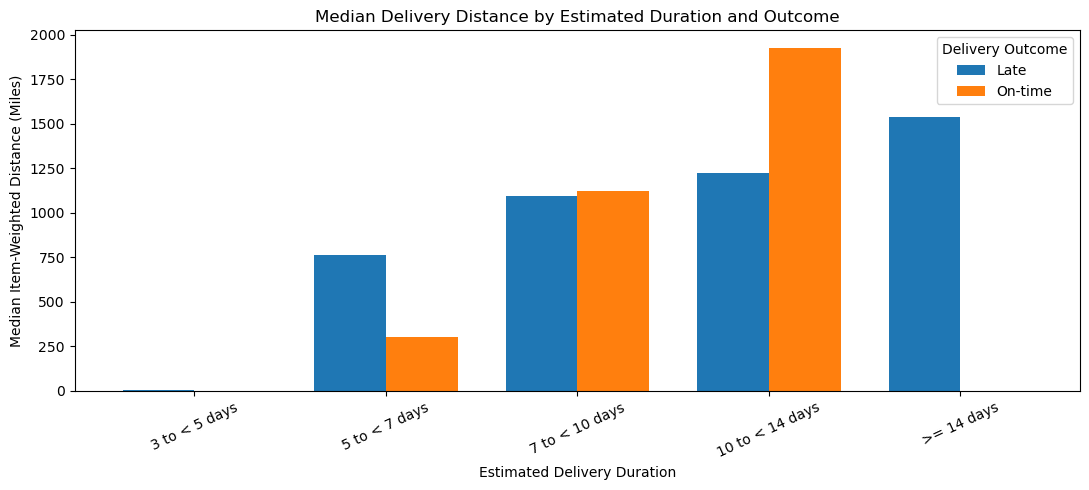


Consistency checks: PASS
Model trained: NO
Primary Predictor Set changed: NO
VALIDATION used: NO
TEST used: NO


In [76]:
# Section 36.5.2 — Distance and Estimated Duration Investigation
# TRAIN only; no model fitting
# VALIDATION and TEST untouched

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

# --------------------------------------------------
# 1. Prepare TRAIN Data
# --------------------------------------------------

columns = [
    "estimated_delivery_days",
    "item_weighted_distance_miles",
    "target_late_delivery"
]

assert all(col in train_model.columns for col in columns)

distance_df = train_model[columns].copy().reset_index(drop=True)

assert len(distance_df) == 461744

for col in [
    "estimated_delivery_days",
    "item_weighted_distance_miles"
]:
    distance_df[col] = pd.to_numeric(
        distance_df[col],
        errors="coerce"
    )

assert distance_df["target_late_delivery"].isin([0, 1]).all()

# Drop missing/non-finite values for this diagnostic only.
valid_rows = (
    np.isfinite(distance_df["estimated_delivery_days"])
    & np.isfinite(distance_df["item_weighted_distance_miles"])
)

print("SECTION 36.5.2 — DISTANCE PATTERN INVESTIGATION")
print("-" * 65)

print(f"Initial TRAIN orders: {len(distance_df):,}")
print(f"Valid distance/duration orders: {valid_rows.sum():,}")
print(f"Excluded rows: {(~valid_rows).sum():,}")

distance_df = distance_df.loc[valid_rows].copy()

# --------------------------------------------------
# 2. Apply Existing Duration Bands
# --------------------------------------------------

duration_edges = [-np.inf, 3, 5, 7, 10, 14, np.inf]

duration_labels = [
    "< 3 days",
    "3 to < 5 days",
    "5 to < 7 days",
    "7 to < 10 days",
    "10 to < 14 days",
    ">= 14 days"
]

distance_df["duration_band"] = pd.cut(
    distance_df["estimated_delivery_days"],
    bins=duration_edges,
    labels=duration_labels,
    right=False
)

distance_df["delivery_outcome"] = (
    distance_df["target_late_delivery"]
    .map({0: "On-time", 1: "Late"})
)

# --------------------------------------------------
# 3. Distance Distribution by Band and Outcome
# --------------------------------------------------

distance_summary = (
    distance_df
    .groupby(
        ["duration_band", "delivery_outcome"],
        observed=True
    )
    .agg(
        Orders=("item_weighted_distance_miles", "size"),
        Mean_Distance=("item_weighted_distance_miles", "mean"),
        Median_Distance=("item_weighted_distance_miles", "median"),
        P25_Distance=(
            "item_weighted_distance_miles",
            lambda x: x.quantile(0.25)
        ),
        P75_Distance=(
            "item_weighted_distance_miles",
            lambda x: x.quantile(0.75)
        ),
        Mean_Estimated_Days=("estimated_delivery_days", "mean")
    )
    .reset_index()
)

print("\nDISTANCE DISTRIBUTION BY DURATION AND OUTCOME")

display(
    distance_summary.style.format({
        "Orders": "{:,.0f}",
        "Mean_Distance": "{:,.2f}",
        "Median_Distance": "{:,.2f}",
        "P25_Distance": "{:,.2f}",
        "P75_Distance": "{:,.2f}",
        "Mean_Estimated_Days": "{:.4f}"
    })
)

# --------------------------------------------------
# 4. Late vs On-time Distance Comparison
# --------------------------------------------------

distance_pivot = distance_summary.pivot(
    index="duration_band",
    columns="delivery_outcome",
    values="Median_Distance"
)

distance_pivot["Late_minus_OnTime_Median"] = (
    distance_pivot.get("Late")
    - distance_pivot.get("On-time")
)

print("\nMEDIAN DISTANCE COMPARISON")

display(
    distance_pivot.style.format("{:,.2f}", na_rep="N/A")
)

# --------------------------------------------------
# 5. Distance vs Estimated Duration Correlation
# --------------------------------------------------

correlation_results = []

for outcome, subset in [
    ("Overall", distance_df),
    ("On-time", distance_df[
        distance_df["target_late_delivery"] == 0
    ]),
    ("Late", distance_df[
        distance_df["target_late_delivery"] == 1
    ])
]:

    rho, p_value = spearmanr(
        subset["item_weighted_distance_miles"],
        subset["estimated_delivery_days"]
    )

    correlation_results.append({
        "Outcome": outcome,
        "Orders": len(subset),
        "Spearman_Rho": rho,
        "P_Value": p_value
    })

correlation_summary = pd.DataFrame(correlation_results)

print("\nDISTANCE VS ESTIMATED DURATION — SPEARMAN CORRELATION")

display(
    correlation_summary.style.format({
        "Orders": "{:,.0f}",
        "Spearman_Rho": "{:.6f}",
        "P_Value": "{:.6g}"
    })
)

# --------------------------------------------------
# 6. Visualization
# --------------------------------------------------

plot_data = distance_summary.pivot(
    index="duration_band",
    columns="delivery_outcome",
    values="Median_Distance"
)

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

ax.set_title(
    "Median Delivery Distance by Estimated Duration and Outcome"
)
ax.set_xlabel("Estimated Delivery Duration")
ax.set_ylabel("Median Item-Weighted Distance (Miles)")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Delivery Outcome")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Consistency
# --------------------------------------------------

assert distance_summary["Orders"].sum() == len(distance_df)

print("\nConsistency checks: PASS")
print("Model trained: NO")
print("Primary Predictor Set changed: NO")
print("VALIDATION used: NO")
print("TEST used: NO")

### 36.5.2 Results and Interpretation

The analysis examined 461,744 TRAIN orders to understand the relationship between delivery distance, estimated duration, and late delivery.

#### 1. Distance and Estimated Duration Correlation

| Outcome | Orders | Spearman's Rho |
|---|---:|---:|
| Overall | 461,744 | 0.8790 |
| On-time | 415,600 | 0.9723 |
| Late | 46,144 | 0.4705 |

Distance and estimated duration were strongly correlated, especially for on-time orders.

The weaker correlation among late orders suggests different patterns between the two outcomes.

#### 2. Median Distance by Duration

| Estimated Duration | Late (miles) | On-time (miles) |
|---|---:|---:|
| 3 to <escape><</escape>5 days | 3.00 | N/A |
| 5 to <escape><</escape>7 days | 763.70 | 304.61 |
| 7 to <escape><</escape>10 days | 1,093.79 | 1,120.26 |
| 10 to <escape><</escape>14 days | 1,226.02 | 1,927.70 |
| ≥14 days | 1,538.37 | N/A |

**Key Findings:**

- **5 to <escape><</escape>7 days:** Late orders had longer delivery distances.
- **10 to <escape><</escape>14 days:** Late orders had shorter delivery distances.
- **Extreme groups:** Only late orders were observed.

The relationship between distance and late delivery changed across duration groups.

#### 3. Connection to Conditional AUC

| Estimated Duration | Distance ROC-AUC |
|---|---:|
| Overall | 0.4997 |
| 5 to <escape><</escape>7 days | 0.8356 |
| 7 to <escape><</escape>10 days | 0.4817 |
| 10 to <escape><</escape>14 days | 0.1497 |

These results show why distance had weak overall predictive power but stronger relationships within certain duration groups.

#### 4. Connection to XGBoost

The findings help explain why the 33-feature XGBoost sensitivity model performed much better than the Duration-Only model.

Distance and estimated duration may provide useful information when combined.

However, the analysis does not identify the exact rules learned by XGBoost.

#### 5. Limitations

The patterns suggest possible structural relationships in the synthetic dataset.

However, the original generation rules remain unknown. We cannot confirm whether estimated delivery duration was available at checkout or influenced by future outcomes.

### Conclusion

Distance and estimated delivery duration showed strong relationships, especially for on-time orders.

The direction of the distance–late-delivery relationship changed across duration groups, which may help explain the sensitivity model's strong performance.

However, **potential data leakage remains unresolved**, and the findings do not confirm real-world predictive usefulness.

The Primary Predictor Set remains unchanged. No models were retrained, and VALIDATION and TEST remained untouched.

**Next Step:** Section 36.6 — Feature Availability and Data Leakage Assessment.

## 36.6 Feature Availability and Data Leakage Assessment

### Objective

Check whether the model features are available immediately after payment confirmation and decide whether `estimated_delivery_days` can be used in the Primary Model.

### 1. Prediction-Time Requirements

The Primary Model should use only information available at or before payment confirmation.

Actual delivery dates, delivery delays, shipment outcomes, and customer reviews are excluded because they contain future information.

### 2. Primary Predictor Eligibility

The 32 Primary Predictors include purchase timing, customer information, order details, product characteristics, financial data, payments, sellers, and delivery distance.

These features are expected to be available at prediction time, although some payment, seller, and route information would need further verification before real-world deployment.

### 3. Estimated Delivery Days Investigation

Previous audits found strong relationships between estimated duration and late delivery.

**Complete Separation:**

| Estimated Duration | TRAIN Late Orders | VALIDATION Late Orders | Late Rate |
|---|---:|---:|---:|
| Below 5 days | 803 | 356 | 100% |
| ≥14 days | 14,986 | 6,938 | 100% |

**Validation Model Comparison:**

| Model | ROC-AUC | Average Precision |
|---|---:|---:|
| Primary XGBoost | 0.5021 | 0.1001 |
| Duration-Only XGBoost | 0.7873 | 0.5690 |
| 33-Feature Sensitivity XGBoost | 0.9548 | 0.9299 |

The sensitivity model performed much better than the Primary Model.

### 4. Structural Relationships

Distance and estimated duration showed strong correlations:

- **Overall:** 0.8790
- **On-time:** 0.9723
- **Late:** 0.4705

Distance also showed different relationships with late delivery across duration groups.

These patterns suggest a structured synthetic process, but the original generation rules remain unknown.

### 5. Data Leakage Assessment

We cannot confirm when or how `estimated_delivery_days` was generated.

It may represent a valid checkout estimate, share factors with delivery outcomes, or depend on future information.

**Data leakage has not been confirmed or ruled out.** However, the uncertain feature availability creates a risk of misleading model performance.

### 6. Feature Selection Decision

**DROP from Primary Model: `estimated_delivery_days`**

Reasons:

- Availability at checkout is unverified.
- Strong structural relationships with the target were found.
- The original generation process is unknown.

The feature will only be used in separately labeled Sensitivity Analysis.

### Final Conclusion

The original 32-feature Primary Predictor Set will remain unchanged.

The Primary Models achieved validation ROC-AUC near 0.50, showing limited predictive performance under the tested settings.

Although the sensitivity models performed well, they cannot be recommended for real-world prediction because of unresolved feature availability and potential leakage.

**No deployment-ready late-delivery model can currently be recommended.**

The TEST dataset remains untouched.

**Next Step:** Section 37 — Final Modeling Comparison and Decision.

## 37. Final Modeling Comparison and Decision

### 37.1 Consolidated Model Performance

#### Objective

Compare the validation results of the baseline, Primary Models, and Sensitivity Models to determine whether any model is suitable for predicting late delivery after payment confirmation.

#### Data Split

| Dataset | Period | Orders |
|---|---|---:|
| TRAIN | 2019–2023 | 461,744 |
| VALIDATION | 2024 | 214,365 |
| TEST | Jan–Nov 2025 | 228,257 |

**Target:** `target_late_delivery` (1 = Late, 0 = On-time)

TEST data remains untouched.

#### Models Compared

**Baseline**
- Majority-Class Classifier

**Primary Models (32 Predictors)**
- Logistic Regression
- Balanced Logistic Regression
- Random Forest
- XGBoost
- LightGBM
- CatBoost

**Sensitivity Models**
- Logistic Regression (33 predictors)
- XGBoost (33 predictors)
- Duration-Only XGBoost

Sensitivity Models include `estimated_delivery_days`, whose availability at checkout remains unverified.

#### Evaluation Metrics

- Accuracy, Precision, Recall, F1-score
- ROC-AUC and Average Precision

ROC-AUC and Average Precision are emphasized because only about 10% of orders are late.

Classification metrics use the fixed threshold of 0.50.

#### Model Selection Rules

1. Use only features available at prediction time.
2. Do not select Sensitivity Models for deployment.
3. Small ROC-AUC differences near 0.50 do not indicate useful performance.
4. Consider practical usefulness and performance on future data.
5. Do not use TEST data for model selection.

In [77]:
# Section 37.1 — Consolidated Model Comparison
# Previously reported VALIDATION metrics
# No model training; TEST untouched

import pandas as pd

model_records = [
    {
        "Category": "Baseline",
        "Model": "Naive Majority Class",
        "Accuracy": 0.9006,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000,
        "ROC_AUC": 0.5000,
        "Average_Precision": 0.0994
    },
    {
        "Category": "Primary",
        "Model": "Logistic Regression",
        "Accuracy": 0.9006,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000,
        "ROC_AUC": 0.4991,
        "Average_Precision": 0.0996
    },
    {
        "Category": "Primary",
        "Model": "Balanced Logistic Regression",
        "Accuracy": 0.5079,
        "Precision": 0.0987,
        "Recall": 0.4856,
        "F1": 0.1641,
        "ROC_AUC": 0.4984,
        "Average_Precision": 0.0993
    },
    {
        "Category": "Primary",
        "Model": "Random Forest",
        "Accuracy": 0.9006,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000,
        "ROC_AUC": 0.5017,
        "Average_Precision": 0.1003
    },
    {
        "Category": "Primary",
        "Model": "XGBoost",
        "Accuracy": 0.9006,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000,
        "ROC_AUC": 0.5021,
        "Average_Precision": 0.1001
    },
    {
        "Category": "Primary",
        "Model": "LightGBM",
        "Accuracy": 0.9006,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000,
        "ROC_AUC": 0.5011,
        "Average_Precision": 0.0997
    },
    {
        "Category": "Primary",
        "Model": "CatBoost",
        "Accuracy": 0.9006,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000,
        "ROC_AUC": 0.5023,
        "Average_Precision": 0.1003
    },
    {
        "Category": "Sensitivity",
        "Model": "Logistic Regression + Duration",
        "Accuracy": 0.9565,
        "Precision": 1.0000,
        "Recall": 0.5625,
        "F1": 0.7200,
        "ROC_AUC": 0.7758,
        "Average_Precision": 0.7619
    },
    {
        "Category": "Sensitivity",
        "Model": "Duration-Only XGBoost",
        "Accuracy": 0.9359,
        "Precision": 0.8757,
        "Recall": 0.4147,
        "F1": 0.5629,
        "ROC_AUC": 0.7873,
        "Average_Precision": 0.5690
    },
    {
        "Category": "Sensitivity",
        "Model": "XGBoost + Duration",
        "Accuracy": 0.9828,
        "Precision": 0.9997,
        "Recall": 0.8272,
        "F1": 0.9053,
        "ROC_AUC": 0.9548,
        "Average_Precision": 0.9299
    }
]

final_model_comparison = pd.DataFrame(model_records)

print("SECTION 37.1 — CONSOLIDATED MODEL COMPARISON")
print("-" * 65)

display(
    final_model_comparison
    .style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "Average_Precision": "{:.4f}"
    })
)

# --------------------------------------------------
# Summary by Model Category
# --------------------------------------------------

primary_results = final_model_comparison[
    final_model_comparison["Category"] == "Primary"
]

sensitivity_results = final_model_comparison[
    final_model_comparison["Category"] == "Sensitivity"
]

print("\nPRIMARY MODEL ROC-AUC RANGE")
print(
    f"{primary_results['ROC_AUC'].min():.4f}"
    f" to {primary_results['ROC_AUC'].max():.4f}"
)

print("\nHIGHEST PRIMARY ROC-AUC")
print(
    primary_results.loc[
        primary_results["ROC_AUC"].idxmax(),
        ["Model", "ROC_AUC"]
    ].to_string()
)

print("\nHIGHEST DIAGNOSTIC SENSITIVITY ROC-AUC")
print(
    sensitivity_results.loc[
        sensitivity_results["ROC_AUC"].idxmax(),
        ["Model", "ROC_AUC", "Average_Precision"]
    ].to_string()
)

print("\nModel retrained: NO")
print("Primary Predictor Set changed: NO")
print("TEST dataset used: NO")

SECTION 37.1 — CONSOLIDATED MODEL COMPARISON
-----------------------------------------------------------------


,Category,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
0,Baseline,Naive Majority Class,0.9006,0.0000,0.0000,0.0000,0.5000,0.0994
1,Primary,Logistic Regression,0.9006,0.0000,0.0000,0.0000,0.4991,0.0996
2,Primary,Balanced Logistic Regression,0.5079,0.0987,0.4856,0.1641,0.4984,0.0993
3,Primary,Random Forest,0.9006,0.0000,0.0000,0.0000,0.5017,0.1003
4,Primary,XGBoost,0.9006,0.0000,0.0000,0.0000,0.5021,0.1001
5,Primary,LightGBM,0.9006,0.0000,0.0000,0.0000,0.5011,0.0997
6,Primary,CatBoost,0.9006,0.0000,0.0000,0.0000,0.5023,0.1003
7,Sensitivity,Logistic Regression + Duration,0.9565,1.0000,0.5625,0.7200,0.7758,0.7619
8,Sensitivity,Duration-Only XGBoost,0.9359,0.8757,0.4147,0.5629,0.7873,0.5690
9,Sensitivity,XGBoost + Duration,0.9828,0.9997,0.8272,0.9053,0.9548,0.9299



PRIMARY MODEL ROC-AUC RANGE
0.4984 to 0.5023

HIGHEST PRIMARY ROC-AUC
Model      CatBoost
ROC_AUC      0.5023

HIGHEST DIAGNOSTIC SENSITIVITY ROC-AUC
Model                XGBoost + Duration
ROC_AUC                          0.9548
Average_Precision                0.9299

Model retrained: NO
Primary Predictor Set changed: NO
TEST dataset used: NO


### 37.2 Final Model Selection Decision and Justification

#### Objective

Select the final modeling outcome based on validation performance, feature availability, and diagnostic findings.

#### 1. Primary Model Results

Six Primary Model configurations were tested using 32 checkout-time features.

- **Validation ROC-AUC:** 0.4984–0.5023
- **Highest ROC-AUC:** CatBoost (0.5023)
- **XGBoost ROC-AUC:** 0.5021
- **Balanced Logistic Recall:** 48.56%
- **Balanced Logistic Precision:** 9.87%

Most models predicted no late deliveries at threshold 0.50.

All Primary Models showed discrimination close to random ranking. CatBoost's small advantage was not meaningful enough for final selection.

#### 2. Best Sensitivity Model

Adding `estimated_delivery_days` greatly improved performance.

**XGBoost with 33 Predictors:**

| Metric | Validation |
|---|---:|
| Accuracy | 0.9828 |
| Precision | 0.9997 |
| Recall | 0.8272 |
| F1-score | 0.9053 |
| ROC-AUC | 0.9548 |
| Average Precision | 0.9299 |

However, the availability of estimated delivery duration at checkout remains unverified.

#### 3. Structural Findings

The synthetic dataset showed unusual patterns:

- On-time deliveries occurred exactly 2 days early, while late deliveries occurred exactly 5 days late.
- Estimated durations below 5 days or at least 14 days had 100% late-delivery rates.
- Distance and estimated duration showed strong relationships.
- Distance-related associations changed direction across duration groups.
- Permutation tests showed that the sensitivity model depended strongly on both feature groups.

The original data-generation rules remain unknown.

#### 4. Final Model Decision

- **Operational Model:** Not selected
- **Primary Modeling Result:** Insufficient predictive discrimination
- **Best Diagnostic Model:** XGBoost with 33 predictors
- **Reference Models:** Logistic Regression and Primary XGBoost
- **Baseline:** Majority-Class Classifier

The sensitivity model is not suitable for deployment because potential data leakage and feature availability remain unresolved.

#### 5. Study Findings

The results show that the current checkout-time predictors have limited predictive information under the tested settings.

The sensitivity experiments also show how synthetic data patterns can produce strong model performance without confirming real-world usefulness.

This highlights the importance of checking feature availability, data quality, and possible leakage before selecting a model.

#### 6. Test Dataset Decision

The TEST dataset was not evaluated because no eligible Primary Model showed sufficient validation performance.

It will remain reserved for future evaluation if a suitable modeling approach is developed.

### Final Conclusion

**No deployment-ready late-delivery model was selected.**

Primary Models achieved ROC-AUC near 0.50, while the best sensitivity XGBoost achieved ROC-AUC of 0.9548 and Average Precision of 0.9299.

However, the sensitivity model cannot be selected because its feature availability and relationship with the synthetic data-generation process remain uncertain.

The modeling phase concludes with documented predictive limitations and diagnostic findings rather than a deployed model.